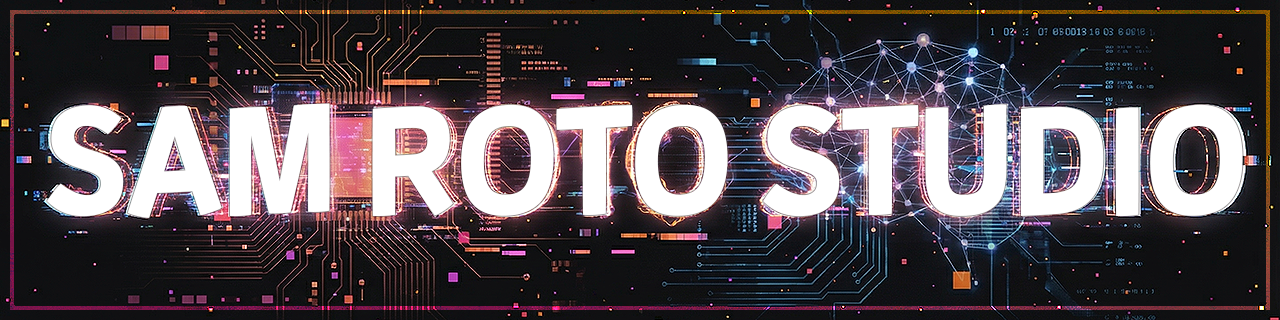

**SAM 2**

In [ ]:

# @title 🚀 Install SAM 2 Roto Studio
from IPython.display import display, HTML, Javascript
import json
import sys
import re

def create_install_wrapper():
    return """
<style>
    .cosmic-install-container {
        position: relative;
        width: 100%;
        max-width: 800px; /* Justified left but bounded */
        background: #27272a;
        border-radius: 16px;
        padding: 24px 28px;
        font-family: 'Google Sans', 'Inter', -apple-system, BlinkMacSystemFont, sans-serif;
        overflow: hidden;
        border: 1px solid #3f3f46;
        box-shadow: 0 4px 24px rgba(0, 0, 0, 0.4), 0 0 0 1px rgba(255,255,255,0.05) inset;
        margin-bottom: 20px;
    }

    .cosmic-install-canvas {
        position: absolute;
        top: 0;
        left: 0;
        width: 100%;
        height: 100%;
        pointer-events: none;
        opacity: 0.9;
    }

    .cosmic-install-content { position: relative; z-index: 10; }

    .cosmic-install-header {
        display: flex;
        align-items: center;
        gap: 14px;
        margin-bottom: 20px;
    }

    .cosmic-install-icon {
        width: 44px;
        height: 44px;
        background: linear-gradient(135deg, #f97316 0%, #f43f5e 50%, #ec4899 100%);
        border-radius: 12px;
        display: flex;
        align-items: center;
        justify-content: center;
        font-size: 22px;
        box-shadow: 0 0 20px rgba(249, 115, 22, 0.4);
        animation: iconPulse 3s ease-in-out infinite;
    }

    @keyframes iconPulse {
        0%, 100% { box-shadow: 0 0 20px rgba(249, 115, 22, 0.4); }
        50% { box-shadow: 0 0 30px rgba(249, 115, 22, 0.6); }
    }

    .cosmic-install-title {
        color: #f3f4f6;
        font-size: 1.25rem;
        font-weight: 600;
        margin: 0;
    }

    .cosmic-install-subtitle {
        color: #9ca3af;
        font-size: 0.8rem;
        margin: 4px 0 0 0;
    }

    .cosmic-progress-track {
        background: #3f3f46;
        border-radius: 10px;
        height: 8px;
        overflow: hidden;
        margin-bottom: 16px;
    }

    .cosmic-progress-bar {
        height: 100%;
        background: linear-gradient(90deg, #f97316, #f43f5e, #d946ef);
        background-size: 200% 100%;
        width: 0%;
        transition: width 1s linear;
        animation: progressShimmer 2s linear infinite;
    }

    @keyframes progressShimmer {
        0% { background-position: 200% 0; }
        100% { background-position: -200% 0; }
    }

    .cosmic-status-row {
        display: flex;
        justify-content: space-between;
        align-items: center;
        margin-bottom: 15px;
    }

    .cosmic-status-text {
        color: #e5e7eb;
        font-size: 0.85rem;
        display: flex;
        align-items: center;
        gap: 8px;
    }

    .cosmic-status-spinner {
        width: 12px;
        height: 12px;
        border: 2px solid #3f3f46;
        border-top-color: #f97316;
        border-radius: 50%;
        animation: spin 1s linear infinite;
    }

    @keyframes spin { to { transform: rotate(360deg); } }

    .cosmic-time-info {
        color: #6b7280;
        font-size: 0.75rem;
        font-variant-numeric: tabular-nums;
    }

    .cosmic-log-container {
        background: rgba(0, 0, 0, 0.3);
        border: 1px solid #3f3f46;
        border-radius: 8px;
        padding: 10px 12px;
        height: 120px;
        overflow-y: auto;
        font-family: 'Roboto Mono', monospace;
        font-size: 0.7rem;
        display: flex;
        flex-direction: column;
    }

    .cosmic-log-container::-webkit-scrollbar { width: 6px; }
    .cosmic-log-container::-webkit-scrollbar-thumb { background: #3f3f46; border-radius: 3px; }

    .cosmic-log-line { margin: 0; padding: 1px 0; color: #9ca3af; white-space: pre-wrap; word-wrap: break-word; }
    .cosmic-log-line.hl { color: #f3f4f6; }
    .cosmic-log-line.warn { color: #fbbf24; }

    .cosmic-complete-overlay {
        position: absolute;
        top: 0; left: 0; width: 100%; height: 100%;
        background: rgba(39, 39, 42, 0.9);
        display: none;
        align-items: center;
        justify-content: center;
        z-index: 20;
        flex-direction: column;
        animation: fadeIn 0.5s ease-out;
    }

    .cosmic-complete-badge {
        display: inline-flex;
        align-items: center;
        gap: 10px;
        background: rgba(74, 222, 128, 0.1);
        border: 1px solid rgba(74, 222, 128, 0.3);
        border-radius: 30px;
        padding: 12px 24px;
        color: #4ade80;
        font-size: 1rem;
        font-weight: 500;
    }

    @keyframes fadeIn { from { opacity: 0; } to { opacity: 1; } }

    /* Error State Styles */
    .cosmic-install-container.cosmic-error {
        border-color: rgba(239, 68, 68, 0.5);
        box-shadow: 0 4px 24px rgba(239, 68, 68, 0.25), 0 0 0 1px rgba(239, 68, 68, 0.1) inset;
    }

    .cosmic-progress-bar.cosmic-error {
        background: linear-gradient(90deg, #dc2626, #ef4444, #b91c1c);
        background-size: 100% 100%;
        animation: none;
    }

    .cosmic-install-icon.cosmic-error {
        background: linear-gradient(135deg, #b91c1c 0%, #dc2626 50%, #ef4444 100%);
        box-shadow: 0 0 20px rgba(239, 68, 68, 0.4);
        animation: none;
    }

    .badge-container {
        position: absolute;
        top: 24px;
        right: 28px;
        z-index: 50;
        display: flex;
        gap: 12px;
    }
    .badge-item {
        opacity: 1;
        transition: transform 0.2s, filter 0.2s;
        cursor: pointer;
        display: flex;
        align-items: center;
    }
    .badge-item:hover {
        transform: translateY(-1px);
        filter: brightness(1.1);
    }
</style>

<div class="cosmic-install-container" id="cosmicInstall">
    <div class="badge-container">
        <a href="https://github.com/VirtuallyJesse/ai-rotoscoping" target="_blank" class="badge-item">
            <img src="https://img.shields.io/badge/GitHub-VirtuallyJesse-f43f5e?logo=github&style=flat" style="height: 20px;" alt="GitHub">
        </a>
    </div>
    <canvas class="cosmic-install-canvas" id="cosmicInstallCanvas"></canvas>
    <div class="cosmic-install-content">
        <div class="cosmic-install-header">
            <div class="cosmic-install-icon">🚀</div>
            <div>
                <h3 class="cosmic-install-title">SAM 2 Roto Studio</h3>
                <p class="cosmic-install-subtitle">Installing dependencies & models</p>
            </div>
        </div>

        <div class="cosmic-progress-track">
            <div class="cosmic-progress-bar" id="cosmicProgressBar"></div>
        </div>

        <div class="cosmic-status-row">
            <div class="cosmic-status-text">
                <div class="cosmic-status-spinner" id="cosmicSpinner"></div>
                <span id="cosmicStatusText">Installing...</span>
            </div>
            <div class="cosmic-time-info" id="cosmicTimeInfo"></div>
        </div>

        <div class="cosmic-log-container" id="cosmicLogContainer"></div>

        <div class="cosmic-complete-overlay" id="cosmicComplete">
            <div class="cosmic-complete-badge">
                <span>✓</span> Installation Complete
            </div>
        </div>
    </div>
</div>

<script>
(function() {
    // --- Canvas ---
    const canvas = document.getElementById('cosmicInstallCanvas');
    const ctx = canvas.getContext('2d');
    const container = document.getElementById('cosmicInstall');

    function resize() { canvas.width = container.offsetWidth; canvas.height = container.offsetHeight; }
    resize();

    const particles = Array.from({length: 60}, () => ({
        x: Math.random() * canvas.width,
        y: Math.random() * canvas.height,
        size: Math.random() * 2.5,
        speedX: (Math.random() - 0.5) * 0.5,
        speedY: (Math.random() - 0.5) * 0.5,
        color: ['#f43f5e', '#f97316', '#d946ef'][Math.floor(Math.random() * 3)],
        opacity: Math.random() * 1.0
    }));

    function animate() {
        ctx.clearRect(0, 0, canvas.width, canvas.height);
        particles.forEach(p => {
            p.x += p.speedX; p.y += p.speedY;
            if(p.x < 0) p.x = canvas.width; if(p.x > canvas.width) p.x = 0;
            if(p.y < 0) p.y = canvas.height; if(p.y > canvas.height) p.y = 0;
            ctx.beginPath();
            ctx.arc(p.x, p.y, p.size, 0, Math.PI*2);
            ctx.fillStyle = p.color;
            ctx.globalAlpha = p.opacity;
            ctx.fill();
        });
        requestAnimationFrame(animate);
    }
    animate();

    // --- Progress Logic ---
    const totalSegments = 9 || 1;
    let currentSegment = 0;

    window.advanceCosmicProgress = function() {
        currentSegment++;
        let pct = Math.min(95, (currentSegment / totalSegments) * 100);
        document.getElementById('cosmicProgressBar').style.width = pct + '%';
    };

    window.showCosmicError = function() {
        document.getElementById('cosmicInstall').classList.add('cosmic-error');
        document.getElementById('cosmicProgressBar').classList.add('cosmic-error');
        document.querySelector('.cosmic-install-icon').classList.add('cosmic-error');
        document.getElementById('cosmicSpinner').style.display = 'none';
        document.getElementById('cosmicStatusText').innerHTML = '<span style="color:#ef4444;">✖</span> Installation Failed';
        document.getElementById('cosmicTimeInfo').innerText = 'See log for details';
    };

    window.updateCosmicLog = function(text) {
        const log = document.getElementById('cosmicLogContainer');
        const line = document.createElement('p');
        line.className = 'cosmic-log-line';
        if (text.includes('✓')) line.classList.add('hl');
        if (text.includes('⚠️')) line.classList.add('warn');
        line.textContent = text;
        log.appendChild(line);
        log.scrollTop = log.scrollHeight;
    };

    window.completeCosmicInstall = function() {
        document.getElementById('cosmicProgressBar').style.width = '100%';
        document.getElementById('cosmicTimeInfo').innerText = '';
        setTimeout(() => {
            document.getElementById('cosmicComplete').style.display = 'flex';
        }, 800);
    };

})();
</script>
"""

# Output Stream Capturer
class CosmicInstallStream:
    def __init__(self):
        self.buffer = ""
    def write(self, text):
        if not text: return
        clean_text = text.replace('\n', ' ')
        if clean_text.strip():
            display(Javascript(f'window.updateCosmicLog({json.dumps(clean_text)});'))
    def flush(self): pass
    def isatty(self): return False

display(HTML(create_install_wrapper()))
original_stdout = sys.stdout
original_stderr = sys.stderr
sys.stdout = CosmicInstallStream()
sys.stderr = CosmicInstallStream()

class _InstallStop(Exception):
    """Silent exception to halt cell execution cleanly."""
    def _render_traceback_(self):
        return ["SystemExit: 1"]

def _handle_install_error():
    """Trigger error visual and stop cell execution cleanly."""
    sys.stdout = original_stdout
    sys.stderr = original_stderr
    display(Javascript('window.showCosmicError();'))
    raise _InstallStop() from None

def _handle_install_success():
    """Advance progress bar by one segment."""
    display(Javascript('window.advanceCosmicProgress();'))

# @title 1.0 Environment Setup & Installation
# Install system dependencies, PyTorch requirements, and download SAM 2 checkpoints.
import os
import sys
import subprocess
import logging

# --- Set before ANY imports ---
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

# Suppress HF warnings as token is optional
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
logging.getLogger("huggingface_hub.utils._http").setLevel(logging.ERROR)

# -----------------------------
# Hugging Face auth (optional)
# -----------------------------
try:
    from google.colab import userdata
    hf_token = userdata.get("HF_TOKEN")
    if hf_token:
        os.environ["HF_TOKEN"] = hf_token
        os.environ["HUGGINGFACE_HUB_TOKEN"] = hf_token
        print("✓ HF_TOKEN loaded from Colab Secrets")
except Exception:
    pass

token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGINGFACE_HUB_TOKEN")

if not token:
    print("⚠️  No HF_TOKEN found. Downloads may be slower.")
    token = False

import torch

print(f"\nPyTorch version: {torch.__version__}")
print(f"\nCUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"\nGPU: {torch.cuda.get_device_name(0)}")

# -----------------------------
# System deps
# -----------------------------
print("\nInstalling system dependencies...")
try:
    subprocess.run(["apt-get", "-qq", "update"], check=True,
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    subprocess.run(["apt-get", "-qq", "install", "ffmpeg"], check=True,
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
except Exception as e:
    print(f"❌ System dependency installation failed: {e}")
    _handle_install_error()
_handle_install_success()

# -----------------------------
# Install Python dependencies (Transformers provides the SAM 2 classes)
# -----------------------------
print("\nInstalling Python dependencies...")

pip_packages = [
    # --- UI / IO ---
    "gradio==5.29.0",
    "opencv-python-headless==4.14.0.94",
    "Pillow",
    "tqdm",

    # --- Video Decoding (HF Transformers video processing) ---
    "av",          # Optional manual decode (PyAV) / non-TorchCodec fallback

    # --- SAM 2 and ViTMatte ---
    "transformers==5.22.2",

    # --- InSPyReNet ---
    "transparent-background==1.3.4",
]
try:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-cache-dir", "--upgrade"] + pip_packages, check=True)
except Exception as e:
    print(f"❌ Python dependency installation failed: {e}")
    _handle_install_error()
_handle_install_success()

# -----------------------------
# Install TorchCodec (pinned to the runtime's PyTorch)
# TorchCodec is a C++ extension and must match torch's ABI.
# Versions <= 0.11.x require an exact torch match; 0.12+ is ABI-stable
# and forward-compatible with torch >= 2.11.
# -----------------------------
print("\nInstalling TorchCodec...")
try:
    torch_mm = ".".join(torch.__version__.split("+")[0].split(".")[:2])  # e.g. "2.11"

    # Strict ABI-pinned versions (pre-stable-ABI era)
    torchcodec_version_map = {
        "2.11": "0.11.1",
    }
    torchcodec_version = torchcodec_version_map.get(torch_mm)

    # Forward-compat: torch >= 2.12 uses latest TorchCodec (ABI-stable from 0.12+)
    if not torchcodec_version:
        torch_minor = int(torch_mm.split(".")[1])
        if torch_minor >= 12:
            torchcodec_version = None  # unpinned — pip resolves latest
        else:
            raise RuntimeError(
                f"Unsupported torch version for TorchCodec: {torch.__version__} "
                f"(expected one of: {sorted(torchcodec_version_map.keys())} or >= 2.12)"
            )

    # Prefer CUDA-enabled TorchCodec wheels when CUDA is present.
    cuda_ver = torch.version.cuda  # e.g. "12.6" or None
    if cuda_ver:
        cuda_tag = "".join(cuda_ver.split(".")[:2])  # "12.6" -> "126"
        tc_index_url = f"https://download.pytorch.org/whl/cu{cuda_tag}"
    else:
        tc_index_url = "https://download.pytorch.org/whl/cpu"

    tc_pkg = f"torchcodec=={torchcodec_version}" if torchcodec_version else "torchcodec"

    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "torchcodec"], check=False)
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q",
            "--no-cache-dir", "--upgrade", "--force-reinstall", "--no-deps",
            tc_pkg,
            "--index-url", tc_index_url,
        ],
        check=True,
    )

    import torchcodec  # noqa: F401
except Exception as e:
    print(f"❌ TorchCodec installation failed: {e}")
    _handle_install_error()
_handle_install_success()

# -----------------------------
# Install MatAnyone
# IMPORTANT: install WITHOUT deps to prevent Gradio downgrade
# -----------------------------
print("\nInstalling MatAnyone...")
try:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "--no-deps", "git+https://github.com/pq-yang/MatAnyone@e5ddc534c1fff9bb9e54cf476095d29071b7cb4f"],
        check=True
    )
except Exception as e:
    print(f"❌ MatAnyone installation failed: {e}")
    _handle_install_error()
_handle_install_success()

# -----------------------------
# Predownload model snapshots
# -----------------------------
print("\nPredownloading models...")
from huggingface_hub import snapshot_download

hf_kwargs = {}
hf_kwargs["token"] = token

# 1. SAM 2.1
try:
    print("  • SAM 2.1...")
    path = snapshot_download(repo_id="facebook/sam2.1-hiera-large", **hf_kwargs)
except Exception as e:
    print(f"    ❌ SAM 2.1 download failed: {e}")
    _handle_install_error()
_handle_install_success()

# 2. ViTMatte (used by vitmatte_engine.py)
try:
    print("  • ViTMatte...")
    snapshot_download(repo_id="hustvl/vitmatte-base-composition-1k", **hf_kwargs)
except Exception as e:
    print(f"    ❌ ViTMatte download failed: {e}")
    _handle_install_error()
_handle_install_success()

# 3. MatAnyone (used by matanyone_engine.py)
try:
    print("  • MatAnyone...")
    snapshot_download(repo_id="PeiqingYang/MatAnyone", **hf_kwargs)
except Exception as e:
    print(f"    ❌ MatAnyone download failed: {e}")
    _handle_install_error()
_handle_install_success()

# 4. InSPyReNet (used by inspyrenet_engine.py)
# transparent-background expects weights in ~/.transparent-background/
try:
    print("  • InSPyReNet...")
    home_dir = os.path.expanduser("~")
    inspy_dir = os.path.join(home_dir, ".transparent-background")
    os.makedirs(inspy_dir, exist_ok=True)
    ckpt_path = os.path.join(inspy_dir, "ckpt_base.pth")

    # Default fallback URL
    download_url = "https://github.com/plemeri/transparent-background/releases/download/1.2.12/ckpt_base.pth"

    # Sanity Check: Read installed config to ensure URL matches library expectation
    try:
        import re
        config_path = None
        for p in sys.path:
            c = os.path.join(p, "transparent_background", "config.yaml")
            if os.path.exists(c):
                config_path = c
                break

        if config_path:
            with open(config_path, "r", encoding="utf-8") as f:
                cfg_txt = f.read()
            # Regex to find: base: ... url: "TARGET" (Robust to whitespace/newlines)
            m = re.search(r'base:.*?url:\s*["\'](.*?)["\']', cfg_txt, re.DOTALL)
            if m:
                found_url = m.group(1)
                if found_url != download_url:
                    print(f"    ℹ️  Updated URL found in config: {found_url}")
                    download_url = found_url
    except Exception as check_err:
        print(f"    ⚠️  Config check skipped (using fallback): {check_err}")

    if not os.path.exists(ckpt_path):
        subprocess.run(["wget", "-q", "-O", ckpt_path, download_url], check=True)

except Exception as e:
    print(f"    ❌ InSPyReNet download failed: {e}")
    _handle_install_error()
_handle_install_success()

# --- Download UI assets ---
print("\nDownloading UI assets...")
try:
    assets_dir = "assets"
    os.makedirs(assets_dir, exist_ok=True)
    sound_file = os.path.join(assets_dir, "job_complete.wav")
    if not os.path.exists(sound_file):
        sound_url = "https://raw.githubusercontent.com/VirtuallyJesse/ai-rotoscoping/main/assets/job_complete.wav"
        subprocess.run(["wget", "-q", "-O", sound_file, sound_url], check=True)
except Exception as e:
    print(f"❌ UI Assets download failed: {e}")
    _handle_install_error()
_handle_install_success()

print("\n✓ Setup Complete!")

sys.stdout = original_stdout
sys.stderr = original_stderr
display(Javascript('window.completeCosmicInstall()'))


In [ ]:

# @title 🎬 Launch SAM 2 Roto Studio
from IPython.display import display, HTML, Javascript
import json
import sys
import re

def create_launch_wrapper():
    return """
<style>
    .cosmic-launch-container {
        position: relative;
        width: 100%;
        max-width: 800px;
        background: #27272a;
        border-radius: 16px;
        padding: 24px 28px;
        font-family: 'Google Sans', 'Inter', -apple-system, BlinkMacSystemFont, sans-serif;
        overflow: hidden;
        border: 1px solid #3f3f46;
        box-shadow: 0 4px 24px rgba(0, 0, 0, 0.4);
    }

    .cosmic-launch-canvas { position: absolute; top: 0; left: 0; width: 100%; height: 100%; pointer-events: none; opacity: 0.9; }
    .cosmic-launch-content { position: relative; z-index: 10; }

    .cosmic-launch-header { display: flex; align-items: center; gap: 14px; margin-bottom: 20px; }
    .cosmic-launch-icon {
        width: 44px; height: 44px;
        background: linear-gradient(135deg, #f97316 0%, #f43f5e 50%, #d946ef 100%);
        border-radius: 12px;
        display: flex; align-items: center; justify-content: center;
        font-size: 22px;
        box-shadow: 0 0 20px rgba(249, 115, 22, 0.4);
        animation: iconPulse 3s ease-in-out infinite;
    }

    @keyframes iconPulse {
        0%, 100% { box-shadow: 0 0 20px rgba(249, 115, 22, 0.4); }
        50% { box-shadow: 0 0 30px rgba(249, 115, 22, 0.6); }
    }

    .cosmic-launch-title { color: #f3f4f6; font-size: 1.25rem; font-weight: 600; margin: 0; }
    .cosmic-launch-subtitle { color: #9ca3af; font-size: 0.8rem; margin: 4px 0 0 0; }

    .cosmic-status-badge {
        display: inline-flex; align-items: center; gap: 8px;
        padding: 6px 14px; border-radius: 20px;
        font-size: 0.8rem; font-weight: 500;
        margin-bottom: 20px;
        background: rgba(251, 191, 36, 0.12);
        border: 1px solid rgba(251, 191, 36, 0.3);
        color: #fbbf24;
    }

    .cosmic-status-badge.ready {
        background: rgba(74, 222, 128, 0.12);
        border: 1px solid rgba(74, 222, 128, 0.3);
        color: #4ade80;
    }

    .cosmic-status-dot {
        width: 8px; height: 8px; border-radius: 50%; background: currentColor;
        animation: dotBlink 1s ease-in-out infinite;
    }
    @keyframes dotBlink { 0%, 100% { opacity: 1; } 50% { opacity: 0.3; } }

    .cosmic-url-container {
        background: rgba(0, 0, 0, 0.35);
        border: 1px solid #3f3f46;
        border-radius: 10px;
        padding: 16px 18px;
        margin-bottom: 20px;
        display: none;
    }

    .cosmic-url-label { color: #6b7280; font-size: 0.7rem; text-transform: uppercase; margin-bottom: 8px; }
    .cosmic-url-link {
        color: #ea580c; font-size: 1.1rem; font-weight: 500;
        text-decoration: none; word-break: break-all;
        display: flex; align-items: center; gap: 10px;
    }
    .cosmic-url-link:hover { color: #fb923c; text-shadow: 0 0 12px rgba(234, 88, 12, 0.5); }

    .cosmic-launch-log {
        background: rgba(0, 0, 0, 0.3);
        border: 1px solid #3f3f46;
        border-radius: 8px;
        padding: 10px 12px;
        height: 140px;
        overflow-y: auto;
        font-family: 'Roboto Mono', monospace;
        font-size: 0.7rem;
    }
    .cosmic-launch-log::-webkit-scrollbar { width: 6px; }
    .cosmic-launch-log::-webkit-scrollbar-thumb { background: #3f3f46; border-radius: 3px; }
    .cosmic-log-entry { margin: 0; padding: 1px 0; color: #9ca3af; }
    .cosmic-log-entry.url { color: #ea580c; }

    .badge-container {
        position: absolute;
        top: 24px;
        right: 28px;
        z-index: 50;
        display: flex;
        gap: 12px;
    }
    .badge-item {
        opacity: 1;
        transition: transform 0.2s, filter 0.2s;
        cursor: pointer;
        display: flex;
        align-items: center;
    }
    .badge-item:hover {
        transform: translateY(-1px);
        filter: brightness(1.1);
    }
</style>

<div class="cosmic-launch-container" id="cosmicLaunch">
    <div class="badge-container">
        <a href="https://github.com/VirtuallyJesse/ai-rotoscoping" target="_blank" class="badge-item">
            <img src="https://img.shields.io/badge/GitHub-VirtuallyJesse-f43f5e?logo=github&style=flat" style="height: 20px;" alt="GitHub">
        </a>
    </div>
    <canvas class="cosmic-launch-canvas" id="cosmicLaunchCanvas"></canvas>
    <div class="cosmic-launch-content">
        <div class="cosmic-launch-header">
            <div class="cosmic-launch-icon">🎬</div>
            <div>
                <h3 class="cosmic-launch-title">SAM 2 Roto Studio</h3>
                <p class="cosmic-launch-subtitle">Loading Application Modules</p>
            </div>
        </div>

        <div class="cosmic-status-badge" id="cosmicStatusBadge">
            <span class="cosmic-status-dot"></span>
            <span id="cosmicBadgeText">Initializing...</span>
        </div>

        <div class="cosmic-url-container" id="cosmicUrlContainer">
            <div class="cosmic-url-label">Public URL</div>
            <a class="cosmic-url-link" id="cosmicUrlLink" href="#" target="_blank"></a>
        </div>

        <div class="cosmic-launch-log" id="cosmicLaunchLog"></div>
    </div>
</div>

<script>
(function() {
    // --- Canvas ---
    const canvas = document.getElementById('cosmicLaunchCanvas');
    const ctx = canvas.getContext('2d');
    const container = document.getElementById('cosmicLaunch');
    function resize() { canvas.width = container.offsetWidth; canvas.height = container.offsetHeight; }
    resize();

    const particles = Array.from({length: 60}, () => ({
        x: Math.random() * canvas.width, y: Math.random() * canvas.height,
        size: Math.random() * 2.5,
        speedX: (Math.random() - 0.5) * 0.3, speedY: (Math.random() - 0.5) * 0.3,
        color: ['#f43f5e', '#ec4899', '#f97316'][Math.floor(Math.random() * 3)],
        opacity: Math.random() * 0.9
    }));

    function animate() {
        ctx.clearRect(0, 0, canvas.width, canvas.height);
        particles.forEach(p => {
            p.x += p.speedX; p.y += p.speedY;
            if(p.x < 0) p.x = canvas.width; if(p.x > canvas.width) p.x = 0;
            if(p.y < 0) p.y = canvas.height; if(p.y > canvas.height) p.y = 0;
            ctx.beginPath(); ctx.arc(p.x, p.y, p.size, 0, Math.PI*2);
            ctx.fillStyle = p.color; ctx.globalAlpha = p.opacity; ctx.fill();
        });
        requestAnimationFrame(animate);
    }
    animate();

    window.addLaunchLog = function(text, type) {
        const log = document.getElementById('cosmicLaunchLog');
        const entry = document.createElement('p');
        entry.className = 'cosmic-log-entry ' + (type || '');
        entry.textContent = text;
        log.appendChild(entry);
        log.scrollTop = log.scrollHeight;
    };

    window.foundCosmicUrl = function(url) {
        document.getElementById('cosmicUrlContainer').style.display = 'block';
        const link = document.getElementById('cosmicUrlLink');
        link.href = url;
        link.textContent = url + ' ↗';

        const badge = document.getElementById('cosmicStatusBadge');
        badge.classList.add('ready');
        document.getElementById('cosmicBadgeText').textContent = 'Live — Ready for input';
    };
})();
</script>
"""

class CosmicLaunchStream:
    def __init__(self):
        self.buffer = ""
    def write(self, text):
        if not text: return
        self.buffer += text
        while '\n' in self.buffer:
            line, self.buffer = self.buffer.split('\n', 1)
            display(Javascript(f'window.addLaunchLog({json.dumps(line)});'))

            # Check for URL
            url_match = re.search(r'Running on public URL: (https://[a-zA-Z0-9\-\.]+)', line)
            if url_match:
                url = url_match.group(1)
                display(Javascript(f'window.foundCosmicUrl({json.dumps(url)});'))

    def flush(self): pass
    def isatty(self): return False

display(HTML(create_launch_wrapper()))
sys.stdout = CosmicLaunchStream()
sys.stderr = CosmicLaunchStream()

# Fix wget compatibility: its progress bar calls sys.stdout.fileno()
# which CosmicLaunchStream doesn't implement. Patch to use fixed width.
try:
    import wget
    wget.get_console_width = lambda: 80
except ImportError:
    pass

# @title 2.1 Initialize Application Directory
# Create the base directory structure for the SAM 2 WebUI application.
import os

# --- Set before ANY imports ---
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

base_dir = "src/sam2_colab_webui"
os.makedirs(base_dir, exist_ok=True)

def write_file(path, content):
    """Helper function to write content to a file."""
    with open(path, "w") as f:
        f.write(content)
    print(f"Written: {path}")

print(f"Application directory created at: {base_dir}")
# @title 2.2 Create Config Module (config.py)
# Configuration settings for SAM 2, InSPyReNet, and MatAnyone workflows.
write_file(f"{base_dir}/config.py", '''
# -----------------------------
# SAM2 model
# -----------------------------
# Public model (no gating)
DEFAULT_SAM2_MODEL_ID = "facebook/sam2.1-hiera-large"

# How many (frame_idx, obj_id) masks to keep cached in RAM
SAM2_MASK_CACHE_ITEMS = 128

# Clean prompted frames automatically after propagation via "boomerang" method
# When True: Prompted frames are overwritten with cleaner propagated masks, prompts are removed
# When False: Original prompted-frame masks and point data are preserved
SAM2_CLEAN_PROMPTED_FRAMES = True

# -----------------------------
# Interactive Mode: OOM / Performance Knobs
# -----------------------------
# Dtype for inference: "float32" (safe for T4), "float16", "bfloat16" (A100/newer), or "auto"
SAM2_DEFAULT_DTYPE = "float32"

# Vision features cache: how many frames to cache for scrubbing responsiveness
# Higher = faster scrubbing but more GPU memory
SAM2_VISION_CACHE_SIZE = 4

# -----------------------------
# UX knobs
# -----------------------------
POINT_REMOVE_RADIUS_PX = 25.0
VIS_MASK_THRESHOLD = 0.5
EDITOR_TARGET_WIDTH = 1920
EDITOR_TARGET_HEIGHT = 1080

# -----------------------------
# Video Ingest Thresholds ("Golden ratio" values for OOM prevention)
# -----------------------------
# Maximum video duration in seconds before triggering a warning
INGEST_MAX_DURATION_SECS = 8.0

# Maximum FPS before triggering a warning (tolerance of 0.5 is applied in checks)
INGEST_MAX_FPS = 30.0

# Resolution thresholds (short-side values, like 480p, 720p, 1080p naming convention)
# Videos with min dimension below LOW trigger upscale warning
# Videos with min dimension above HIGH (or max dimension above HIGH*16/9) trigger downscale warning
INGEST_RES_HIGH = 1080
INGEST_RES_LOW = 480

# -----------------------------
# Confidence-Band Trimap Defaults
# -----------------------------
# Pixels with confidence >= FG_THR are "definitely foreground" (white=255)
TRIMAP_FG_THRESHOLD = 0.85

# Pixels with confidence <= BG_THR are "definitely background" (black=0)
TRIMAP_BG_THRESHOLD = 0.05

# Optionally dilate the "unknown" band to give ViTMatte more room
TRIMAP_UNKNOWN_DILATE_PX = 5

# -----------------------------
# Union Method Selection
# -----------------------------
# "probabilistic_or" (recommended) or "maximum"
MASK_UNION_METHOD = "probabilistic_or"

# -----------------------------
# InSPyReNet defaults
# -----------------------------
INSPY_MODE_DEFAULT = "base"
INSPY_RESIZE_DEFAULT = "static"
INSPY_MAX_SIDE_DEFAULT = "None"

INSPY_THRESHOLD_ENABLED_DEFAULT = False
INSPY_THRESHOLD_DEFAULT = 0.5
INSPY_JIT_DEFAULT = False

# -----------------------------
# MatAnyone defaults
# -----------------------------
MATANYONE_MASK_SOURCE_DEFAULT = "Union"
MATANYONE_DIRECTION_DEFAULT = "both"

# Performance / quality
MATANYONE_MAX_SIDE_DEFAULT = "None"  # None | 720p | 1080p
MATANYONE_WARMUP_DEFAULT = 10
MATANYONE_ERODE_PX_DEFAULT = 10
MATANYONE_DILATE_PX_DEFAULT = 10
''')
# @title 2.3 Create Video I/O Module (video_io.py)
# Video normalization and input handling utilities for the SAM 2 pipeline.
write_file(f"{base_dir}/video_io.py", '''
import json as _json
import os
import subprocess
import cv2

from .config import (
    INGEST_MAX_DURATION_SECS,
    INGEST_MAX_FPS,
    INGEST_RES_HIGH,
    INGEST_RES_LOW,
)

def prepare_video_input(input_path: str, output_dir: str,
                        start_time: float = 0.0, end_time: float = 0.0,
                        limit_fps: bool = False, normalize_resolution: bool = False) -> str:
    os.makedirs(output_dir, exist_ok=True)

    filename = os.path.basename(input_path)
    name, _ = os.path.splitext(filename)
    # Sanitize filename - remove spaces
    safe_name = name.replace(" ", "_")
    normalized_path = os.path.join(output_dir, f"{safe_name}_norm.mp4")

    print(f"Normalizing video: {input_path} (Trim: {start_time}-{end_time}, FPS: {limit_fps}, Res: {normalize_resolution})")

    # Base Input Command
    input_args = ["-ignore_unknown"]

    # Handle Trim (Start) - using -ss before -i for fast seek
    if start_time > 0:
        input_args.extend(["-ss", str(start_time)])

    input_args.extend(["-i", input_path])

    # Handle Trim (Duration) - using -t since we used -ss before input
    if end_time > start_time:
        duration = end_time - start_time
        input_args.extend(["-t", str(duration)])

    # Build Filter Chain
    filters = []

    # Resolution Normalization logic
    if normalize_resolution:
        try:
            info = get_video_info(input_path)
            w, h = info["width"], info["height"]
            min_dim = min(w, h)
            max_dim = max(w, h)

            # Upscale if too small
            if min_dim < INGEST_RES_LOW:
                scale_filter = f"scale=w=-2:h={INGEST_RES_LOW}" if w > h else f"scale=w={INGEST_RES_LOW}:h=-2"
                filters.append(scale_filter)
            # Downscale if too large
            elif max_dim > int(INGEST_RES_HIGH * 16 / 9) or min_dim > INGEST_RES_HIGH:
                scale_filter = f"scale=w=-2:h={INGEST_RES_HIGH}" if w > h else f"scale=w={INGEST_RES_HIGH}:h=-2"
                filters.append(scale_filter)
        except Exception as e:
            print(f"Warning: Could not determine resolution for normalization: {e}")

    # Padding for odd resolutions (Always applied as safety)
    filters.append("pad=ceil(iw/2)*2:ceil(ih/2)*2:0:0:black,format=yuv420p")

    filter_args = ["-vf", ",".join(filters)] if filters else []

    # FPS Limiter
    fps_args = ["-r", str(int(INGEST_MAX_FPS))] if limit_fps else []

    cmd = [
        "ffmpeg", "-y", "-hide_banner", "-loglevel", "error",
        *input_args,
        "-map", "0:v:0",
        "-c:v", "libx264",
        "-preset", "fast",
        "-crf", "23",
        *fps_args,
        *filter_args,
        "-an",
        "-sn",
        "-dn",
        normalized_path
    ]

    subprocess.run(cmd, check=True)
    print(f"  -> {normalized_path}")
    return normalized_path

def get_video_info(video_path: str):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise ValueError(f"Could not open video: {video_path}")

    info = {
        "fps": cap.get(cv2.CAP_PROP_FPS),
        "frame_count": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    }
    cap.release()
    return info

def check_video_specs(video_path: str) -> dict:
    """
    Check video specs using ffprobe.
    Returns dict with 'duration', 'width', 'height', 'fps', 'exceeds_limits', 'warnings'.
    Limits:
      - Duration > 10s
      - Resolution > 1080p (Max dim > 1920 OR Min dim > 1080)
      - Resolution < 480p (Min dim < 480)
      - FPS > 30
    """
    result = {
        "duration": 0.0,
        "width": 0,
        "height": 0,
        "fps": 0.0,
        "exceeds_limits": False,
        "warnings": []
    }

    try:
        cmd = [
            "ffprobe", "-v", "quiet", "-print_format", "json",
            "-show_format", "-show_streams", video_path
        ]
        output = subprocess.check_output(cmd, stderr=subprocess.STDOUT)
        data = _json.loads(output)

        if "format" in data and "duration" in data["format"]:
            result["duration"] = float(data["format"]["duration"])

        for stream in data.get("streams", []):
            if stream.get("codec_type") == "video":
                result["width"] = int(stream.get("width", 0))
                result["height"] = int(stream.get("height", 0))

                # Parse FPS from r_frame_rate (e.g., "30000/1001")
                if "r_frame_rate" in stream:
                    try:
                        num, den = stream["r_frame_rate"].split('/')
                        if float(den) > 0:
                            result["fps"] = float(num) / float(den)
                    except: pass
                break

        warnings = []

        # Calculate derived thresholds
        max_dim = max(result["width"], result["height"])
        min_dim = min(result["width"], result["height"])
        res_high_long = int(INGEST_RES_HIGH * 16 / 9)  # e.g., 1920 for 1080
        fps_threshold = INGEST_MAX_FPS + 0.5  # Tolerance for 30.0 vs 30 vs 29.97

        # Duration Check
        if result["duration"] > INGEST_MAX_DURATION_SECS:
            warnings.append(f"Video duration ({result['duration']:.1f}s) exceeds {INGEST_MAX_DURATION_SECS:.0f} seconds")

        # Resolution Check (Handle portrait/landscape)
        if max_dim > res_high_long or min_dim > INGEST_RES_HIGH:
            warnings.append(f"Video resolution ({result['width']}x{result['height']}) exceeds {INGEST_RES_HIGH}p")

        # Resolution Check - Too Small
        if min_dim < INGEST_RES_LOW:
            warnings.append(f"Video resolution ({result['width']}x{result['height']}) is below {INGEST_RES_LOW}p")

        # FPS Check
        if result["fps"] > fps_threshold:
            warnings.append(f"Video framerate ({result['fps']:.2f} fps) exceeds {INGEST_MAX_FPS:.0f} fps")

        result["warnings"] = warnings
        result["exceeds_limits"] = len(warnings) > 0

        # Boolean flags for ingest modal
        result["duration_exceeded"] = result["duration"] > INGEST_MAX_DURATION_SECS
        result["fps_exceeded"] = result["fps"] > fps_threshold
        result["resolution_too_small"] = min_dim < INGEST_RES_LOW
        result["resolution_too_large"] = max_dim > res_high_long or min_dim > INGEST_RES_HIGH
        result["resolution_invalid"] = result["resolution_too_small"] or result["resolution_too_large"]
    except Exception as e:
        print(f"ffprobe check failed: {e}")
        # Ensure flags exist even on failure
        result["duration_exceeded"] = False
        result["fps_exceeded"] = False
        result["resolution_too_small"] = False
        result["resolution_too_large"] = False
        result["resolution_invalid"] = False

    return result
''')
# @title 2.4 Create GPU Utilities (gpu_utils.py)
# Centralized VRAM management and cleanup for the SAM 2 pipeline.
write_file(f"{base_dir}/gpu_utils.py", r'''
"""
Centralized GPU memory management utilities.
Provides consistent VRAM cleanup across all engine modules.
"""
import gc
import torch


def clear_gpu_cache(collect_gc: bool = True):
    """
    Perform garbage collection and clear CUDA caches.
    Args:
        collect_gc: If True, runs full Python garbage collection (slow).
                    Set to False for "light" cleanup (CUDA cache only).
    """
    if collect_gc:
        gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        try:
            torch.cuda.ipc_collect()
        except Exception:
            pass


def unload_model_from_gpu(model, model_name: str = "model"):
    """
    Unload a single model from GPU by moving to CPU and deleting.
    Clears GPU cache afterwards.

    Args:
        model: The model object to unload (can be None)
        model_name: Name for status messages
    """
    if model is not None:
        try:
            model.to("cpu")
        except Exception:
            pass
        del model
    clear_gpu_cache()


def unload_models_from_cache(cache_dict: dict, model_name: str = "model", model_attr: str = None):
    """
    Unload all models from a cache dictionary and clear GPU memory.

    Handles different cache structures:
    - Direct model objects (MatAnyone)
    - Objects with a model attribute via model_attr param (InSPyReNet Remover.model)
    - Tuples containing models (ViTMatte: (processor, model, device))

    Args:
        cache_dict: Dictionary containing cached models
        model_name: Name for status messages
        model_attr: If provided, access this attribute on cached items for .to("cpu")
    """
    for item in list(cache_dict.values()):
        try:
            if model_attr is not None:
                # Item has a specific model attribute (e.g., Remover.model)
                inner_model = getattr(item, model_attr, None)
                if inner_model is not None:
                    try:
                        inner_model.to("cpu")
                    except Exception:
                        pass
            elif isinstance(item, tuple):
                # Handle tuples like (processor, model, device)
                for elem in item:
                    if hasattr(elem, "to"):
                        try:
                            elem.to("cpu")
                        except Exception:
                            pass
            else:
                # Direct model object
                if hasattr(item, "to"):
                    try:
                        item.to("cpu")
                    except Exception:
                        pass
            del item
        except Exception:
            pass

    cache_dict.clear()
    clear_gpu_cache()
''')
# @title 2.5 Create Image Utilities (image_utils.py)
# Standardized resizing and mask normalization for SAM 2 workflows.
write_file(f"{base_dir}/image_utils.py", r'''
"""
Centralized image and mask resize/normalization utilities.
Provides consistent interpolation behavior and dimension handling across all engines.
"""
import cv2
import numpy as np


def resize_mask(mask: np.ndarray, target_h: int, target_w: int) -> np.ndarray:
    """
    Resize mask to target dimensions.

    Uses linear interpolation for soft/probability masks (float) to preserve gradients.
    Uses nearest-neighbor for binary masks (non-float) to preserve hard edges.

    Args:
        mask: Input mask array (can be None, 2D or squeezable to 2D)
        target_h: Target height (NumPy convention)
        target_w: Target width (NumPy convention)

    Returns:
        Resized mask as float32 array of shape (target_h, target_w)
    """
    if mask is None:
        return np.zeros((target_h, target_w), dtype=np.float32)

    if mask.ndim > 2:
        mask = mask.squeeze()

    if mask.shape[0] == target_h and mask.shape[1] == target_w:
        return mask.astype(np.float32)

    # Select interpolation based on dtype
    if mask.dtype in [np.float32, np.float64]:
        interp = cv2.INTER_LINEAR
    else:
        interp = cv2.INTER_NEAREST

    # OpenCV uses (width, height) order
    resized = cv2.resize(mask.astype(np.float32), (target_w, target_h), interpolation=interp)
    return resized.astype(np.float32)


def resize_image(image: np.ndarray, target_h: int, target_w: int) -> np.ndarray:
    """
    Resize image to target dimensions.

    Uses INTER_AREA for downscaling (better quality for reduction).
    Uses INTER_LINEAR for upscaling.

    Args:
        image: Input image array
        target_h: Target height (NumPy convention)
        target_w: Target width (NumPy convention)

    Returns:
        Resized image preserving original dtype
    """
    if image is None:
        return None

    if image.shape[0] == target_h and image.shape[1] == target_w:
        return image

    original_dtype = image.dtype

    # Select interpolation based on whether we're scaling up or down
    if target_h < image.shape[0] or target_w < image.shape[1]:
        interp = cv2.INTER_AREA  # Downscaling
    else:
        interp = cv2.INTER_LINEAR  # Upscaling

    # OpenCV uses (width, height) order
    resized = cv2.resize(image, (target_w, target_h), interpolation=interp)

    # Only cast if strictly necessary
    if resized.dtype != original_dtype:
        return resized.astype(original_dtype)
    return resized


def resize_image_max_side(image: np.ndarray, max_side: int) -> tuple:
    """
    Downscale image so max(H, W) <= max_side. Never upscales.

    Used for inference-time downscaling to improve speed/memory.

    Args:
        image: Input image array
        max_side: Maximum allowed size for the larger dimension (or None/<=0 to skip)

    Returns:
        Tuple of (resized_image, (original_h, original_w))
    """
    if image is None:
        return (None, None)

    oh, ow = image.shape[:2]

    if max_side is None or max_side <= 0:
        return (image, (oh, ow))

    m = max(oh, ow)
    if m <= max_side:
        return (image, (oh, ow))

    scale = float(max_side) / float(m)
    nh = max(1, int(round(oh * scale)))
    nw = max(1, int(round(ow * scale)))

    # Always downscaling, use INTER_AREA
    resized = cv2.resize(image, (nw, nh), interpolation=cv2.INTER_AREA)
    return (resized, (oh, ow))


def create_rgba_composite(frame_bgr: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """
    Create BGRA composite from BGR frame and float mask.

    Used for optional RGBA export in processing engines.

    Args:
        frame_bgr: BGR frame (HxWx3, uint8)
        mask: Float32 mask [0,1] (HxW)

    Returns:
        BGRA image (HxWx4, uint8) suitable for cv2.imwrite as PNG
    """
    if frame_bgr is None or mask is None:
        return None

    alpha_u8 = (np.clip(mask.astype(np.float32), 0.0, 1.0) * 255.0).round().astype(np.uint8)

    # Ensure dimensions match
    if alpha_u8.shape[:2] != frame_bgr.shape[:2]:
        alpha_u8 = cv2.resize(alpha_u8, (frame_bgr.shape[1], frame_bgr.shape[0]), interpolation=cv2.INTER_LINEAR)

    return np.dstack([frame_bgr, alpha_u8])


def crop_to_original(array: np.ndarray, orig_w: int, orig_h: int) -> np.ndarray:
    """
    Crop array to original dimensions.

    Used to remove normalization padding added for codec compatibility
    with odd-resolution source footage.

    Args:
        array: Input array (2D mask or 3D image)
        orig_w: Original width to crop to
        orig_h: Original height to crop to

    Returns:
        Cropped array, or unchanged if already smaller than or equal to target
    """
    if array is None:
        return None

    # If array is already smaller than or equal to target, return unchanged
    if orig_h >= array.shape[0] and orig_w >= array.shape[1]:
        return array

    # Crop to original dimensions (handles both 2D and 3D arrays)
    return array[:orig_h, :orig_w]
''')
# @title 2.6 Create Rendering Module (rendering.py)
# Visualization tools for mask overlays and object palettes in SAM 2.
write_file(f"{base_dir}/rendering.py", r'''
import numpy as np
import cv2

from .config import VIS_MASK_THRESHOLD, EDITOR_TARGET_WIDTH, EDITOR_TARGET_HEIGHT
from .image_utils import resize_mask

# Object palette: (fill_color_bgr, edge_color_bgr)
OBJECT_COLOR_PALETTE = [
    ((237, 148, 100), (80, 127, 255)),   # Blue fill, Orange edge (SAM-style)
    ((114, 197, 147), (60, 150, 60)),    # Green fill, Dark green edge
    ((180, 105, 255), (140, 50, 200)),   # Magenta fill, Purple edge
    ((100, 200, 255), (50, 150, 200)),   # Yellow fill, Orange-yellow edge
    ((255, 180, 100), (200, 130, 50)),   # Cyan fill, Teal edge
    ((130, 130, 255), (80, 80, 200)),    # Red/Coral fill, Dark red edge
    ((200, 220, 130), (150, 180, 80)),   # Lime fill, Olive edge
    ((220, 180, 255), (180, 130, 220)),  # Lavender fill, Purple edge
    ((180, 255, 255), (130, 200, 200)),  # Light yellow fill, Gold edge
    ((255, 200, 180), (200, 150, 130)),  # Light cyan fill, Steel edge
]

# Editor letterbox background color (match gradio)
EDITOR_BG_COLOR = (39, 39, 42)

def get_object_colors(obj_id: int):
    """
    Get fill and edge colors for a specific object ID.
    Colors cycle through the palette for IDs beyond palette length.

    Args:
        obj_id: Object identifier (1-indexed)

    Returns:
        Tuple of (fill_color_bgr, edge_color_bgr)
    """
    idx = (int(obj_id) - 1) % len(OBJECT_COLOR_PALETTE)
    return OBJECT_COLOR_PALETTE[idx]

def _to_binary_mask(mask: np.ndarray, threshold: float = None) -> np.ndarray:
    """Convert soft mask (float 0-1) or any mask to boolean."""
    if threshold is None:
        threshold = VIS_MASK_THRESHOLD

    if mask is None:
        return None
    if mask.ndim > 2:
        mask = mask.squeeze()

    if mask.dtype in [np.float32, np.float64]:
        return mask >= float(threshold)
    return mask.astype(bool)

def apply_sam2_visuals(image_bgr: np.ndarray, mask: np.ndarray, obj_id: int = 1, alpha: float = 0.5):
    """
    Applies colored semi-transparent fill + solid contour for a specific object.
    Each object ID gets a distinct color from the palette.

    Args:
        image_bgr: Input image in BGR format
        mask: Mask array (soft float or binary)
        obj_id: Object identifier for color selection (1-indexed)
        alpha: Transparency for the fill overlay

    Returns:
        Image with mask visualization applied
    """
    if mask is None or getattr(mask, "size", 0) == 0:
        return image_bgr

    if mask.ndim > 2:
        mask = mask.squeeze()

    fill_color, edge_color = get_object_colors(obj_id)

    # Resize mask to frame if needed
    if mask.shape[:2] != image_bgr.shape[:2]:
        mask = resize_mask(mask, image_bgr.shape[0], image_bgr.shape[1])

    mask_bool = _to_binary_mask(mask)

    overlay = image_bgr.copy()
    overlay[mask_bool] = fill_color
    blended = cv2.addWeighted(overlay, float(alpha), image_bgr, 1 - float(alpha), 0)

    # Contours
    mask_u8 = (mask_bool.astype(np.uint8) * 255)
    contours, _ = cv2.findContours(mask_u8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(blended, contours, -1, edge_color, 2)

    return blended

def scale_frame_for_editor(frame_rgb, target_w=None, target_h=None):
    """
    Scale frame to fit within editor display dimensions.
    Upscales small frames to ensure consistent click handling.
    Returns frame at natural aspect ratio (no letterbox padding).

    Args:
        frame_rgb: Input frame in RGB format
        target_w: Maximum width (defaults to EDITOR_TARGET_WIDTH)
        target_h: Maximum height (defaults to EDITOR_TARGET_HEIGHT)

    Returns:
        Scaled frame at natural aspect ratio, fitting within target dimensions
    """
    if target_w is None:
        target_w = EDITOR_TARGET_WIDTH
    if target_h is None:
        target_h = EDITOR_TARGET_HEIGHT

    h, w = frame_rgb.shape[:2]

    if w <= 0 or h <= 0:
        # Return minimal valid frame for edge cases
        return np.zeros((1, 1, 3), dtype=np.uint8)

    # Calculate scale to fit while maintaining aspect ratio
    scale = min(target_w / w, target_h / h)
    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))

    # Resize using appropriate interpolation
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    resized = cv2.resize(frame_rgb, (new_w, new_h), interpolation=interp)

    return resized


def render_frame_with_overlays(video_path, frame_idx, masks_for_frame, points_for_frame, active_obj_id=None, scale_to_editor=True):
    """
    Render a video frame with mask overlays and point annotations.
    Each object ID is displayed with its own distinct color.

    Args:
        video_path: Path to the video file
        frame_idx: Frame index to render
        masks_for_frame: Dict of {obj_id: mask}
        points_for_frame: Dict of {obj_id: [(x, y, label), ...]}
        active_obj_id: Currently selected object ID (optional, for future highlighting)
        scale_to_editor: If True, scale output to editor display size with letterboxing

    Returns:
        RGB image with overlays (scaled to editor size if scale_to_editor=True)
    """
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
    ret, frame_bgr = cap.read()
    cap.release()

    if not ret:
        empty = np.zeros((480, 640, 3), dtype=np.uint8)
        if scale_to_editor:
            return scale_frame_for_editor(empty)
        return empty

    # Masks - rendered at original video resolution
    if masks_for_frame:
        for obj_id in sorted(masks_for_frame.keys()):
            m = masks_for_frame[obj_id]
            # Make active object slightly more opaque
            a = 0.65 if (active_obj_id is not None and int(obj_id) == int(active_obj_id)) else 0.50
            frame_bgr = apply_sam2_visuals(frame_bgr, m, obj_id=int(obj_id), alpha=a)

    # Points - rendered at original video coordinates
    if points_for_frame:
        for obj_id, pts in points_for_frame.items():
            _, edge_color = get_object_colors(int(obj_id))
            for (x, y, label) in pts:
                # Outer ring (object edge color)
                cv2.circle(frame_bgr, (int(x), int(y)), 8, edge_color, 2)
                # Inner fill (FG green, BG red)
                inner = (0, 255, 0) if int(label) == 1 else (0, 0, 255)
                cv2.circle(frame_bgr, (int(x), int(y)), 5, inner, -1)

    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

    # Scale to consistent editor display size
    if scale_to_editor:
        frame_rgb = scale_frame_for_editor(frame_rgb)

    return frame_rgb
''')
# @title 2.7 Create ViTMatte Engine (vitmatte_engine.py)
# ViTMatte engine for Fine Detail refinement alongside SAM 2.
write_file(f"{base_dir}/vitmatte_engine.py", r'''
import cv2
import numpy as np
import torch
from PIL import Image

from transformers import VitMatteImageProcessor, VitMatteForImageMatting

from .config import TRIMAP_FG_THRESHOLD, TRIMAP_BG_THRESHOLD, TRIMAP_UNKNOWN_DILATE_PX
from .gpu_utils import unload_models_from_cache, clear_gpu_cache
from .image_utils import resize_mask

VITMATTE_MODEL_ID = "hustvl/vitmatte-base-composition-1k"

# Explicit cache to allow proper unloading
_VITMATTE_CACHE = {}  # key: (model_id, device_str) -> (processor, model, device)


def build_trimap_from_prob(prob_mask: np.ndarray, h: int, w: int,
                           fg_thr: float = None, bg_thr: float = None,
                           unknown_dilate_px: int = None) -> np.ndarray:
    """
    Build trimap from soft probability mask (0..1) using confidence thresholds.

      - sure FG: p >= fg_thr  -> 255
      - sure BG: p <= bg_thr  -> 0
      - unknown: otherwise    -> 128

    Optionally dilates unknown region to give ViTMatte more room.
    """
    if fg_thr is None:
        fg_thr = TRIMAP_FG_THRESHOLD
    if bg_thr is None:
        bg_thr = TRIMAP_BG_THRESHOLD
    if unknown_dilate_px is None:
        unknown_dilate_px = TRIMAP_UNKNOWN_DILATE_PX

    p = resize_mask(prob_mask, h, w)
    p = np.clip(p, 0.0, 1.0)

    sure_fg = p >= float(fg_thr)
    sure_bg = p <= float(bg_thr)
    unknown = ~(sure_fg | sure_bg)

    if int(unknown_dilate_px) > 0:
        k = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (2 * int(unknown_dilate_px) + 1, 2 * int(unknown_dilate_px) + 1)
        )
        unknown_dilated = cv2.dilate(unknown.astype(np.uint8) * 255, k, iterations=1) > 0
		# keep confident FG dominant
        unknown = unknown_dilated & ~sure_fg
        sure_bg = sure_bg & ~unknown

    trimap = np.zeros((h, w), dtype=np.uint8)
    trimap[sure_fg] = 255
    trimap[unknown] = 128
    return trimap


def _load_vitmatte(model_id: str, device_str: str):
    """Load ViTMatte with explicit cache."""
    key = (str(model_id), str(device_str))
    if key in _VITMATTE_CACHE:
        return _VITMATTE_CACHE[key]

    print(f"[VIT] Loading model: {model_id} on {device_str}")
    processor = VitMatteImageProcessor.from_pretrained(model_id)
    model = VitMatteForImageMatting.from_pretrained(model_id, use_safetensors=True)
    device = torch.device(device_str)
    model.to(device)
    model.eval()

    _VITMATTE_CACHE[key] = (processor, model, device)
    return processor, model, device


def unload_vitmatte_from_gpu():
    """
    Ensure ViTMatte model is not resident on GPU.
    Clears module-level cache and empties CUDA cache.
    """
    global _VITMATTE_CACHE
    if not _VITMATTE_CACHE:
        clear_gpu_cache(collect_gc=False)
        return

    print("[VIT] Unloading...")
    unload_models_from_cache(_VITMATTE_CACHE, model_name="ViTMatte")
    print("[VIT] Unloaded.")


class ViTMatteRefiner:
    def __init__(self):
        self.model_id = VITMATTE_MODEL_ID
        self.device_str = "cuda" if torch.cuda.is_available() else "cpu"
        self.processor, self.model, self.device = _load_vitmatte(self.model_id, self.device_str)

    @torch.no_grad()
    def refine(self, frame_rgb: np.ndarray, trimap_u8: np.ndarray) -> np.ndarray:
        """
        frame_rgb: HxWx3 uint8 RGB
        trimap_u8: HxW uint8 {0,128,255}
        returns:   HxW float32 alpha [0,1]
        """
        h, w = frame_rgb.shape[:2]

        image_pil = Image.fromarray(frame_rgb, mode="RGB")
        trimap_pil = Image.fromarray(trimap_u8, mode="L")

        inputs = self.processor(images=image_pil, trimaps=trimap_pil, return_tensors="pt")
        inputs = {k: v.to(self.device) for k, v in inputs.items()}

        alphas = self.model(**inputs).alphas  # [1,1,Hpad,Wpad]
        alpha = alphas[0, 0].detach().float().cpu().numpy()

        alpha = alpha[:h, :w]
        return np.clip(alpha, 0.0, 1.0).astype(np.float32)
''')
# @title 2.8 Create InSPyReNet Engine (inspyrenet_engine.py)
# InSPyReNet engine for Automated Saliency masking (SAM 2 Alternative).
write_file(f"{base_dir}/inspyrenet_engine.py", r'''
import os
import shutil

import cv2
import numpy as np
import torch
from PIL import Image
from tqdm import tqdm

from transparent_background import Remover

from . import job_control
from .gpu_utils import unload_models_from_cache, clear_gpu_cache
from .image_utils import resize_mask, resize_image_max_side, crop_to_original, create_rgba_composite

# Cache Remover instances (mode/resize/jit/device/ckpt)
_INSPY_CACHE = {}  # key -> Remover


def _default_device_str() -> str:
    if torch.cuda.is_available():
        return "cuda:0"
    return "cpu"


def _normalize_mode(mode: str) -> str:
    mode = (mode or "base").strip().lower()
    if mode not in {"base", "fast", "base-nightly"}:
        return "base"
    return mode


def _normalize_resize(resize: str) -> str:
    resize = (resize or "static").strip().lower()
    if resize not in {"static", "dynamic"}:
        return "static"
    return resize


def _load_remover(mode: str = "base", resize: str = "static", jit: bool = False, device: str = None, ckpt: str = None) -> Remover:
    mode = _normalize_mode(mode)
    resize = _normalize_resize(resize)
    device = (device or _default_device_str()).strip()
    ckpt = ckpt or ""

    key = (mode, resize, bool(jit), device, ckpt)
    if key in _INSPY_CACHE:
        return _INSPY_CACHE[key]

    print(f"[INSP] Loading Remover(mode={mode}, resize={resize}, jit={bool(jit)}, device={device})")
    kwargs = dict(mode=mode, resize=resize, jit=bool(jit), device=device)
    if ckpt:
        kwargs["ckpt"] = ckpt

    remover = Remover(**kwargs)
    _INSPY_CACHE[key] = remover
    return remover


def unload_inspyrenet_from_gpu():
    """
    Best-effort unload of transparent-background / InSPyReNet from GPU.
    Clears cached Remover objects and empties CUDA cache.
    """
    global _INSPY_CACHE
    if not _INSPY_CACHE:
        clear_gpu_cache(collect_gc=False)
        return

    print("[INSP] Unloading cached models...")
    unload_models_from_cache(_INSPY_CACHE, model_name="InSPyReNet", model_attr="model")
    print("[INSP] Unloaded.")


def _parse_max_side(choice: str):
    choice = (choice or "Auto").strip()
    if choice.lower().startswith("auto"):
        return None
    if choice.endswith("p"):
        choice = choice[:-1]
    try:
        return int(choice)
    except Exception:
        return None


def _map_image_to_soft_mask(out_img) -> np.ndarray:
    """
    Convert transparent-background output (PIL or ndarray) to float32 soft mask [0,1], HxW.
    We use grayscale (L) as the saliency map.
    """
    if isinstance(out_img, Image.Image):
        g = out_img.convert("L")
        m = np.array(g, dtype=np.uint8)
    else:
        arr = np.array(out_img)
        if arr.ndim == 3:
            # assume RGB-like; convert to gray
            m = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
        else:
            m = arr.astype(np.uint8)

    return (m.astype(np.float32) / 255.0).clip(0.0, 1.0)


def run_inspyrenet_auto_export_generator(
    video_path: str,
    output_zip_path: str,
    mode: str = "base",
    resize: str = "static",
    max_side_choice: str = "Auto",
    threshold_enabled: bool = False,
    threshold_value: float = 0.5,
    jit: bool = False,
    original_size: tuple = None,
    include_rgba: bool = False,
):
    """
    Generator version: yields progress dicts.
    Yields:
      {
        "status": "processing" | "complete" | "error" | "cancelled",
        "current": int,
        "total": int,
        "message": str,
        "result_path": str (only on complete)
      }
    """
    if not video_path or not os.path.exists(video_path):
        raise ValueError("No valid video path provided.")

    # Normalize zip path
    if not output_zip_path.endswith(".zip"):
        output_zip_path = f"{output_zip_path}.zip"

    work_dir = "temp_inspy_export"
    if os.path.exists(work_dir):
        shutil.rmtree(work_dir)
    os.makedirs(work_dir, exist_ok=True)

    zip_stem = os.path.splitext(os.path.basename(output_zip_path))[0]
    masks_dir = os.path.join(work_dir, f"{zip_stem}_masks")
    os.makedirs(masks_dir, exist_ok=True)

    rgba_dir = None
    if include_rgba:
        rgba_dir = os.path.join(work_dir, f"{zip_stem}_rgba_masks")
        os.makedirs(rgba_dir, exist_ok=True)

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        shutil.rmtree(work_dir)
        raise ValueError(f"Could not open video: {video_path}")

    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    max_side = _parse_max_side(max_side_choice)
    device_str = _default_device_str()

    remover = _load_remover(mode=mode, resize=resize, jit=bool(jit), device=device_str)

    thr = None
    if bool(threshold_enabled):
        thr = float(threshold_value)

    yield {
        "status": "processing",
        "current": 0,
        "total": frame_count,
        "message": "Initializing InSPyReNet model..."
    }

    try:
        cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

        # We keep tqdm for terminal debugging
        for frame_idx in tqdm(range(frame_count), desc="InSPyReNet"):

            if not job_control.should_continue():
                yield {
                    "status": "cancelled",
                    "current": frame_idx,
                    "total": frame_count,
                    "message": "❌ Job cancelled by user."
                }
                break

            ret, frame_bgr = cap.read()
            if not ret:
                break

            frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

            # Optional downscale for inference speed
            frame_rgb_small, (oh, ow) = resize_image_max_side(frame_rgb, max_side)

            img_pil = Image.fromarray(frame_rgb_small).convert("RGB")

            # transparent-background: for video use type='map'
            if thr is None:
                out = remover.process(img_pil, type="map")
            else:
                out = remover.process(img_pil, type="map", threshold=thr)

            mask_small = _map_image_to_soft_mask(out)  # float32 0..1

            # Resize mask back to normalized frame size if needed
            if mask_small.shape[:2] != (oh, ow):
                mask = resize_mask(mask_small, oh, ow)
            else:
                mask = mask_small

            mask = np.clip(mask.astype(np.float32), 0.0, 1.0)

            # Crop to original size if provided
            frame_for_rgba = frame_bgr  # Keep uncropped reference for RGBA
            if original_size is not None and len(original_size) == 2:
                mask = crop_to_original(mask, original_size[0], original_size[1])
                frame_for_rgba = crop_to_original(frame_bgr, original_size[0], original_size[1])

            # 16-bit Export (High Precision)
            mask_u16 = (mask * 65535.0).round().astype(np.uint16)

            # Save 16-bit mask
            cv2.imwrite(os.path.join(masks_dir, f"{frame_idx:05d}.png"), mask_u16)

            # Optional RGBA composite
            if rgba_dir is not None:
                bgra = create_rgba_composite(frame_for_rgba, mask)
                if bgra is not None:
                    cv2.imwrite(os.path.join(rgba_dir, f"{frame_idx:05d}.png"), bgra)

            # YIELD PROGRESS
            yield {
                "status": "processing",
                "current": frame_idx + 1,
                "total": frame_count,
                "message": f"Processing frame {frame_idx + 1}/{frame_count}"
            }

    finally:
        cap.release()

    if not job_control.should_continue():
        # Clean up temp files if cancelled
        if os.path.exists(work_dir):
            shutil.rmtree(work_dir)
        return

    yield {
        "status": "processing",
        "current": frame_count,
        "total": frame_count,
        "message": "Zipping results..."
    }

    # Zip and cleanup
    zip_base = output_zip_path.replace(".zip", "")
    shutil.make_archive(zip_base, "zip", work_dir)
    shutil.rmtree(work_dir)

    yield {
        "status": "complete",
        "current": frame_count,
        "total": frame_count,
        "message": "Export complete",
        "result_path": output_zip_path
    }
''')
# @title 2.9 Create MatAnyone Engine (matanyone_engine.py)
# MatAnyone engine for Temporal Propagation and Refinement using SAM 2 inputs.
write_file(f"{base_dir}/matanyone_engine.py", r'''
import os
import shutil
from contextlib import nullcontext

import cv2
import numpy as np
import torch
from tqdm import tqdm

# Official MatAnyone classes
from matanyone.model.matanyone import MatAnyone
from matanyone.inference.inference_core import InferenceCore

from . import job_control
from .gpu_utils import unload_models_from_cache, clear_gpu_cache
from .image_utils import resize_image, resize_mask, crop_to_original, create_rgba_composite

# Cache (we unload after runs; cache mainly for safety if re-entered)
_MATANYONE_CACHE = {}  # key: (model_id, device_str) -> model


def _default_device_str() -> str:
    return "cuda:0" if torch.cuda.is_available() else "cpu"


def _parse_max_side(choice: str):
    """
    Match notebook convention:
      - "None" -> None
      - "720p" -> 720
      - "1080p" -> 1080
    Interpretation: cap min(H,W) to max_side.
    """
    choice = (choice or "None").strip()
    if choice.lower().startswith("none"):
        return None
    if choice.endswith("p"):
        choice = choice[:-1]
    try:
        return int(choice)
    except Exception:
        return None


def _compute_resize_hw(h: int, w: int, max_side: int):
    if not max_side or max_side <= 0:
        return (h, w), False
    min_side = min(h, w)
    if min_side <= max_side:
        return (h, w), False
    scale = float(max_side) / float(min_side)
    nh = max(1, int(round(h * scale)))
    nw = max(1, int(round(w * scale)))
    return (nh, nw), True


def _apply_mask_morphology(mask_u8: np.ndarray, erode_px: int = 0, dilate_px: int = 0) -> np.ndarray:
    """
    Deterministic version of the official inference script's optional erosion/dilation.
    Works on binary u8 {0,255}.
    """
    m = mask_u8
    if m is None:
        return None
    if m.ndim > 2:
        m = m.squeeze()
    m = m.astype(np.uint8)

    if int(dilate_px) > 0:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * int(dilate_px) + 1, 2 * int(dilate_px) + 1))
        fg_or_unknown = (m != 0).astype(np.uint8) * 255
        m = cv2.dilate(fg_or_unknown, k, iterations=1)

    if int(erode_px) > 0:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * int(erode_px) + 1, 2 * int(erode_px) + 1))
        fg = (m == 255).astype(np.uint8) * 255
        m = cv2.erode(fg, k, iterations=1)

    return m.astype(np.uint8)


def _sam_prob_to_matanyone_mask_u8(prob: np.ndarray, thr: float = 0.5) -> np.ndarray:
    """
    MatAnyone expects a first-frame target assignment mask.
    We binarize SAM soft prob into {0,255} by threshold for stability.
    """
    if prob is None:
        return None
    if prob.ndim > 2:
        prob = prob.squeeze()
    prob = np.clip(prob.astype(np.float32), 0.0, 1.0)
    return ((prob >= float(thr)).astype(np.uint8) * 255)


def _load_matanyone_model(model_id: str, device_str: str):
    key = (str(model_id), str(device_str))
    if key in _MATANYONE_CACHE:
        return _MATANYONE_CACHE[key]

    print(f"[MAT] Loading model {model_id} on {device_str} ...")
    model = MatAnyone.from_pretrained(model_id)
    model = model.to(device_str).eval()
    _MATANYONE_CACHE[key] = model
    return model


def unload_matanyone_from_gpu():
    """
    Best-effort unload of MatAnyone from GPU.
    """
    global _MATANYONE_CACHE

    if not _MATANYONE_CACHE:
        clear_gpu_cache(collect_gc=False)
        return

    print("[MAT] Unloading cached models...")
    unload_models_from_cache(_MATANYONE_CACHE, model_name="MatAnyone")
    print("[MAT] Unloaded.")


def _run_pass_generator(
    cap: cv2.VideoCapture,
    processor: InferenceCore,
    start_frame_idx: int,
    frame_indices: list,
    init_frame_rgb: np.ndarray,
    init_mask_u8: np.ndarray,
    masks_dir: str,
    warmup_iters: int,
    resize_hw: tuple,
    resized: bool,
    skip_first_save: bool,
    desc: str = "MatAnyone",
    crop_rect: tuple = None,  # (w, h)
    rgba_dir: str = None,
    init_frame_bgr: np.ndarray = None,
):
    """
    Generator that processes a sequence of frames.
    Yields the integer frame_index just processed.
    """
    device_str = _default_device_str()

    # Autocast policy: fp16 on CUDA to reduce memory; none on CPU
    amp_ctx = torch.autocast("cuda", dtype=torch.float16) if device_str.startswith("cuda") else nullcontext()

    oh, ow = init_frame_rgb.shape[:2]
    (rh, rw) = resize_hw

    # Pre-resize init frame + mask if needed
    if resized:
        init_frame_rgb_r = resize_image(init_frame_rgb, rh, rw)
        init_mask_r = resize_mask(init_mask_u8, rh, rw).astype(np.uint8)
    else:
        init_frame_rgb_r = init_frame_rgb
        init_mask_r = init_mask_u8

    init_img_t = torch.from_numpy(init_frame_rgb_r).permute(2, 0, 1).contiguous().float().to(device_str) / 255.0
    init_mask_t = torch.from_numpy(init_mask_r.astype(np.float32)).to(device_str)

    # Initial Step
    with torch.inference_mode(), amp_ctx:
        # 1) Encode given mask (target assignment)
        _ = processor.step(init_img_t, init_mask_t, objects=[1])

        # 2) Warmup: recurrent first-frame refinement
        out_prob = None
        for _i in range(int(max(0, warmup_iters))):
            if not job_control.should_continue():
                return

            out_prob = processor.step(init_img_t, first_frame_pred=True)

        # If warmup=0, still do a single first-frame pred for a usable alpha
        if out_prob is None:
            out_prob = processor.step(init_img_t, first_frame_pred=True)

        # Save alpha for the first fed frame unless requested to skip
        alpha_t = processor.output_prob_to_mask(out_prob)  # HxW float
        alpha = alpha_t.detach().float().cpu().numpy()
        if resized:
            alpha = resize_mask(alpha, oh, ow)

        # Crop-on-Export
        if crop_rect is not None:
            alpha = crop_to_original(alpha, crop_rect[0], crop_rect[1])

        alpha_u16 = (np.clip(alpha, 0.0, 1.0) * 65535.0).round().astype(np.uint16)

    first_real_idx = int(frame_indices[0])
    if not skip_first_save:
        cv2.imwrite(os.path.join(masks_dir, f"{first_real_idx:05d}.png"), alpha_u16)
        # Optional RGBA for init frame
        if rgba_dir is not None and init_frame_bgr is not None:
            frame_for_rgba = init_frame_bgr
            if crop_rect is not None:
                frame_for_rgba = crop_to_original(init_frame_bgr, crop_rect[0], crop_rect[1])
            bgra = create_rgba_composite(frame_for_rgba, alpha.astype(np.float32))
            if bgra is not None:
                cv2.imwrite(os.path.join(rgba_dir, f"{first_real_idx:05d}.png"), bgra)
        yield first_real_idx
    else:
        # If we skipped saving, we still "processed" the init frame in terms of memory state
        yield first_real_idx

    # Process the rest of the frames in order
    for fi in tqdm(frame_indices[1:], desc=desc):
        if not job_control.should_continue():
            break

        fi = int(fi)
        cap.set(cv2.CAP_PROP_POS_FRAMES, fi)
        ret, frame_bgr = cap.read()
        if not ret:
            break
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        if resized:
            frame_rgb_r = resize_image(frame_rgb, rh, rw)
        else:
            frame_rgb_r = frame_rgb

        img_t = torch.from_numpy(frame_rgb_r).permute(2, 0, 1).contiguous().float().to(device_str) / 255.0

        with torch.inference_mode(), amp_ctx:
            out_prob = processor.step(img_t)
            alpha_t = processor.output_prob_to_mask(out_prob)
            alpha = alpha_t.detach().float().cpu().numpy()

        if resized:
            alpha = resize_mask(alpha, oh, ow)

        # Crop-on-Export
        if crop_rect is not None:
            alpha = crop_to_original(alpha, crop_rect[0], crop_rect[1])

        alpha_u16 = (np.clip(alpha, 0.0, 1.0) * 65535.0).round().astype(np.uint16)
        cv2.imwrite(os.path.join(masks_dir, f"{fi:05d}.png"), alpha_u16)

        # Optional RGBA composite
        if rgba_dir is not None:
            frame_for_rgba = frame_bgr
            if crop_rect is not None:
                frame_for_rgba = crop_to_original(frame_bgr, crop_rect[0], crop_rect[1])
            bgra = create_rgba_composite(frame_for_rgba, alpha.astype(np.float32))
            if bgra is not None:
                cv2.imwrite(os.path.join(rgba_dir, f"{fi:05d}.png"), bgra)

        yield fi

        # encourage freeing temporary tensors
        del img_t, out_prob, alpha_t
        if torch.cuda.is_available() and (fi % 50 == 0):
            torch.cuda.empty_cache()


def run_matanyone_stream_export_generator(
    video_path: str,
    init_mask_prob: np.ndarray,
    keyframe_idx: int,
    output_zip_path: str,
    direction: str = "both",
    warmup_iters: int = 10,
    erode_px: int = 10,
    dilate_px: int = 10,
    max_side_choice: str = "None",
    model_id: str = "PeiqingYang/MatAnyone",
    original_size: tuple = None,  # (width, height)
    include_rgba: bool = False,
):
    """
    Generator version for UI Progress.
    Yields:
      {
        "status": "processing" | "complete" | "error" | "cancelled",
        "current": int,
        "total": int,
        "message": str,
        "result_path": str (only on complete)
      }
    """
    if not video_path or not os.path.exists(video_path):
        raise ValueError("No valid video path provided.")

    if not output_zip_path.endswith(".zip"):
        output_zip_path = f"{output_zip_path}.zip"

    direction = (direction or "both").strip().lower()
    if direction not in {"forward", "reverse", "both"}:
        direction = "both"

    # Temp export folder
    work_dir = "temp_matanyone_export"
    if os.path.exists(work_dir):
        shutil.rmtree(work_dir)
    os.makedirs(work_dir, exist_ok=True)

    zip_stem = os.path.splitext(os.path.basename(output_zip_path))[0]
    masks_dir = os.path.join(work_dir, f"{zip_stem}_masks")
    os.makedirs(masks_dir, exist_ok=True)

    rgba_dir = None
    if include_rgba:
        rgba_dir = os.path.join(work_dir, f"{zip_stem}_rgba_masks")
        os.makedirs(rgba_dir, exist_ok=True)

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        shutil.rmtree(work_dir)
        raise ValueError(f"Could not open video: {video_path}")

    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ow = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    oh = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    keyframe_idx = int(max(0, min(int(keyframe_idx), max(frame_count - 1, 0))))

    # Plan indices
    forward_indices = []
    reverse_indices = []
    if direction in {"forward", "both"}:
        forward_indices = list(range(keyframe_idx, frame_count))
    if direction in {"reverse", "both"}:
        reverse_indices = list(range(keyframe_idx, -1, -1))

    # Total frames to process roughly equals len(forward) + len(reverse)
    # Note: If "both", keyframe is processed twice (once per pass).
    total_ops = len(forward_indices) + len(reverse_indices)
    processed_count = 0

    yield {
        "status": "processing",
        "current": 0,
        "total": total_ops,
        "message": "Initializing MatAnyone..."
    }

    # Read keyframe
    cap.set(cv2.CAP_PROP_POS_FRAMES, keyframe_idx)
    ret, key_bgr = cap.read()
    if not ret:
        cap.release()
        shutil.rmtree(work_dir)
        raise ValueError(f"Could not read keyframe {keyframe_idx} from video.")

    key_rgb = cv2.cvtColor(key_bgr, cv2.COLOR_BGR2RGB)
    key_bgr_for_rgba = key_bgr.copy() if include_rgba else None

    # Build binary u8 mask from SAM prob
    init_mask_u8 = _sam_prob_to_matanyone_mask_u8(init_mask_prob, thr=0.5)
    init_mask_u8 = _apply_mask_morphology(init_mask_u8, erode_px=erode_px, dilate_px=dilate_px)

    # Input resize plan
    max_side = _parse_max_side(max_side_choice)
    (rh, rw), resized = _compute_resize_hw(oh, ow, max_side)

    # Fill missing frames (only if user chooses one-direction output)
    if direction in {"forward", "reverse"}:
        # if original_size is set, use that for blank dims, else current video dims
        bw, bh = original_size if (original_size and len(original_size) == 2) else (ow, oh)
        blank = np.zeros((bh, bw), dtype=np.uint16)
        for i in range(frame_count):
            if direction == "forward" and i < keyframe_idx:
                cv2.imwrite(os.path.join(masks_dir, f"{i:05d}.png"), blank)
            if direction == "reverse" and i > keyframe_idx:
                cv2.imwrite(os.path.join(masks_dir, f"{i:05d}.png"), blank)

    device_str = _default_device_str()

    try:
        model = _load_matanyone_model(model_id=model_id, device_str=device_str)

        # Forward pass
        if direction in {"forward", "both"}:
            if not job_control.should_continue():
                yield {"status": "cancelled", "current": processed_count, "total": total_ops, "message": "Cancelled."}
                return

            print(f"[MAT] Forward pass from keyframe {keyframe_idx} → {frame_count-1}")
            processor = InferenceCore(model, cfg=model.cfg)

            gen = _run_pass_generator(
                cap=cap,
                processor=processor,
                start_frame_idx=keyframe_idx,
                frame_indices=forward_indices,
                init_frame_rgb=key_rgb,
                init_mask_u8=init_mask_u8,
                masks_dir=masks_dir,
                warmup_iters=int(warmup_iters),
                resize_hw=(rh, rw),
                resized=resized,
                skip_first_save=False,
                desc="MatAnyone (forward)",
                crop_rect=original_size,
                rgba_dir=rgba_dir,
                init_frame_bgr=key_bgr_for_rgba,
            )

            for _fidx in gen:
                if not job_control.should_continue():
                    yield {"status": "cancelled", "current": processed_count, "total": total_ops, "message": "Cancelled."}
                    return

                processed_count += 1
                yield {
                    "status": "processing",
                    "current": processed_count,
                    "total": total_ops,
                    "message": f"Forward Pass: {_fidx}/{frame_count-1}"
                }

            del processor
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        # Reverse pass
        if direction in {"reverse", "both"}:
            if not job_control.should_continue():
                yield {"status": "cancelled", "current": processed_count, "total": total_ops, "message": "Cancelled."}
                return

            print(f"[MAT] Reverse pass from keyframe {keyframe_idx} → 0")
            processor = InferenceCore(model, cfg=model.cfg)

            gen = _run_pass_generator(
                cap=cap,
                processor=processor,
                start_frame_idx=keyframe_idx,
                frame_indices=reverse_indices,
                init_frame_rgb=key_rgb,
                init_mask_u8=init_mask_u8,
                masks_dir=masks_dir,
                warmup_iters=int(warmup_iters),
                resize_hw=(rh, rw),
                resized=resized,
                # If both, don't overwrite keyframe saved by forward pass
                skip_first_save=(direction == "both"),
                desc="MatAnyone (reverse)",
                crop_rect=original_size,
                rgba_dir=rgba_dir,
                init_frame_bgr=key_bgr_for_rgba,
            )

            for _fidx in gen:
                if not job_control.should_continue():
                    yield {"status": "cancelled", "current": processed_count, "total": total_ops, "message": "Cancelled."}
                    return

                processed_count += 1
                yield {
                    "status": "processing",
                    "current": processed_count,
                    "total": total_ops,
                    "message": f"Reverse Pass: {_fidx}/0"
                }

            del processor
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    finally:
        cap.release()
        # Always unload after a run
        unload_matanyone_from_gpu()

    # Final Check
    if not job_control.should_continue():
        if os.path.exists(work_dir):
            shutil.rmtree(work_dir)
        yield {"status": "cancelled", "current": processed_count, "total": total_ops, "message": "Cancelled."}
        return

    yield {
        "status": "processing",
        "current": total_ops,
        "total": total_ops,
        "message": "Zipping results..."
    }

    zip_base = output_zip_path.replace(".zip", "")
    shutil.make_archive(zip_base, "zip", work_dir)
    shutil.rmtree(work_dir)

    yield {
        "status": "complete",
        "current": total_ops,
        "total": total_ops,
        "message": "Export complete",
        "result_path": output_zip_path
    }
''')
# @title 2.10 Create Runtime Manager (runtime_manager.py)
# Centralized logic to manage GPU VRAM swapping between SAM 2 and other models.
write_file(f"{base_dir}/runtime_manager.py", r'''
"""
Centralized mutual exclusion across:
  - SAM2 predictor + inference_state
  - ViTMatte
  - InSPyReNet (transparent-background)
  - MatAnyone
"""

from typing import Literal, Optional

Mode = Literal["sam", "vitmatte", "inspyrenet", "matanyone"]

_active_mode: Optional[Mode] = None


def get_active_mode() -> Optional[Mode]:
    return _active_mode


def activate(mode: Mode, session=None):
    """
    Activate a compute mode. Best-effort unload others.
    session: SAM2Session (optional) - required for modes that touch SAM2.
    """
    global _active_mode
    mode = str(mode).strip().lower()

    # Import unloaders (always available after respective engines are written)
    try:
        from .vitmatte_engine import unload_vitmatte_from_gpu
    except Exception:
        unload_vitmatte_from_gpu = None

    try:
        from .inspyrenet_engine import unload_inspyrenet_from_gpu
    except Exception:
        unload_inspyrenet_from_gpu = None

    try:
        from .matanyone_engine import unload_matanyone_from_gpu
    except Exception:
        unload_matanyone_from_gpu = None

    if mode == "sam":
        if unload_vitmatte_from_gpu:
            unload_vitmatte_from_gpu()
        if unload_inspyrenet_from_gpu:
            unload_inspyrenet_from_gpu()
        if unload_matanyone_from_gpu:
            unload_matanyone_from_gpu()

        if session is not None and hasattr(session, "ensure_sam2_loaded_for_interaction"):
            session.ensure_sam2_loaded_for_interaction()

        _active_mode = "sam"
        return _active_mode

    if mode == "vitmatte":
        if session is not None and hasattr(session, "unload_sam2_from_gpu"):
            session.unload_sam2_from_gpu()
        if unload_inspyrenet_from_gpu:
            unload_inspyrenet_from_gpu()
        if unload_matanyone_from_gpu:
            unload_matanyone_from_gpu()

        _active_mode = "vitmatte"
        return _active_mode

    if mode == "inspyrenet":
        if session is not None and hasattr(session, "unload_sam2_from_gpu"):
            session.unload_sam2_from_gpu()
        if unload_vitmatte_from_gpu:
            unload_vitmatte_from_gpu()
        if unload_matanyone_from_gpu:
            unload_matanyone_from_gpu()

        _active_mode = "inspyrenet"
        return _active_mode

    if mode == "matanyone":
        if session is not None and hasattr(session, "unload_sam2_from_gpu"):
            session.unload_sam2_from_gpu()
        if unload_vitmatte_from_gpu:
            unload_vitmatte_from_gpu()
        if unload_inspyrenet_from_gpu:
            unload_inspyrenet_from_gpu()

        _active_mode = "matanyone"
        return _active_mode

    raise ValueError(f"Unknown runtime mode: {mode}")
''')
# @title 2.11 Create Job Control Module (job_control.py)
# Thread management and cancellation logic for SAM 2 background tasks.
write_file(f"{base_dir}/job_control.py", r'''
import threading
import os
import json
import time
import tempfile
from typing import Dict, Optional

# Global event to signal cancellation (memory-based)
_interrupt_event = threading.Event()

# Persistence constants
JOB_STATE_PATH = os.path.join("session_data", "job_state.json")
JOB_STALE_SECONDS = 7200  # 2 hours

def start_job(job_type: str = "Job", message: str = "Starting..."):
    """Reset the interruption signal and write initial job state with start timestamp."""
    _interrupt_event.clear()
    try:
        dir_path = os.path.dirname(JOB_STATE_PATH)
        os.makedirs(dir_path, exist_ok=True)

        state_data = {
            "active": True,
            "pid": os.getpid(),
            "type": str(job_type),
            "start_ts": time.time(),
            "last_update_ts": time.time(),
            "current": 0,
            "total": 0,
            "message": str(message),
        }

        # Atomic write: write to temp file, then rename
        with tempfile.NamedTemporaryFile(mode='w', dir=dir_path, delete=False, suffix='.tmp') as tf:
            json.dump(state_data, tf)
            temp_path = tf.name
        os.replace(temp_path, JOB_STATE_PATH)

    except Exception as e:
        print(f"[JobState] Start error: {e}")
        try:
            if 'temp_path' in locals() and os.path.exists(temp_path):
                os.remove(temp_path)
        except:
            pass

def cancel_job():
    """Signal that the current job should be cancelled."""
    _interrupt_event.set()

def is_cancelled() -> bool:
    """Check if the cancellation flag is set (UI helper)."""
    return _interrupt_event.is_set()

def should_continue() -> bool:
    """Check if the job should continue running (Engine helper)."""
    return not _interrupt_event.is_set()

def clear_job():
    """Cleanup job state and memory flags."""
    _interrupt_event.clear()
    try:
        if os.path.exists(JOB_STATE_PATH):
            os.remove(JOB_STATE_PATH)
    except Exception as e:
        print(f"[JobState] Clear error: {e}")

def write_job_state(job_type: str, current: int = 0, total: int = 0, message: str = ""):
    """Write current job state to disk atomically, preserving start_ts."""
    temp_path = None
    try:
        # Preserve start_ts from existing state
        start_ts = time.time()
        if os.path.exists(JOB_STATE_PATH):
            try:
                with open(JOB_STATE_PATH, "r") as f:
                    existing = json.load(f)
                    start_ts = existing.get("start_ts", start_ts)
            except Exception:
                pass

        dir_path = os.path.dirname(JOB_STATE_PATH)
        os.makedirs(dir_path, exist_ok=True)

        state_data = {
            "active": True,
            "pid": os.getpid(),
            "type": str(job_type),
            "start_ts": start_ts,
            "last_update_ts": time.time(),
            "current": int(current),
            "total": int(total),
            "message": str(message),
        }

        # Atomic write: write to temp file, then rename
        with tempfile.NamedTemporaryFile(mode='w', dir=dir_path, delete=False, suffix='.tmp') as tf:
            json.dump(state_data, tf)
            temp_path = tf.name
        os.replace(temp_path, JOB_STATE_PATH)

    except Exception as e:
        print(f"[JobState] Write error: {e}")
        try:
            if temp_path and os.path.exists(temp_path):
                os.remove(temp_path)
        except:
            pass

def read_job_state(retries: int = 3, retry_delay: float = 0.05) -> Optional[Dict]:
    """Read job state from disk with retry logic. Returns None if no active job, stale, or zombie."""
    for attempt in range(retries):
        if not os.path.exists(JOB_STATE_PATH):
            if attempt < retries - 1:
                time.sleep(retry_delay)
                continue
            return None

        try:
            with open(JOB_STATE_PATH, "r") as f:
                content = f.read()

            # Empty file check - might be mid-write on non-atomic filesystems
            if not content.strip():
                if attempt < retries - 1:
                    time.sleep(retry_delay)
                    continue
                return None

            data = json.loads(content)

            if not isinstance(data, dict) or not data.get("active", False):
                return None

            stored_pid = data.get("pid")
            if stored_pid is not None and stored_pid != os.getpid():
                print(f"[JobState] Zombie detected (PID {stored_pid} != {os.getpid()}). Clearing.")
                clear_job()
                return None

            # Staleness Check: If the job hasn't updated in a long time
            last_ts = float(data.get("last_update_ts", 0))
            if (time.time() - last_ts) > JOB_STALE_SECONDS:
                print("[JobState] Detected stale job (timeout). Clearing.")
                clear_job()
                return None

            return data

        except (json.JSONDecodeError, ValueError) as e:
            # JSON parsing error - file might be mid-write, retry
            if attempt < retries - 1:
                time.sleep(retry_delay)
                continue
            print(f"[JobState] JSON parse error after {retries} retries: {e}")
            return None
        except Exception:
            if attempt < retries - 1:
                time.sleep(retry_delay)
                continue
            return None

    return None
''')
# @title 2.12 Create SAM 2 Engine (sam2_engine.py)
# Core wrapper for the SAM 2 predictor and session state management.
write_file(f"{base_dir}/sam2_engine.py", r'''
import os
import gc
import shutil
import math
from collections import OrderedDict
from contextlib import nullcontext

import numpy as np
import torch
import cv2

from transformers import Sam2VideoModel, Sam2VideoProcessor

from .config import (
    SAM2_MASK_CACHE_ITEMS,
    SAM2_DEFAULT_DTYPE,
    SAM2_VISION_CACHE_SIZE,
    SAM2_CLEAN_PROMPTED_FRAMES,
    POINT_REMOVE_RADIUS_PX,
    EDITOR_TARGET_WIDTH,
    EDITOR_TARGET_HEIGHT,
)

from . import job_control
from .gpu_utils import clear_gpu_cache

DEBUG = True
def log(*args):
    if DEBUG:
        print("[SAM2]", *args)


def _pick_dtype(default_str="float32"):
    if default_str == "bfloat16":
        return torch.bfloat16
    elif default_str == "float16":
        return torch.float16
    elif default_str == "auto":
        if not torch.cuda.is_available():
            return torch.float32
        cc = torch.cuda.get_device_capability(0)
        if cc[0] >= 8:
            return torch.bfloat16
        return torch.float16
    return torch.float32


class _LRUCache:
    def __init__(self, max_items: int = 128):
        self.max_items = int(max(0, max_items))
        self._d = OrderedDict()

    def get(self, key):
        if key not in self._d:
            return None
        val = self._d.pop(key)
        self._d[key] = val
        return val

    def put(self, key, val):
        if self.max_items <= 0:
            return
        if key in self._d:
            self._d.pop(key)
        self._d[key] = val
        while len(self._d) > self.max_items:
            self._d.popitem(last=False)

    def clear(self):
        self._d.clear()


class SAM2Session:
    """
    SAM2 video tracking session with GPU memory management.
    """

    def __init__(self, model_id: str = "facebook/sam2.1-hiera-large", attn_implementation: str = "sdpa"):
        self.model_id = model_id
        self.attn_implementation = attn_implementation

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.dtype = _pick_dtype(SAM2_DEFAULT_DTYPE)
        self.vision_cache_size = SAM2_VISION_CACHE_SIZE

        self.model = None
        self.processor = None
        self.inference_session = None

        self.video_path = None
        self.video_width = 0
        self.video_height = 0
        self.video_fps = 0.0
        self.frame_count = 0

        # Crop-on-Export metadata
        self.orig_width = 0
        self.orig_height = 0

        # {frame_idx: {obj_id: [[x, y, label], ...]}}
        self.points_storage = {}

        # Mask storage
        self.masks_index = {}
        self._mask_cache = _LRUCache(max_items=SAM2_MASK_CACHE_ITEMS)

        self.session_dir = None
        self.mask_root = None

        self._load_model()

    def _load_model(self):
        if self.model is not None:
            return

        token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGINGFACE_HUB_TOKEN")
        log(f"Loading SAM2 from {self.model_id} on {self.device} dtype={self.dtype}")

        self.model = Sam2VideoModel.from_pretrained(
            self.model_id,
            token=token,
            attn_implementation=self.attn_implementation,
        )

        # Move to device + dtype
        if self.device.type == "cuda":
            self.model = self.model.to(self.device, dtype=self.dtype)
        else:
            self.model = self.model.to(self.device)

        self.model.eval()

        self.processor = Sam2VideoProcessor.from_pretrained(
            self.model_id,
            token=token,
        )
        log("Model loaded.")

    def unload_sam2_from_gpu(self):
        """
        Fully unload SAM2 model and inference session to free GPU for ViTMatte.
        """
        log("Unloading SAM2 from GPU...")

        # Inference session holds GPU tensors, must be dropped
        self.inference_session = None

        # Model holds weights on GPU
        if self.model is not None:
            try:
                self.model.to("cpu")
            except Exception:
                pass
            del self.model
            self.model = None

        # Processor is CPU-only mostly, but safer to drop if it holds state
        if self.processor is not None:
            del self.processor
            self.processor = None

        clear_gpu_cache()
        log("SAM2 unloaded.")

    def ensure_sam2_loaded_for_interaction(self):
        """
        Ensure SAM2 is loaded on GPU. If it was unloaded, reload it and
        re-initialize the video session + re-apply all points to restore state.
        """
        # 1. Unload neighbors to make room
        try:
            from .vitmatte_engine import unload_vitmatte_from_gpu
            unload_vitmatte_from_gpu()
        except Exception:
            pass

        try:
            from .inspyrenet_engine import unload_inspyrenet_from_gpu
            unload_inspyrenet_from_gpu()
        except Exception:
            pass

        try:
            from .matanyone_engine import unload_matanyone_from_gpu
            unload_matanyone_from_gpu()
        except Exception:
            pass

        # 2. Reload model if missing
        if self.model is None:
            log("Reloading SAM2 model...")
            self._load_model()

        # 3. Restore inference session if missing (and we have a valid video)
        if self.video_path and self.inference_session is None:
            # Defensive check: ensure video file still exists
            # (may have been deleted during session, e.g., when user uploads a new video)
            if not os.path.exists(self.video_path):
                log(f"Video file no longer exists, clearing stale state: {self.video_path}")
                self.video_path = None
                self.points_storage.clear()
                self.masks_index.clear()
                self._mask_cache.clear()
                return

            log("Restoring inference session...")
            self._init_session_internal()
            # 4. Replay prompts to restore memory bank state
            self._reapply_stored_prompts()

    def _reapply_stored_prompts(self):
        """Re-run inference for all frames that have points to restore state."""
        if not self.points_storage:
            return
        log(f"Re-applying prompts for {len(self.points_storage)} annotated frames...")
        sorted_frames = sorted(self.points_storage.keys())
        for f in sorted_frames:
            self._run_inference_on_frame(int(f))

    def _init_session_internal(self):
        """Internal helper to create the HF inference session from video_path."""
        if not self.video_path or not self.processor:
            return

        self.inference_session = self.processor.init_video_session(
            video=self.video_path,
            inference_device=self.device,
            inference_state_device=self.device if self.device.type == "cuda" else "cpu",
            processing_device="cpu",
            video_storage_device="cpu",
            dtype=self.dtype,
            max_vision_features_cache_size=self.vision_cache_size,
        )

    def _init_mask_storage(self):
        if self.video_path is None:
            return

        base = os.path.dirname(self.video_path) or "."
        self.session_dir = os.path.join(base, "sam2_session")
        if os.path.exists(self.session_dir):
            shutil.rmtree(self.session_dir)
        os.makedirs(self.session_dir, exist_ok=True)

        self.mask_root = os.path.join(self.session_dir, "rough_masks")
        os.makedirs(self.mask_root, exist_ok=True)

    def init_video(self, video_path: str, orig_width: int = None, orig_height: int = None):
        """Initialize video, clear all data, and start fresh."""
        self.video_path = video_path

        # Clear data
        self.points_storage.clear()
        self.masks_index.clear()
        self._mask_cache.clear()

        # Clear inference session to force re-initialization with new video.
        self.inference_session = None

        # Get video info
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            raise ValueError(f"Could not open video: {video_path}")

        self.video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        self.video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        self.video_fps = float(cap.get(cv2.CAP_PROP_FPS) or 24.0)
        self.frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        cap.release()

        # Store original dimensions (fallback to current if not provided)
        self.orig_width = orig_width if orig_width else self.video_width
        self.orig_height = orig_height if orig_height else self.video_height

        log(f"init_video: {self.video_path} ({self.frame_count} frames, Working: {self.video_width}x{self.video_height}, Original: {self.orig_width}x{self.orig_height})")
        self._init_mask_storage()

        # Ensure model is ready
        self.ensure_sam2_loaded_for_interaction()

        # Note: ensure_sam2_loaded calls _init_session_internal, so we are good.
        return True

    # -------------------------
    # Mask storage helpers
    # -------------------------
    def _mask_path(self, frame_idx: int, obj_id: int) -> str:
        obj_dir = os.path.join(self.mask_root, f"obj_{int(obj_id)}")
        os.makedirs(obj_dir, exist_ok=True)
        return os.path.join(obj_dir, f"{int(frame_idx):05d}.png")

    def _sanitize_mask_float(self, mask_float: np.ndarray) -> np.ndarray:
        if mask_float is None:
            return None
        if mask_float.ndim > 2:
            mask_float = mask_float.squeeze()
        mask_float = np.clip(mask_float.astype(np.float32), 0.0, 1.0)

        mask_float[mask_float < 0.01] = 0.0
        mask_float[mask_float > 0.99] = 1.0

        return mask_float

    def _save_mask(self, frame_idx: int, obj_id: int, mask_float: np.ndarray):
        frame_idx = int(frame_idx)
        obj_id = int(obj_id)

        mask_float = self._sanitize_mask_float(mask_float)
        if mask_float is None:
            return

        self._mask_cache.put((frame_idx, obj_id), mask_float)

        if not self.mask_root:
            self._init_mask_storage()
        p = self._mask_path(frame_idx, obj_id)
        mask_u16 = (mask_float * 65535.0).astype(np.uint16)
        cv2.imwrite(p, mask_u16)
        self.masks_index.setdefault(frame_idx, {})[obj_id] = p

    def _load_mask_disk(self, frame_idx: int, obj_id: int) -> np.ndarray:
        key = (int(frame_idx), int(obj_id))
        cached = self._mask_cache.get(key)
        if cached is not None:
            return cached

        p = self.masks_index.get(int(frame_idx), {}).get(int(obj_id))
        if not p or not os.path.exists(p):
            return None

        m = cv2.imread(p, cv2.IMREAD_UNCHANGED)
        if m is None:
            return None

        if m.dtype == np.uint16:
            m = m.astype(np.float32) / 65535.0
        elif m.dtype == np.uint8:
            m = m.astype(np.float32) / 255.0
        else:
            m = m.astype(np.float32)

        m = np.clip(m, 0.0, 1.0)
        self._mask_cache.put(key, m)
        return m

    def _delete_saved_mask(self, frame_idx: int, obj_id: int):
        frame_idx = int(frame_idx)
        obj_id = int(obj_id)

        self._mask_cache.put((frame_idx, obj_id), None)

        p = self.masks_index.get(frame_idx, {}).get(obj_id)
        if p and os.path.exists(p):
            try:
                os.remove(p)
            except Exception:
                pass
        if frame_idx in self.masks_index and obj_id in self.masks_index[frame_idx]:
            del self.masks_index[frame_idx][obj_id]
            if not self.masks_index[frame_idx]:
                del self.masks_index[frame_idx]

    # -------------------------
    # HF postprocess & Input clearing
    # -------------------------
    def _postprocess_with_hf(self, pred_masks):
        video_h = getattr(self.inference_session, "video_height", self.video_height)
        video_w = getattr(self.inference_session, "video_width", self.video_width)
        video_res_masks = self.processor.post_process_masks(
            [pred_masks],
            original_sizes=[[video_h, video_w]],
            binarize=False,
        )[0]
        if isinstance(video_res_masks, torch.Tensor):
            video_res_masks = video_res_masks.detach().cpu()
        if video_res_masks.ndim == 4 and video_res_masks.shape[1] == 1:
            video_res_masks = video_res_masks[:, 0]
        video_res_masks = video_res_masks.float().numpy()
        return np.clip(video_res_masks, 0.0, 1.0).astype(np.float32)

    def _clear_point_inputs_for_obj_frame(self, frame_idx: int, obj_id: int):
        if self.inference_session is None:
            return False
        frame_idx = int(frame_idx)
        obj_id = int(obj_id)
        try:
            if hasattr(self.inference_session, "remove_point_inputs") and hasattr(self.inference_session, "obj_id_to_idx"):
                obj_idx = self.inference_session.obj_id_to_idx(obj_id)
                self.inference_session.remove_point_inputs(obj_idx=obj_idx, frame_idx=frame_idx)
                return True
        except Exception:
            pass
        try:
            self.processor.add_inputs_to_inference_session(
                inference_session=self.inference_session,
                frame_idx=frame_idx,
                obj_ids=[obj_id],
                input_points=[[[]]],
                input_labels=[[[]]],
                clear_old_inputs=True,
            )
            return True
        except Exception:
            return False

    def _seed_from_stored_masks(self, frame_idx: int) -> list:
        """
        Seed the inference session with stored masks for a given frame.

        This allows propagation to proceed from a frame that has masks but no point prompts
        (e.g., after "clean seed" has removed point data).

        Args:
            frame_idx: The frame index to seed from

        Returns:
            List of obj_ids that were successfully seeded, or empty list if none
        """
        frame_idx = int(frame_idx)

        if self.inference_session is None:
            return []

        masks = self.get_masks_for_frame(frame_idx)
        if not masks:
            return []

        seeded_obj_ids = []

        for obj_id, mask in masks.items():
            obj_id = int(obj_id)
            mask_np = np.asarray(mask, dtype=np.float32)
            if mask_np.ndim > 2:
                mask_np = mask_np.squeeze()

            # Only seed if mask has non-trivial foreground
            if not np.any(mask_np > 0.01):
                continue

            try:
                self.processor.add_inputs_to_inference_session(
                    inference_session=self.inference_session,
                    frame_idx=frame_idx,
                    obj_ids=[obj_id],
                    input_masks=[mask_np],
                    original_size=(self.video_height, self.video_width),
                    clear_old_inputs=False,  # Accumulate all objects
                )
                seeded_obj_ids.append(obj_id)
                log(f"Seeded mask for obj {obj_id} at frame {frame_idx}")
            except Exception as e:
                log(f"Failed to seed mask for obj {obj_id} at frame {frame_idx}: {e}")

        return seeded_obj_ids

    # -------------------------
    # Interaction API
    # -------------------------
    def _sanitize_xy(self, x: float, y: float):
        x = float(max(0, min(x, self.video_width - 1)))
        y = float(max(0, min(y, self.video_height - 1)))
        return x, y

    def get_editor_transform(self):
        """
        Calculate transformation parameters for converting between editor display
        coordinates and video pixel coordinates.

        The editor display scales the video to fit within EDITOR_TARGET_WIDTH x
        EDITOR_TARGET_HEIGHT while maintaining aspect ratio (no letterbox padding).

        Returns:
            Dict with:
                - scale: float, scale factor applied to video
        """
        if self.video_width <= 0 or self.video_height <= 0:
            return {"scale": 1.0}

        scale = min(EDITOR_TARGET_WIDTH / self.video_width,
                    EDITOR_TARGET_HEIGHT / self.video_height)

        return {"scale": scale}

    def editor_to_video_coords(self, x, y):
        """
        Transform coordinates from editor display space to video pixel space.

        Applies inverse scaling to convert click coordinates from the scaled
        editor display back to original video pixels.

        Args:
            x, y: Coordinates in editor display space (from click event)

        Returns:
            (x, y) tuple in video pixel space
        """
        t = self.get_editor_transform()

        # Apply inverse scale
        if t["scale"] > 0:
            x = float(x) / t["scale"]
            y = float(y) / t["scale"]

        # Clamp to valid video bounds
        return self._sanitize_xy(x, y)

    def add_point(self, frame_idx: int, obj_id: int, x: float, y: float, label: int):
        # 1. Ensure model/session is ready (reloads if needed)
        self.ensure_sam2_loaded_for_interaction()

        if self.video_path is None or self.inference_session is None:
            return None

        frame_idx = int(frame_idx)
        obj_id = int(obj_id)

        # Sanitize coords to video bounds
        x, y = self._sanitize_xy(x, y)

        # Toggle-remove if clicking near existing point
        if frame_idx in self.points_storage and obj_id in self.points_storage[frame_idx]:
            existing = self.points_storage[frame_idx][obj_id]
            for i, (ex, ey, _) in enumerate(existing):
                if math.hypot(ex - x, ey - y) < float(POINT_REMOVE_RADIUS_PX):
                    log(f"Removing point at ({ex:.1f}, {ey:.1f})")
                    existing.pop(i)

                    # If no points remain for this (frame,obj), clear inputs + clear mask
                    if not existing:
                        del self.points_storage[frame_idx][obj_id]
                        if not self.points_storage[frame_idx]:
                            del self.points_storage[frame_idx]

                        self._clear_point_inputs_for_obj_frame(frame_idx, obj_id)
                        try:
                            self._run_inference_on_frame(frame_idx, force_run_even_if_no_points=True)
                        finally:
                            self._delete_saved_mask(frame_idx, obj_id)
                        return self.get_masks_for_frame(frame_idx)
                    return self._run_inference_on_frame(frame_idx)

        # Add new point
        self.points_storage.setdefault(frame_idx, {}).setdefault(obj_id, []).append(
            [float(x), float(y), int(label)]
        )

        return self._run_inference_on_frame(frame_idx)

    def _run_inference_on_frame(self, frame_idx: int, force_run_even_if_no_points: bool = False):
        frame_idx = int(frame_idx)
        has_prompts = (frame_idx in self.points_storage and bool(self.points_storage[frame_idx]))

        if not has_prompts and not force_run_even_if_no_points:
            return self.get_masks_for_frame(frame_idx)

        obj_ids = []
        input_points = None
        input_labels = None

        if has_prompts:
            frame_points = self.points_storage[frame_idx]
            obj_ids = sorted([int(oid) for oid in frame_points.keys()])
            pts_all = []
            lbl_all = []
            for oid in obj_ids:
                user_pts = frame_points[oid]
                pts_all.append([[float(p[0]), float(p[1])] for p in user_pts])
                lbl_all.append([int(p[2]) for p in user_pts])
            input_points = [pts_all]
            input_labels = [lbl_all]

        if has_prompts:
            self.processor.add_inputs_to_inference_session(
                inference_session=self.inference_session,
                frame_idx=frame_idx,
                obj_ids=obj_ids,
                input_points=input_points,
                input_labels=input_labels,
                clear_old_inputs=True,
            )

        # AMP only makes sense for float16/bfloat16; keep float32 fully deterministic/safe.
        amp = (
            torch.autocast(device_type="cuda", dtype=self.dtype)
            if (self.device.type == "cuda" and self.dtype in (torch.float16, torch.bfloat16))
            else nullcontext()
        )

        with torch.inference_mode(), amp:
            outputs = self.model(
                inference_session=self.inference_session,
                frame_idx=frame_idx,
            )

        masks_np = self._postprocess_with_hf(outputs.pred_masks)

        session_obj_ids = list(getattr(self.inference_session, "obj_ids", obj_ids)) or list(getattr(outputs, "object_ids", obj_ids))
        n = min(masks_np.shape[0], len(session_obj_ids))
        for i in range(n):
            self._save_mask(frame_idx, int(session_obj_ids[i]), masks_np[i])

        del outputs
        return self.get_masks_for_frame(frame_idx)

    def propagate_generator(self, start_frame_idx: int = None, max_frame_num_to_track: int = None, reverse: bool = False, clean_prompted_frames: bool = None):
        """
        Generator version of propagation for UI Progress Bar.
        Yields progress dicts: {status, current, total, message}.

        Args:
            clean_prompted_frames: Override for SAM2_CLEAN_PROMPTED_FRAMES config.
                                   If None, uses config default.
        """
        # Ensure model is loaded before prop
        self.ensure_sam2_loaded_for_interaction()

        if self.video_path is None or self.inference_session is None:
            yield {"status": "error", "current": 0, "total": 0, "message": "No video initialized"}
            return

        # Determine start frame
        # If not specified, use earliest prompted frame; if no prompts, require explicit start
        if start_frame_idx is None:
            if self.points_storage:
                start_frame_idx = int(min(self.points_storage.keys()))
            else:
                # No prompts and no explicit start frame specified
                log("No prompts and no start frame specified, nothing to propagate.")
                yield {"status": "complete", "current": 0, "total": 0, "message": "No prompts to propagate"}
                return
        else:
            start_frame_idx = int(start_frame_idx)

        if self.frame_count and self.frame_count > 0:
            start_frame_idx = max(0, min(start_frame_idx, self.frame_count - 1))

        # Check what's available on the start frame for conditioning
        prompts_on_start = self.points_storage.get(int(start_frame_idx), {})
        seeded_obj_ids = []

        if prompts_on_start:
            # Start frame has prompts - run inference to ensure conditioning reflects latest edits
            self._run_inference_on_frame(start_frame_idx)
        else:
            # No prompts on start frame - try to seed from stored masks
            seeded_obj_ids = self._seed_from_stored_masks(start_frame_idx)

            if not seeded_obj_ids:
                # Couldn't seed any masks on start frame
                if not self.points_storage:
                    # No prompts anywhere either - nothing to propagate
                    log("No prompts and no masks to seed, nothing to propagate.")
                    yield {"status": "complete", "current": 0, "total": 0, "message": "No prompts to propagate"}
                    return
                # else: prompts exist elsewhere, HF propagator may still work

        # By default, track until the end/start of the video depending on direction
        if max_frame_num_to_track is None and self.frame_count and self.frame_count > 0:
            if reverse:
                max_frame_num_to_track = start_frame_idx + 1
            else:
                max_frame_num_to_track = self.frame_count - start_frame_idx

        # Estimate total frames for progress
        total_estimate = max_frame_num_to_track if max_frame_num_to_track is not None else 0

        log(f"Starting propagation generator from frame {start_frame_idx} "
            f"(max_frame_num_to_track={max_frame_num_to_track}, reverse={reverse})...")

        direction_str = "backward" if reverse else "forward"
        yield {
            "status": "processing",
            "current": 0,
            "total": total_estimate,
            "message": f"Starting {direction_str} propagation..."
        }

        # AMP only makes sense for float16/bfloat16; keep float32 fully deterministic/safe.
        amp = (
            torch.autocast(device_type="cuda", dtype=self.dtype)
            if (self.device.type == "cuda" and self.dtype in (torch.float16, torch.bfloat16))
            else nullcontext()
        )

        saved_frames = 0
        # Objects to skip saving on start frame (either prompted or mask-seeded)
        skip_on_start = set(prompts_on_start.keys()) | set(seeded_obj_ids)

        with torch.inference_mode(), amp:
            for out in self.model.propagate_in_video_iterator(
                self.inference_session,
                start_frame_idx=int(start_frame_idx),
                max_frame_num_to_track=max_frame_num_to_track,
                reverse=bool(reverse),
                show_progress_bar=True,
            ):

                if not job_control.should_continue():
                    log("Propagation interrupted by user.")
                    yield {
                        "status": "cancelled",
                        "current": saved_frames,
                        "total": total_estimate,
                        "message": "Propagation cancelled"
                    }
                    return

                frame_idx = int(out.frame_idx)

                # Direction-aware frame filtering logic
                if reverse:
                    if frame_idx > int(start_frame_idx):
                        continue
                else:
                    if frame_idx < int(start_frame_idx):
                        continue

                masks_np = self._postprocess_with_hf(out.pred_masks)

                # Prefer session obj_ids
                session_obj_ids = list(getattr(self.inference_session, "obj_ids", [])) or list(getattr(out, "object_ids", []))
                n = min(masks_np.shape[0], len(session_obj_ids))

                if frame_idx == int(start_frame_idx) and skip_on_start:
                    for i in range(n):
                        oid = int(session_obj_ids[i])
                        if oid in skip_on_start:
                            continue
                        self._save_mask(frame_idx, oid, masks_np[i])
                else:
                    for i in range(n):
                        self._save_mask(frame_idx, int(session_obj_ids[i]), masks_np[i])

                saved_frames += 1
                yield {
                    "status": "processing",
                    "current": saved_frames,
                    "total": total_estimate,
                    "message": f"Propagating {direction_str}: frame {frame_idx}"
                }

                if saved_frames % 200 == 0 and torch.cuda.is_available():
                    torch.cuda.empty_cache()

        # Clean the prompted start frame after propagation
        # This replaces the rough prompted-frame mask with a cleaner propagated version
        should_clean = clean_prompted_frames if clean_prompted_frames is not None else SAM2_CLEAN_PROMPTED_FRAMES
        if should_clean:
            if start_frame_idx in self.points_storage and self.points_storage.get(start_frame_idx):
                neighbor_idx = (start_frame_idx - 1) if reverse else (start_frame_idx + 1)
                if 0 <= neighbor_idx < self.frame_count:
                    neighbor_masks = self.get_masks_for_frame(neighbor_idx)
                    if neighbor_masks:
                        # Yield progress for clean seed operation
                        yield {
                            "status": "processing",
                            "current": saved_frames,
                            "total": total_estimate,
                            "message": f"Cleaning seed frame {start_frame_idx}..."
                        }
                        log(f"Cleaning prompted frame {start_frame_idx} after propagation...")
                        self._clean_frame_via_boomerang(start_frame_idx, neighbor_idx)
        else:
            log(f"Skipping frame cleaning (clean_prompted_frames=False)")

        log(f"Propagation generator finished: saved {saved_frames} frames.")
        yield {
            "status": "complete",
            "current": saved_frames,
            "total": total_estimate,
            "message": "Propagation complete"
        }

    def get_masks_for_frame(self, frame_idx: int):
        frame_idx = int(frame_idx)
        out = {}
        if frame_idx in self.masks_index:
            for obj_id in sorted(self.masks_index[frame_idx].keys()):
                m = self._load_mask_disk(frame_idx, obj_id)
                if m is not None:
                    out[int(obj_id)] = m
        return out

    def get_points_for_frame(self, frame_idx: int):
        return self.points_storage.get(int(frame_idx), {})

    def get_all_frame_indices_with_masks(self) -> list:
        """Return sorted list of all frame indices that have at least one mask."""
        return sorted(self.masks_index.keys())

    def _clean_frame_via_boomerang(self, frame_idx: int, neighbor_idx: int) -> bool:
        """
        Clean a prompted frame by propagating back from a neighbor frame.
        Uses a FRESH inference session to avoid cached conditioning.

        Args:
            frame_idx: The frame to clean (has rough prompted mask)
            neighbor_idx: The neighbor frame with propagated mask to use as source

        Returns:
            True if cleaning was successful
        """
        frame_idx = int(frame_idx)
        neighbor_idx = int(neighbor_idx)

        masks_at_frame = self.get_masks_for_frame(frame_idx)
        neighbor_masks = self.get_masks_for_frame(neighbor_idx)

        if not masks_at_frame or not neighbor_masks:
            log(f"_clean_frame_via_boomerang: Missing masks (C={bool(masks_at_frame)}, N={bool(neighbor_masks)})")
            return False

        # Find common objects to clean
        obj_ids_to_clean = [oid for oid in masks_at_frame if oid in neighbor_masks]
        if not obj_ids_to_clean:
            log(f"_clean_frame_via_boomerang: No common objects between frame {frame_idx} and {neighbor_idx}")
            return False

        log(f"_clean_frame_via_boomerang: Cleaning frame {frame_idx} from neighbor {neighbor_idx}, objects={obj_ids_to_clean}")

        # Release the main inference session to free GPU memory before creating fresh session
        # This prevents OOM when both sessions would otherwise coexist in memory
        self.inference_session = None
        clear_gpu_cache()

        # Create FRESH session (critical for avoiding cached conditioning)
        fresh_session = self.processor.init_video_session(
            video=self.video_path,
            inference_device=self.device,
            inference_state_device=self.device if self.device.type == "cuda" else "cpu",
            processing_device="cpu",
            video_storage_device="cpu",
            dtype=self.dtype,
            max_vision_features_cache_size=self.vision_cache_size,
        )

        # Inject neighbor masks as mask prompts (not point prompts)
        for obj_id in obj_ids_to_clean:
            neighbor_mask = neighbor_masks[obj_id]
            if neighbor_mask is None:
                continue

            # Prepare mask input - shape (H, W) as list for single object
            mask_np = np.asarray(neighbor_mask, dtype=np.float32)
            if mask_np.ndim > 2:
                mask_np = mask_np.squeeze()

            self.processor.add_inputs_to_inference_session(
                inference_session=fresh_session,
                frame_idx=neighbor_idx,
                obj_ids=[obj_id],
                input_masks=[mask_np],
                original_size=(self.video_height, self.video_width),
                clear_old_inputs=False,
            )

        # Determine direction for boomerang
        reverse = (neighbor_idx > frame_idx)

        amp = (
            torch.autocast(device_type="cuda", dtype=self.dtype)
            if (self.device.type == "cuda" and self.dtype in (torch.float16, torch.bfloat16))
            else nullcontext()
        )

        cleaned_masks = {}

        with torch.inference_mode(), amp:
            iterator = self.model.propagate_in_video_iterator(
                fresh_session,
                start_frame_idx=neighbor_idx,
                max_frame_num_to_track=1,
                reverse=reverse,
            )

            for out in iterator:
                if int(out.frame_idx) == frame_idx:
                    masks_np = self._postprocess_with_hf(out.pred_masks)
                    session_obj_ids = list(getattr(fresh_session, "obj_ids", [])) or list(getattr(out, "object_ids", []))
                    n = min(masks_np.shape[0], len(session_obj_ids))
                    for i in range(n):
                        oid = int(session_obj_ids[i])
                        if oid in obj_ids_to_clean:
                            cleaned_masks[oid] = masks_np[i]
                    break

        # Cleanup fresh session
        del fresh_session
        clear_gpu_cache()

        if not cleaned_masks:
            log(f"_clean_frame_via_boomerang: No masks produced for frame {frame_idx}")
            return False

        # Overwrite stored masks with cleaned versions
        for obj_id, mask in cleaned_masks.items():
            self._save_mask(frame_idx, obj_id, mask)
            log(f"_clean_frame_via_boomerang: Overwrote mask for obj {obj_id} at frame {frame_idx}")

        # Remove prompts to prevent re-generation during state restoration
        if frame_idx in self.points_storage:
            for obj_id in obj_ids_to_clean:
                if obj_id in self.points_storage[frame_idx]:
                    del self.points_storage[frame_idx][obj_id]
            if not self.points_storage[frame_idx]:
                del self.points_storage[frame_idx]
            log(f"_clean_frame_via_boomerang: Removed prompts for frame {frame_idx}")

        # Main inference session remains None; will be lazily restored on next interaction
        # via ensure_sam2_loaded_for_interaction()

        log(f"_clean_frame_via_boomerang: Successfully cleaned frame {frame_idx}")
        return True

    def ensure_clean_keyframe(self, frame_idx: int) -> bool:
        """
        Ensure the keyframe is clean (no prompted-frame artifacts) for downstream use.

        If the frame has prompts that haven't been cleaned:
        1. Ensure an adjacent frame with masks exists (running minimal propagation if needed)
        2. Perform boomerang cleaning to overwrite the prompted mask

        This is called before MatAnyone to ensure the keyframe mask is temporally consistent.

        Args:
            frame_idx: The keyframe index to clean

        Returns:
            True if frame is clean (or was cleaned successfully), or if cleaning is disabled
            False if cleaning could not be performed
        """
        frame_idx = int(frame_idx)

        # Skip if cleaning is disabled via config
        if not SAM2_CLEAN_PROMPTED_FRAMES:
            log(f"ensure_clean_keyframe: Skipping (SAM2_CLEAN_PROMPTED_FRAMES=False)")
            return True

        # Skip if video has only 1 frame - no cleaning possible
        if self.frame_count <= 1:
            log(f"ensure_clean_keyframe: Single frame video, skipping")
            return True

        # If no prompts on this frame, it's already clean
        if frame_idx not in self.points_storage or not self.points_storage[frame_idx]:
            log(f"ensure_clean_keyframe: Frame {frame_idx} has no prompts, already clean")
            return True

        masks_at_frame = self.get_masks_for_frame(frame_idx)
        if not masks_at_frame:
            log(f"ensure_clean_keyframe: No masks at frame {frame_idx}, cannot clean")
            return False

        obj_ids = list(masks_at_frame.keys())

        # Check for existing neighbor with masks
        neighbor_idx = None
        for n in (frame_idx + 1, frame_idx - 1):
            if 0 <= n < self.frame_count:
                n_masks = self.get_masks_for_frame(n)
                if n_masks and any(oid in n_masks for oid in obj_ids):
                    neighbor_idx = n
                    break

        if neighbor_idx is not None:
            # Neighbor exists, perform boomerang cleaning
            return self._clean_frame_via_boomerang(frame_idx, neighbor_idx)

        # No neighbor - create one via minimal propagation
        log(f"ensure_clean_keyframe: Creating neighbor via minimal propagation")
        reverse = (frame_idx + 1 >= self.frame_count)

        # Consume the propagation generator (it will clean at the end)
        for _ in self.propagate_generator(
            start_frame_idx=frame_idx,
            max_frame_num_to_track=1,
            reverse=reverse
        ):
            pass

        # After propagation (which includes cleaning), verify success
        if frame_idx not in self.points_storage or not self.points_storage[frame_idx]:
            return True

        # Propagation should have cleaned, but double-check
        log(f"ensure_clean_keyframe: Propagation complete, verifying clean state")
        return frame_idx not in self.points_storage or not self.points_storage.get(frame_idx)

    def has_any_masks(self) -> bool:
        return bool(self.masks_index)

    def reset(self):
        log("Resetting SAM2 session...")
        self.points_storage.clear()
        self.masks_index.clear()
        self._mask_cache.clear()

        if self.session_dir and os.path.exists(self.session_dir):
            try:
                shutil.rmtree(self.session_dir)
            except Exception:
                pass

        # If model is loaded, reset session state internally
        if self.inference_session is not None:
            try:
                self.inference_session.reset_inference_session()
            except Exception:
                if self.video_path:
                    # Re-init video while preserving crop dims
                    self.init_video(self.video_path, self.orig_width, self.orig_height)
                    return

        if self.video_path:
            self._init_mask_storage()

        clear_gpu_cache()

''')
# @title 2.13 Create Export Utilities (exporters.py)
# Tools to save masks and render preview videos from SAM 2 sessions.
write_file(f"{base_dir}/exporters.py", r'''
import os
import cv2
import shutil
import torch
import numpy as np
from tqdm import tqdm

from .rendering import apply_sam2_visuals
from .vitmatte_engine import ViTMatteRefiner, build_trimap_from_prob
from .image_utils import crop_to_original, create_rgba_composite
from .config import TRIMAP_FG_THRESHOLD, TRIMAP_BG_THRESHOLD, TRIMAP_UNKNOWN_DILATE_PX, MASK_UNION_METHOD

from . import job_control


def _union_soft_masks_probabilistic_or(masks_dict, h, w):
    """
    Probabilistic OR: P(A ∪ B) = 1 - (1-P(A))(1-P(B))...
    Works best when objects overlap or each has moderate confidence.
    """
    if not masks_dict:
        return np.zeros((h, w), dtype=np.float32)

    complement_product = np.ones((h, w), dtype=np.float32)
    for _, m in masks_dict.items():
        if m is None:
            continue
        if m.ndim > 2:
            m = m.squeeze()
        if m.shape[:2] != (h, w):
            m = cv2.resize(m.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)
        m = np.clip(m.astype(np.float32), 0.0, 1.0)
        complement_product *= (1.0 - m)

    return np.clip(1.0 - complement_product, 0.0, 1.0).astype(np.float32)


def _union_soft_masks_maximum(masks_dict, h, w):
    if not masks_dict:
        return np.zeros((h, w), dtype=np.float32)

    acc = np.zeros((h, w), dtype=np.float32)
    for _, m in masks_dict.items():
        if m is None:
            continue
        if m.ndim > 2:
            m = m.squeeze()
        if m.shape[:2] != (h, w):
            m = cv2.resize(m.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)
        acc = np.maximum(acc, m.astype(np.float32))

    return np.clip(acc, 0.0, 1.0).astype(np.float32)


def union_soft_masks(masks_dict, h, w, method=None):
    if method is None:
        method = MASK_UNION_METHOD
    method = (method or "probabilistic_or").strip().lower()
    if method == "maximum":
        return _union_soft_masks_maximum(masks_dict, h, w)
    return _union_soft_masks_probabilistic_or(masks_dict, h, w)


def generate_preview_video(session, output_path: str, scale: float = 0.25):
    """
    Generate a smooth playback preview video with mask overlays and Frame Counter.
    Scale defaults to 0.25 for speed/efficiency.
    """
    if not session.has_any_masks():
        print("No masks to preview. Run propagation first.")
        return None

    cap = cv2.VideoCapture(session.video_path)
    if not cap.isOpened():
        print(f"Could not open video: {session.video_path}")
        return None

    fps = cap.get(cv2.CAP_PROP_FPS) or 24.0
    ow = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    oh = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Hardcode scale limits or default
    if scale <= 0: scale = 0.25

    pw = int(ow * float(scale))
    ph = int(oh * float(scale))
    # Ensure even dimensions for encoding
    pw = pw if pw % 2 == 0 else pw + 1
    ph = ph if ph % 2 == 0 else ph + 1

    print(f"Generating preview: {pw}x{ph} @ {fps:.1f}fps ({frame_count} frames)")

    os.makedirs(os.path.dirname(output_path) or ".", exist_ok=True)

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    out = cv2.VideoWriter(output_path, fourcc, fps, (pw, ph))
    if not out.isOpened():
        cap.release()
        print(f"Could not create video writer: {output_path}")
        return None

    # Text settings for Frame Counter
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = max(0.5, pw / 1000.0) # Adaptive scale
    thickness = max(1, int(2 * font_scale))

    for frame_idx in tqdm(range(frame_count), desc="Rendering preview"):
        ret, frame_bgr = cap.read()
        if not ret:
            break

        frame_small = cv2.resize(frame_bgr, (pw, ph), interpolation=cv2.INTER_AREA)

        masks = session.get_masks_for_frame(frame_idx)
        for obj_id, m in masks.items():
            if m is None:
                continue
            m_small = cv2.resize(m.astype(np.float32), (pw, ph), interpolation=cv2.INTER_LINEAR)
            frame_small = apply_sam2_visuals(frame_small, m_small, obj_id=int(obj_id), alpha=0.55)

        # Overlay Frame Counter (Red with White Stroke)
        text = f"Frame: {frame_idx}"
        # Position: Top Left
        pos = (20, 40)

        # Stroke (White)
        cv2.putText(frame_small, text, pos, font, font_scale, (255, 255, 255), thickness + 2, cv2.LINE_AA)
        # Text (Red)
        cv2.putText(frame_small, text, pos, font, font_scale, (0, 0, 255), thickness, cv2.LINE_AA)

        out.write(frame_small)

    cap.release()
    out.release()
    print(f"Preview saved: {output_path}")
    return output_path


def run_vitmatte_clean_export_generator(
    session,
    output_zip_path: str,
    fg_threshold: float = None,
    bg_threshold: float = None,
    unknown_dilate_px: int = None,
    union_method: str = None,
    include_rgba: bool = False,
):
    """
    Generator version of ViTMatte export.
    Yields progress dicts.
    """
    # Mutual Exclusion: Unload SAM2 to save VRAM
    if hasattr(session, "unload_sam2_from_gpu"):
        session.unload_sam2_from_gpu()

    if fg_threshold is None: fg_threshold = TRIMAP_FG_THRESHOLD
    if bg_threshold is None: bg_threshold = TRIMAP_BG_THRESHOLD
    if unknown_dilate_px is None: unknown_dilate_px = TRIMAP_UNKNOWN_DILATE_PX
    if union_method is None: union_method = MASK_UNION_METHOD

    # Setup temp structure
    work_dir = "temp_vitmatte_clean"
    if os.path.exists(work_dir):
        shutil.rmtree(work_dir)
    os.makedirs(work_dir, exist_ok=True)

    zip_stem = os.path.splitext(os.path.basename(output_zip_path))[0]
    masks_dir = os.path.join(work_dir, f"{zip_stem}_masks")
    os.makedirs(masks_dir, exist_ok=True)

    rgba_dir = None
    if include_rgba:
        rgba_dir = os.path.join(work_dir, f"{zip_stem}_rgba_masks")
        os.makedirs(rgba_dir, exist_ok=True)

    cap = cv2.VideoCapture(session.video_path)
    if not cap.isOpened():
        shutil.rmtree(work_dir)
        raise ValueError(f"Could not open video: {session.video_path}")

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    yield {
        "status": "processing",
        "current": 0,
        "total": frame_count,
        "message": "Initializing ViTMatte..."
    }

    refiner = ViTMatteRefiner()

    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
    try:
        for frame_idx in tqdm(range(frame_count), desc="ViTMatte Refine"):

            if not job_control.should_continue():
                yield {
                    "status": "cancelled",
                    "current": frame_idx,
                    "total": frame_count,
                    "message": "Cancelled by user."
                }
                break

            ret, frame_bgr = cap.read()
            if not ret:
                break

            masks = session.get_masks_for_frame(frame_idx)
            # Create Union Mask
            union = union_soft_masks(masks, height, width, method=union_method)

            if not np.any(union > 0.01):
                alpha = np.zeros((height, width), dtype=np.float32)
            else:
                trimap = build_trimap_from_prob(
                    union, height, width,
                    fg_thr=float(fg_threshold),
                    bg_thr=float(bg_threshold),
                    unknown_dilate_px=int(unknown_dilate_px)
                )
                frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
                alpha = refiner.refine(frame_rgb, trimap)

            alpha[alpha < 0.001] = 0.0
            alpha[alpha > 0.999] = 1.0

            # Crop-on-Export logic
            frame_for_rgba = frame_bgr  # Keep reference for RGBA
            if hasattr(session, "orig_width") and hasattr(session, "orig_height"):
                ow = session.orig_width
                oh = session.orig_height
                # If valid and different from current
                if ow > 0 and oh > 0 and (ow != width or oh != height):
                     if oh <= alpha.shape[0] and ow <= alpha.shape[1]:
                         alpha = alpha[:oh, :ow]
                         frame_for_rgba = crop_to_original(frame_bgr, ow, oh)

            # Save as 16-bit PNG
            alpha_u16 = (alpha * 65535.0).round().astype(np.uint16)
            cv2.imwrite(os.path.join(masks_dir, f"{frame_idx:05d}.png"), alpha_u16)

            # Optional RGBA composite
            if rgba_dir is not None:
                bgra = create_rgba_composite(frame_for_rgba, alpha)
                if bgra is not None:
                    cv2.imwrite(os.path.join(rgba_dir, f"{frame_idx:05d}.png"), bgra)

            yield {
                "status": "processing",
                "current": frame_idx + 1,
                "total": frame_count,
                "message": f"Refining Frame {frame_idx + 1}/{frame_count}"
            }

    finally:
        cap.release()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    if not job_control.should_continue():
        if os.path.exists(work_dir):
            shutil.rmtree(work_dir)
        return

    yield {
        "status": "processing",
        "current": frame_count,
        "total": frame_count,
        "message": "Zipping results..."
    }

    # Zip
    if not output_zip_path.endswith(".zip"):
        output_zip_path += ".zip"

    zip_base = output_zip_path.replace(".zip", "")
    shutil.make_archive(zip_base, "zip", work_dir)
    shutil.rmtree(work_dir)

    yield {
        "status": "complete",
        "current": frame_count,
        "total": frame_count,
        "message": "Export complete",
        "result_path": output_zip_path
    }


def export_rough_masks(session, output_path_zip: str, include_rgba: bool = False):
    """
    Export only the rough SAM masks (soft, 16-bit) to a ZIP.
    Optionally includes RGBA composites.
    Useful for manual refinement in other tools.
    """
    base_tmp = "temp_rough_export"
    if os.path.exists(base_tmp):
        shutil.rmtree(base_tmp)
    os.makedirs(base_tmp, exist_ok=True)

    zip_stem = os.path.splitext(os.path.basename(output_path_zip))[0]
    masks_dir = os.path.join(base_tmp, f"{zip_stem}_masks")
    os.makedirs(masks_dir, exist_ok=True)

    rgba_dir = None
    if include_rgba:
        rgba_dir = os.path.join(base_tmp, f"{zip_stem}_rgba_masks")
        os.makedirs(rgba_dir, exist_ok=True)

    has_data = False

    # Crop check
    do_crop = False
    cw, ch = 0, 0
    if hasattr(session, "orig_width") and hasattr(session, "orig_height"):
        cw, ch = session.orig_width, session.orig_height
        if cw > 0 and ch > 0 and (cw != session.video_width or ch != session.video_height):
            do_crop = True

    # Open video for RGBA if needed
    cap = None
    if include_rgba and hasattr(session, "video_path") and session.video_path:
        cap = cv2.VideoCapture(session.video_path)
        if not cap.isOpened():
            cap = None

    try:
        # Iterate all frames that have masks
        for frame_idx in session.get_all_frame_indices_with_masks():
            masks = session.get_masks_for_frame(frame_idx)

            # Read frame for RGBA if available
            frame_bgr = None
            if cap is not None:
                cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
                ret, frame_bgr = cap.read()
                if not ret:
                    frame_bgr = None

            for obj_id, m in masks.items():
                if m is None:
                    continue
                has_data = True
                obj_dir = os.path.join(masks_dir, f"obj_{int(obj_id)}")
                os.makedirs(obj_dir, exist_ok=True)

                # Ensure correct size
                if m.shape[:2] != (session.video_height, session.video_width):
                     m = cv2.resize(m.astype(np.float32), (session.video_width, session.video_height), interpolation=cv2.INTER_LINEAR)

                m = np.clip(m.astype(np.float32), 0.0, 1.0)

                # Prepare for potential cropping
                mask_for_export = m
                frame_for_rgba = frame_bgr

                # Crop-on-Export
                if do_crop:
                    if ch <= m.shape[0] and cw <= m.shape[1]:
                        mask_for_export = m[:ch, :cw]
                        if frame_for_rgba is not None:
                            frame_for_rgba = crop_to_original(frame_for_rgba, cw, ch)

                m_u16 = (mask_for_export * 65535.0).round().astype(np.uint16)
                cv2.imwrite(os.path.join(obj_dir, f"{int(frame_idx):05d}.png"), m_u16)

                # RGBA export
                if rgba_dir is not None and frame_for_rgba is not None:
                    rgba_obj_dir = os.path.join(rgba_dir, f"obj_{int(obj_id)}")
                    os.makedirs(rgba_obj_dir, exist_ok=True)
                    bgra = create_rgba_composite(frame_for_rgba, mask_for_export)
                    if bgra is not None:
                        cv2.imwrite(os.path.join(rgba_obj_dir, f"{int(frame_idx):05d}.png"), bgra)

    finally:
        if cap is not None:
            cap.release()

    if not has_data:
        if os.path.exists(base_tmp):
            shutil.rmtree(base_tmp)
        return None

    # Zip
    zip_name = output_path_zip if output_path_zip.endswith(".zip") else f"{output_path_zip}.zip"
    shutil.make_archive(zip_name.replace(".zip", ""), "zip", base_tmp)
    shutil.rmtree(base_tmp)
    return zip_name
''')
# @title 2.14 Create UI State Module (ui_state.py)
# Persistence logic and browser state management for the SAM 2 Roto Studio.
write_file(f"{base_dir}/ui_state.py", r'''
import os
import json
import time
from typing import Any, Dict, Optional

# -------------------------
# Exports persistence
# -------------------------
EXPORTS_DIR = os.path.join("session_data", "exports")
EXPORTS_MANIFEST_PATH = os.path.join(EXPORTS_DIR, "exports_manifest.json")


def _ensure_exports_dir():
    os.makedirs(EXPORTS_DIR, exist_ok=True)


def _load_exports_manifest() -> list:
    try:
        if not os.path.exists(EXPORTS_MANIFEST_PATH):
            return []
        with open(EXPORTS_MANIFEST_PATH, "r") as f:
            data = json.load(f)
        if isinstance(data, list):
            return data
        return []
    except Exception:
        return []


def _save_exports_manifest(records: list) -> None:
    _ensure_exports_dir()
    try:
        with open(EXPORTS_MANIFEST_PATH, "w") as f:
            json.dump(records, f)
    except Exception:
        pass


def _existing_export_paths_from_manifest() -> list:
    recs = _load_exports_manifest()
    recs = [r for r in recs if isinstance(r, dict) and os.path.exists(r.get("path", ""))]
    recs.sort(key=lambda r: float(r.get("created_ts", 0.0)), reverse=True)
    return [r["path"] for r in recs if "path" in r]


def _register_export(path: str, kind: str) -> list:
    if not path or not os.path.exists(path):
        return _existing_export_paths_from_manifest()
    _ensure_exports_dir()
    recs = _load_exports_manifest()
    recs.append({"path": path, "kind": str(kind), "created_ts": time.time()})
    recs = recs[-50:]
    _save_exports_manifest(recs)
    return _existing_export_paths_from_manifest()


# -------------------------
# Browser persistence
# -------------------------
_BROWSER_STORAGE_KEY = "sam2_roto_studio_v1"


def _default_browser_state() -> Dict[str, Any]:
    return {
        "video_path": None,
        "export_name": "sam2_export",
        "frame_idx": 0,
        "obj_id": 1,
        "label_mode": "Foreground",
        "max_frames": 0,
        "exports": [],
        "orig_width": 0,
        "orig_height": 0,
    }


def _normalize_browser_state(st: Any) -> Dict[str, Any]:
    base = _default_browser_state()
    if isinstance(st, dict):
        for k in base.keys():
            if k in st:
                base[k] = st[k]
    try:
        base["frame_idx"] = int(base.get("frame_idx") or 0)
    except Exception:
        base["frame_idx"] = 0
    try:
        base["obj_id"] = int(base.get("obj_id") or 1)
    except Exception:
        base["obj_id"] = 1
    try:
        base["max_frames"] = int(base.get("max_frames") or 0)
    except Exception:
        base["max_frames"] = 0
    lm = str(base.get("label_mode") or "Foreground")
    base["label_mode"] = lm if lm in {"Foreground", "Background"} else "Foreground"
    base["export_name"] = str(base.get("export_name") or "sam2_export")
    vp = base.get("video_path")
    base["video_path"] = str(vp) if vp else None
    ex = base.get("exports")
    if not isinstance(ex, list):
        ex = []
    base["exports"] = [str(x) for x in ex if x]
    # Dimensions
    try:
        base["orig_width"] = int(base.get("orig_width") or 0)
    except:
        base["orig_width"] = 0
    try:
        base["orig_height"] = int(base.get("orig_height") or 0)
    except:
        base["orig_height"] = 0
    return base


def _persist_update(st: Any, **kwargs) -> Dict[str, Any]:
    merged = _normalize_browser_state(st)
    merged.update(kwargs)
    return _normalize_browser_state(merged)
''')
# @title 2.15 Create UI Renderers (ui_renderers.py)
# HTML generation and string formatting logic for the SAM 2 UI layer.
write_file(f"{base_dir}/ui_renderers.py", r'''
import time
import os
from .config import (
    INGEST_MAX_DURATION_SECS,
    INGEST_MAX_FPS,
    INGEST_RES_HIGH,
    INGEST_RES_LOW,
)


# -------------------------
# Constants
# -------------------------
COMPLETION_SOUND_PATH = "assets/job_complete.wav"


# -------------------------
# UI Helpers (Progress Bar - Dark Mode)
# -------------------------
def _format_time(seconds: float) -> str:
    """Format seconds into MM:SS or HH:MM:SS string."""
    if seconds is None or seconds < 0 or seconds == float('inf') or seconds != seconds:  # NaN check
        return "--:--"
    mins, secs = divmod(int(seconds), 60)
    if mins >= 60:
        hours, mins = divmod(mins, 60)
        return f"{hours:d}:{mins:02d}:{secs:02d}"
    return f"{mins:02d}:{secs:02d}"


def _render_progress_bar(current: int, total: int, message: str,
                         is_complete: bool = False, is_cancelled: bool = False,
                         start_ts: float = None) -> str:
    pct = 0.0
    if total > 0:
        pct = (float(current) / float(total)) * 100.0
    pct = max(0.0, min(100.0, pct))

    # Calculate time estimation [elapsed<remaining]
    time_display = ""
    if start_ts and total > 0 and current > 0 and not is_complete and not is_cancelled:
        elapsed = time.time() - start_ts
        rate = current / elapsed if elapsed > 0 else 0
        remaining = (total - current) / rate if rate > 0 else 0
        time_display = f" [{_format_time(elapsed)}<{_format_time(remaining)}]"

    text_color = "#e5e7eb"
    bg_track_color = "#374151"

    if is_cancelled:
        bar_color = "#ef4444"
        status_text_color = "#f87171"
    elif is_complete:
        bar_color = "#10b981"
        status_text_color = "#34d399"
    else:
        bar_color = "#3b82f6"
        status_text_color = "#60a5fa"

    return (
        f'<div style="font-family: system-ui, -apple-system, sans-serif; padding: 0;">'
        f'  <div style="display: flex; justify-content: space-between; margin-bottom: 8px; font-size: 0.95rem;">'
        f'    <span style="font-weight: 600; color: {status_text_color};">{message}<span style="color: #9ca3af; font-weight: 400;">{time_display}</span></span>'
        f'    <span style="color: {text_color}; font-variant-numeric: tabular-nums;">{int(pct)}%</span>'
        f'  </div>'
        f'  <div style="width: 100%; height: 10px; background-color: {bg_track_color}; border-radius: 9999px; overflow: hidden;">'
        f'    <div style="width: {pct}%; height: 100%; background-color: {bar_color}; transition: width 0.2s ease-out; border-radius: 9999px;"></div>'
        f'  </div>'
        f'</div>'
    )


def _render_completion_audio() -> str:
    """Render HTML audio element for job completion sound with unique ID to force re-render."""
    import base64
    import random
    if not os.path.exists(COMPLETION_SOUND_PATH):
        return ""
    try:
        with open(COMPLETION_SOUND_PATH, "rb") as f:
            audio_b64 = base64.b64encode(f.read()).decode()
        # Unique ID forces browser to treat as completely new element, triggering autoplay
        uid = f"complete_{int(time.time() * 1000)}_{random.randint(0, 99999)}"
        return (
            f'<audio id="{uid}" autoplay style="display:none;">'
            f'<source src="data:audio/wav;base64,{audio_b64}" type="audio/wav">'
            f'</audio>'
        )
    except Exception:
        return ""


# -------------------------
# Ingest Modal HTML Builders
# -------------------------
def build_warning_html(specs: dict) -> str:
    """
    Build HTML warning cards for the ingest modal based on video specs.
    Generates cards for Duration, FPS, and Resolution issues.
    """
    cards = []

    if specs.get("duration_exceeded"):
        cards.append({
            "icon": "⏱️",
            "title": f"Duration > {int(INGEST_MAX_DURATION_SECS)}s",
            "message": f"Duration is {specs.get('duration', 0):.1f}s.",
            "type": "duration"
        })

    if specs.get("fps_exceeded"):
        cards.append({
            "icon": "🎞️",
            "title": f"FPS > {int(INGEST_MAX_FPS)}",
            "message": f"FPS is {specs.get('fps', 0):.2f}.",
            "type": "fps"
        })

    if specs.get("resolution_invalid"):
        w, h = specs.get("width", 0), specs.get("height", 0)
        if specs.get("resolution_too_small"):
            cards.append({
                "icon": "📐",
                "title": "Low Resolution",
                "message": f"Size is {w}×{h}.",
                "type": "resolution"
            })
        elif specs.get("resolution_too_large"):
            cards.append({
                "icon": "📐",
                "title": "High Resolution",
                "message": f"Size is {w}×{h}.",
                "type": "resolution"
            })

    if not cards:
        return ""

    html = '<div class="ingest-warnings" id="ingest_warnings_container">'
    for card in cards:
        html += f"""
        <div class="warning-card" data-warning-type="{card["type"]}">
            <div class="warning-icon">{card["icon"]}</div>
            <div class="warning-content">
                <div class="warning-title">{card["title"]}</div>
                <div class="warning-message">{card["message"]}</div>
            </div>
        </div>
        """
    html += '</div>'
    return html


def build_trim_slider_html(video_duration: float) -> str:
    """
    Build HTML for the dual-handle trim slider.
    JavaScript handles all interactivity; values push to hidden Gradio textboxes on mouseup.
    """
    end_mins = int(video_duration // 60)
    end_secs = video_duration % 60
    return f"""<div class="trim-section" id="trim_slider_container" data-duration="{video_duration:.3f}" data-max-duration="{INGEST_MAX_DURATION_SECS}">
    <div class="trim-slider-container">
        <div class="trim-slider-track" id="trim_track">
            <div class="trim-range-fill" id="trim_fill" style="left:0%;width:100%;"></div>
            <div class="trim-handle" id="trim_handle_start" data-handle="start" style="left:0%;"></div>
            <div class="trim-handle" id="trim_handle_end" data-handle="end" style="left:100%;"></div>
        </div>
    </div>
    <div class="trim-inputs-row">
        <div class="trim-input-group">
            <label>Start</label>
            <input type="text" class="trim-time-input" id="trim_start_input" value="0:00.00">
        </div>
        <div class="trim-duration-display">
            Selected: <span id="trim_duration_text" class="trim-duration-value trim-duration-warning">{video_duration:.2f}s</span>
        </div>
        <div class="trim-input-group">
            <label>End</label>
            <input type="text" class="trim-time-input" id="trim_end_input" value="{end_mins}:{end_secs:05.2f}">
        </div>
    </div>
</div>"""


def build_optimization_html(specs: dict) -> str:
    """
    Build HTML for checkbox options to resolve FPS and Resolution warnings.
    """
    parts = []
    if specs.get("fps_exceeded"):
        fps = specs.get("fps", 0)
        parts.append(f"""
        <div class="actionable-card">
            <label class="custom-checkbox">
                <input type="checkbox" id="ingest_fps_checkbox" data-option="fps">
                <span class="checkmark"></span>
                <span class="label-text">Limit Framerate ({fps:.2f} &rarr; {int(INGEST_MAX_FPS)}fps)</span>
            </label>
        </div>""")

    if specs.get("resolution_invalid"):
        w, h = specs.get("width", 0), specs.get("height", 0)
        target = f"{INGEST_RES_LOW}p" if specs.get("resolution_too_small") else f"{INGEST_RES_HIGH}p"
        action = "Upscale" if specs.get("resolution_too_small") else "Downscale"
        parts.append(f"""
        <div class="actionable-card">
            <label class="custom-checkbox">
                <input type="checkbox" id="ingest_res_checkbox" data-option="resolution">
                <span class="checkmark"></span>
                <span class="label-text">{action} Resolution ({w}x{h} &rarr; {target})</span>
            </label>
        </div>""")

    if not parts:
        return ""

    return f'<div class="ingest-options">{"".join(parts)}</div>'


def build_safeguard_message_html(kind: str) -> str:
    """
    Build HTML content for safeguard warnings in the ingest modal.

    Args:
        kind: One of "unresolved_and_destructive", "destructive", or "unresolved".

    Returns:
        HTML string for the safeguard message.
    """
    if kind == "unresolved_and_destructive":
        return """
        <div style="text-align: center;">
            <div style="font-size: 3rem; margin-bottom: 10px;">❗❓</div>
            <h3 style="color: #f87171; margin-bottom: 20px;">Unresolved Issues & Destructive Changes</h3>
            <p>Your video may crash the session or affect performance quality.</p>
            <p>Exported masks will NOT align with your original video file.</p>
        </div>
        """
    elif kind == "destructive":
        return """
        <div style="text-align: center;">
            <div style="font-size: 3rem; margin-bottom: 10px;">⚠️</div>
            <h3 style="color: #f87171; margin-bottom: 20px;">Destructive Changes</h3>
            <p>Exported masks will NOT align with your original video file.</p>
        </div>
        """
    elif kind == "unresolved":
        return """
        <div style="text-align: center;">
            <div style="font-size: 3rem; margin-bottom: 10px;">❗</div>
            <h3 style="color: #fbbf24; margin-bottom: 20px;">Unresolved Issues</h3>
            <p>Your video may crash the session or affect performance quality.</p>
        </div>
        """
    return ""
''')
# @title 2.16 Create UI Jobs (ui_jobs.py)
# Background thread execution and UI polling loops for SAM 2 job management.
write_file(f"{base_dir}/ui_jobs.py", r'''
import time
import os
import traceback
import gradio as gr

from . import job_control
from . import ui_state
from .ui_renderers import _render_progress_bar


def _background_job_wrapper(generator, job_type):
    """
    Consumes the engine generator in a background thread.
    Writes progress to job_state.json.
    Registers result if complete.
    """
    try:
        for update in generator:
            if job_control.is_cancelled():
                break

            # Helper for simple integer progress (if any engine uses it)
            if isinstance(update, int):
                job_control.write_job_state(job_type, update, 0, f"Processing frame {update}")
                continue

            job_control.write_job_state(
                job_type,
                update.get("current", 0),
                update.get("total", 0),
                update.get("message", "")
            )

            if update.get("status") == "complete":
                path = update.get("result_path")
                if path and os.path.exists(path):
                    ui_state._register_export(path, kind=job_type.lower())
    except Exception as e:
        traceback.print_exc()
    finally:
        job_control.clear_job()


def _poll_until_complete_or_cancelled(video_path, browser_state):
    """
    Blocking poll loop for the UI thread.
    Reads job state until it disappears (finished/cancelled).
    Yields UI updates. Audio/exports are handled by the caller's final yield.

    Uses debouncing to prevent transient file read issues from triggering
    false completion (requires multiple consecutive None reads).
    """
    consecutive_none_count = 0
    REQUIRED_NONE_COUNT = 2  # Require 2 consecutive None reads to confirm job complete

    while True:
        state = job_control.read_job_state()

        if not state:
            consecutive_none_count += 1
            if consecutive_none_count >= REQUIRED_NONE_COUNT:
                # Job confirmed finished or cleared
                break
            # Wait and retry - might be transient read issue
            time.sleep(0.25)
            continue
        else:
            # Reset counter on successful read
            consecutive_none_count = 0

        # Check if cancellation has been requested
        is_cancelling = job_control.is_cancelled()

        # Yield progress update with time estimation
        progress_html = _render_progress_bar(
            state.get("current", 0),
            state.get("total", 0),
            state.get("message", "Processing..."),
            start_ts=state.get("start_ts")
        )
        yield (
            gr.update(visible=True),  # main_ui (blocked)
            gr.update(visible=True),  # job_overlay
            gr.update(value=progress_html),
            gr.update(value="Cancelling..." if is_cancelling else "Cancel Job",
                     interactive=not is_cancelling),  # cancel btn - respect cancellation state
        )
        time.sleep(0.5)
''')
# @title 2.17 Create UI Handlers (ui_handlers.py)
# Event handlers and business logic for the SAM 2 workflows.
write_file(f"{base_dir}/ui_handlers.py", r'''
import gradio as gr
import numpy as np
import os
import shutil
import cv2
import traceback
import json
import threading
from typing import Any, Dict, Optional

# Since our pipeline has robust ffmpeg normalization, we bypass Gradio's internal conversion.
try:
    import gradio.components.video as _video_comp
    import gradio.processing_utils as _proc_utils

    # Apply bypass
    _video_comp.Video._should_convert = lambda self, path: False
    _proc_utils.video_is_playable = lambda path: True
except Exception as e:
    print(f"Warning: Could not bypass Gradio video conversion: {e}")

from . import job_control
from . import ui_state

from .ui_renderers import (
    _render_progress_bar,
    _render_completion_audio,
    build_warning_html,
    build_trim_slider_html,
    build_optimization_html,
    build_safeguard_message_html,
    COMPLETION_SOUND_PATH
)
from .ui_jobs import (
    _background_job_wrapper,
    _poll_until_complete_or_cancelled
)

from .sam2_engine import SAM2Session
from .video_io import prepare_video_input, get_video_info, check_video_specs
from .rendering import render_frame_with_overlays

from .exporters import (
    run_vitmatte_clean_export_generator,
    export_rough_masks,
    generate_preview_video,
    union_soft_masks
)
from .vitmatte_engine import ViTMatteRefiner, build_trimap_from_prob

from .runtime_manager import activate as activate_runtime
from .inspyrenet_engine import run_inspyrenet_auto_export_generator
from .matanyone_engine import run_matanyone_stream_export_generator

from .config import (
    DEFAULT_SAM2_MODEL_ID,
    TRIMAP_FG_THRESHOLD,
    TRIMAP_BG_THRESHOLD,
    TRIMAP_UNKNOWN_DILATE_PX,
    MASK_UNION_METHOD,
    INSPY_MODE_DEFAULT,
    INSPY_RESIZE_DEFAULT,
    INSPY_MAX_SIDE_DEFAULT,
    INSPY_THRESHOLD_ENABLED_DEFAULT,
    INSPY_THRESHOLD_DEFAULT,
    INSPY_JIT_DEFAULT,
    MATANYONE_MASK_SOURCE_DEFAULT,
    MATANYONE_DIRECTION_DEFAULT,
    MATANYONE_MAX_SIDE_DEFAULT,
    MATANYONE_WARMUP_DEFAULT,
    MATANYONE_ERODE_PX_DEFAULT,
    MATANYONE_DILATE_PX_DEFAULT,
    INGEST_MAX_DURATION_SECS,
)

# -------------------------
# Modal Output Slot Definitions
# -------------------------
# Defines the 32-element modal output signature for ingest/warning handlers.
# Each slot name corresponds to a Gradio component in ui_layout.py's modal_outputs list.
# This enables position-independent reference and validates handler return tuples.

MODAL_SLOTS = (
    'pending_video',        # 0: Pending video file state
    'video_path',           # 1: Active video path state
    'frame_slider',         # 2: Frame navigation slider
    'editor_display',       # 3: Main editor image display
    'export_name',          # 4: Export filename prefix state
    'max_frame',            # 5: Maximum frame index state
    'preview_video',        # 6: Preview video component
    'inspy_btn',            # 7: InSPyReNet run button
    'matanyone_btn',        # 8: MatAnyone run button
    'vitmatte_btn',         # 9: ViTMatte run button
    'download_btn',         # 10: Download rough masks button
    'track_back',           # 11: Track backward button
    'track_both',           # 12: Track bidirectional button
    'track_fwd',            # 13: Track forward button
    'accordion',            # 14: Source video accordion
    'browser_state',        # 15: Browser state JSON
    'warning_overlay',      # 16: Warning overlay container
    'warning_content',      # 17: Warning HTML content
    'warning_proceed',      # 18: Warning proceed button
    'warning_cancel',       # 19: Warning cancel button
    'ingest_modal',         # 20: Ingest modal container
    'ingest_warnings',      # 21: Ingest warnings HTML
    'ingest_preview',       # 22: Ingest preview video
    'ingest_trim_section',  # 23: Trim section visibility
    'ingest_slider',        # 24: Trim slider HTML
    'trim_start',           # 25: Hidden trim start value
    'trim_end',             # 26: Hidden trim end value
    'ingest_options',       # 27: Ingest options HTML
    'fps_hidden',           # 28: Hidden FPS checkbox state
    'res_hidden',           # 29: Hidden resolution checkbox state
    'safeguard',            # 30: Safeguard popup container
    'safeguard_message',    # 31: Safeguard message HTML
)

# Slot name to index mapping for debugging and validation
SLOT_IDX = {name: idx for idx, name in enumerate(MODAL_SLOTS)}


class ModalResponse:
    """
    Builder class for constructing 32-element modal output tuples.

    Eliminates manual position counting by using named slots.
    All unset slots default to gr.skip() (no update sent to component).

    Usage:
        # Set specific slots, skip all others
        return ModalResponse().set(
            browser_state=new_state,
            warning_overlay=gr.update(visible=True)
        ).build()

        # Get tuple of all gr.skip() values
        return ModalResponse.skip_all()

        # Chain from _process_video_upload result
        res = _process_video_upload(...)  # Returns ModalResponse (not built)
        yield res.set(ingest_modal=gr.update(visible=False)).build()
    """

    SLOTS = MODAL_SLOTS

    def __init__(self):
        """Initialize all slots to gr.skip() (no update)."""
        self._values = {name: gr.skip() for name in MODAL_SLOTS}

    def set(self, **kwargs) -> 'ModalResponse':
        """
        Set slot values by name. Returns self for method chaining.

        Args:
            **kwargs: Slot names and their values (e.g., browser_state=st)

        Returns:
            self for chaining

        Raises:
            ValueError: If an unknown slot name is provided
        """
        for key, value in kwargs.items():
            if key not in SLOT_IDX:
                raise ValueError(f"Unknown slot name: '{key}'. Valid slots: {list(MODAL_SLOTS)}")
            self._values[key] = value
        return self

    def build(self) -> tuple:
        """
        Build and return the 32-element tuple in MODAL_SLOTS order.

        Returns:
            Tuple of 32 elements matching modal_outputs signature
        """
        return tuple(self._values[name] for name in MODAL_SLOTS)

    @classmethod
    def skip_all(cls) -> tuple:
        """
        Return a tuple of 32 gr.skip() values.

        Useful for handlers that need to return the full signature
        but don't modify any components.

        Returns:
            Tuple of 32 gr.skip() instances
        """
        return tuple(gr.skip() for _ in range(len(MODAL_SLOTS)))

    @classmethod
    def reset_to_defaults(cls) -> tuple:
        """
        Return the 32-element tuple for "user cancelled, reset everything" state.

        Used by on_warning_cancel and on_ingest_cancel to return identical
        reset states without code duplication.

        Returns:
            32-element tuple resetting UI to no-video-loaded state
        """
        st = ui_state._default_browser_state()
        return cls().set(
            pending_video=None,
            video_path=None,
            frame_slider=gr.update(maximum=100, value=0),
            editor_display=gr.update(value=None),
            export_name="sam2_export",
            max_frame=0,
            preview_video=None,
            inspy_btn=gr.update(interactive=False),
            matanyone_btn=gr.update(interactive=False),
            vitmatte_btn=gr.update(interactive=False),
            download_btn=gr.update(interactive=False),
            track_back=gr.update(interactive=False),
            track_both=gr.update(interactive=False),
            track_fwd=gr.update(interactive=False),
            accordion=gr.update(open=True),
            browser_state=st,
            warning_overlay=gr.update(visible=False),
            warning_content=gr.update(value=""),
            warning_proceed=gr.update(visible=True, interactive=True),
            warning_cancel=gr.update(visible=True, interactive=True),
            ingest_modal=gr.update(visible=False),
            ingest_warnings=gr.update(value=""),
            ingest_preview=gr.update(value=None),
            ingest_trim_section=gr.update(visible=False),
            ingest_slider=gr.update(value=""),
            trim_start=gr.update(value="0"),
            trim_end=gr.update(value="0"),
            ingest_options=gr.update(value=""),
            fps_hidden=gr.update(value="false"),
            res_hidden=gr.update(value="false"),
            safeguard=gr.update(visible=False),
            safeguard_message=gr.update(value="")
        ).build()


def _yield_loading_overlay(pending_video, browser_state, message: str = "Loading Video...") -> tuple:
    """
    Build the 32-element tuple for showing a loading overlay during video processing.

    This is the initial yield for long operations like video normalization.
    Shows a loading message, hides action buttons, and preserves state.

    Args:
        pending_video: The pending video file to preserve in state
        browser_state: Current browser state to preserve
        message: Loading message to display (default: "Loading Video...")

    Returns:
        32-element tuple showing loading overlay with preserved state
    """
    loading_html = (
        f"<div style='text-align:center; padding:20px;'>"
        f"<h3>{message}</h3>"
        f"<p>Normalizing and Initializing SAM 2...</p>"
        f"</div>"
    )
    return ModalResponse().set(
        pending_video=pending_video,
        browser_state=browser_state,
        warning_overlay=gr.update(visible=True),
        warning_content=gr.update(value=loading_html),
        warning_proceed=gr.update(visible=False),
        warning_cancel=gr.update(visible=False),
        ingest_modal=gr.update(visible=False),
        ingest_warnings=gr.update(value=""),
        ingest_preview=gr.update(value=None),
        ingest_trim_section=gr.update(visible=False),
        ingest_slider=gr.update(value=""),
        trim_start=gr.update(value="0"),
        trim_end=gr.update(value="0"),
        ingest_options=gr.update(value=""),
        fps_hidden=gr.update(value="false"),
        res_hidden=gr.update(value="false"),
        safeguard=gr.update(visible=False),
        safeguard_message=gr.update(value="")
    ).build()


def _build_job_complete_suffix(export_file_update=None) -> tuple:
    """
    Build the 6-element suffix tuple for job completion in export handlers.

    Hides overlay, resets cancel button, plays completion audio.
    Used by on_download_rough, on_run_inspyrenet, on_run_matanyone, on_run_vitmatte.

    Args:
        export_file_update: Optional gr.update for export_file component.
                           If None, uses gr.update() (no change).

    Returns:
        6-element tuple: (main_ui, job_overlay, progress, cancel_btn, export_file, audio)
    """
    return (
        gr.update(visible=True),                                    # main_ui visible
        gr.update(visible=False),                                   # job_overlay hidden
        gr.update(value=""),                                        # overlay_progress cleared
        gr.update(value="Cancel Job", interactive=True),            # overlay_cancel_btn reset
        export_file_update if export_file_update else gr.update(),  # export_file
        gr.update(value=_render_completion_audio()),                # job_audio
    )


def _run_async_job_with_overlay(job_name: str, generator, output_count: int, initial_message: str = "Initializing...") -> Any:
    """
    Helper generator for async background jobs with UI overlay.

    Handles start_job, initial overlay yield, thread launch, and polling.
    Does NOT handle the final completion yield (caller must do this).

    Args:
        job_name: Name for job_control
        generator: The background generator to run
        output_count: Number of outputs required in the yielded tuple
        initial_message: Message for initial progress bar
    """
    job_control.start_job(job_name, initial_message)

    # Calculate padding size for the yields
    # Poll yields 4 items (main_ui, overlay, progress, cancel)
    # We need to pad to output_count, with the last item usually being audio.
    pad_len = output_count - 4

    # 1. Yield Initial State
    # (main_ui, overlay_vis, progress_val, cancel_btn, [padding...], audio_clear)
    initial_pad = [gr.update()] * (pad_len - 1)
    yield (
        gr.update(),
        gr.update(visible=True),
        gr.update(value=_render_progress_bar(0, 0, initial_message)),
        gr.update(value="Cancel Job", interactive=True)
    ) + tuple(initial_pad) + (gr.update(value=""),)

    # 2. Launch Thread
    t = threading.Thread(target=_background_job_wrapper, args=(generator, job_name))
    t.daemon = True
    t.start()

    # 3. Poll Loop
    poll_pad = tuple(gr.update() for _ in range(pad_len))
    for poll_update in _poll_until_complete_or_cancelled(None, None):
        yield poll_update + poll_pad


# -------------------------
# Globals
# -------------------------
session = None
PREVIEW_VIDEO_PATH = "session_data/session_preview.mp4"


# -------------------------
# Session Helpers
# -------------------------
def _session_has_video_loaded() -> bool:
    global session
    try:
        return bool(session is not None and getattr(session, "video_path", None))
    except Exception:
        return False


def _ensure_session_initialized_for_video(video_path: str, orig_w=0, orig_h=0) -> Optional[SAM2Session]:
    if not video_path:
        return None
    sess = get_session()
    # Only re-initialize (clearing data) if the video file path has changed.
    needs_init = (getattr(sess, "video_path", None) != video_path)

    if needs_init and os.path.exists(video_path):
        sess.init_video(video_path, orig_width=orig_w, orig_height=orig_h)

    return sess


def get_session():
    global session
    if session is None:
        print(f"Creating new SAM2 session with {DEFAULT_SAM2_MODEL_ID} model...")
        session = SAM2Session(model_id=DEFAULT_SAM2_MODEL_ID)
    return session


def _matanyone_ready(video_path, frame_idx, obj_id, mask_source):
    if not video_path:
        return False
    sess = get_session()
    try:
        k = int(frame_idx)
        masks = sess.get_masks_for_frame(int(k)) or {}
        if not masks:
            return False
        if str(mask_source).startswith("Active"):
            m = masks.get(int(obj_id))
            return (m is not None) and bool(np.any(np.asarray(m) > 0.01))
        u = union_soft_masks(masks, sess.video_height, sess.video_width, method=MASK_UNION_METHOD)
        return bool(np.any(u > 0.01))
    except Exception:
        return False


def _vitmatte_ready(video_path):
    """Check if ViTMatte can run - requires all frames to have SAM segmentation mask data."""
    if not video_path:
        return False
    sess = get_session()
    try:
        # ViTMatte refines rough SAM masks frame-by-frame, requiring full video coverage
        # All frames must have mask data from SAM propagation
        if sess.frame_count <= 0:
            return False

        frames_with_masks = sess.get_all_frame_indices_with_masks()
        return len(frames_with_masks) >= sess.frame_count
    except Exception:
        return False


def _all_jobs_ready(video_path, frame_idx, obj_id, mask_source):
    """Check if Run ALL Jobs can execute - needs SAM mask on current keyframe."""
    return _matanyone_ready(video_path, frame_idx, obj_id, mask_source)


# -------------------------
# App Load
# -------------------------
def on_app_load(browser_state, mat_mask_source):
    st = ui_state._normalize_browser_state(browser_state)

    job_state = job_control.read_job_state()
    job_is_active = False

    if job_state:
        job_is_active = True
        print(f"Active job detected on load: {job_state.get('type')}")
    else:
        job_control.clear_job()

    if _session_has_video_loaded():
        vp = session.video_path
        st = ui_state._persist_update(st, video_path=vp)
    else:
        vp = st.get("video_path")

    if vp and not os.path.exists(vp):
        vp = None
        st = ui_state._default_browser_state()

    export_paths = ui_state._existing_export_paths_from_manifest()
    st = ui_state._persist_update(st, exports=export_paths)
    export_vis = len(export_paths) > 0

    if not vp:
        return (
            None, gr.update(maximum=100, value=0), gr.update(value=None), st["export_name"],
            0, None, gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False),
            gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), # Tracker Buttons
            gr.update(open=True), gr.update(value=st["obj_id"]), gr.update(value=st["label_mode"]),
            gr.update(value=st["max_frames"]), gr.update(value=export_paths, visible=export_vis), st,
            gr.update(visible=True), gr.update(visible=False),
            gr.update(), gr.update()
        )

    try:
        info = get_video_info(vp)
        max_frame = int(info["frame_count"]) - 1
        max_frame = max(0, max_frame)
    except Exception:
        max_frame = 0

    frame_idx = int(max(0, min(int(st["frame_idx"]), max_frame)))
    obj_id = int(max(1, int(st["obj_id"])))

    # === CRITICAL: Render frame WITH existing SAM overlays ===
    img = None
    try:
        if _session_has_video_loaded() and session.video_path == vp:
            img = update_display(frame_idx, obj_id, vp)
        else:
            if not job_is_active:
                sess = get_session()
                # Try to use stored dimensions if possible
                ow, oh = st.get("orig_width", 0), st.get("orig_height", 0)
                sess.init_video(vp, orig_width=ow, orig_height=oh)
                img = update_display(frame_idx, obj_id, vp)
            else:
                pass
    except Exception:
        try:
            img = render_frame_with_overlays(vp, frame_idx, {}, {}, active_obj_id=obj_id)
        except:
            pass

    inspy_ok = True
    vit_ok = False
    mat_ok = False
    all_ok = False
    dl_ok = False

    track_back, track_both, track_fwd = update_tracker_buttons(frame_idx, max_frame, vp)

    if not job_is_active:
        mat_ok = bool(_matanyone_ready(vp, frame_idx, obj_id, mat_mask_source))
        all_ok = bool(_all_jobs_ready(vp, frame_idx, obj_id, mat_mask_source))
        vit_ok = bool(_vitmatte_ready(vp))
        sess = get_session()
        dl_ok = sess.has_any_masks()

    preview = PREVIEW_VIDEO_PATH if os.path.exists(PREVIEW_VIDEO_PATH) else None
    st = ui_state._persist_update(st, video_path=vp, frame_idx=frame_idx, obj_id=obj_id)

    if job_is_active:
        progress_html = _render_progress_bar(
            job_state.get("current", 0),
            job_state.get("total", 0),
            job_state.get("message", f"{job_state.get('type', 'Job')} in progress..."),
        )
        return (
            vp, gr.update(maximum=max_frame, value=frame_idx), gr.update(value=img), st["export_name"],
            max_frame, preview,
            gr.update(interactive=inspy_ok), gr.update(interactive=mat_ok), gr.update(interactive=vit_ok), gr.update(interactive=False), gr.update(interactive=False),
            track_back, track_both, track_fwd,
            gr.update(open=False), gr.update(value=obj_id), gr.update(value=st["label_mode"]),
            gr.update(value=st["max_frames"]), gr.update(value=export_paths, visible=export_vis), st,
            gr.update(visible=True),           # main_ui VISIBLE (blocked)
            gr.update(visible=True),           # job_overlay VISIBLE
            gr.update(value=progress_html),    # Progress
            gr.update(value="Cancel Job", interactive=True)  # Cancel Btn
        )
    else:
        return (
            vp, gr.update(maximum=max_frame, value=frame_idx), gr.update(value=img), st["export_name"],
            max_frame, preview,
            gr.update(interactive=inspy_ok), gr.update(interactive=mat_ok), gr.update(interactive=vit_ok), gr.update(interactive=all_ok), gr.update(interactive=dl_ok),
            track_back, track_both, track_fwd,
            gr.update(open=False), gr.update(value=obj_id), gr.update(value=st["label_mode"]),
            gr.update(value=st["max_frames"]), gr.update(value=export_paths, visible=export_vis), st,
            gr.update(visible=True),           # main_ui VISIBLE
            gr.update(visible=False),          # job_overlay HIDDEN
            gr.update(), gr.update()
        )


def on_video_upload_check(video_file, obj_id, label_mode, max_frames, browser_state):
    """First stage: check video specs and show ingest modal or loading popup."""
    st = ui_state._normalize_browser_state(browser_state)
    if video_file is None:
        yield ModalResponse.reset_to_defaults()
        return

    # Check video specs with ffprobe
    specs = check_video_specs(video_file)

    if specs["exceeds_limits"]:
        # Show ingest modal with warning cards, trim slider, and options
        warning_html = build_warning_html(specs)
        duration = specs.get("duration", 0.0)
        slider_html = build_trim_slider_html(duration) if specs.get("duration_exceeded") else ""
        options_html = build_optimization_html(specs)

        yield ModalResponse().set(
            pending_video=video_file,
            browser_state=st,
            warning_overlay=gr.update(visible=False),
            warning_content=gr.update(value=""),
            ingest_modal=gr.update(visible=True),
            ingest_warnings=gr.update(value=warning_html),
            ingest_preview=gr.update(value=video_file),
            ingest_trim_section=gr.update(visible=specs.get("duration_exceeded", False)),
            ingest_slider=gr.update(value=slider_html),
            trim_start=gr.update(value="0"),
            trim_end=gr.update(value=str(duration)),
            ingest_options=gr.update(value=options_html),
            fps_hidden=gr.update(value="false"),
            res_hidden=gr.update(value="false"),
            safeguard=gr.update(visible=False),
            safeguard_message=gr.update(value="")
        ).build()
        return

    # No issues - show loading popup, then process
    # 1. Immediate UI Feedback (Show loading popup via warning_overlay)
    yield _yield_loading_overlay(video_file, st)

    # 2. Heavy Processing (returns ModalResponse, not built)
    res = _process_video_upload(video_file, obj_id, label_mode, max_frames, st)

    # 3. Final Result - chain remaining slots and build
    yield res.set(
        warning_proceed=gr.update(visible=True, interactive=True),
        warning_cancel=gr.update(visible=True, interactive=True),
        ingest_modal=gr.update(visible=False),
        ingest_warnings=gr.update(value=""),
        ingest_preview=gr.update(value=None),
        ingest_trim_section=gr.update(visible=False),
        ingest_slider=gr.update(value=""),
        trim_start=gr.update(value="0"),
        trim_end=gr.update(value="0"),
        ingest_options=gr.update(value=""),
        fps_hidden=gr.update(value="false"),
        res_hidden=gr.update(value="false"),
        safeguard=gr.update(visible=False),
        safeguard_message=gr.update(value="")
    ).build()


def _process_video_upload(video_file, obj_id, label_mode, max_frames, st,
                          trim_start=0.0, trim_end=0.0, fps_limit=False, res_limit=False) -> ModalResponse:
    """
    Process video upload after any warnings are acknowledged.

    Returns:
        ModalResponse object (NOT built) - caller must chain .set() for remaining
        slots and call .build() to get the final tuple.
    """

    # 1. Capture Original Dimensions BEFORE normalization
    try:
        info_orig = get_video_info(video_file)
        orig_w = info_orig["width"]
        orig_h = info_orig["height"]
    except Exception:
        orig_w = 0
        orig_h = 0

    work_dir = "session_data"
    if os.path.exists(work_dir):
        shutil.rmtree(work_dir)
    os.makedirs(work_dir, exist_ok=True)

    # 2. Normalize (This might apply padding, changing dims, trim, fps)
    norm_path = prepare_video_input(
        video_file, work_dir,
        start_time=trim_start, end_time=trim_end,
        limit_fps=fps_limit, normalize_resolution=res_limit
    )

    info_norm = get_video_info(norm_path)
    sess = get_session()

    # 3. If resolution scaling was applied, the video content is fundamentally changed.
    # We treat the new dimensions as the "original" source of truth to ensure
    # mask coordinates map correctly to the resized video.
    if res_limit:
        orig_w = info_norm["width"]
        orig_h = info_norm["height"]

    # Initialize video first (updates video_path before any session restoration attempts)
    # init_video internally calls ensure_sam2_loaded_for_interaction which handles model loading
    sess.init_video(norm_path, orig_width=orig_w, orig_height=orig_h)
    # Set runtime mode (SAM already loaded by init_video, this updates _active_mode)
    activate_runtime("sam", session=sess)

    fname = os.path.splitext(os.path.basename(video_file))[0]
    export_name = f"{fname}"
    first_frame = render_frame_with_overlays(norm_path, 0, {}, {})
    max_frame = info_norm["frame_count"] - 1

    st = ui_state._persist_update(st, video_path=norm_path, export_name=export_name, frame_idx=0,
                                   obj_id=int(obj_id or 1), label_mode=str(label_mode or "Foreground"),
                                   max_frames=int(max_frames or 0),
                                   orig_width=orig_w, orig_height=orig_h)

    # Calculate tracker button states for Frame 0
    t_back, t_both, t_fwd = update_tracker_buttons(0, max_frame, norm_path)

    # Return ModalResponse with first 18 slots set (positions 0-17)
    # Caller will chain .set() for remaining slots before .build()
    return ModalResponse().set(
        pending_video=None,
        video_path=norm_path,
        frame_slider=gr.update(maximum=max_frame, value=0),
        editor_display=gr.update(value=first_frame),
        export_name=export_name,
        max_frame=max_frame,
        preview_video=None,
        inspy_btn=gr.update(interactive=True),
        matanyone_btn=gr.update(interactive=False),
        vitmatte_btn=gr.update(interactive=False),
        download_btn=gr.update(interactive=False),
        track_back=t_back,
        track_both=t_both,
        track_fwd=t_fwd,
        accordion=gr.update(open=False),
        browser_state=st,
        warning_overlay=gr.update(visible=False),
        warning_content=gr.update(value="")
    )


def on_warning_proceed(pending_video, obj_id, label_mode, max_frames, browser_state):
    """User acknowledged warning - proceed with upload (legacy handler, kept for compatibility)."""

    # 1. Immediate UI Feedback (Show loading text, hide action buttons)
    st = ui_state._normalize_browser_state(browser_state)
    yield _yield_loading_overlay(pending_video, st)

    # 2. Heavy Processing
    if not pending_video:
        yield ModalResponse.reset_to_defaults()
        return

    res = _process_video_upload(pending_video, obj_id, label_mode, max_frames, st)

    # 3. Final Result - chain remaining slots and build
    yield res.set(
        warning_proceed=gr.update(visible=True, interactive=True),
        warning_cancel=gr.update(visible=True, interactive=True),
        ingest_modal=gr.update(visible=False),
        ingest_warnings=gr.update(value=""),
        ingest_preview=gr.update(value=None),
        ingest_trim_section=gr.update(visible=False),
        ingest_slider=gr.update(value=""),
        trim_start=gr.update(value="0"),
        trim_end=gr.update(value="0"),
        ingest_options=gr.update(value=""),
        fps_hidden=gr.update(value="false"),
        res_hidden=gr.update(value="false"),
        safeguard=gr.update(visible=False),
        safeguard_message=gr.update(value="")
    ).build()


def on_warning_cancel(browser_state):
    """User cancelled - reset to no video state (legacy handler, kept for compatibility)."""
    return ModalResponse.reset_to_defaults()


def on_ingest_cancel(browser_state):
    """User cancelled ingest modal - reset to no video state."""
    return ModalResponse.reset_to_defaults()


def on_ingest_proceed(pending_video, obj_id, label_mode, max_frames, browser_state,
                      trim_start_str, trim_end_str, fps_checked_str, res_checked_str):
    """
    User clicked Process in ingest modal.
    Evaluates whether to show safeguards or proceed with normalization.
    """
    try:
        t_start = float(trim_start_str) if trim_start_str else 0.0
        t_end = float(trim_end_str) if trim_end_str else 0.0
    except:
        t_start, t_end = 0.0, 0.0

    fps_checked = (fps_checked_str == "true")
    res_checked = (res_checked_str == "true")

    # Analyze state
    is_destructive = fps_checked or res_checked

    # Check if unresolved warnings remain
    specs = check_video_specs(pending_video)

    # Resolve Duration?
    duration_ok = (not specs.get("duration_exceeded", False)) or ((t_end - t_start) <= INGEST_MAX_DURATION_SECS and t_end > t_start)

    # Resolve FPS?
    fps_ok = (not specs.get("fps_exceeded", False)) or fps_checked

    # Resolve Res?
    res_ok = (not specs.get("resolution_invalid", False)) or res_checked

    all_resolved = duration_ok and fps_ok and res_ok

    # SAFEGUARD LOGIC
    if is_destructive and not all_resolved:
        msg = build_safeguard_message_html("unresolved_and_destructive")
        yield ModalResponse().set(
            pending_video=pending_video,
            browser_state=browser_state,
            ingest_modal=gr.update(visible=True),
            safeguard=gr.update(visible=True),
            safeguard_message=gr.update(value=msg)
        ).build()
        return

    if is_destructive:
        msg = build_safeguard_message_html("destructive")
        yield ModalResponse().set(
            pending_video=pending_video,
            browser_state=browser_state,
            ingest_modal=gr.update(visible=True),
            safeguard=gr.update(visible=True),
            safeguard_message=gr.update(value=msg)
        ).build()
        return

    if not all_resolved:
        msg = build_safeguard_message_html("unresolved")
        yield ModalResponse().set(
            pending_video=pending_video,
            browser_state=browser_state,
            ingest_modal=gr.update(visible=True),
            safeguard=gr.update(visible=True),
            safeguard_message=gr.update(value=msg)
        ).build()
        return

    # PROCEED DIRECTLY (Resolved & Non-Destructive)
    for update in _safeguard_proceed_flow(pending_video, obj_id, label_mode, max_frames, browser_state, t_start, t_end, fps_checked, res_checked):
        yield update


def on_safeguard_back():
    """Hide safeguard, keep ingest modal."""
    return ModalResponse().set(
        ingest_modal=gr.update(visible=True),
        safeguard=gr.update(visible=False),
        safeguard_message=gr.update(value="")
    ).build()


def on_safeguard_proceed(pending_video, obj_id, label_mode, max_frames, browser_state,
                         trim_start_str, trim_end_str, fps_checked_str, res_checked_str):
    """User clicked 'I Understand' in safeguard."""
    try:
        t_start = float(trim_start_str) if trim_start_str else 0.0
        t_end = float(trim_end_str) if trim_end_str else 0.0
    except:
        t_start, t_end = 0.0, 0.0
    fps_checked = (fps_checked_str == "true")
    res_checked = (res_checked_str == "true")

    for update in _safeguard_proceed_flow(pending_video, obj_id, label_mode, max_frames, browser_state, t_start, t_end, fps_checked, res_checked):
        yield update


def _safeguard_proceed_flow(pending_video, obj_id, label_mode, max_frames, browser_state, t_start, t_end, fps_checked, res_checked):
    """Shared generator for actual processing."""

    st = ui_state._normalize_browser_state(browser_state)

    # 1. Immediate UI Feedback (Hide ingest & safeguard, show loading popup)
    yield _yield_loading_overlay(pending_video, st)

    # 2. Heavy Processing
    if not pending_video:
        yield ModalResponse.reset_to_defaults()
        return

    res = _process_video_upload(
        pending_video, obj_id, label_mode, max_frames, st,
        trim_start=t_start, trim_end=t_end, fps_limit=fps_checked, res_limit=res_checked
    )

    # 3. Final Result - chain remaining slots and build
    yield res.set(
        warning_proceed=gr.update(visible=True, interactive=True),
        warning_cancel=gr.update(visible=True, interactive=True),
        ingest_modal=gr.update(visible=False),
        ingest_warnings=gr.update(value=""),
        ingest_preview=gr.update(value=None),
        ingest_trim_section=gr.update(visible=False),
        ingest_slider=gr.update(value=""),
        trim_start=gr.update(value="0"),
        trim_end=gr.update(value="0"),
        ingest_options=gr.update(value=""),
        fps_hidden=gr.update(value="false"),
        res_hidden=gr.update(value="false"),
        safeguard=gr.update(visible=False),
        safeguard_message=gr.update(value="")
    ).build()


def update_display(frame_idx, obj_id, video_path):
    if not video_path:
        return None
    sess = get_session()
    masks = sess.get_masks_for_frame(int(frame_idx))
    points = sess.get_points_for_frame(int(frame_idx))
    return render_frame_with_overlays(video_path, int(frame_idx), masks, points, active_obj_id=int(obj_id))


def update_matanyone_btn(video_path, frame_idx, obj_id, mask_source):
    ready = _matanyone_ready(video_path, frame_idx, obj_id, mask_source)
    return gr.update(interactive=bool(ready))


def update_vitmatte_btn(video_path):
    ready = _vitmatte_ready(video_path)
    return gr.update(interactive=bool(ready))


def update_all_jobs_btn(video_path, frame_idx, obj_id, mask_source):
    """Update Run ALL Jobs button interactive state."""
    ready = _all_jobs_ready(video_path, frame_idx, obj_id, mask_source)
    return gr.update(interactive=bool(ready))


def update_download_btn(video_path):
    if not video_path:
        return gr.update(interactive=False)
    sess = get_session()
    return gr.update(interactive=sess.has_any_masks())


def update_tracker_buttons(frame_idx, max_frames, video_path):
    if not video_path:
        return gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False)

    try:
        f = int(frame_idx)
        m = int(max_frames)
    except:
        return gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False)

    if m <= 0:
        return gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False)

    if f <= 0:
        # Start: Fwd only
        return gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=True)

    if f >= m:
        # End: Back only
        return gr.update(interactive=True), gr.update(interactive=False), gr.update(interactive=False)

    # Middle: All active
    return gr.update(interactive=True), gr.update(interactive=True), gr.update(interactive=True)


def on_frame_slider_change(frame_idx, obj_id, video_path, max_frames, mat_mask_source, browser_state):
    if not video_path:
        st = ui_state._persist_update(browser_state, frame_idx=int(frame_idx or 0), obj_id=int(obj_id or 1))
        return gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), st
    img = update_display(frame_idx, obj_id, video_path)
    btn_upd = update_matanyone_btn(video_path, frame_idx, obj_id, mat_mask_source)
    vit_upd = update_vitmatte_btn(video_path)
    all_upd = update_all_jobs_btn(video_path, frame_idx, obj_id, mat_mask_source)
    t_back, t_both, t_fwd = update_tracker_buttons(frame_idx, max_frames, video_path)
    st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=int(frame_idx), obj_id=int(obj_id))
    return gr.update(value=img), btn_upd, vit_upd, all_upd, t_back, t_both, t_fwd, st


def on_frame_click(frame_idx, obj_id, label_mode, video_path, mat_mask_source, browser_state, evt: gr.SelectData):
    if not video_path:
        st = ui_state._persist_update(browser_state, frame_idx=int(frame_idx or 0), obj_id=int(obj_id or 1), label_mode=str(label_mode))
        return None, gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), st

    # Get raw click coordinates from the editor display
    editor_x, editor_y = evt.index[0], evt.index[1]

    st = ui_state._normalize_browser_state(browser_state)

    sess = _ensure_session_initialized_for_video(video_path, st.get("orig_width", 0), st.get("orig_height", 0))
    activate_runtime("sam", session=sess)

    # Transform from editor display coordinates to video pixel coordinates
    x, y = sess.editor_to_video_coords(editor_x, editor_y)
    label = 1 if label_mode == "Foreground" else 0

    sess.add_point(int(frame_idx), int(obj_id), float(x), float(y), int(label))
    img = update_display(frame_idx, obj_id, video_path)
    btn_upd = update_matanyone_btn(video_path, frame_idx, obj_id, mat_mask_source)
    vit_upd = update_vitmatte_btn(video_path)
    all_upd = update_all_jobs_btn(video_path, frame_idx, obj_id, mat_mask_source)
    dl_upd = update_download_btn(video_path)
    st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=int(frame_idx), obj_id=int(obj_id), label_mode=str(label_mode))
    return img, btn_upd, vit_upd, all_upd, dl_upd, st


def on_reset(video_path, browser_state):
    try:
        st = ui_state._normalize_browser_state(browser_state)
        sess = _ensure_session_initialized_for_video(video_path, st.get("orig_width", 0), st.get("orig_height", 0)) if video_path else get_session()
        activate_runtime("sam", session=sess)
        sess.reset()
        if video_path:
            img = update_display(0, 1, video_path)
            st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=0, obj_id=1)
            return img, None, gr.update(value=None), gr.update(interactive=False), gr.update(interactive=False), st
        st = ui_state._default_browser_state()
        return None, None, gr.update(value=None), gr.update(interactive=False), gr.update(interactive=False), st
    except Exception:
        st = ui_state._normalize_browser_state(browser_state)
        return None, None, gr.update(value=None), gr.update(interactive=False), gr.update(interactive=False), st


def on_generate_preview(video_path):
    if not video_path:
        gr.Warning("No video loaded.")
        return None
    sess = get_session()
    if not sess.has_any_masks():
        gr.Warning("No masks found. Run propagation first.")
        return None
    os.makedirs(os.path.dirname(PREVIEW_VIDEO_PATH), exist_ok=True)
    result = generate_preview_video(sess, PREVIEW_VIDEO_PATH, scale=0.25)
    if result and os.path.exists(result):
        gr.Info("Preview generated successfully!")
        return result
    gr.Warning("Failed to generate preview.")
    return None


def on_download_rough(video_path, filename_prefix, include_rgba):
    """Generator version of rough mask export with job overlay support."""
    if not video_path:
        yield (gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update())
        return

    sess = get_session()
    if not sess.has_any_masks():
        gr.Warning("No masks to export.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update())
        return

    job_control.start_job("SAM Rough Export", "Exporting rough masks...")

    # Show overlay immediately - clear audio to ensure re-trigger on completion
    yield (
        gr.update(visible=True),  # main_ui (keep visible but blocked by overlay)
        gr.update(visible=True),  # job_overlay
        gr.update(value=_render_progress_bar(0, 1, "Exporting SAM rough masks...")),
        gr.update(value="Please wait...", interactive=False),  # No cancel for quick sync export
        gr.update(),  # export_file - no change yet
        gr.update(value="")  # job_audio - clear for re-trigger
    )

    path = None
    try:
        ui_state._ensure_exports_dir()
        zip_name = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix or 'sam2'}_sam_rough.zip")
        path = export_rough_masks(sess, zip_name, include_rgba=bool(include_rgba))

        if path and os.path.exists(path):
            ui_state._register_export(path, kind="sam_rough")
        elif not path:
            gr.Warning("No masks to export.")
    except Exception as e:
        traceback.print_exc()
        gr.Warning(f"Export failed: {str(e)}")
    finally:
        job_control.clear_job()

    # Final yield with exports and completion sound
    export_paths = ui_state._existing_export_paths_from_manifest()
    yield _build_job_complete_suffix(
        export_file_update=gr.update(value=export_paths, visible=len(export_paths) > 0)
    )


# -------------------------
# Workflows with Generators & Overlay
# -------------------------

def on_cancel_click():
    job_control.cancel_job()
    return gr.update(value="Cancelling...", interactive=False)


def _bidirectional_propagation_generator(sess, start_frame, max_track, clean_seed):
    """
    Combined generator for bidirectional propagation.
    Forward pass first, then backward pass.
    Clean seed only applied at end of backward pass if enabled.
    """
    # Calculate frame estimates for combined progress bar
    frame_count = getattr(sess, 'frame_count', 0) or 0

    if max_track is None or max_track <= 0:
        forward_total = max(0, frame_count - start_frame)
        backward_total = max(0, start_frame + 1)
    else:
        forward_total = min(max_track, max(0, frame_count - start_frame))
        backward_total = min(max_track, max(0, start_frame + 1))

    combined_total = forward_total + backward_total

    # --- Phase 1: Forward ---
    yield {
        "status": "processing",
        "current": 0,
        "total": combined_total,
        "message": "Starting forward pass..."
    }

    forward_frames_done = 0
    for prog in sess.propagate_generator(
        start_frame_idx=start_frame,
        max_frame_num_to_track=max_track,
        reverse=False,
        clean_prompted_frames=False  # No clean seed yet
    ):
        if prog.get("status") == "cancelled":
            yield prog
            return
        if prog.get("status") == "error":
            yield prog
            return
        if prog.get("status") == "processing":
            forward_frames_done = prog.get("current", 0)
            yield {
                "status": "processing",
                "current": forward_frames_done,
                "total": combined_total,
                "message": f"{prog.get('message', 'processing...')}"
            }
        elif prog.get("status") == "complete":
            forward_frames_done = prog.get("current", forward_total)

    combined_current = forward_frames_done

    # --- Phase 2: Backward ---
    yield {
        "status": "processing",
        "current": combined_current,
        "total": combined_total,
        "message": "Starting backward pass..."
    }

    for prog in sess.propagate_generator(
        start_frame_idx=start_frame,
        max_frame_num_to_track=max_track,
        reverse=True,
        clean_prompted_frames=bool(clean_seed)  # Clean seed at end if enabled
    ):
        if prog.get("status") == "cancelled":
            yield prog
            return
        if prog.get("status") == "error":
            yield prog
            return
        if prog.get("status") == "processing":
            backward_frames_done = prog.get("current", 0)
            yield {
                "status": "processing",
                "current": combined_current + backward_frames_done,
                "total": combined_total,
                "message": f"{prog.get('message', 'processing...')}"
            }
        elif prog.get("status") == "complete":
            pass  # Will yield final complete below

    yield {
        "status": "complete",
        "current": combined_total,
        "total": combined_total,
        "message": "Bidirectional propagation complete"
    }


def on_propagate_both(video_path, frame_idx, obj_id, max_frames, mat_mask_source, clean_seed_frame, browser_state):
    """
    Bidirectional SAM propagation: forward pass, then backward pass.
    Runs as a unified job with single completion sound.
    Clean seed only performed once at end of backward pass if enabled.
    """
    if not video_path:
        st = ui_state._persist_update(browser_state, frame_idx=int(frame_idx or 0), obj_id=int(obj_id or 1), max_frames=int(max_frames or 0))
        yield (gr.update(), gr.update(), gr.update(), gr.update(), None, gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), st, gr.update())
        return

    st = ui_state._normalize_browser_state(browser_state)
    sess = _ensure_session_initialized_for_video(video_path, st.get("orig_width", 0), st.get("orig_height", 0))
    activate_runtime("sam", session=sess)

    max_track = int(max_frames) if max_frames > 0 else None
    start_frame = int(frame_idx)

    # Create combined bidirectional generator
    gen = _bidirectional_propagation_generator(sess, start_frame, max_track, bool(clean_seed_frame))

    # Delegate job execution to helper
    # Output count: 10 (main_ui, overlay, progress, cancel, 5 updates, audio)
    for update in _run_async_job_with_overlay("SAM Propagation (Both)", gen, 10, "Initializing SAM..."):
        yield update

    # Final UI Refresh with completion sound
    img = update_display(frame_idx, obj_id, video_path)
    btn_upd = update_matanyone_btn(video_path, frame_idx, obj_id, mat_mask_source)
    vit_upd = update_vitmatte_btn(video_path)
    dl_upd = update_download_btn(video_path)
    st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=int(frame_idx), obj_id=int(obj_id), max_frames=int(max_frames or 0))

    yield (
        gr.update(visible=True), gr.update(visible=False),
        gr.update(value=""), gr.update(value="Cancel Job", interactive=True),
        gr.update(value=img), btn_upd, vit_upd, dl_upd, st,
        gr.update(value=_render_completion_audio())
    )


def on_propagate(video_path, frame_idx, obj_id, max_frames, reverse_mode, mat_mask_source, clean_seed_frame, browser_state):
    if not video_path:
        st = ui_state._persist_update(browser_state, frame_idx=int(frame_idx or 0), obj_id=int(obj_id or 1), max_frames=int(max_frames or 0))
        yield (gr.update(), gr.update(), gr.update(), gr.update(), None, gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), st, gr.update())
        return

    st = ui_state._normalize_browser_state(browser_state)
    sess = _ensure_session_initialized_for_video(video_path, st.get("orig_width", 0), st.get("orig_height", 0))
    activate_runtime("sam", session=sess)

    max_track = int(max_frames) if max_frames > 0 else None

    # Generator creation
    gen = sess.propagate_generator(start_frame_idx=int(frame_idx), max_frame_num_to_track=max_track, reverse=bool(reverse_mode), clean_prompted_frames=bool(clean_seed_frame))

    # Delegate job execution to helper
    # Output count: 10
    for update in _run_async_job_with_overlay("SAM Propagation", gen, 10, "Initializing SAM..."):
        yield update

    # Final UI Refresh with completion sound
    img = update_display(frame_idx, obj_id, video_path)
    btn_upd = update_matanyone_btn(video_path, frame_idx, obj_id, mat_mask_source)
    vit_upd = update_vitmatte_btn(video_path)
    dl_upd = update_download_btn(video_path)
    st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=int(frame_idx), obj_id=int(obj_id), max_frames=int(max_frames or 0))

    yield (
        gr.update(visible=True), gr.update(visible=False),
        gr.update(value=""), gr.update(value="Cancel Job", interactive=True),
        gr.update(value=img), btn_upd, vit_upd, dl_upd, st,
        gr.update(value=_render_completion_audio())
    )


def on_run_inspyrenet(video_path, filename_prefix, inspy_mode, inspy_resize, inspy_max_side, inspy_thr_enable, inspy_thr_value, inspy_jit, include_rgba, browser_state):
    if not video_path:
        gr.Warning("No video loaded.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), None, gr.update())
        return

    sess = get_session()
    activate_runtime("inspyrenet", session=sess)
    ui_state._ensure_exports_dir()
    out_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix or 'export'}_inspyrenet.zip")

    # Get original dimensions for Crop-on-Export
    st = ui_state._normalize_browser_state(browser_state)
    orig_size = None
    if st.get("orig_width") and st.get("orig_height"):
        orig_size = (int(st["orig_width"]), int(st["orig_height"]))

    gen = run_inspyrenet_auto_export_generator(
        video_path, out_zip, str(inspy_mode), str(inspy_resize), str(inspy_max_side),
        bool(inspy_thr_enable), float(inspy_thr_value), bool(inspy_jit),
        original_size=orig_size, include_rgba=bool(include_rgba)
    )

    # Delegate job execution to helper
    # Output count: 6
    for update in _run_async_job_with_overlay("InSPyReNet", gen, 6, "Initializing InSPyReNet..."):
        yield update

    # Final yield with exports and completion sound
    export_paths = ui_state._existing_export_paths_from_manifest()
    yield _build_job_complete_suffix(
        export_file_update=gr.update(value=export_paths, visible=len(export_paths) > 0)
    )


def on_run_matanyone(video_path, filename_prefix, frame_idx, obj_id, mat_mask_source, mat_direction, mat_max_side, mat_warmup, mat_erode, mat_dilate, include_rgba, browser_state):
    if not video_path:
        gr.Warning("No video loaded.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), None, gr.update())
        return

    sess = get_session()
    activate_runtime("matanyone", session=sess)
    k = int(frame_idx)

    # Check if clean seed is needed before extracting mask for MatAnyone
    # This ensures MatAnyone never uses a rough prompted-frame mask
    needs_clean_seed = (
        sess.frame_count > 1 and
        k in sess.points_storage and
        bool(sess.points_storage.get(k))
    )

    # Start job with appropriate initial message
    initial_msg = f"Cleaning seed frame {k}..." if needs_clean_seed else "Initializing MatAnyone..."
    job_control.start_job("MatAnyone", initial_msg)

    # Show overlay immediately (before sync clean operation)
    yield (
        gr.update(),
        gr.update(visible=True),
        gr.update(value=_render_progress_bar(0, 0, initial_msg)),
        gr.update(value="Cancel Job", interactive=True),
        gr.update(),
        gr.update(value="")
    )

    # Clean the keyframe if needed (now overlay is visible with proper message)
    if needs_clean_seed:
        print(f"Ensuring clean keyframe at frame {k} before MatAnyone...")
        sess.ensure_clean_keyframe(k)

    masks = sess.get_masks_for_frame(int(k)) or {}
    init_mask_prob = None
    if str(mat_mask_source).startswith("Active"):
        m = masks.get(int(obj_id))
        if m is not None:
            init_mask_prob = np.asarray(m, dtype=np.float32)
    else:
        init_mask_prob = union_soft_masks(masks, sess.video_height, sess.video_width, method=MASK_UNION_METHOD)

    if init_mask_prob is None:
        gr.Warning("No mask found at keyframe to track.")
        job_control.clear_job()
        yield (gr.update(visible=True), gr.update(visible=False), gr.update(), gr.update(), None, gr.update())
        return

    ui_state._ensure_exports_dir()
    out_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix or 'export'}_matanyone.zip")

    # Get original dimensions for Crop-on-Export
    st = ui_state._normalize_browser_state(browser_state)
    orig_size = None
    if st.get("orig_width") and st.get("orig_height"):
        orig_size = (int(st["orig_width"]), int(st["orig_height"]))

    gen = run_matanyone_stream_export_generator(
        video_path, init_mask_prob, int(k), out_zip, str(mat_direction),
        int(mat_warmup), int(mat_erode), int(mat_dilate), str(mat_max_side),
        original_size=orig_size, include_rgba=bool(include_rgba)
    )

    # Launch thread (job already started above)
    t = threading.Thread(target=_background_job_wrapper, args=(gen, "MatAnyone"))
    t.daemon = True
    t.start()

    # Poll loop (2 extra gr.update() to pad to 6 outputs)
    poll_pad = (gr.update(), gr.update())
    for poll_update in _poll_until_complete_or_cancelled(None, None):
        yield poll_update + poll_pad

    # Final yield with exports and completion sound
    export_paths = ui_state._existing_export_paths_from_manifest()
    yield _build_job_complete_suffix(
        export_file_update=gr.update(value=export_paths, visible=len(export_paths) > 0)
    )


def _combine_export_zips(individual_zips, master_zip_path):
    """
    Combine multiple export ZIPs into one master ZIP.

    Each individual ZIP already contains properly named folders (e.g. myvideo_matanyone_masks/),
    so contents are extracted directly without additional subdirectory wrapping.

    Args:
        individual_zips: List of (zip_path, kind_label) tuples
        master_zip_path: Output path for combined ZIP

    Returns:
        Path to master ZIP if successful, None otherwise
    """
    import zipfile

    valid_zips = [(p, kind) for p, kind in individual_zips if p and os.path.exists(p)]
    if not valid_zips:
        return None

    try:
        with zipfile.ZipFile(master_zip_path, 'w', zipfile.ZIP_DEFLATED) as master:
            for zip_path, _ in valid_zips:
                with zipfile.ZipFile(zip_path, 'r') as sub_zip:
                    for item in sub_zip.namelist():
                        content = sub_zip.read(item)
                        master.writestr(item, content)

        # Clean up individual ZIPs after successful combination
        for zip_path, _ in valid_zips:
            try:
                os.remove(zip_path)
            except Exception:
                pass

        return master_zip_path
    except Exception as e:
        print(f"Error combining ZIPs: {e}")
        traceback.print_exc()
        return None


def _run_all_jobs_generator(sess, video_path, start_frame, max_track, obj_id, mat_mask_source,
                            filename_prefix,
                            mat_direction, mat_warmup, mat_erode, mat_dilate, mat_max_side,
                            fg_thr, bg_thr, unknown_dilate, union_method,
                            inspy_mode, inspy_resize, inspy_max_side, inspy_thr_enable, inspy_thr_value, inspy_jit,
                            include_rgba, orig_size, clean_seed):
    """
    Combined generator for all 4 pipeline stages.
    Yields progress updates with overall percentage across all phases.

    Phase order: SAM Propagation → ViTMatte → MatAnyone → InSPyReNet
    """
    frame_count = getattr(sess, 'frame_count', 0) or 1

    # Phase weights for overall progress (approximate relative complexity)
    PHASE_WEIGHTS = [0.20, 0.30, 0.30, 0.20]  # SAM, ViTMatte, MatAnyone, InSPyReNet
    collected_zips = []

    # --- Job 1: SAM Propagation (20%) ---
    yield {"status": "processing", "current": 0, "total": 100, "message": "Job 1/4: SAM propagation..."}

    # Determine direction based on frame position (same logic as update_tracker_buttons)
    f = int(start_frame)
    max_frame = frame_count - 1

    if f <= 0:
        direction = "forward"
        dir_label = "fwd"
    elif f >= max_frame:
        direction = "backward"
        dir_label = "bwd"
    else:
        direction = "both"
        dir_label = "both"

    print(f"[Run ALL] Job 1/4: SAM ({dir_label}) from frame {f}")

    # Activate SAM runtime
    activate_runtime("sam", session=sess)

    # Select appropriate generator based on direction
    if direction == "both":
        sam_gen = _bidirectional_propagation_generator(sess, f, max_track, clean_seed)
    elif direction == "backward":
        sam_gen = sess.propagate_generator(start_frame_idx=f, max_frame_num_to_track=max_track,
                                           reverse=True, clean_prompted_frames=clean_seed)
    else:
        sam_gen = sess.propagate_generator(start_frame_idx=f, max_frame_num_to_track=max_track,
                                           reverse=False, clean_prompted_frames=clean_seed)

    for prog in sam_gen:
        if job_control.is_cancelled():
            yield {"status": "cancelled", "message": "Job cancelled by user"}
            return
        if prog.get("status") == "cancelled":
            yield prog
            return
        if prog.get("status") == "error":
            yield prog
            return
        if prog.get("status") == "processing":
            phase_pct = prog.get("current", 0) / max(1, prog.get("total", 1))
            overall_pct = phase_pct * PHASE_WEIGHTS[0] * 100
            yield {
                "status": "processing",
                "current": int(overall_pct),
                "total": 100,
                "message": f"Job 1/4: {prog.get('message', 'SAM...')}"
            }

    base_progress = PHASE_WEIGHTS[0] * 100  # 20%

    # --- Job 2: ViTMatte (30%) ---
    yield {"status": "processing", "current": int(base_progress), "total": 100,
           "message": "Job 2/4: ViTMatte..."}

    print(f"[Run ALL] Job 2/4: ViTMatte")
    activate_runtime("vitmatte", session=sess)
    ui_state._ensure_exports_dir()
    vit_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix}_vitmatte.zip")

    vit_gen = run_vitmatte_clean_export_generator(
        sess, vit_zip, float(fg_thr), float(bg_thr), int(unknown_dilate), str(union_method),
        include_rgba=bool(include_rgba)
    )

    for prog in vit_gen:
        if job_control.is_cancelled():
            yield {"status": "cancelled", "message": "Job cancelled by user"}
            return
        if prog.get("status") == "cancelled":
            yield prog
            return
        if prog.get("status") == "error":
            yield prog
            return
        if prog.get("status") == "complete":
            if os.path.exists(vit_zip):
                collected_zips.append((vit_zip, "vitmatte"))
        if prog.get("status") == "processing":
            phase_pct = prog.get("current", 0) / max(1, prog.get("total", 1))
            overall_pct = base_progress + phase_pct * PHASE_WEIGHTS[1] * 100
            yield {
                "status": "processing",
                "current": int(overall_pct),
                "total": 100,
                "message": f"Job 2/4: {prog.get('message', 'ViTMatte...')}"
            }

    base_progress += PHASE_WEIGHTS[1] * 100  # 50%

    # --- Job 3: MatAnyone (30%) ---
    yield {"status": "processing", "current": int(base_progress), "total": 100,
           "message": "Job 3/4: MatAnyone..."}

    print(f"[Run ALL] Job 3/4: MatAnyone")

    # Get mask for MatAnyone from the (now cleaned) keyframe
    k = int(start_frame)
    masks = sess.get_masks_for_frame(k) or {}
    init_mask_prob = None

    if str(mat_mask_source).startswith("Active"):
        m = masks.get(int(obj_id))
        if m is not None:
            init_mask_prob = np.asarray(m, dtype=np.float32)
    else:
        init_mask_prob = union_soft_masks(masks, sess.video_height, sess.video_width, method=MASK_UNION_METHOD)

    if init_mask_prob is not None and np.any(init_mask_prob > 0.01):
        activate_runtime("matanyone", session=sess)
        mat_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix}_matanyone.zip")

        mat_gen = run_matanyone_stream_export_generator(
            video_path, init_mask_prob, k, mat_zip, str(mat_direction),
            int(mat_warmup), int(mat_erode), int(mat_dilate), str(mat_max_side),
            original_size=orig_size, include_rgba=bool(include_rgba)
        )

        for prog in mat_gen:
            if job_control.is_cancelled():
                yield {"status": "cancelled", "message": "Job cancelled by user"}
                return
            if prog.get("status") == "cancelled":
                yield prog
                return
            if prog.get("status") == "error":
                yield prog
                return
            if prog.get("status") == "complete":
                if os.path.exists(mat_zip):
                    collected_zips.append((mat_zip, "matanyone"))
            if prog.get("status") == "processing":
                phase_pct = prog.get("current", 0) / max(1, prog.get("total", 1))
                overall_pct = base_progress + phase_pct * PHASE_WEIGHTS[2] * 100
                yield {
                    "status": "processing",
                    "current": int(overall_pct),
                    "total": 100,
                    "message": f"Job 3/4: {prog.get('message', 'MatAnyone...')}"
                }
    else:
        print("[Run ALL] Warning: No mask for MatAnyone, skipping job 3")

    base_progress += PHASE_WEIGHTS[2] * 100  # 80%

    # --- Job 4: InSPyReNet (20%) ---
    yield {"status": "processing", "current": int(base_progress), "total": 100,
           "message": "Job 4/4: InSPyReNet..."}

    print(f"[Run ALL] Job 4/4: InSPyReNet")
    activate_runtime("inspyrenet", session=sess)
    inspy_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix}_inspyrenet.zip")

    inspy_gen = run_inspyrenet_auto_export_generator(
        video_path, inspy_zip, str(inspy_mode), str(inspy_resize), str(inspy_max_side),
        bool(inspy_thr_enable), float(inspy_thr_value), bool(inspy_jit),
        original_size=orig_size, include_rgba=bool(include_rgba)
    )

    for prog in inspy_gen:
        if job_control.is_cancelled():
            yield {"status": "cancelled", "message": "Job cancelled by user"}
            return
        if prog.get("status") == "cancelled":
            yield prog
            return
        if prog.get("status") == "error":
            yield prog
            return
        if prog.get("status") == "complete":
            if os.path.exists(inspy_zip):
                collected_zips.append((inspy_zip, "inspyrenet"))
        if prog.get("status") == "processing":
            phase_pct = prog.get("current", 0) / max(1, prog.get("total", 1))
            overall_pct = base_progress + phase_pct * PHASE_WEIGHTS[3] * 100
            yield {
                "status": "processing",
                "current": int(overall_pct),
                "total": 100,
                "message": f"Job 4/4: {prog.get('message', 'InSPyReNet...')}"
            }

    # --- Combine ZIPs into Master ---
    yield {"status": "processing", "current": 99, "total": 100, "message": "Combining outputs..."}

    if collected_zips:
        master_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix}_all_outputs.zip")
        result = _combine_export_zips(collected_zips, master_zip)

        if result and os.path.exists(result):
            ui_state._register_export(result, kind="all_outputs")
            print(f"[Run ALL] Created combined output: {result}")
        else:
            # If combining failed, register individual zips that still exist
            for zip_path, kind in collected_zips:
                if os.path.exists(zip_path):
                    ui_state._register_export(zip_path, kind=kind)

    yield {"status": "complete", "current": 100, "total": 100, "message": "All jobs complete!"}


def on_run_all_jobs(video_path, filename_prefix, frame_idx, obj_id, max_frames, mat_mask_source,
                    mat_direction, mat_max_side, mat_warmup, mat_erode, mat_dilate,
                    fg_thr, bg_thr, unknown_dilate, union_method,
                    inspy_mode, inspy_resize, inspy_max_side, inspy_thr_enable, inspy_thr_value, inspy_jit,
                    include_rgba, clean_seed_checkbox, browser_state):
    """
    Execute all pipeline stages as one unified job:
    1. SAM Propagation (direction auto-selected based on keyframe position)
    2. ViTMatte refinement export
    3. MatAnyone temporal propagation export
    4. InSPyReNet saliency detection export

    Produces a single combined ZIP with all outputs.
    """
    if not video_path:
        gr.Warning("No video loaded.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update())
        return

    st = ui_state._normalize_browser_state(browser_state)
    sess = _ensure_session_initialized_for_video(video_path, st.get("orig_width", 0), st.get("orig_height", 0))

    # Validate precondition: mask exists at keyframe
    if not _all_jobs_ready(video_path, frame_idx, obj_id, mat_mask_source):
        gr.Warning("No mask found at current keyframe. Add points first.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update())
        return

    max_track = int(max_frames) if max_frames > 0 else None

    # Get original dimensions for Crop-on-Export
    orig_size = None
    if st.get("orig_width") and st.get("orig_height"):
        orig_size = (int(st["orig_width"]), int(st["orig_height"]))

    gen = _run_all_jobs_generator(
        sess, video_path, int(frame_idx), max_track, int(obj_id), mat_mask_source,
        filename_prefix or 'export',
        mat_direction, mat_warmup, mat_erode, mat_dilate, mat_max_side,
        fg_thr, bg_thr, unknown_dilate, union_method,
        inspy_mode, inspy_resize, inspy_max_side, inspy_thr_enable, inspy_thr_value, inspy_jit,
        include_rgba, orig_size, bool(clean_seed_checkbox)
    )

    # Delegate job execution to helper (output count: 10 to match propagation handlers)
    for update in _run_async_job_with_overlay("Run ALL Jobs", gen, 10, "Initializing..."):
        yield update

    # Final UI refresh - SAM propagation ran, so button states may have changed
    img = update_display(frame_idx, obj_id, video_path)
    btn_upd = update_matanyone_btn(video_path, frame_idx, obj_id, mat_mask_source)
    vit_upd = update_vitmatte_btn(video_path)
    dl_upd = update_download_btn(video_path)
    st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=int(frame_idx), obj_id=int(obj_id))

    # Register exports
    export_paths = ui_state._existing_export_paths_from_manifest()

    yield (
        gr.update(visible=True), gr.update(visible=False),
        gr.update(value=""), gr.update(value="Cancel Job", interactive=True),
        gr.update(value=img), btn_upd, vit_upd, dl_upd,
        gr.update(value=export_paths, visible=len(export_paths) > 0),
        gr.update(value=_render_completion_audio())
    )


def on_run_vitmatte(video_path, filename_prefix, fg_thr, bg_thr, unknown_dilate, union_method, include_rgba):
    if not video_path:
        gr.Warning("No video loaded.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), None, gr.update())
        return

    sess = get_session()
    activate_runtime("vitmatte", session=sess)
    ui_state._ensure_exports_dir()
    out_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix or 'export'}_vitmatte.zip")

    # ViTMatte uses the Session object which already has orig_width/orig_height
    gen = run_vitmatte_clean_export_generator(
        sess, out_zip, float(fg_thr), float(bg_thr), int(unknown_dilate), str(union_method),
        include_rgba=bool(include_rgba)
    )

    # Delegate job execution to helper
    # Output count: 6
    for update in _run_async_job_with_overlay("ViTMatte", gen, 6, "Initializing ViTMatte..."):
        yield update

    # Final yield with exports and completion sound
    export_paths = ui_state._existing_export_paths_from_manifest()
    yield _build_job_complete_suffix(
        export_file_update=gr.update(value=export_paths, visible=len(export_paths) > 0)
    )


def on_poll_job_state(browser_state):
    """
    Combined Polling (Exports + Job State)
    """
    st = ui_state._normalize_browser_state(browser_state)

    # Poll exports
    export_paths = ui_state._existing_export_paths_from_manifest()
    exports_changed = (export_paths != st.get("exports", []))
    if exports_changed:
        st = ui_state._persist_update(st, exports=export_paths)

    export_update = gr.update(value=export_paths, visible=len(export_paths)>0) if exports_changed else gr.update()

    # Poll Job State
    job_state = job_control.read_job_state()

    if job_state:
        progress_html = _render_progress_bar(
            job_state.get("current", 0),
            job_state.get("total", 0),
            job_state.get("message", "Processing..."),
            start_ts=job_state.get("start_ts")
        )
        return (
            export_update,
            st,
            gr.update(visible=True),     # main_ui VISIBLE (Blocked)
            gr.update(visible=True),     # job_overlay visible
            gr.update(value=progress_html),
        )
    else:
        return (
            export_update,
            st,
            gr.update(visible=True),     # main_ui visible
            gr.update(visible=False),    # job_overlay hidden
            gr.update(),                 # progress unchanged
        )
''')
# @title 2.18 Create UI Assets (ui_assets.py)
# Static UI resources (CSS styles and client-side JavaScript) for the SAM 2 WebUI.
write_file(f"{base_dir}/ui_assets.py", r'''
css = """
/* --- Cosmic Background Setup --- */
body, gradio-app, .gradio-container {
    background: transparent !important;
    background-color: transparent !important;
}
#cosmic_canvas {
    position: fixed !important;
    top: 0 !important;
    left: 0 !important;
    width: 100vw !important;
    height: 100vh !important;
    z-index: -1 !important;
    pointer-events: none !important;
}

/* --- Existing Styles --- */
#job_overlay {
    position: fixed !important;
    top: 0 !important;
    left: 0 !important;
    width: 100vw !important;
    height: 100vh !important;
    background-color: rgba(0, 0, 0, 0.6) !important;
    backdrop-filter: blur(8px) !important;
    z-index: 9999 !important;
}
#job_panel {
    position: fixed !important;
    top: 50% !important;
    left: 50% !important;
    transform: translate(-50%, -50%) !important;
    width: 450px !important;
    min-width: 450px !important;
    max-width: 90vw !important;
    background-color: #1f2937 !important;
    color: #f3f4f6 !important;
    border: 1px solid #374151 !important;
    border-radius: 12px !important;
    padding: 24px !important;
    box-shadow: 0 20px 25px -5px rgba(0, 0, 0, 0.5) !important;
    display: flex !important;
    flex-direction: column !important;
    gap: 16px !important;
}
#job_panel > * { flex-grow: 0 !important; width: 100% !important; }
#job_panel h3 { color: #f3f4f6 !important; margin-top: 0 !important; font-weight: 600 !important; }
#job_panel span { color: #e5e7eb !important; }
#warning_overlay {
    position: fixed !important;
    top: 0 !important;
    left: 0 !important;
    width: 100vw !important;
    height: 100vh !important;
    background-color: rgba(0, 0, 0, 0.6) !important;
    backdrop-filter: blur(8px) !important;
    z-index: 9998 !important;
}
#warning_panel {
    position: fixed !important;
    top: 50% !important;
    left: 50% !important;
    transform: translate(-50%, -50%) !important;
    width: 500px !important;
    max-width: 90vw !important;
    background-color: #1f2937 !important;
    color: #f3f4f6 !important;
    border: 1px solid #f59e0b !important;
    border-radius: 12px !important;
    padding: 24px !important;
    box-shadow: 0 20px 25px -5px rgba(0, 0, 0, 0.5) !important;
}

/* --- Ingest Modal --- */
#ingest_modal {
    position: fixed !important;
    top: 0; left: 0; right: 0; bottom: 0;
    background: rgba(0, 0, 0, 0.6) !important;
    backdrop-filter: blur(8px) !important;
    z-index: 10000 !important;
}
#ingest_modal #ingest_panel {
    position: fixed !important;
    top: 5vh !important;
    bottom: 5vh !important;
    left: 50% !important;
    transform: translateX(-50%) !important;
    width: 90vw !important;
    max-width: 768px !important;
    height: auto !important;
    overflow: hidden !important;
    background-color: #1f2937 !important;
    color: #f3f4f6 !important;
    border: 1px solid #374151 !important;
    border-radius: 12px !important;
    padding: 24px !important;
    display: flex !important;
    flex-direction: column !important;
    gap: 12px !important;
    box-shadow: 0 20px 25px -5px rgba(0, 0, 0, 0.5) !important;
}
#ingest_modal .ingest-header {
    margin: 0 !important;
    padding: 0px 0 0px 0 !important;
    font-size: 1.25rem !important;
    font-weight: 600 !important;
    color: #f3f4f6 !important;
    text-align: center !important;
}
#ingest_modal .ingest-warnings {
    display: flex !important;
    flex-direction: row !important;
    gap: 12px !important;
    width: 100% !important;
}
#ingest_modal .warning-card {
    flex: 1 !important;
    display: flex !important;
    align-items: center !important;
    gap: 12px !important;
    padding: 10px 12px !important;
    background-color: rgba(245, 158, 11, 0.1) !important;
    border: 1px solid rgba(245, 158, 11, 0.3) !important;
    border-radius: 8px !important;
    min-width: 0 !important; /* Allow shrinking in flex */
}
#ingest_modal .warning-icon {
    font-size: 1.5rem !important;
    line-height: 1 !important;
    flex-shrink: 0 !important;
}
#ingest_modal .warning-content {
    flex: 1 !important;
    min-width: 0 !important;
}
#ingest_modal .warning-title {
    font-weight: 600 !important;
    color: #fbbf24 !important;
    margin-bottom: 4px !important;
}
#ingest_modal .warning-message {
    color: #e5e7eb !important;
    font-size: 0.9rem !important;
    line-height: 1.4 !important;
}
#ingest_modal .ingest-note {
    font-size: 0.85rem !important;
    color: #9ca3af !important;
    font-style: italic !important;
    margin-top: 4px !important;
}

/* --- Ingest Modal Scrollbar Prevention --- */
#ingest_modal .prose,
#ingest_modal .prose *,
#ingest_modal .html-container,
#ingest_modal .svelte-1ed2p3z,
#ingest_modal [class*="container"] {
    overflow: visible !important;
    overflow-x: visible !important;
    overflow-y: visible !important;
}
#ingest_modal #ingest_panel > div {
    overflow: visible !important;
}

/* --- Warning Card Toggle --- */
#ingest_modal .warning-card.warning-resolved {
    display: none !important;
}

/* --- Ingest Modal Flexible Layout --- */
#ingest_modal #ingest_trim_section {
    flex-grow: 1 !important;
    min-height: 0 !important;
    display: flex !important;
    flex-direction: column !important;
    overflow: hidden !important;
    margin-top: 0 !important;
}
#ingest_modal #ingest_preview {
    flex-grow: 1 !important;
    min-height: 0 !important;
    position: relative !important;
    background: #000 !important;
    border-radius: 8px !important;
    overflow: hidden !important;
    display: flex !important;
    flex-direction: column !important;
    justify-content: center !important;
}
#ingest_modal #ingest_preview > .video-container,
#ingest_modal #ingest_preview > .wrap,
#ingest_modal #ingest_preview .wrapper {
    width: 100% !important;
    height: 100% !important;
    display: flex !important;
    align-items: center !important;
    justify-content: center !important;
}
#ingest_modal #ingest_preview video {
    width: 100% !important;
    height: 100% !important;
    object-fit: contain !important;
    display: block !important;
}

/* --- Trim Slider --- */
#ingest_modal .trim-section {
    flex-shrink: 0 !important;
    margin-top: 12px !important;
}
#ingest_modal .trim-slider-container {
    position: relative !important;
    width: 100% !important;
    height: 40px !important;
    padding: 15px 12px !important;
    box-sizing: border-box !important;
}
#ingest_modal .trim-slider-track {
    position: relative !important;
    width: 100% !important;
    height: 10px !important;
    background: #374151 !important;
    border-radius: 5px !important;
}
#ingest_modal .trim-range-fill {
    position: absolute !important;
    height: 100% !important;
    background: linear-gradient(90deg, #3b82f6, #8b5cf6) !important;
    border-radius: 5px !important;
    pointer-events: none !important;
}
#ingest_modal .trim-handle {
    position: absolute !important;
    top: 50% !important;
    width: 20px !important;
    height: 20px !important;
    background: #f3f4f6 !important;
    border: 2px solid #3b82f6 !important;
    border-radius: 50% !important;
    transform: translate(-50%, -50%) !important;
    cursor: grab !important;
    z-index: 10 !important;
    transition: box-shadow 0.15s ease !important;
}
#ingest_modal .trim-handle:hover {
    box-shadow: 0 0 0 4px rgba(59, 130, 246, 0.3) !important;
}
#ingest_modal .trim-handle:active {
    cursor: grabbing !important;
}
#ingest_modal .trim-inputs-row {
    display: flex !important;
    justify-content: space-between !important;
    align-items: center !important;
    margin-top: 12px !important;
    gap: 16px !important;
}
#ingest_modal .trim-input-group {
    display: flex !important;
    flex-direction: column !important;
    gap: 4px !important;
}
#ingest_modal .trim-input-group label {
    font-size: 0.75rem !important;
    color: #9ca3af !important;
    text-transform: uppercase !important;
    letter-spacing: 0.05em !important;
}
#ingest_modal .trim-time-input {
    width: 90px !important;
    padding: 6px 10px !important;
    background: #374151 !important;
    border: 1px solid #4b5563 !important;
    border-radius: 6px !important;
    color: #f3f4f6 !important;
    font-family: 'SF Mono', 'Consolas', monospace !important;
    font-size: 0.9rem !important;
    text-align: center !important;
}
#ingest_modal .trim-time-input:focus {
    outline: none !important;
    border-color: #3b82f6 !important;
    box-shadow: 0 0 0 2px rgba(59, 130, 246, 0.2) !important;
}
#ingest_modal .trim-duration-display {
    font-size: 0.9rem !important;
    color: #9ca3af !important;
    text-align: center !important;
}
#ingest_modal .trim-duration-value {
    font-weight: 600 !important;
}
#ingest_modal .trim-duration-warning {
    color: #fbbf24 !important;
}
#ingest_modal .trim-duration-ok {
    color: #10b981 !important;
}

/* --- Checkboxes --- */
#ingest_modal .ingest-options {
    display: flex !important;
    flex-direction: row !important;
    gap: 16px !important;
    margin-top: 12px !important;
    justify-content: center !important;
}
#ingest_modal .actionable-card {
    display: flex !important;
    align-items: center !important;
    justify-content: center !important;
    padding: 10px 16px !important;
    background-color: rgba(249, 115, 22, 0.15) !important;
    border: 1px solid rgba(249, 115, 22, 0.4) !important;
    border-radius: 8px !important;
    transition: background-color 0.2s !important;
}
#ingest_modal .actionable-card:hover {
    background-color: rgba(249, 115, 22, 0.25) !important;
}
#ingest_modal .custom-checkbox {
    display: flex !important;
    align-items: center !important;
    cursor: pointer !important;
    user-select: none !important;
}
#ingest_modal .custom-checkbox input {
    display: none !important;
}
#ingest_modal .checkmark {
    width: 20px !important;
    height: 20px !important;
    background-color: #374151 !important;
    border: 2px solid #4b5563 !important;
    border-radius: 4px !important;
    margin-right: 10px !important;
    position: relative !important;
    transition: all 0.2s !important;
}
#ingest_modal .custom-checkbox:hover .checkmark {
    border-color: #60a5fa !important;
}
#ingest_modal .custom-checkbox input:checked ~ .checkmark {
    background-color: #3b82f6 !important;
    border-color: #3b82f6 !important;
}
#ingest_modal .checkmark:after {
    content: "" !important;
    position: absolute !important;
    display: none !important;
    left: 6px !important;
    top: 2px !important;
    width: 5px !important;
    height: 10px !important;
    border: solid white !important;
    border-width: 0 2px 2px 0 !important;
    transform: rotate(45deg) !important;
}
#ingest_modal .custom-checkbox input:checked ~ .checkmark:after {
    display: block !important;
}
#ingest_modal .label-text {
    color: #e5e7eb !important;
    font-size: 0.95rem !important;
}

/* --- Safeguard Popup --- */
#ingest_safeguard {
    position: fixed !important;
    top: 0 !important;
    left: 0 !important;
    width: 100vw !important;
    height: 100vh !important;
    background: rgba(0, 0, 0, 0.3) !important;
    backdrop-filter: blur(4px) !important;
    z-index: 10005 !important; /* Higher than modal (10000) */
    /* DO NOT SET display HERE - breaks Gradio visibility toggle */
}
#ingest_safeguard_panel {
    position: absolute !important;
    top: 50% !important;
    left: 50% !important;
    transform: translate(-50%, -50%) !important;
    width: 450px !important;
    max-width: 90vw !important;
    background-color: #111827 !important;
    border: 1px solid #ef4444 !important;
    border-radius: 12px !important;
    padding: 24px !important;
    box-shadow: 0 25px 50px -12px rgba(0, 0, 0, 0.7) !important;
    display: flex !important;
    flex-direction: column !important;
    gap: 16px !important;
}
#ingest_safeguard_panel h3 {
    margin-top: 0 !important;
}

/* --- Layout Improvements --- */

/* 1. Global Spacing Override */
.gradio-container { padding-top: 0px !important; }

/* 2. Compact Main Header */
#app_header_container { padding: 2px 4px 0 4px !important; margin: 0 !important; min-height: unset !important; }
#app_header_container .html-container,
#app_header_container .prose { padding: 0 !important; margin: 0 !important; }
#app_header_container > div > div { padding: 0 !important; margin: 0 !important; }

/* 3. Compact Section Headers (Tracking & Processing) */
#track_header_row, #proc_header_row {
    display: flex !important;
    align-items: center !important;
    justify-content: space-between !important;
    padding: 8px 12px !important;
    margin-bottom: 0 !important;
    min-height: 43px !important;
    gap: 0 !important;
    border-bottom: 1px solid rgba(255,255,255,0.1) !important;
}
#track_header_row .html-container, #proc_header_row .html-container { margin: 0 !important; padding: 0 !important; flex-grow: 1 !important; }
#track_header_row h3, #proc_header_row h3 { margin: 0 !important; font-size: 1.1em !important; font-weight: 600 !important; color: #f3f4f6 !important; }

#rgba_checkbox, #clean_seed_checkbox {
    width: auto !important;
    flex-grow: 0 !important;
    min-width: 220px !important; /* Prevents Gradio 5 collapse */
    padding: 0 !important;
    margin: 0 !important;
    display: flex !important;
    justify-content: flex-end !important;
}
#rgba_checkbox label, #clean_seed_checkbox label {
    display: flex !important;
    align-items: center !important;
    padding: 4px 8px !important;
    margin: 0 !important;
    background: rgba(255,255,255,0.05) !important;
    border: 1px solid rgba(255,255,255,0.15) !important;
    border-radius: 4px !important;
    cursor: pointer !important;
}
#rgba_checkbox span, #clean_seed_checkbox span {
    font-size: 0.8rem !important;
    margin-left: 8px !important;
    line-height: 1 !important;
}

video::-webkit-media-controls-timeline { display: none !important; }
.video-container input[type="range"] { display: none !important; }

/* Hide specific buttons in video player - Trim and Reset(Undo) */
.video-container button[aria-label="Trim video to selection"] { display: none !important; }
.video-container button[aria-label="Reset video to initial value"] { display: none !important; }
"""

# JS loader that combines the Fullscreen fix and the Cosmic Particles logic
js_combined = """
async () => {
    // --- 1. Fullscreen Handler ---
    let _fsEl = null, _fsStyle = '', _fsImgStyle = '';
    const applyFullscreen = (fs) => {
        if (fs) {
            _fsEl = fs;
            _fsStyle = fs.getAttribute('style') || '';
            const img = fs.querySelector('img');
            _fsImgStyle = img ? (img.getAttribute('style') || '') : '';
            fs.style.cssText = 'width:100vw!important;height:100vh!important;max-width:100vw!important;max-height:100vh!important;padding:0!important;margin:0!important;background:#000!important;display:flex!important;align-items:center!important;justify-content:center!important;';
            if (img) img.style.cssText = 'width:auto!important;height:auto!important;max-width:100vw!important;max-height:100vh!important;object-fit:contain!important;';
        } else if (_fsEl) {
            _fsEl.setAttribute('style', _fsStyle);
            const img = _fsEl.querySelector('img');
            if (img) img.setAttribute('style', _fsImgStyle);
            _fsEl = null; _fsStyle = ''; _fsImgStyle = '';
        }
    };
    document.addEventListener('fullscreenchange', () => applyFullscreen(document.fullscreenElement));
    document.addEventListener('webkitfullscreenchange', () => applyFullscreen(document.webkitFullscreenElement));

    // --- 2. Cosmic Particles Implementation ---
    // Avoid double initialization if the app reloads
    if (document.getElementById('cosmic_canvas')) return;

    // --- 3. Tooltips for Disabled Buttons (Injected here to run once) ---
    if (!document.getElementById('active-tooltip')) {
        const tt = document.createElement('div');
        tt.id = 'active-tooltip';
        Object.assign(tt.style, {
            position: 'fixed', display: 'none', zIndex: '10000', pointerEvents: 'none',
            background: '#1f2937', color: '#f3f4f6', padding: '6px 10px',
            borderRadius: '4px', border: '1px solid #374151', fontSize: '12px',
            boxShadow: '0 4px 6px rgba(0,0,0,0.3)', whiteSpace: 'nowrap', fontFamily: 'system-ui, sans-serif'
        });
        document.body.appendChild(tt);

        const map = {
            "Run InSPyReNet": { msg: "Upload a video to begin." },
            "Run MatAnyone": { msg: "Create a SAM mask on the current keyframe to enable MatAnyone." },
            "Run ViTMatte": { msg: "Run SAM tracking to cover all frames before using ViTMatte." }
        };

        // Active-state tooltip for "Run ALL Jobs" button (shows when enabled, not disabled)
        const initAllJobsTooltip = () => {
            const btn = document.getElementById('all_jobs_btn');
            if (!btn || btn._activeTooltipInit) return;
            btn._activeTooltipInit = true;

            btn.addEventListener('mouseenter', () => {
                if (btn.disabled) return;
                tt.innerText = "Runs all 3 export jobs from your current keyframe SAM mask.";
                tt.style.display = 'block';
            });
            btn.addEventListener('mousemove', (e) => {
                if (btn.disabled) return;
                tt.style.left = (e.clientX + 10) + 'px';
                tt.style.top = (e.clientY + 10) + 'px';
            });
            btn.addEventListener('mouseleave', () => {
                tt.style.display = 'none';
            });
        };

        const updateTooltips = () => {
            const buttons = Array.from(document.querySelectorAll('button'));

            buttons.forEach(btn => {
                let key = null;
                for (const k in map) { if (btn.innerText.includes(k)) { key = k; break; } }
                if (!key) return;

                if (!btn.disabled) {
                    if (btn._tooltipOverlay) { btn._tooltipOverlay.remove(); btn._tooltipOverlay = null; }
                    return;
                }

                if (!btn._tooltipOverlay) {
                    const p = btn.parentElement;
                    const cs = window.getComputedStyle(p);
                    if (cs.position === 'static') p.style.position = 'relative';
                    const ov = document.createElement('div');

                    // Match the button's exact geometry to avoid covering siblings (Accordions)
                    Object.assign(ov.style, {
                        position: 'absolute',
                        top: btn.offsetTop + 'px',
                        left: btn.offsetLeft + 'px',
                        width: btn.offsetWidth + 'px',
                        height: btn.offsetHeight + 'px',
                        zIndex: '10', cursor: 'not-allowed'
                    });

                    ov.addEventListener('mouseenter', () => {
                        // Dynamic State Check
                        const allBtns = Array.from(document.querySelectorAll('button'));
                        const inspy = allBtns.find(b => b.innerText.includes("Run InSPyReNet"));
                        const dlRough = allBtns.find(b => b.innerText.includes("Download SAM Rough Masks"));

                        // InSPyReNet disabled (and not processing) = No Video
                        const videoMissing = inspy ? (inspy.disabled && !inspy.innerText.includes("Processing")) : true;
                        // DL Rough disabled = No Masks Exist
                        const noMasks = dlRough ? dlRough.disabled : true;

                        let text = "";
                        if (videoMissing) {
                            text = "Upload a video to begin.";
                        } else if (key.includes("ViTMatte")) {
                            // Specialized logic for ViTMatte based on mask existence
                            if (noMasks) text = "Create a SAM mask, then run SAM tracking before using ViTMatte.";
                            else text = map[key].msg;
                        } else {
                            text = map[key].msg;
                        }

                        tt.innerText = text;
                        tt.style.display = 'block';
                    });

                    ov.addEventListener('mousemove', (e) => {
                        tt.style.left = (e.clientX + 10) + 'px';
                        tt.style.top = (e.clientY + 10) + 'px';
                    });
                    ov.addEventListener('mouseleave', () => {
                        tt.style.display = 'none';
                    });
                    p.appendChild(ov);
                    btn._tooltipOverlay = ov;
                }
            });

            // Also initialize the "Run ALL Jobs" active-state tooltip
            initAllJobsTooltip();
        };

        const obs = new MutationObserver(updateTooltips);
        obs.observe(document.body, { childList: true, subtree: true, attributes: true, attributeFilter: ['disabled'] });

        // Ensure overlays realign if window resizes
        window.addEventListener('resize', () => {
             document.querySelectorAll('button').forEach(btn => {
                 if (btn._tooltipOverlay) {
                     btn._tooltipOverlay.style.top = btn.offsetTop + 'px';
                     btn._tooltipOverlay.style.left = btn.offsetLeft + 'px';
                     btn._tooltipOverlay.style.width = btn.offsetWidth + 'px';
                     btn._tooltipOverlay.style.height = btn.offsetHeight + 'px';
                 }
             });
        });

        setTimeout(updateTooltips, 1000);
    }

    // --- 4. Ingest Modal Trim Slider ---
    (function initTrimSliderHandler() {
        let isDragging = false;
        let activeHandle = null;
        let sliderState = { start: 0, end: 0, duration: 0 };

        const formatTime = (secs) => {
            const m = Math.floor(secs / 60);
            const s = (secs % 60).toFixed(2).padStart(5, '0');
            return m + ':' + s;
        };

        const parseTime = (str) => {
            const parts = str.split(':');
            if (parts.length === 2) {
                return (parseInt(parts[0], 10) || 0) * 60 + (parseFloat(parts[1]) || 0);
            }
            return parseFloat(str) || 0;
        };

        const updateSliderUI = () => {
            const track = document.getElementById('trim_track');
            const fill = document.getElementById('trim_fill');
            const hStart = document.getElementById('trim_handle_start');
            const hEnd = document.getElementById('trim_handle_end');
            const iStart = document.getElementById('trim_start_input');
            const iEnd = document.getElementById('trim_end_input');
            const durText = document.getElementById('trim_duration_text');
            const container = document.getElementById('trim_slider_container');

            if (!track || !hStart || !hEnd || sliderState.duration <= 0) return;

            const pctStart = (sliderState.start / sliderState.duration) * 100;
            const pctEnd = (sliderState.end / sliderState.duration) * 100;

            hStart.style.left = pctStart + '%';
            hEnd.style.left = pctEnd + '%';
            if (fill) {
                fill.style.left = pctStart + '%';
                fill.style.width = (pctEnd - pctStart) + '%';
            }
            if (iStart) iStart.value = formatTime(sliderState.start);
            if (iEnd) iEnd.value = formatTime(sliderState.end);

            const dur = sliderState.end - sliderState.start;
            const maxDur = container ? (parseFloat(container.dataset.maxDuration) || 10) : 10;
            const isWithinLimit = dur <= maxDur;

            if (durText) {
                durText.textContent = dur.toFixed(2) + 's';
                durText.className = 'trim-duration-value ' + (isWithinLimit ? 'trim-duration-ok' : 'trim-duration-warning');
            }

            // Toggle duration warning card visibility
            const durationCard = document.querySelector('.warning-card[data-warning-type="duration"]');
            if (durationCard) {
                if (isWithinLimit) {
                    durationCard.classList.add('warning-resolved');
                } else {
                    durationCard.classList.remove('warning-resolved');
                }
                // Trigger global update for warning container
                document.dispatchEvent(new Event('sam2_ingest_update'));
            }
        };

        const pushToGradio = () => {
            const setGradioValue = (elemId, val) => {
                const container = document.getElementById(elemId);
                if (!container) return;
                const input = container.querySelector('input, textarea');
                if (input) {
                    input.value = val.toFixed(3);
                    input.dispatchEvent(new Event('input', { bubbles: true }));
                    input.dispatchEvent(new Event('change', { bubbles: true }));
                }
            };
            setGradioValue('ingest_trim_start_hidden', sliderState.start);
            setGradioValue('ingest_trim_end_hidden', sliderState.end);
        };

        const scrubVideo = (time) => {
            const video = document.querySelector('#ingest_preview video');
            if (video && !isNaN(time) && video.readyState >= 1) {
                video.pause();
                video.currentTime = Math.max(0, Math.min(time, video.duration || sliderState.duration));
            }
        };

        const initFromContainer = () => {
            const container = document.getElementById('trim_slider_container');
            if (!container) return false;

            let dur = parseFloat(container.dataset.duration) || 0;
            const video = document.querySelector('#ingest_preview video');
            if (video && video.duration && !isNaN(video.duration) && video.duration > 0) {
                dur = video.duration;
            }

            if (dur > 0 && dur !== sliderState.duration) {
                sliderState.duration = dur;
                sliderState.start = 0;
                sliderState.end = dur;
                updateSliderUI();
                pushToGradio();
                return true;
            }
            return sliderState.duration > 0;
        };

        document.addEventListener('mousedown', (e) => {
            const handle = e.target.closest('.trim-handle');
            if (!handle) return;
            if (!initFromContainer()) return;

            isDragging = true;
            activeHandle = handle.id === 'trim_handle_start' ? 'start' : 'end';
            document.body.style.userSelect = 'none';
            e.preventDefault();
        });

        document.addEventListener('mousemove', (e) => {
            if (!isDragging) return;

            const track = document.getElementById('trim_track');
            if (!track) return;

            const rect = track.getBoundingClientRect();
            const x = e.clientX - rect.left;
            const pct = Math.max(0, Math.min(1, x / rect.width));
            const newVal = pct * sliderState.duration;

            if (activeHandle === 'start') {
                sliderState.start = Math.max(0, Math.min(newVal, sliderState.end - 0.1));
                scrubVideo(sliderState.start);
            } else {
                sliderState.end = Math.min(sliderState.duration, Math.max(newVal, sliderState.start + 0.1));
                scrubVideo(sliderState.end);
            }
            updateSliderUI();
        });

        document.addEventListener('mouseup', () => {
            if (isDragging) {
                isDragging = false;
                activeHandle = null;
                document.body.style.userSelect = '';
                pushToGradio();
            }
        });

        document.addEventListener('change', (e) => {
            if (!e.target.classList.contains('trim-time-input')) return;
            if (!initFromContainer()) return;

            const val = parseTime(e.target.value);
            if (e.target.id === 'trim_start_input') {
                sliderState.start = Math.max(0, Math.min(val, sliderState.end - 0.1));
                scrubVideo(sliderState.start);
            } else if (e.target.id === 'trim_end_input') {
                sliderState.end = Math.min(sliderState.duration, Math.max(val, sliderState.start + 0.1));
                scrubVideo(sliderState.end);
            }
            updateSliderUI();
            pushToGradio();
        });

        document.addEventListener('loadedmetadata', (e) => {
            if (e.target.closest && e.target.closest('#ingest_preview')) {
                initFromContainer();
            }
        }, true);

        const trimObs = new MutationObserver(() => {
            const container = document.getElementById('trim_slider_container');
            if (container && !container.dataset.jsInit) {
                container.dataset.jsInit = '1';
                setTimeout(initFromContainer, 100);
            }
        });
        trimObs.observe(document.body, { childList: true, subtree: true });
    })();

    // --- 5. Ingest Modal Options & Warning Logic ---
    (function initIngestLogic() {
        const checkAllResolved = () => {
            const cards = document.querySelectorAll('#ingest_modal .warning-card');
            if (cards.length === 0) return;
            let allResolved = true;
            cards.forEach(card => {
                if (!card.classList.contains('warning-resolved') && card.style.display !== 'none') {
                    allResolved = false;
                }
            });
            const container = document.getElementById('ingest_warnings_container');
            if (container) {
                // If all resolved, hide the entire warnings row, otherwise show it
                container.style.display = allResolved ? 'none' : 'flex';
            }
        };

        // Event delegation for checkboxes
        document.addEventListener('change', (e) => {
            if (e.target.matches('#ingest_fps_checkbox')) {
                const card = document.querySelector('.warning-card[data-warning-type="fps"]');
                if (card) card.classList.toggle('warning-resolved', e.target.checked);

                // Push to hidden Gradio component
                const h = document.querySelector('#ingest_fps_hidden textarea, #ingest_fps_hidden input');
                if (h) {
                    h.value = e.target.checked ? "true" : "false";
                    h.dispatchEvent(new Event('input', {bubbles:true}));
                }
                checkAllResolved();
            }
            if (e.target.matches('#ingest_res_checkbox')) {
                const card = document.querySelector('.warning-card[data-warning-type="resolution"]');
                if (card) card.classList.toggle('warning-resolved', e.target.checked);

                // Push to hidden Gradio component
                const h = document.querySelector('#ingest_res_hidden textarea, #ingest_res_hidden input');
                if (h) {
                    h.value = e.target.checked ? "true" : "false";
                    h.dispatchEvent(new Event('input', {bubbles:true}));
                }
                checkAllResolved();
            }
        });

        // Listen for updates from slider or other sources
        document.addEventListener('sam2_ingest_update', checkAllResolved);
    })();

    // A. Dynamic Three.js Import
    const THREE = await import('https://unpkg.com/three@0.160.0/build/three.module.js');

    // B. Setup Canvas & Scene
    const canvas = document.createElement('div');
    canvas.id = 'cosmic_canvas';
    document.body.appendChild(canvas);

    const renderer = new THREE.WebGLRenderer({ antialias: true, alpha: true });
    renderer.setSize(window.innerWidth, window.innerHeight);
    renderer.setPixelRatio(Math.min(window.devicePixelRatio, 2));
    renderer.setClearColor(0x000000, 0);
    canvas.appendChild(renderer.domElement);

    const scene = new THREE.Scene();
    scene.background = new THREE.Color('#0f0f11');

    const camera = new THREE.PerspectiveCamera(60, window.innerWidth / window.innerHeight, 0.1, 1000);
    camera.position.z = 20;

    // C. ParticleField Logic
    class ParticleField {
        constructor(scene, count = 2000) {
            this.scene = scene;
            this.particleCount = count;
            this.particles = null;
            this.colors = [
                new THREE.Color('#f43f5e'),
                new THREE.Color('#ec4899'),
                new THREE.Color('#d946ef'),
                new THREE.Color('#f97316'),
                new THREE.Color('#fbbf24'),
            ];
            this.rotSpeedY = 0.05;
            this.rotSpeedX = 0.02;
            this.waveSpeed = 1.0;
            this.waveAmp = 0.002;
            this.particleSize = 0.15;
            this.opacity = 0.8;
            this.spread = 50;

            this.init();
        }

        init() {
            if (this.particles) {
                this.scene.remove(this.particles);
                this.particles.geometry.dispose();
                this.particles.material.dispose();
            }

            const geometry = new THREE.BufferGeometry();
            const positions = new Float32Array(this.particleCount * 3);
            const colors = new Float32Array(this.particleCount * 3);
            const sizes = new Float32Array(this.particleCount);

            for (let i = 0; i < this.particleCount; i++) {
                positions[i * 3] = (Math.random() - 0.5) * this.spread;
                positions[i * 3 + 1] = (Math.random() - 0.5) * this.spread;
                positions[i * 3 + 2] = (Math.random() - 0.5) * this.spread;

                const color = this.colors[Math.floor(Math.random() * this.colors.length)];
                colors[i * 3] = color.r;
                colors[i * 3 + 1] = color.g;
                colors[i * 3 + 2] = color.b;

                sizes[i] = Math.random() * 3 + 1;
            }

            geometry.setAttribute('position', new THREE.BufferAttribute(positions, 3));
            geometry.setAttribute('color', new THREE.BufferAttribute(colors, 3));
            geometry.setAttribute('size', new THREE.BufferAttribute(sizes, 1));

            const material = new THREE.PointsMaterial({
                size: this.particleSize,
                vertexColors: true,
                transparent: true,
                opacity: this.opacity,
                blending: THREE.AdditiveBlending,
            });

            this.particles = new THREE.Points(geometry, material);
            this.scene.add(this.particles);
        }

        update(time) {
            if (!this.particles) return;
            this.particles.rotation.y = time * this.rotSpeedY;
            this.particles.rotation.x = time * this.rotSpeedX;

            const positions = this.particles.geometry.attributes.position.array;
            for (let i = 0; i < this.particleCount; i++) {
                const idx = i * 3 + 1;
                positions[idx] += Math.sin(time * this.waveSpeed + i * 0.1) * this.waveAmp;
            }
            this.particles.geometry.attributes.position.needsUpdate = true;
        }
    }

    const field = new ParticleField(scene);

    // D. Animation Loop
    const clock = new THREE.Clock();
    const animate = () => {
        requestAnimationFrame(animate);
        const time = clock.getElapsedTime();
        field.update(time);
        renderer.render(scene, camera);
    };
    animate();

    // E. Resize Handler
    window.addEventListener('resize', () => {
        camera.aspect = window.innerWidth / window.innerHeight;
        camera.updateProjectionMatrix();
        renderer.setSize(window.innerWidth, window.innerHeight);
    });
}
"""
''')
# @title 2.19 Create UI Layout (ui_layout.py)
# Interface layout, and component structure for the SAM 2 WebUI.
write_file(f"{base_dir}/ui_layout.py", r'''
import gradio as gr

from . import ui_handlers
from .ui_handlers import MODAL_SLOTS
from . import ui_state
from .ui_assets import css, js_combined

from .config import (
    TRIMAP_FG_THRESHOLD,
    TRIMAP_BG_THRESHOLD,
    TRIMAP_UNKNOWN_DILATE_PX,
    MASK_UNION_METHOD,
    INSPY_MODE_DEFAULT,
    INSPY_RESIZE_DEFAULT,
    INSPY_MAX_SIDE_DEFAULT,
    INSPY_THRESHOLD_ENABLED_DEFAULT,
    INSPY_THRESHOLD_DEFAULT,
    INSPY_JIT_DEFAULT,
    MATANYONE_MASK_SOURCE_DEFAULT,
    MATANYONE_DIRECTION_DEFAULT,
    MATANYONE_MAX_SIDE_DEFAULT,
    MATANYONE_WARMUP_DEFAULT,
    MATANYONE_ERODE_PX_DEFAULT,
    MATANYONE_DILATE_PX_DEFAULT,
)


def create_ui():
    with gr.Blocks(css=css, js=js_combined, title="SAM 2 Roto Studio") as app:
        video_path_state = gr.State()
        export_name_state = gr.State(value="sam2_export")
        max_frame_state = gr.State(value=0)
        browser_state = gr.BrowserState(ui_state._default_browser_state(), storage_key=ui_state._BROWSER_STORAGE_KEY)
        pending_video_state = gr.State(None)

        # --- Hidden Audio Player for Completion Sound ---
        job_audio = gr.HTML(value="", visible=False)

        # --- JOB OVERLAY ---
        with gr.Column(visible=False, elem_id="job_overlay") as job_overlay:
            with gr.Column(elem_id="job_panel"):
                gr.Markdown("### Processing...", elem_classes=["center-text"])
                overlay_progress = gr.HTML(value=ui_handlers._render_progress_bar(0, 100, "Initializing..."))
                overlay_cancel_btn = gr.Button("Cancel Job", variant="stop")

        # --- WARNING OVERLAY ---
        with gr.Column(visible=False, elem_id="warning_overlay") as warning_overlay:
            with gr.Column(elem_id="warning_panel"):
                warning_content = gr.HTML(value="")
                with gr.Row():
                    warning_proceed_btn = gr.Button("I Understand", variant="primary")
                    warning_cancel_btn = gr.Button("Cancel", variant="stop")

        # --- INGEST MODAL ---
        with gr.Column(visible=False, elem_id="ingest_modal") as ingest_modal:
            with gr.Column(elem_id="ingest_panel"):
                gr.HTML("<h3 class='ingest-header'>Video Requires Attention</h3>")
                ingest_warnings = gr.HTML(value="", elem_id="ingest_warnings")

                # Section B: Preview + Trim Slider
                with gr.Column(visible=False, elem_id="ingest_trim_section") as ingest_trim_section:
                    ingest_preview = gr.Video(
                        interactive=False,
                        show_download_button=False,
                        show_share_button=False,
                        include_audio=False,
                        autoplay=False,
                        elem_id="ingest_preview"
                    )
                    ingest_slider = gr.HTML(value="", elem_id="ingest_slider")

                # Hidden bridge textboxes for trim values (JS -> Python)
                ingest_trim_start_hidden = gr.Textbox(value="0", visible=False, elem_id="ingest_trim_start_hidden")
                ingest_trim_end_hidden = gr.Textbox(value="0", visible=False, elem_id="ingest_trim_end_hidden")

                # Section C: Options
                ingest_options = gr.HTML(value="", elem_id="ingest_options")

                # Hidden textboxes for checkbox states (JS -> Python)
                ingest_fps_hidden = gr.Textbox(value="false", visible=False, elem_id="ingest_fps_hidden")
                ingest_res_hidden = gr.Textbox(value="false", visible=False, elem_id="ingest_res_hidden")

                with gr.Row():
                    ingest_cancel_btn = gr.Button("Cancel", variant="stop")
                    ingest_proceed_btn = gr.Button("Process Video", variant="primary")

        # --- INGEST SAFEGUARD POPUP ---
        # Separate column to overlay on top of ingest modal
        with gr.Column(visible=False, elem_id="ingest_safeguard") as ingest_safeguard:
            with gr.Column(elem_id="ingest_safeguard_panel"):
                safeguard_message = gr.HTML(value="")
                with gr.Row():
                    safeguard_back_btn = gr.Button("Back", variant="secondary")
                    safeguard_proceed_btn = gr.Button("I Understand", variant="primary")

        # --- MAIN UI ---
        with gr.Column(visible=True) as main_ui:
            # Compact Header
            gr.HTML("""
                <div id="app_header" style="display:flex; align-items:center; justify-content:space-between; padding:2px 0 4px 0; margin:0;">
                    <h3 style="margin:0; font-size:1.25rem; line-height:1.2;">SAM 2 Roto Studio</h3>
                    <div style="display:flex; align-items:center; gap:10px;">
                        <a href="https://ko-fi.com/virtuallyjesse" target="_blank" style="display:flex; align-items:center; gap:6px; background-color:#3f51b5; color:white; padding:0 10px; border-radius:99px; text-decoration:none; font-weight:bold; height:22px; font-size:11px; line-height:22px; box-shadow: 0 1px 3px rgba(0,0,0,0.3); transition: all 0.2s;" onmouseover="this.style.filter='brightness(1.1)'; this.style.transform='translateY(-1px)';" onmouseout="this.style.filter='none'; this.style.transform='none';">
                            <img src="https://storage.ko-fi.com/cdn/cup-border.png" alt="Ko-fi" style="height:12px; width:auto; margin-bottom:1px;">
                            <span>Support Me</span>
                        </a>
                        <a href="https://www.youtube.com/watch?v=1XcnRx6wNJw" target="_blank" style="transition: all 0.2s;" onmouseover="this.style.filter='brightness(1.15)'; this.style.transform='translateY(-1px)';" onmouseout="this.style.filter='none'; this.style.transform='none';">
                            <img src="https://img.shields.io/badge/YouTube-Watch_Tutorial-f97316?logo=youtube&logoColor=white&style=flat" alt="YouTube" style="height: 22px;">
                        </a>
                        <a href="https://github.com/VirtuallyJesse/ai-rotoscoping" target="_blank" style="transition: all 0.2s;" onmouseover="this.style.filter='brightness(1.15)'; this.style.transform='translateY(-1px)';" onmouseout="this.style.filter='none'; this.style.transform='none';">
                            <img src="https://img.shields.io/badge/GitHub-VirtuallyJesse-f43f5e?logo=github&style=flat" alt="GitHub" style="height: 22px;">
                        </a>
                    </div>
                </div>
            """, elem_id="app_header_container")

            with gr.Row():
                with gr.Column(scale=1):
                    with gr.Accordion("Source Video", open=True) as source_video_accordion:
                        video_input = gr.Video(label="Upload", sources=["upload"], elem_classes=["video-container"])

                    # Tracking
                    with gr.Group():
                        with gr.Row(elem_id="track_header_row"):
                            gr.HTML("<h3>SAM Tracking</h3>")
                            clean_seed_checkbox = gr.Checkbox(
                                value=True,
                                label="Clean Seed (🎯 Recommended)",
                                elem_id="clean_seed_checkbox",
                                container=False,
                                scale=0,
                                min_width=220
                            )
                        with gr.Row():
                            obj_id_input = gr.Number(value=1, label="Object ID", precision=0, minimum=1, scale=1)
                            label_mode = gr.Radio(["Foreground", "Background"], value="Foreground", label="Mode", scale=2)
                        max_frames_input = gr.Number(value=0, label="Frames to Track (0 = End)", precision=0, minimum=0)
                        with gr.Row():
                            propagate_back_btn = gr.Button("◀ Track Backward", variant="primary", scale=2, interactive=False)
                            propagate_both_btn = gr.Button("Both ⇄", variant="primary", scale=1, min_width=60, interactive=False)
                            propagate_fwd_btn = gr.Button("Track Forward ▶", variant="primary", scale=2, interactive=False)
                        with gr.Row():
                            reset_btn = gr.Button("Reset", size="sm")
                            download_rough_btn = gr.Button("Download SAM Rough Masks", size="sm", interactive=False)

                    # Processing & Export
                    with gr.Group():
                        # Header Row with Integrated Checkbox
                        with gr.Row(elem_id="proc_header_row"):
                            gr.HTML("<h3>Processing & Export</h3>")
                            include_rgba_checkbox = gr.Checkbox(
                                value=False,
                                label="Include RGBA (⚠️ Large File)",
                                elem_id="rgba_checkbox",
                                container=False,
                                scale=0,
                                min_width=220
                            )

                        with gr.Group():
                            inspy_run_btn = gr.Button("Run InSPyReNet → Export ZIP", variant="primary", interactive=False)
                            with gr.Accordion("InSPyReNet Settings", open=False):
                                inspy_mode_dd = gr.Dropdown(["base", "fast", "base-nightly"], value=INSPY_MODE_DEFAULT, label="Mode")
                                inspy_resize_dd = gr.Dropdown(["static", "dynamic"], value=INSPY_RESIZE_DEFAULT, label="Resize")
                                inspy_max_side_dd = gr.Dropdown(["None", "720p", "1080p"], value=INSPY_MAX_SIDE_DEFAULT, label="Max Side")
                                inspy_thr_enable = gr.Checkbox(value=INSPY_THRESHOLD_ENABLED_DEFAULT, label="Hard Threshold")
                                inspy_thr_sl = gr.Slider(0.0, 1.0, value=float(INSPY_THRESHOLD_DEFAULT), label="Threshold")
                                inspy_jit_ck = gr.Checkbox(value=INSPY_JIT_DEFAULT, label="JIT")
                        with gr.Group():
                            matanyone_run_btn = gr.Button("Run MatAnyone → Export ZIP", variant="primary", interactive=False)
                            with gr.Accordion("MatAnyone Settings", open=False):
                                mat_mask_source_dd = gr.Dropdown(["Active Object", "Union"], value=MATANYONE_MASK_SOURCE_DEFAULT, label="Mask Source")
                                mat_direction_dd = gr.Dropdown(["both", "forward", "reverse"], value=MATANYONE_DIRECTION_DEFAULT, label="Direction")
                                mat_max_side_dd = gr.Dropdown(["None", "720p", "1080p"], value=MATANYONE_MAX_SIDE_DEFAULT, label="Max Side")
                                mat_warmup_sl = gr.Slider(0, 20, value=int(MATANYONE_WARMUP_DEFAULT), label="Warmup")
                                mat_erode_sl = gr.Slider(0, 30, value=int(MATANYONE_ERODE_PX_DEFAULT), label="Erode")
                                mat_dilate_sl = gr.Slider(0, 30, value=int(MATANYONE_DILATE_PX_DEFAULT), label="Dilate")
                        with gr.Group():
                            vitmatte_run_btn = gr.Button("Run ViTMatte → Export ZIP", variant="primary", interactive=False)
                            with gr.Accordion("ViTMatte Settings", open=False):
                                fg_thr_sl = gr.Slider(0.80, 0.99, value=TRIMAP_FG_THRESHOLD, step=0.01, label="FG Threshold")
                                bg_thr_sl = gr.Slider(0.01, 0.20, value=TRIMAP_BG_THRESHOLD, step=0.01, label="BG Threshold")
                                unknown_dilate_sl = gr.Slider(0, 15, value=TRIMAP_UNKNOWN_DILATE_PX, step=1, label="Unknown Dilate")
                                union_method_dd = gr.Dropdown(["probabilistic_or", "maximum"], value=MASK_UNION_METHOD, label="Union Method")

                        all_jobs_btn = gr.Button("Run ALL Jobs", variant="secondary", size="sm", interactive=False, elem_id="all_jobs_btn")

                    export_file = gr.Files(label="Exported ZIPs", visible=False)
                    export_poll_timer = gr.Timer(value=2.0, active=True)

                with gr.Column(scale=3):
                    with gr.Group():
                        editor_display = gr.Image(label="Interactive Editor (SAM)", interactive=False, height=720, show_download_button=False)
                        frame_slider = gr.Slider(minimum=0, maximum=100, value=0, step=1, label="Timeline / Frame")
                    with gr.Accordion("Review SAM Mask Tracking", open=False):
                        generate_preview_btn = gr.Button("🎬 Generate SAM Mask Preview Video", variant="secondary")
                        preview_video = gr.Video(label="Mask Overlay Preview", interactive=False, autoplay=True, loop=True, height=720)

        # -----------------------
        # Bindings
        # -----------------------
        # Ingest Modal Bindings
        # This list MUST match the order and length of ui_handlers.MODAL_SLOTS.

        modal_outputs = [
            pending_video_state,       # pending_video [0]
            video_path_state,          # video_path [1]
            frame_slider,              # frame_slider [2]
            editor_display,            # editor_display [3]
            export_name_state,         # export_name [4]
            max_frame_state,           # max_frame [5]
            preview_video,             # preview_video [6]
            inspy_run_btn,             # inspy_btn [7]
            matanyone_run_btn,         # matanyone_btn [8]
            vitmatte_run_btn,          # vitmatte_btn [9]
            download_rough_btn,        # download_btn [10]
            propagate_back_btn,        # track_back [11]
            propagate_both_btn,        # track_both [12]
            propagate_fwd_btn,         # track_fwd [13]
            source_video_accordion,    # accordion [14]
            browser_state,             # browser_state [15]
            warning_overlay,           # warning_overlay [16]
            warning_content,           # warning_content [17]
            warning_proceed_btn,       # warning_proceed [18]
            warning_cancel_btn,        # warning_cancel [19]
            ingest_modal,              # ingest_modal [20]
            ingest_warnings,           # ingest_warnings [21]
            ingest_preview,            # ingest_preview [22]
            ingest_trim_section,       # ingest_trim_section [23]
            ingest_slider,             # ingest_slider [24]
            ingest_trim_start_hidden,  # trim_start [25]
            ingest_trim_end_hidden,    # trim_end [26]
            ingest_options,            # ingest_options [27]
            ingest_fps_hidden,         # fps_hidden [28]
            ingest_res_hidden,         # res_hidden [29]
            ingest_safeguard,          # safeguard [30]
            safeguard_message          # safeguard_message [31]
        ]

        # Validate synchronization with handler signature
        assert len(modal_outputs) == len(MODAL_SLOTS), \
            f"modal_outputs length ({len(modal_outputs)}) != MODAL_SLOTS length ({len(MODAL_SLOTS)}). Check ui_layout.py vs ui_handlers.py"

        ingest_cancel_btn.click(
            ui_handlers.on_ingest_cancel,
            inputs=[browser_state],
            outputs=modal_outputs
        )
        # Passed hidden states for trim/options to Python for final processing
        ingest_proceed_btn.click(
            ui_handlers.on_ingest_proceed,
            inputs=[pending_video_state, obj_id_input, label_mode, max_frames_input, browser_state,
                    ingest_trim_start_hidden, ingest_trim_end_hidden, ingest_fps_hidden, ingest_res_hidden],
            outputs=modal_outputs
        )

        safeguard_back_btn.click(
            ui_handlers.on_safeguard_back,
            inputs=None,
            outputs=modal_outputs
        )

        safeguard_proceed_btn.click(
            ui_handlers.on_safeguard_proceed,
            inputs=[pending_video_state, obj_id_input, label_mode, max_frames_input, browser_state,
                    ingest_trim_start_hidden, ingest_trim_end_hidden, ingest_fps_hidden, ingest_res_hidden],
            outputs=modal_outputs
        )

        video_input.change(
            ui_handlers.on_video_upload_check,
            inputs=[video_input, obj_id_input, label_mode, max_frames_input, browser_state],
            outputs=modal_outputs
        )
        warning_proceed_btn.click(
            ui_handlers.on_warning_proceed,
            inputs=[pending_video_state, obj_id_input, label_mode, max_frames_input, browser_state],
            outputs=modal_outputs
        )
        warning_cancel_btn.click(
            ui_handlers.on_warning_cancel,
            inputs=[browser_state],
            outputs=modal_outputs
        )

        frame_slider.change(
            ui_handlers.on_frame_slider_change,
            inputs=[frame_slider, obj_id_input, video_path_state, max_frame_state, mat_mask_source_dd, browser_state],
            outputs=[editor_display, matanyone_run_btn, vitmatte_run_btn, all_jobs_btn, propagate_back_btn, propagate_both_btn, propagate_fwd_btn, browser_state]
        )
        editor_display.select(
            ui_handlers.on_frame_click,
            inputs=[frame_slider, obj_id_input, label_mode, video_path_state, mat_mask_source_dd, browser_state],
            outputs=[editor_display, matanyone_run_btn, vitmatte_run_btn, all_jobs_btn, download_rough_btn, browser_state]
        )

        propagate_fwd_btn.click(
            ui_handlers.on_propagate,
            inputs=[video_path_state, frame_slider, obj_id_input, max_frames_input, gr.State(False), mat_mask_source_dd, clean_seed_checkbox, browser_state],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, editor_display, matanyone_run_btn, vitmatte_run_btn, download_rough_btn, browser_state, job_audio]
        )
        propagate_both_btn.click(
            ui_handlers.on_propagate_both,
            inputs=[video_path_state, frame_slider, obj_id_input, max_frames_input, mat_mask_source_dd, clean_seed_checkbox, browser_state],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, editor_display, matanyone_run_btn, vitmatte_run_btn, download_rough_btn, browser_state, job_audio]
        )
        propagate_back_btn.click(
            ui_handlers.on_propagate,
            inputs=[video_path_state, frame_slider, obj_id_input, max_frames_input, gr.State(True), mat_mask_source_dd, clean_seed_checkbox, browser_state],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, editor_display, matanyone_run_btn, vitmatte_run_btn, download_rough_btn, browser_state, job_audio]
        )

        reset_btn.click(ui_handlers.on_reset, inputs=[video_path_state, browser_state], outputs=[editor_display, preview_video, export_file, matanyone_run_btn, download_rough_btn, browser_state])
        generate_preview_btn.click(ui_handlers.on_generate_preview, inputs=[video_path_state], outputs=[preview_video])
        download_rough_btn.click(
            ui_handlers.on_download_rough,
            inputs=[video_path_state, export_name_state, include_rgba_checkbox],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, export_file, job_audio]
        )

        overlay_cancel_btn.click(fn=ui_handlers.on_cancel_click, inputs=None, outputs=[overlay_cancel_btn])

        inspy_run_btn.click(
            ui_handlers.on_run_inspyrenet,
            inputs=[video_path_state, export_name_state, inspy_mode_dd, inspy_resize_dd, inspy_max_side_dd, inspy_thr_enable, inspy_thr_sl, inspy_jit_ck, include_rgba_checkbox, browser_state],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, export_file, job_audio]
        )
        matanyone_run_btn.click(
            ui_handlers.on_run_matanyone,
            inputs=[video_path_state, export_name_state, frame_slider, obj_id_input, mat_mask_source_dd, mat_direction_dd, mat_max_side_dd, mat_warmup_sl, mat_erode_sl, mat_dilate_sl, include_rgba_checkbox, browser_state],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, export_file, job_audio]
        )
        vitmatte_run_btn.click(
            ui_handlers.on_run_vitmatte,
            inputs=[video_path_state, export_name_state, fg_thr_sl, bg_thr_sl, unknown_dilate_sl, union_method_dd, include_rgba_checkbox],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, export_file, job_audio]
        )

        for trigger in [mat_mask_source_dd, obj_id_input]:
            trigger.change(ui_handlers.update_matanyone_btn, inputs=[video_path_state, frame_slider, obj_id_input, mat_mask_source_dd], outputs=[matanyone_run_btn])
            trigger.change(ui_handlers.update_vitmatte_btn, inputs=[video_path_state], outputs=[vitmatte_run_btn])
            trigger.change(ui_handlers.update_all_jobs_btn, inputs=[video_path_state, frame_slider, obj_id_input, mat_mask_source_dd], outputs=[all_jobs_btn])

        all_jobs_btn.click(
            ui_handlers.on_run_all_jobs,
            inputs=[
                video_path_state, export_name_state, frame_slider, obj_id_input, max_frames_input, mat_mask_source_dd,
                mat_direction_dd, mat_max_side_dd, mat_warmup_sl, mat_erode_sl, mat_dilate_sl,
                fg_thr_sl, bg_thr_sl, unknown_dilate_sl, union_method_dd,
                inspy_mode_dd, inspy_resize_dd, inspy_max_side_dd, inspy_thr_enable, inspy_thr_sl, inspy_jit_ck,
                include_rgba_checkbox, clean_seed_checkbox, browser_state
            ],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, editor_display, matanyone_run_btn, vitmatte_run_btn, download_rough_btn, export_file, job_audio]
        )

        export_poll_timer.tick(
            ui_handlers.on_poll_job_state,
            inputs=[browser_state],
            outputs=[export_file, browser_state, main_ui, job_overlay, overlay_progress]
        )

        app.load(
            ui_handlers.on_app_load,
            inputs=[browser_state, mat_mask_source_dd],
            outputs=[
                video_path_state, frame_slider, editor_display, export_name_state, max_frame_state, preview_video,
                inspy_run_btn, matanyone_run_btn, vitmatte_run_btn, all_jobs_btn, download_rough_btn,
                propagate_back_btn, propagate_both_btn, propagate_fwd_btn,
                source_video_accordion, obj_id_input, label_mode,
                max_frames_input, export_file, browser_state,
                main_ui, job_overlay, overlay_progress, overlay_cancel_btn
            ],
        )

    return app
''')
# @title 2.20 Create Entry Point (ui_gradio.py)
# Main entry point for SAM 2 Roto Studio
write_file(f"{base_dir}/ui_gradio.py", r'''
import gradio as gr
from .ui_layout import create_ui

# Create the app instance at module level so it can be imported by the launcher
app = create_ui()

if __name__ == "__main__":
    app.launch(share=True, debug=True, inline=False)
''')
# @title 2.21 Finalize Package Generation (__init__.py)
# Create the package init file to complete the SAM 2 WebUI module structure.
write_file(f"{base_dir}/__init__.py", "")

print("\n✓ Application code generated!")
print("\nLoading modules...")
# @title 3.0 Launch Application
# Initialize the Gradio app and launch the SAM 2 Roto Studio interface.
import os
import sys
import warnings
import logging

# Suppress torchao triton warning (not available on Colab T4)
warnings.filterwarnings("ignore", message=".*Detected no triton.*")
# Suppress flet GUI warning from transparent-background
warnings.filterwarnings("ignore", message=".*Failed to import flet.*")

# Suppress HF warnings as token is optional
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
logging.getLogger("huggingface_hub.utils._http").setLevel(logging.ERROR)

# Ensure paths are set up correctly
src_path = os.path.abspath("src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Import and launch
try:
    from sam2_colab_webui.ui_gradio import app
    print("✓ Modules loaded successfully!")
    print("\nLaunching SAM 2 Web UI...")
    app.launch(share=True, debug=True, inline=False)
except Exception as e:
    print(f"Error: {e}")
    import traceback
    traceback.print_exc()

---

**SAM 3**

In [ ]:

# @title 🚀 Install SAM 3 Roto Studio
from IPython.display import display, HTML, Javascript
import json
import sys
import re

def create_install_wrapper():
    return """
<style>
    .cosmic-install-container {
        position: relative;
        width: 100%;
        max-width: 800px; /* Justified left but bounded */
        background: #27272a;
        border-radius: 16px;
        padding: 24px 28px;
        font-family: 'Google Sans', 'Inter', -apple-system, BlinkMacSystemFont, sans-serif;
        overflow: hidden;
        border: 1px solid #3f3f46;
        box-shadow: 0 4px 24px rgba(0, 0, 0, 0.4), 0 0 0 1px rgba(255,255,255,0.05) inset;
        margin-bottom: 20px;
    }

    .cosmic-install-canvas {
        position: absolute;
        top: 0;
        left: 0;
        width: 100%;
        height: 100%;
        pointer-events: none;
        opacity: 0.9;
    }

    .cosmic-install-content { position: relative; z-index: 10; }

    .cosmic-install-header {
        display: flex;
        align-items: center;
        gap: 14px;
        margin-bottom: 20px;
    }

    .cosmic-install-icon {
        width: 44px;
        height: 44px;
        background: linear-gradient(135deg, #f97316 0%, #f43f5e 50%, #ec4899 100%);
        border-radius: 12px;
        display: flex;
        align-items: center;
        justify-content: center;
        font-size: 22px;
        box-shadow: 0 0 20px rgba(249, 115, 22, 0.4);
        animation: iconPulse 3s ease-in-out infinite;
    }

    @keyframes iconPulse {
        0%, 100% { box-shadow: 0 0 20px rgba(249, 115, 22, 0.4); }
        50% { box-shadow: 0 0 30px rgba(249, 115, 22, 0.6); }
    }

    .cosmic-install-title {
        color: #f3f4f6;
        font-size: 1.25rem;
        font-weight: 600;
        margin: 0;
    }

    .cosmic-install-subtitle {
        color: #9ca3af;
        font-size: 0.8rem;
        margin: 4px 0 0 0;
    }

    .cosmic-progress-track {
        background: #3f3f46;
        border-radius: 10px;
        height: 8px;
        overflow: hidden;
        margin-bottom: 16px;
    }

    .cosmic-progress-bar {
        height: 100%;
        background: linear-gradient(90deg, #f97316, #f43f5e, #d946ef);
        background-size: 200% 100%;
        width: 0%;
        transition: width 1s linear;
        animation: progressShimmer 2s linear infinite;
    }

    @keyframes progressShimmer {
        0% { background-position: 200% 0; }
        100% { background-position: -200% 0; }
    }

    .cosmic-status-row {
        display: flex;
        justify-content: space-between;
        align-items: center;
        margin-bottom: 15px;
    }

    .cosmic-status-text {
        color: #e5e7eb;
        font-size: 0.85rem;
        display: flex;
        align-items: center;
        gap: 8px;
    }

    .cosmic-status-spinner {
        width: 12px;
        height: 12px;
        border: 2px solid #3f3f46;
        border-top-color: #f97316;
        border-radius: 50%;
        animation: spin 1s linear infinite;
    }

    @keyframes spin { to { transform: rotate(360deg); } }

    .cosmic-time-info {
        color: #6b7280;
        font-size: 0.75rem;
        font-variant-numeric: tabular-nums;
    }

    .cosmic-log-container {
        background: rgba(0, 0, 0, 0.3);
        border: 1px solid #3f3f46;
        border-radius: 8px;
        padding: 10px 12px;
        height: 120px;
        overflow-y: auto;
        font-family: 'Roboto Mono', monospace;
        font-size: 0.7rem;
        display: flex;
        flex-direction: column;
    }

    .cosmic-log-container::-webkit-scrollbar { width: 6px; }
    .cosmic-log-container::-webkit-scrollbar-thumb { background: #3f3f46; border-radius: 3px; }

    .cosmic-log-line { margin: 0; padding: 1px 0; color: #9ca3af; white-space: pre-wrap; word-wrap: break-word; }
    .cosmic-log-line.hl { color: #f3f4f6; }
    .cosmic-log-line.warn { color: #fbbf24; }

    .cosmic-complete-overlay {
        position: absolute;
        top: 0; left: 0; width: 100%; height: 100%;
        background: rgba(39, 39, 42, 0.9);
        display: none;
        align-items: center;
        justify-content: center;
        z-index: 20;
        flex-direction: column;
        animation: fadeIn 0.5s ease-out;
    }

    .cosmic-complete-badge {
        display: inline-flex;
        align-items: center;
        gap: 10px;
        background: rgba(74, 222, 128, 0.1);
        border: 1px solid rgba(74, 222, 128, 0.3);
        border-radius: 30px;
        padding: 12px 24px;
        color: #4ade80;
        font-size: 1rem;
        font-weight: 500;
    }

    @keyframes fadeIn { from { opacity: 0; } to { opacity: 1; } }

    /* Error State Styles */
    .cosmic-install-container.cosmic-error {
        border-color: rgba(239, 68, 68, 0.5);
        box-shadow: 0 4px 24px rgba(239, 68, 68, 0.25), 0 0 0 1px rgba(239, 68, 68, 0.1) inset;
    }

    .cosmic-progress-bar.cosmic-error {
        background: linear-gradient(90deg, #dc2626, #ef4444, #b91c1c);
        background-size: 100% 100%;
        animation: none;
    }

    .cosmic-install-icon.cosmic-error {
        background: linear-gradient(135deg, #b91c1c 0%, #dc2626 50%, #ef4444 100%);
        box-shadow: 0 0 20px rgba(239, 68, 68, 0.4);
        animation: none;
    }

    .badge-container {
        position: absolute;
        top: 24px;
        right: 28px;
        z-index: 50;
        display: flex;
        gap: 12px;
    }
    .badge-item {
        opacity: 1;
        transition: transform 0.2s, filter 0.2s;
        cursor: pointer;
        display: flex;
        align-items: center;
    }
    .badge-item:hover {
        transform: translateY(-1px);
        filter: brightness(1.1);
    }
</style>

<div class="cosmic-install-container" id="cosmicInstall">
    <div class="badge-container">
        <a href="https://github.com/VirtuallyJesse/ai-rotoscoping" target="_blank" class="badge-item">
            <img src="https://img.shields.io/badge/GitHub-VirtuallyJesse-f43f5e?logo=github&style=flat" style="height: 20px;" alt="GitHub">
        </a>
    </div>
    <canvas class="cosmic-install-canvas" id="cosmicInstallCanvas"></canvas>
    <div class="cosmic-install-content">
        <div class="cosmic-install-header">
            <div class="cosmic-install-icon">🚀</div>
            <div>
                <h3 class="cosmic-install-title">SAM 3 Roto Studio</h3>
                <p class="cosmic-install-subtitle">Installing dependencies & models</p>
            </div>
        </div>

        <div class="cosmic-progress-track">
            <div class="cosmic-progress-bar" id="cosmicProgressBar"></div>
        </div>

        <div class="cosmic-status-row">
            <div class="cosmic-status-text">
                <div class="cosmic-status-spinner" id="cosmicSpinner"></div>
                <span id="cosmicStatusText">Installing...</span>
            </div>
            <div class="cosmic-time-info" id="cosmicTimeInfo"></div>
        </div>

        <div class="cosmic-log-container" id="cosmicLogContainer"></div>

        <div class="cosmic-complete-overlay" id="cosmicComplete">
            <div class="cosmic-complete-badge">
                <span>✓</span> Installation Complete
            </div>
        </div>
    </div>
</div>

<script>
(function() {
    // --- Canvas ---
    const canvas = document.getElementById('cosmicInstallCanvas');
    const ctx = canvas.getContext('2d');
    const container = document.getElementById('cosmicInstall');

    function resize() { canvas.width = container.offsetWidth; canvas.height = container.offsetHeight; }
    resize();

    const particles = Array.from({length: 60}, () => ({
        x: Math.random() * canvas.width,
        y: Math.random() * canvas.height,
        size: Math.random() * 2.5,
        speedX: (Math.random() - 0.5) * 0.5,
        speedY: (Math.random() - 0.5) * 0.5,
        color: ['#f43f5e', '#f97316', '#d946ef'][Math.floor(Math.random() * 3)],
        opacity: Math.random() * 1.0
    }));

    function animate() {
        ctx.clearRect(0, 0, canvas.width, canvas.height);
        particles.forEach(p => {
            p.x += p.speedX; p.y += p.speedY;
            if(p.x < 0) p.x = canvas.width; if(p.x > canvas.width) p.x = 0;
            if(p.y < 0) p.y = canvas.height; if(p.y > canvas.height) p.y = 0;
            ctx.beginPath();
            ctx.arc(p.x, p.y, p.size, 0, Math.PI*2);
            ctx.fillStyle = p.color;
            ctx.globalAlpha = p.opacity;
            ctx.fill();
        });
        requestAnimationFrame(animate);
    }
    animate();

    // --- Progress Logic ---
    const totalSegments = 9 || 1;
    let currentSegment = 0;

    window.advanceCosmicProgress = function() {
        currentSegment++;
        let pct = Math.min(95, (currentSegment / totalSegments) * 100);
        document.getElementById('cosmicProgressBar').style.width = pct + '%';
    };

    window.showCosmicError = function() {
        document.getElementById('cosmicInstall').classList.add('cosmic-error');
        document.getElementById('cosmicProgressBar').classList.add('cosmic-error');
        document.querySelector('.cosmic-install-icon').classList.add('cosmic-error');
        document.getElementById('cosmicSpinner').style.display = 'none';
        document.getElementById('cosmicStatusText').innerHTML = '<span style="color:#ef4444;">✖</span> Installation Failed';
        document.getElementById('cosmicTimeInfo').innerText = 'See log for details';
    };

    window.updateCosmicLog = function(text) {
        const log = document.getElementById('cosmicLogContainer');
        const line = document.createElement('p');
        line.className = 'cosmic-log-line';
        if (text.includes('✓')) line.classList.add('hl');
        if (text.includes('⚠️')) line.classList.add('warn');
        line.textContent = text;
        log.appendChild(line);
        log.scrollTop = log.scrollHeight;
    };

    window.completeCosmicInstall = function() {
        document.getElementById('cosmicProgressBar').style.width = '100%';
        document.getElementById('cosmicTimeInfo').innerText = '';
        setTimeout(() => {
            document.getElementById('cosmicComplete').style.display = 'flex';
        }, 800);
    };

})();
</script>
"""

# Output Stream Capturer
class CosmicInstallStream:
    def __init__(self):
        self.buffer = ""
    def write(self, text):
        if not text: return
        clean_text = text.replace('\n', ' ')
        if clean_text.strip():
            display(Javascript(f'window.updateCosmicLog({json.dumps(clean_text)});'))
    def flush(self): pass
    def isatty(self): return False

display(HTML(create_install_wrapper()))
original_stdout = sys.stdout
original_stderr = sys.stderr
sys.stdout = CosmicInstallStream()
sys.stderr = CosmicInstallStream()

class _InstallStop(Exception):
    """Silent exception to halt cell execution cleanly."""
    def _render_traceback_(self):
        return ["SystemExit: 1"]

def _handle_install_error():
    """Trigger error visual and stop cell execution cleanly."""
    sys.stdout = original_stdout
    sys.stderr = original_stderr
    display(Javascript('window.showCosmicError();'))
    raise _InstallStop() from None

def _handle_install_success():
    """Advance progress bar by one segment."""
    display(Javascript('window.advanceCosmicProgress();'))

# @title 1.0 Environment Setup & Installation
# Install system dependencies, PyTorch requirements, and download SAM 3 checkpoints.
import os
import sys
import subprocess

# --- Set before ANY imports ---
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

# -----------------------------
# Hugging Face auth (not optional - SAM 3 is gated)
# -----------------------------
try:
    from google.colab import userdata  # type: ignore
    hf_token = userdata.get("HF_TOKEN")
    if hf_token:
        os.environ["HF_TOKEN"] = hf_token
        os.environ["HUGGINGFACE_HUB_TOKEN"] = hf_token
        print("✓ HF_TOKEN loaded from Colab Secrets")
except Exception:
    pass

token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGINGFACE_HUB_TOKEN")

# GATED MODEL CHECK: Fail early if token is missing
if not token:
    print("\n⚠️  No HF_TOKEN found. This is required for SAM 3.")
    print("   1. Visit https://github.com/VirtuallyJesse/ai-rotoscoping/#sam-3-access to learn how to request access.")
    print("   2. Get your token from https://huggingface.co/settings/tokens")
    print("   3. Add it to Colab Secrets (🔑 on the left) as 'HF_TOKEN'.")
    _handle_install_error()

import torch

print(f"\nPyTorch version: {torch.__version__}")
print(f"\nCUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"\nGPU: {torch.cuda.get_device_name(0)}")

# -----------------------------
# System deps
# -----------------------------
print("\nInstalling system dependencies...")
try:
    subprocess.run(["apt-get", "-qq", "update"], check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    subprocess.run(["apt-get", "-qq", "install", "ffmpeg"], check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
except Exception as e:
    print(f"❌ System dependency installation failed: {e}")
    _handle_install_error()
_handle_install_success()

# -----------------------------
# Install Python dependencies (Transformers provides the SAM 3 classes)
# -----------------------------
print("\nInstalling Python dependencies...")
try:
    pip_packages = [
        # --- UI / IO ---
        "gradio==5.29.0",
        "opencv-python-headless==4.14.0.94",
        "Pillow",
        "tqdm",

        # --- Video Decoding (HF Transformers video processing) ---
        "av",          # Optional manual decode (PyAV) / non-TorchCodec fallback

        # --- SAM 3 and ViTMatte ---
        "transformers==5.22.2",

        # --- InSPyReNet ---
        "transparent-background==1.3.4",
    ]

    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-cache-dir", "--upgrade"] + pip_packages, check=True)
except Exception as e:
    print(f"❌ Python dependency installation failed: {e}")
    _handle_install_error()
_handle_install_success()

# -----------------------------
# Install TorchCodec (pinned to the runtime's PyTorch)
# TorchCodec is a C++ extension and must match torch's ABI.
# Versions <= 0.11.x require an exact torch match; 0.12+ is ABI-stable
# and forward-compatible with torch >= 2.11.
# -----------------------------
print("\nInstalling TorchCodec...")
try:
    torch_mm = ".".join(torch.__version__.split("+")[0].split(".")[:2])  # e.g. "2.11"

    # Strict ABI-pinned versions (pre-stable-ABI era)
    torchcodec_version_map = {
        "2.11": "0.11.1",
    }
    torchcodec_version = torchcodec_version_map.get(torch_mm)

    # Forward-compat: torch >= 2.12 uses latest TorchCodec (ABI-stable from 0.12+)
    if not torchcodec_version:
        torch_minor = int(torch_mm.split(".")[1])
        if torch_minor >= 12:
            torchcodec_version = None  # unpinned — pip resolves latest
        else:
            raise RuntimeError(
                f"Unsupported torch version for TorchCodec: {torch.__version__} "
                f"(expected one of: {sorted(torchcodec_version_map.keys())} or >= 2.12)"
            )

    # Prefer CUDA-enabled TorchCodec wheels when CUDA is present.
    cuda_ver = torch.version.cuda  # e.g. "12.6" or None
    if cuda_ver:
        cuda_tag = "".join(cuda_ver.split(".")[:2])  # "12.6" -> "126"
        tc_index_url = f"https://download.pytorch.org/whl/cu{cuda_tag}"
    else:
        tc_index_url = "https://download.pytorch.org/whl/cpu"

    tc_pkg = f"torchcodec=={torchcodec_version}" if torchcodec_version else "torchcodec"

    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "torchcodec"], check=False)
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q",
            "--no-cache-dir", "--upgrade", "--force-reinstall", "--no-deps",
            tc_pkg,
            "--index-url", tc_index_url,
        ],
        check=True,
    )

    import torchcodec  # noqa: F401
except Exception as e:
    print(f"❌ TorchCodec installation failed: {e}")
    _handle_install_error()
_handle_install_success()

# -----------------------------
# Install MatAnyone
# IMPORTANT: install WITHOUT deps to prevent Gradio downgrade
# -----------------------------
print("\nInstalling MatAnyone...")
try:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "--no-deps", "git+https://github.com/pq-yang/MatAnyone@e5ddc534c1fff9bb9e54cf476095d29071b7cb4f"],
        check=True
    )
except Exception as e:
    print(f"❌ MatAnyone installation failed: {e}")
    _handle_install_error()
_handle_install_success()

# -----------------------------
# Predownload model snapshots
# -----------------------------
print("\nPredownloading models...")
from huggingface_hub import snapshot_download

hf_kwargs = {}
if token:
    hf_kwargs["token"] = token

# 1. SAM 3
try:
    print("  • SAM 3...")
    path = snapshot_download(repo_id="facebook/sam3", **hf_kwargs)
except Exception as e:
    print("\n❌ SAM 3 Predownload failed. This usually means one of:")
    print("  - Token is invalid/expired")
    print("  - Your HF account does not have access to gated repo facebook/sam3")
    print("  - You haven't accepted the model's access terms on Hugging Face")
    print("Raw error:", repr(e))
    _handle_install_error()
_handle_install_success()

# 2. ViTMatte (used by vitmatte_engine.py)
try:
    print("  • ViTMatte...")
    snapshot_download(repo_id="hustvl/vitmatte-base-composition-1k", **hf_kwargs)
except Exception as e:
    print(f"    ❌ ViTMatte download failed: {e}")
    _handle_install_error()
_handle_install_success()

# 3. MatAnyone (used by matanyone_engine.py)
try:
    print("  • MatAnyone...")
    snapshot_download(repo_id="PeiqingYang/MatAnyone", **hf_kwargs)
except Exception as e:
    print(f"    ❌ MatAnyone download failed: {e}")
    _handle_install_error()
_handle_install_success()

# 4. InSPyReNet (used by inspyrenet_engine.py)
# transparent-background expects weights in ~/.transparent-background/
try:
    print("  • InSPyReNet...")
    home_dir = os.path.expanduser("~")
    inspy_dir = os.path.join(home_dir, ".transparent-background")
    os.makedirs(inspy_dir, exist_ok=True)
    ckpt_path = os.path.join(inspy_dir, "ckpt_base.pth")

    # Default fallback URL
    download_url = "https://github.com/plemeri/transparent-background/releases/download/1.2.12/ckpt_base.pth"

    # Sanity Check: Read installed config to ensure URL matches library expectation
    try:
        import re
        config_path = None
        for p in sys.path:
            c = os.path.join(p, "transparent_background", "config.yaml")
            if os.path.exists(c):
                config_path = c
                break

        if config_path:
            with open(config_path, "r", encoding="utf-8") as f:
                cfg_txt = f.read()
            # Regex to find: base: ... url: "TARGET" (Robust to whitespace/newlines)
            m = re.search(r'base:.*?url:\s*["\'](.*?)["\']', cfg_txt, re.DOTALL)
            if m:
                found_url = m.group(1)
                if found_url != download_url:
                    print(f"    ℹ️  Updated URL found in config: {found_url}")
                    download_url = found_url
    except Exception as check_err:
        print(f"    ⚠️  Config check skipped (using fallback): {check_err}")

    if not os.path.exists(ckpt_path):
        subprocess.run(["wget", "-q", "-O", ckpt_path, download_url], check=True)

except Exception as e:
    print(f"    ❌ InSPyReNet download failed: {e}")
    _handle_install_error()
_handle_install_success()

# --- Download UI assets ---
print("\nDownloading UI assets...")
try:
    assets_dir = "assets"
    os.makedirs(assets_dir, exist_ok=True)
    sound_file = os.path.join(assets_dir, "job_complete.wav")
    if not os.path.exists(sound_file):
        sound_url = "https://raw.githubusercontent.com/VirtuallyJesse/ai-rotoscoping/main/assets/job_complete.wav"
        subprocess.run(["wget", "-q", "-O", sound_file, sound_url], check=True)
except Exception as e:
    print(f"❌ UI Assets download failed: {e}")
    _handle_install_error()
_handle_install_success()

print("\n✓ Setup Complete!")

sys.stdout = original_stdout
sys.stderr = original_stderr
display(Javascript('window.completeCosmicInstall()'))


In [ ]:

# @title 🎬 Launch SAM 3 Roto Studio
from IPython.display import display, HTML, Javascript
import json
import sys
import re

def create_launch_wrapper():
    return """
<style>
    .cosmic-launch-container {
        position: relative;
        width: 100%;
        max-width: 800px;
        background: #27272a;
        border-radius: 16px;
        padding: 24px 28px;
        font-family: 'Google Sans', 'Inter', -apple-system, BlinkMacSystemFont, sans-serif;
        overflow: hidden;
        border: 1px solid #3f3f46;
        box-shadow: 0 4px 24px rgba(0, 0, 0, 0.4);
    }

    .cosmic-launch-canvas { position: absolute; top: 0; left: 0; width: 100%; height: 100%; pointer-events: none; opacity: 0.9; }
    .cosmic-launch-content { position: relative; z-index: 10; }

    .cosmic-launch-header { display: flex; align-items: center; gap: 14px; margin-bottom: 20px; }
    .cosmic-launch-icon {
        width: 44px; height: 44px;
        background: linear-gradient(135deg, #f97316 0%, #f43f5e 50%, #d946ef 100%);
        border-radius: 12px;
        display: flex; align-items: center; justify-content: center;
        font-size: 22px;
        box-shadow: 0 0 20px rgba(249, 115, 22, 0.4);
        animation: iconPulse 3s ease-in-out infinite;
    }

    @keyframes iconPulse {
        0%, 100% { box-shadow: 0 0 20px rgba(249, 115, 22, 0.4); }
        50% { box-shadow: 0 0 30px rgba(249, 115, 22, 0.6); }
    }

    .cosmic-launch-title { color: #f3f4f6; font-size: 1.25rem; font-weight: 600; margin: 0; }
    .cosmic-launch-subtitle { color: #9ca3af; font-size: 0.8rem; margin: 4px 0 0 0; }

    .cosmic-status-badge {
        display: inline-flex; align-items: center; gap: 8px;
        padding: 6px 14px; border-radius: 20px;
        font-size: 0.8rem; font-weight: 500;
        margin-bottom: 20px;
        background: rgba(251, 191, 36, 0.12);
        border: 1px solid rgba(251, 191, 36, 0.3);
        color: #fbbf24;
    }

    .cosmic-status-badge.ready {
        background: rgba(74, 222, 128, 0.12);
        border: 1px solid rgba(74, 222, 128, 0.3);
        color: #4ade80;
    }

    .cosmic-status-dot {
        width: 8px; height: 8px; border-radius: 50%; background: currentColor;
        animation: dotBlink 1s ease-in-out infinite;
    }
    @keyframes dotBlink { 0%, 100% { opacity: 1; } 50% { opacity: 0.3; } }

    .cosmic-url-container {
        background: rgba(0, 0, 0, 0.35);
        border: 1px solid #3f3f46;
        border-radius: 10px;
        padding: 16px 18px;
        margin-bottom: 20px;
        display: none;
    }

    .cosmic-url-label { color: #6b7280; font-size: 0.7rem; text-transform: uppercase; margin-bottom: 8px; }
    .cosmic-url-link {
        color: #ea580c; font-size: 1.1rem; font-weight: 500;
        text-decoration: none; word-break: break-all;
        display: flex; align-items: center; gap: 10px;
    }
    .cosmic-url-link:hover { color: #fb923c; text-shadow: 0 0 12px rgba(234, 88, 12, 0.5); }

    .cosmic-launch-log {
        background: rgba(0, 0, 0, 0.3);
        border: 1px solid #3f3f46;
        border-radius: 8px;
        padding: 10px 12px;
        height: 140px;
        overflow-y: auto;
        font-family: 'Roboto Mono', monospace;
        font-size: 0.7rem;
    }
    .cosmic-launch-log::-webkit-scrollbar { width: 6px; }
    .cosmic-launch-log::-webkit-scrollbar-thumb { background: #3f3f46; border-radius: 3px; }
    .cosmic-log-entry { margin: 0; padding: 1px 0; color: #9ca3af; }
    .cosmic-log-entry.url { color: #ea580c; }

    .badge-container {
        position: absolute;
        top: 24px;
        right: 28px;
        z-index: 50;
        display: flex;
        gap: 12px;
    }
    .badge-item {
        opacity: 1;
        transition: transform 0.2s, filter 0.2s;
        cursor: pointer;
        display: flex;
        align-items: center;
    }
    .badge-item:hover {
        transform: translateY(-1px);
        filter: brightness(1.1);
    }
</style>

<div class="cosmic-launch-container" id="cosmicLaunch">
    <div class="badge-container">
        <a href="https://github.com/VirtuallyJesse/ai-rotoscoping" target="_blank" class="badge-item">
            <img src="https://img.shields.io/badge/GitHub-VirtuallyJesse-f43f5e?logo=github&style=flat" style="height: 20px;" alt="GitHub">
        </a>
    </div>
    <canvas class="cosmic-launch-canvas" id="cosmicLaunchCanvas"></canvas>
    <div class="cosmic-launch-content">
        <div class="cosmic-launch-header">
            <div class="cosmic-launch-icon">🎬</div>
            <div>
                <h3 class="cosmic-launch-title">SAM 3 Roto Studio</h3>
                <p class="cosmic-launch-subtitle">Loading Application Modules</p>
            </div>
        </div>

        <div class="cosmic-status-badge" id="cosmicStatusBadge">
            <span class="cosmic-status-dot"></span>
            <span id="cosmicBadgeText">Initializing...</span>
        </div>

        <div class="cosmic-url-container" id="cosmicUrlContainer">
            <div class="cosmic-url-label">Public URL</div>
            <a class="cosmic-url-link" id="cosmicUrlLink" href="#" target="_blank"></a>
        </div>

        <div class="cosmic-launch-log" id="cosmicLaunchLog"></div>
    </div>
</div>

<script>
(function() {
    // --- Canvas ---
    const canvas = document.getElementById('cosmicLaunchCanvas');
    const ctx = canvas.getContext('2d');
    const container = document.getElementById('cosmicLaunch');
    function resize() { canvas.width = container.offsetWidth; canvas.height = container.offsetHeight; }
    resize();

    const particles = Array.from({length: 60}, () => ({
        x: Math.random() * canvas.width, y: Math.random() * canvas.height,
        size: Math.random() * 2.5,
        speedX: (Math.random() - 0.5) * 0.3, speedY: (Math.random() - 0.5) * 0.3,
        color: ['#f43f5e', '#ec4899', '#f97316'][Math.floor(Math.random() * 3)],
        opacity: Math.random() * 0.9
    }));

    function animate() {
        ctx.clearRect(0, 0, canvas.width, canvas.height);
        particles.forEach(p => {
            p.x += p.speedX; p.y += p.speedY;
            if(p.x < 0) p.x = canvas.width; if(p.x > canvas.width) p.x = 0;
            if(p.y < 0) p.y = canvas.height; if(p.y > canvas.height) p.y = 0;
            ctx.beginPath(); ctx.arc(p.x, p.y, p.size, 0, Math.PI*2);
            ctx.fillStyle = p.color; ctx.globalAlpha = p.opacity; ctx.fill();
        });
        requestAnimationFrame(animate);
    }
    animate();

    window.addLaunchLog = function(text, type) {
        const log = document.getElementById('cosmicLaunchLog');
        const entry = document.createElement('p');
        entry.className = 'cosmic-log-entry ' + (type || '');
        entry.textContent = text;
        log.appendChild(entry);
        log.scrollTop = log.scrollHeight;
    };

    window.foundCosmicUrl = function(url) {
        document.getElementById('cosmicUrlContainer').style.display = 'block';
        const link = document.getElementById('cosmicUrlLink');
        link.href = url;
        link.textContent = url + ' ↗';

        const badge = document.getElementById('cosmicStatusBadge');
        badge.classList.add('ready');
        document.getElementById('cosmicBadgeText').textContent = 'Live — Ready for input';
    };
})();
</script>
"""

class CosmicLaunchStream:
    def __init__(self):
        self.buffer = ""
    def write(self, text):
        if not text: return
        self.buffer += text
        while '\n' in self.buffer:
            line, self.buffer = self.buffer.split('\n', 1)
            display(Javascript(f'window.addLaunchLog({json.dumps(line)});'))

            # Check for URL
            url_match = re.search(r'Running on public URL: (https://[a-zA-Z0-9\-\.]+)', line)
            if url_match:
                url = url_match.group(1)
                display(Javascript(f'window.foundCosmicUrl({json.dumps(url)});'))

    def flush(self): pass
    def isatty(self): return False

display(HTML(create_launch_wrapper()))
sys.stdout = CosmicLaunchStream()
sys.stderr = CosmicLaunchStream()

# Fix wget compatibility: its progress bar calls sys.stdout.fileno()
# which CosmicLaunchStream doesn't implement. Patch to use fixed width.
try:
    import wget
    wget.get_console_width = lambda: 80
except ImportError:
    pass

# @title 2.1 Initialize Application Directory
# Create the base directory structure for the SAM 3 WebUI application.
import os

# --- Set before ANY imports ---
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

base_dir = "src/sam3_colab_webui"
os.makedirs(base_dir, exist_ok=True)

def write_file(path, content):
    """Helper function to write content to a file."""
    with open(path, "w") as f:
        f.write(content)
    print(f"Written: {path}")

print(f"Application directory created at: {base_dir}")
# @title 2.2 Create Config Module (config.py)
# Configuration settings for SAM 3, InSPyReNet, and MatAnyone workflows.
write_file(f"{base_dir}/config.py", '''
# -----------------------------
# SAM3 model
# -----------------------------
# Gated model (requires HF access + token)
DEFAULT_SAM3_MODEL_ID = "facebook/sam3"

# How many (frame_idx, obj_id) masks to keep cached in RAM
SAM3_MASK_CACHE_ITEMS = 128

# Clean prompted frames automatically after propagation via "boomerang" method
# When True: Prompted frames are overwritten with cleaner propagated masks, prompts are removed
# When False: Original prompted-frame masks and point data are preserved
SAM3_CLEAN_PROMPTED_FRAMES = True

# -----------------------------
# Interactive Mode: OOM / Performance Knobs
# -----------------------------
# Dtype for inference: "float32" (safe for T4), "float16", "bfloat16" (A100/newer), or "auto"
SAM3_DEFAULT_DTYPE = "float32"

# Vision features cache: how many frames to cache for scrubbing responsiveness
# Higher = faster scrubbing but more GPU memory
SAM3_VISION_CACHE_SIZE = 4

# -----------------------------
# UX knobs
# -----------------------------
POINT_REMOVE_RADIUS_PX = 25.0
VIS_MASK_THRESHOLD = 0.5
EDITOR_TARGET_WIDTH = 1920
EDITOR_TARGET_HEIGHT = 1080

# -----------------------------
# Video Ingest Thresholds ("Golden ratio" values for OOM prevention)
# -----------------------------
# Maximum video duration in seconds before triggering a warning
INGEST_MAX_DURATION_SECS = 8.0

# Maximum FPS before triggering a warning (tolerance of 0.5 is applied in checks)
INGEST_MAX_FPS = 30.0

# Resolution thresholds (short-side values, like 480p, 720p, 1080p naming convention)
# Videos with min dimension below LOW trigger upscale warning
# Videos with min dimension above HIGH (or max dimension above HIGH*16/9) trigger downscale warning
INGEST_RES_HIGH = 1080
INGEST_RES_LOW = 480

# -----------------------------
# Confidence-Band Trimap Defaults
# -----------------------------
# Pixels with confidence >= FG_THR are "definitely foreground" (white=255)
TRIMAP_FG_THRESHOLD = 0.85

# Pixels with confidence <= BG_THR are "definitely background" (black=0)
TRIMAP_BG_THRESHOLD = 0.05

# Optionally dilate the "unknown" band to give ViTMatte more room
TRIMAP_UNKNOWN_DILATE_PX = 5

# -----------------------------
# Union Method Selection
# -----------------------------
# "probabilistic_or" (recommended) or "maximum"
MASK_UNION_METHOD = "probabilistic_or"

# -----------------------------
# InSPyReNet defaults
# -----------------------------
INSPY_MODE_DEFAULT = "base"
INSPY_RESIZE_DEFAULT = "static"
INSPY_MAX_SIDE_DEFAULT = "None"

INSPY_THRESHOLD_ENABLED_DEFAULT = False
INSPY_THRESHOLD_DEFAULT = 0.5
INSPY_JIT_DEFAULT = False

# -----------------------------
# MatAnyone defaults
# -----------------------------
MATANYONE_MASK_SOURCE_DEFAULT = "Union"
MATANYONE_DIRECTION_DEFAULT = "both"

# Performance / quality
MATANYONE_MAX_SIDE_DEFAULT = "None"  # None | 720p | 1080p
MATANYONE_WARMUP_DEFAULT = 10
MATANYONE_ERODE_PX_DEFAULT = 10
MATANYONE_DILATE_PX_DEFAULT = 10
''')
# @title 2.3 Create Video I/O Module (video_io.py)
# Video normalization and input handling utilities for the SAM 3 pipeline.
write_file(f"{base_dir}/video_io.py", '''
import json as _json
import os
import subprocess
import cv2

from .config import (
    INGEST_MAX_DURATION_SECS,
    INGEST_MAX_FPS,
    INGEST_RES_HIGH,
    INGEST_RES_LOW,
)

def prepare_video_input(input_path: str, output_dir: str,
                        start_time: float = 0.0, end_time: float = 0.0,
                        limit_fps: bool = False, normalize_resolution: bool = False) -> str:
    os.makedirs(output_dir, exist_ok=True)

    filename = os.path.basename(input_path)
    name, _ = os.path.splitext(filename)
    # Sanitize filename - remove spaces
    safe_name = name.replace(" ", "_")
    normalized_path = os.path.join(output_dir, f"{safe_name}_norm.mp4")

    print(f"Normalizing video: {input_path} (Trim: {start_time}-{end_time}, FPS: {limit_fps}, Res: {normalize_resolution})")

    # Base Input Command
    input_args = ["-ignore_unknown"]

    # Handle Trim (Start) - using -ss before -i for fast seek
    if start_time > 0:
        input_args.extend(["-ss", str(start_time)])

    input_args.extend(["-i", input_path])

    # Handle Trim (Duration) - using -t since we used -ss before input
    if end_time > start_time:
        duration = end_time - start_time
        input_args.extend(["-t", str(duration)])

    # Build Filter Chain
    filters = []

    # Resolution Normalization logic
    if normalize_resolution:
        try:
            info = get_video_info(input_path)
            w, h = info["width"], info["height"]
            min_dim = min(w, h)
            max_dim = max(w, h)

            # Upscale if too small
            if min_dim < INGEST_RES_LOW:
                scale_filter = f"scale=w=-2:h={INGEST_RES_LOW}" if w > h else f"scale=w={INGEST_RES_LOW}:h=-2"
                filters.append(scale_filter)
            # Downscale if too large
            elif max_dim > int(INGEST_RES_HIGH * 16 / 9) or min_dim > INGEST_RES_HIGH:
                scale_filter = f"scale=w=-2:h={INGEST_RES_HIGH}" if w > h else f"scale=w={INGEST_RES_HIGH}:h=-2"
                filters.append(scale_filter)
        except Exception as e:
            print(f"Warning: Could not determine resolution for normalization: {e}")

    # Padding for odd resolutions (Always applied as safety)
    filters.append("pad=ceil(iw/2)*2:ceil(ih/2)*2:0:0:black,format=yuv420p")

    filter_args = ["-vf", ",".join(filters)] if filters else []

    # FPS Limiter
    fps_args = ["-r", str(int(INGEST_MAX_FPS))] if limit_fps else []

    cmd = [
        "ffmpeg", "-y", "-hide_banner", "-loglevel", "error",
        *input_args,
        "-map", "0:v:0",
        "-c:v", "libx264",
        "-preset", "fast",
        "-crf", "23",
        *fps_args,
        *filter_args,
        "-an",
        "-sn",
        "-dn",
        normalized_path
    ]

    subprocess.run(cmd, check=True)
    print(f"  -> {normalized_path}")
    return normalized_path

def get_video_info(video_path: str):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise ValueError(f"Could not open video: {video_path}")

    info = {
        "fps": cap.get(cv2.CAP_PROP_FPS),
        "frame_count": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    }
    cap.release()
    return info

def check_video_specs(video_path: str) -> dict:
    """
    Check video specs using ffprobe.
    Returns dict with 'duration', 'width', 'height', 'fps', 'exceeds_limits', 'warnings'.
    Limits:
      - Duration > 10s
      - Resolution > 1080p (Max dim > 1920 OR Min dim > 1080)
      - Resolution < 480p (Min dim < 480)
      - FPS > 30
    """
    result = {
        "duration": 0.0,
        "width": 0,
        "height": 0,
        "fps": 0.0,
        "exceeds_limits": False,
        "warnings": []
    }

    try:
        cmd = [
            "ffprobe", "-v", "quiet", "-print_format", "json",
            "-show_format", "-show_streams", video_path
        ]
        output = subprocess.check_output(cmd, stderr=subprocess.STDOUT)
        data = _json.loads(output)

        if "format" in data and "duration" in data["format"]:
            result["duration"] = float(data["format"]["duration"])

        for stream in data.get("streams", []):
            if stream.get("codec_type") == "video":
                result["width"] = int(stream.get("width", 0))
                result["height"] = int(stream.get("height", 0))

                # Parse FPS from r_frame_rate (e.g., "30000/1001")
                if "r_frame_rate" in stream:
                    try:
                        num, den = stream["r_frame_rate"].split('/')
                        if float(den) > 0:
                            result["fps"] = float(num) / float(den)
                    except: pass
                break

        warnings = []

        # Calculate derived thresholds
        max_dim = max(result["width"], result["height"])
        min_dim = min(result["width"], result["height"])
        res_high_long = int(INGEST_RES_HIGH * 16 / 9)  # e.g., 1920 for 1080
        fps_threshold = INGEST_MAX_FPS + 0.5  # Tolerance for 30.0 vs 30 vs 29.97

        # Duration Check
        if result["duration"] > INGEST_MAX_DURATION_SECS:
            warnings.append(f"Video duration ({result['duration']:.1f}s) exceeds {INGEST_MAX_DURATION_SECS:.0f} seconds")

        # Resolution Check (Handle portrait/landscape)
        if max_dim > res_high_long or min_dim > INGEST_RES_HIGH:
            warnings.append(f"Video resolution ({result['width']}x{result['height']}) exceeds {INGEST_RES_HIGH}p")

        # Resolution Check - Too Small
        if min_dim < INGEST_RES_LOW:
            warnings.append(f"Video resolution ({result['width']}x{result['height']}) is below {INGEST_RES_LOW}p")

        # FPS Check
        if result["fps"] > fps_threshold:
            warnings.append(f"Video framerate ({result['fps']:.2f} fps) exceeds {INGEST_MAX_FPS:.0f} fps")

        result["warnings"] = warnings
        result["exceeds_limits"] = len(warnings) > 0

        # Boolean flags for ingest modal
        result["duration_exceeded"] = result["duration"] > INGEST_MAX_DURATION_SECS
        result["fps_exceeded"] = result["fps"] > fps_threshold
        result["resolution_too_small"] = min_dim < INGEST_RES_LOW
        result["resolution_too_large"] = max_dim > res_high_long or min_dim > INGEST_RES_HIGH
        result["resolution_invalid"] = result["resolution_too_small"] or result["resolution_too_large"]
    except Exception as e:
        print(f"ffprobe check failed: {e}")
        # Ensure flags exist even on failure
        result["duration_exceeded"] = False
        result["fps_exceeded"] = False
        result["resolution_too_small"] = False
        result["resolution_too_large"] = False
        result["resolution_invalid"] = False

    return result
''')
# @title 2.4 Create GPU Utilities (gpu_utils.py)
# Centralized VRAM management and cleanup for the SAM 3 pipeline.
write_file(f"{base_dir}/gpu_utils.py", r'''
"""
Centralized GPU memory management utilities.
Provides consistent VRAM cleanup across all engine modules.
"""
import gc
import torch


def clear_gpu_cache(collect_gc: bool = True):
    """
    Perform garbage collection and clear CUDA caches.
    Args:
        collect_gc: If True, runs full Python garbage collection (slow).
                    Set to False for "light" cleanup (CUDA cache only).
    """
    if collect_gc:
        gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        try:
            torch.cuda.ipc_collect()
        except Exception:
            pass


def unload_model_from_gpu(model, model_name: str = "model"):
    """
    Unload a single model from GPU by moving to CPU and deleting.
    Clears GPU cache afterwards.

    Args:
        model: The model object to unload (can be None)
        model_name: Name for status messages
    """
    if model is not None:
        try:
            model.to("cpu")
        except Exception:
            pass
        del model
    clear_gpu_cache()


def unload_models_from_cache(cache_dict: dict, model_name: str = "model", model_attr: str = None):
    """
    Unload all models from a cache dictionary and clear GPU memory.

    Handles different cache structures:
    - Direct model objects (MatAnyone)
    - Objects with a model attribute via model_attr param (InSPyReNet Remover.model)
    - Tuples containing models (ViTMatte: (processor, model, device))

    Args:
        cache_dict: Dictionary containing cached models
        model_name: Name for status messages
        model_attr: If provided, access this attribute on cached items for .to("cpu")
    """
    for item in list(cache_dict.values()):
        try:
            if model_attr is not None:
                # Item has a specific model attribute (e.g., Remover.model)
                inner_model = getattr(item, model_attr, None)
                if inner_model is not None:
                    try:
                        inner_model.to("cpu")
                    except Exception:
                        pass
            elif isinstance(item, tuple):
                # Handle tuples like (processor, model, device)
                for elem in item:
                    if hasattr(elem, "to"):
                        try:
                            elem.to("cpu")
                        except Exception:
                            pass
            else:
                # Direct model object
                if hasattr(item, "to"):
                    try:
                        item.to("cpu")
                    except Exception:
                        pass
            del item
        except Exception:
            pass

    cache_dict.clear()
    clear_gpu_cache()
''')
# @title 2.5 Create Image Utilities (image_utils.py)
# Standardized resizing and mask normalization for SAM 3 workflows.
write_file(f"{base_dir}/image_utils.py", r'''
"""
Centralized image and mask resize/normalization utilities.
Provides consistent interpolation behavior and dimension handling across all engines.
"""
import cv2
import numpy as np


def resize_mask(mask: np.ndarray, target_h: int, target_w: int) -> np.ndarray:
    """
    Resize mask to target dimensions.

    Uses linear interpolation for soft/probability masks (float) to preserve gradients.
    Uses nearest-neighbor for binary masks (non-float) to preserve hard edges.

    Args:
        mask: Input mask array (can be None, 2D or squeezable to 2D)
        target_h: Target height (NumPy convention)
        target_w: Target width (NumPy convention)

    Returns:
        Resized mask as float32 array of shape (target_h, target_w)
    """
    if mask is None:
        return np.zeros((target_h, target_w), dtype=np.float32)

    if mask.ndim > 2:
        mask = mask.squeeze()

    if mask.shape[0] == target_h and mask.shape[1] == target_w:
        return mask.astype(np.float32)

    # Select interpolation based on dtype
    if mask.dtype in [np.float32, np.float64]:
        interp = cv2.INTER_LINEAR
    else:
        interp = cv2.INTER_NEAREST

    # OpenCV uses (width, height) order
    resized = cv2.resize(mask.astype(np.float32), (target_w, target_h), interpolation=interp)
    return resized.astype(np.float32)


def resize_image(image: np.ndarray, target_h: int, target_w: int) -> np.ndarray:
    """
    Resize image to target dimensions.

    Uses INTER_AREA for downscaling (better quality for reduction).
    Uses INTER_LINEAR for upscaling.

    Args:
        image: Input image array
        target_h: Target height (NumPy convention)
        target_w: Target width (NumPy convention)

    Returns:
        Resized image preserving original dtype
    """
    if image is None:
        return None

    if image.shape[0] == target_h and image.shape[1] == target_w:
        return image

    original_dtype = image.dtype

    # Select interpolation based on whether we're scaling up or down
    if target_h < image.shape[0] or target_w < image.shape[1]:
        interp = cv2.INTER_AREA  # Downscaling
    else:
        interp = cv2.INTER_LINEAR  # Upscaling

    # OpenCV uses (width, height) order
    resized = cv2.resize(image, (target_w, target_h), interpolation=interp)

    # Only cast if strictly necessary
    if resized.dtype != original_dtype:
        return resized.astype(original_dtype)
    return resized


def resize_image_max_side(image: np.ndarray, max_side: int) -> tuple:
    """
    Downscale image so max(H, W) <= max_side. Never upscales.

    Used for inference-time downscaling to improve speed/memory.

    Args:
        image: Input image array
        max_side: Maximum allowed size for the larger dimension (or None/<=0 to skip)

    Returns:
        Tuple of (resized_image, (original_h, original_w))
    """
    if image is None:
        return (None, None)

    oh, ow = image.shape[:2]

    if max_side is None or max_side <= 0:
        return (image, (oh, ow))

    m = max(oh, ow)
    if m <= max_side:
        return (image, (oh, ow))

    scale = float(max_side) / float(m)
    nh = max(1, int(round(oh * scale)))
    nw = max(1, int(round(ow * scale)))

    # Always downscaling, use INTER_AREA
    resized = cv2.resize(image, (nw, nh), interpolation=cv2.INTER_AREA)
    return (resized, (oh, ow))


def create_rgba_composite(frame_bgr: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """
    Create BGRA composite from BGR frame and float mask.

    Used for optional RGBA export in processing engines.

    Args:
        frame_bgr: BGR frame (HxWx3, uint8)
        mask: Float32 mask [0,1] (HxW)

    Returns:
        BGRA image (HxWx4, uint8) suitable for cv2.imwrite as PNG
    """
    if frame_bgr is None or mask is None:
        return None

    alpha_u8 = (np.clip(mask.astype(np.float32), 0.0, 1.0) * 255.0).round().astype(np.uint8)

    # Ensure dimensions match
    if alpha_u8.shape[:2] != frame_bgr.shape[:2]:
        alpha_u8 = cv2.resize(alpha_u8, (frame_bgr.shape[1], frame_bgr.shape[0]), interpolation=cv2.INTER_LINEAR)

    return np.dstack([frame_bgr, alpha_u8])


def crop_to_original(array: np.ndarray, orig_w: int, orig_h: int) -> np.ndarray:
    """
    Crop array to original dimensions.

    Used to remove normalization padding added for codec compatibility
    with odd-resolution source footage.

    Args:
        array: Input array (2D mask or 3D image)
        orig_w: Original width to crop to
        orig_h: Original height to crop to

    Returns:
        Cropped array, or unchanged if already smaller than or equal to target
    """
    if array is None:
        return None

    # If array is already smaller than or equal to target, return unchanged
    if orig_h >= array.shape[0] and orig_w >= array.shape[1]:
        return array

    # Crop to original dimensions (handles both 2D and 3D arrays)
    return array[:orig_h, :orig_w]
''')
# @title 2.6 Create Rendering Module (rendering.py)
# Visualization tools for mask overlays and object palettes in SAM 3.
write_file(f"{base_dir}/rendering.py", r'''
import numpy as np
import cv2

from .config import VIS_MASK_THRESHOLD, EDITOR_TARGET_WIDTH, EDITOR_TARGET_HEIGHT
from .image_utils import resize_mask

# Object palette: (fill_color_bgr, edge_color_bgr)
OBJECT_COLOR_PALETTE = [
    ((237, 148, 100), (80, 127, 255)),   # Blue fill, Orange edge (SAM-style)
    ((114, 197, 147), (60, 150, 60)),    # Green fill, Dark green edge
    ((180, 105, 255), (140, 50, 200)),   # Magenta fill, Purple edge
    ((100, 200, 255), (50, 150, 200)),   # Yellow fill, Orange-yellow edge
    ((255, 180, 100), (200, 130, 50)),   # Cyan fill, Teal edge
    ((130, 130, 255), (80, 80, 200)),    # Red/Coral fill, Dark red edge
    ((200, 220, 130), (150, 180, 80)),   # Lime fill, Olive edge
    ((220, 180, 255), (180, 130, 220)),  # Lavender fill, Purple edge
    ((180, 255, 255), (130, 200, 200)),  # Light yellow fill, Gold edge
    ((255, 200, 180), (200, 150, 130)),  # Light cyan fill, Steel edge
]

# Editor letterbox background color (match gradio)
EDITOR_BG_COLOR = (39, 39, 42)

def get_object_colors(obj_id: int):
    """
    Get fill and edge colors for a specific object ID.
    Colors cycle through the palette for IDs beyond palette length.

    Args:
        obj_id: Object identifier (1-indexed)

    Returns:
        Tuple of (fill_color_bgr, edge_color_bgr)
    """
    idx = (int(obj_id) - 1) % len(OBJECT_COLOR_PALETTE)
    return OBJECT_COLOR_PALETTE[idx]

def _to_binary_mask(mask: np.ndarray, threshold: float = None) -> np.ndarray:
    """Convert soft mask (float 0-1) or any mask to boolean."""
    if threshold is None:
        threshold = VIS_MASK_THRESHOLD

    if mask is None:
        return None
    if mask.ndim > 2:
        mask = mask.squeeze()

    if mask.dtype in [np.float32, np.float64]:
        return mask >= float(threshold)
    return mask.astype(bool)

def apply_sam3_visuals(image_bgr: np.ndarray, mask: np.ndarray, obj_id: int = 1, alpha: float = 0.5):
    """
    Applies colored semi-transparent fill + solid contour for a specific object.
    Each object ID gets a distinct color from the palette.

    Args:
        image_bgr: Input image in BGR format
        mask: Mask array (soft float or binary)
        obj_id: Object identifier for color selection (1-indexed)
        alpha: Transparency for the fill overlay

    Returns:
        Image with mask visualization applied
    """
    if mask is None or getattr(mask, "size", 0) == 0:
        return image_bgr

    if mask.ndim > 2:
        mask = mask.squeeze()

    fill_color, edge_color = get_object_colors(obj_id)

    # Resize mask to frame if needed
    if mask.shape[:2] != image_bgr.shape[:2]:
        mask = resize_mask(mask, image_bgr.shape[0], image_bgr.shape[1])

    mask_bool = _to_binary_mask(mask)

    overlay = image_bgr.copy()
    overlay[mask_bool] = fill_color
    blended = cv2.addWeighted(overlay, float(alpha), image_bgr, 1 - float(alpha), 0)

    # Contours
    mask_u8 = (mask_bool.astype(np.uint8) * 255)
    contours, _ = cv2.findContours(mask_u8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(blended, contours, -1, edge_color, 2)

    return blended

def scale_frame_for_editor(frame_rgb, target_w=None, target_h=None):
    """
    Scale frame to fit within editor display dimensions.
    Upscales small frames to ensure consistent click handling.
    Returns frame at natural aspect ratio (no letterbox padding).

    Args:
        frame_rgb: Input frame in RGB format
        target_w: Maximum width (defaults to EDITOR_TARGET_WIDTH)
        target_h: Maximum height (defaults to EDITOR_TARGET_HEIGHT)

    Returns:
        Scaled frame at natural aspect ratio, fitting within target dimensions
    """
    if target_w is None:
        target_w = EDITOR_TARGET_WIDTH
    if target_h is None:
        target_h = EDITOR_TARGET_HEIGHT

    h, w = frame_rgb.shape[:2]

    if w <= 0 or h <= 0:
        # Return minimal valid frame for edge cases
        return np.zeros((1, 1, 3), dtype=np.uint8)

    # Calculate scale to fit while maintaining aspect ratio
    scale = min(target_w / w, target_h / h)
    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))

    # Resize using appropriate interpolation
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    resized = cv2.resize(frame_rgb, (new_w, new_h), interpolation=interp)

    return resized


def render_frame_with_overlays(video_path, frame_idx, masks_for_frame, points_for_frame, active_obj_id=None, scale_to_editor=True):
    """
    Render a video frame with mask overlays and point annotations.
    Each object ID is displayed with its own distinct color.

    Args:
        video_path: Path to the video file
        frame_idx: Frame index to render
        masks_for_frame: Dict of {obj_id: mask}
        points_for_frame: Dict of {obj_id: [(x, y, label), ...]}
        active_obj_id: Currently selected object ID (optional, for future highlighting)
        scale_to_editor: If True, scale output to editor display size with letterboxing

    Returns:
        RGB image with overlays (scaled to editor size if scale_to_editor=True)
    """
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
    ret, frame_bgr = cap.read()
    cap.release()

    if not ret:
        empty = np.zeros((480, 640, 3), dtype=np.uint8)
        if scale_to_editor:
            return scale_frame_for_editor(empty)
        return empty

    # Masks - rendered at original video resolution
    if masks_for_frame:
        for obj_id in sorted(masks_for_frame.keys()):
            m = masks_for_frame[obj_id]
            # Make active object slightly more opaque
            a = 0.65 if (active_obj_id is not None and int(obj_id) == int(active_obj_id)) else 0.50
            frame_bgr = apply_sam3_visuals(frame_bgr, m, obj_id=int(obj_id), alpha=a)

    # Points - rendered at original video coordinates
    if points_for_frame:
        for obj_id, pts in points_for_frame.items():
            _, edge_color = get_object_colors(int(obj_id))
            for (x, y, label) in pts:
                # Outer ring (object edge color)
                cv2.circle(frame_bgr, (int(x), int(y)), 8, edge_color, 2)
                # Inner fill (FG green, BG red)
                inner = (0, 255, 0) if int(label) == 1 else (0, 0, 255)
                cv2.circle(frame_bgr, (int(x), int(y)), 5, inner, -1)

    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

    # Scale to consistent editor display size
    if scale_to_editor:
        frame_rgb = scale_frame_for_editor(frame_rgb)

    return frame_rgb
''')
# @title 2.7 Create ViTMatte Engine (vitmatte_engine.py)
# ViTMatte engine for Fine Detail refinement alongside SAM 3.
write_file(f"{base_dir}/vitmatte_engine.py", r'''
import cv2
import numpy as np
import torch
from PIL import Image

from transformers import VitMatteImageProcessor, VitMatteForImageMatting

from .config import TRIMAP_FG_THRESHOLD, TRIMAP_BG_THRESHOLD, TRIMAP_UNKNOWN_DILATE_PX
from .gpu_utils import unload_models_from_cache, clear_gpu_cache
from .image_utils import resize_mask

VITMATTE_MODEL_ID = "hustvl/vitmatte-base-composition-1k"

# Explicit cache to allow proper unloading
_VITMATTE_CACHE = {}  # key: (model_id, device_str) -> (processor, model, device)


def build_trimap_from_prob(prob_mask: np.ndarray, h: int, w: int,
                           fg_thr: float = None, bg_thr: float = None,
                           unknown_dilate_px: int = None) -> np.ndarray:
    """
    Build trimap from soft probability mask (0..1) using confidence thresholds.

      - sure FG: p >= fg_thr  -> 255
      - sure BG: p <= bg_thr  -> 0
      - unknown: otherwise    -> 128

    Optionally dilates unknown region to give ViTMatte more room.
    """
    if fg_thr is None:
        fg_thr = TRIMAP_FG_THRESHOLD
    if bg_thr is None:
        bg_thr = TRIMAP_BG_THRESHOLD
    if unknown_dilate_px is None:
        unknown_dilate_px = TRIMAP_UNKNOWN_DILATE_PX

    p = resize_mask(prob_mask, h, w)
    p = np.clip(p, 0.0, 1.0)

    sure_fg = p >= float(fg_thr)
    sure_bg = p <= float(bg_thr)
    unknown = ~(sure_fg | sure_bg)

    if int(unknown_dilate_px) > 0:
        k = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (2 * int(unknown_dilate_px) + 1, 2 * int(unknown_dilate_px) + 1)
        )
        unknown_dilated = cv2.dilate(unknown.astype(np.uint8) * 255, k, iterations=1) > 0
		# keep confident FG dominant
        unknown = unknown_dilated & ~sure_fg
        sure_bg = sure_bg & ~unknown

    trimap = np.zeros((h, w), dtype=np.uint8)
    trimap[sure_fg] = 255
    trimap[unknown] = 128
    return trimap


def _load_vitmatte(model_id: str, device_str: str):
    """Load ViTMatte with explicit cache."""
    key = (str(model_id), str(device_str))
    if key in _VITMATTE_CACHE:
        return _VITMATTE_CACHE[key]

    print(f"[VIT] Loading model: {model_id} on {device_str}")
    processor = VitMatteImageProcessor.from_pretrained(model_id)
    model = VitMatteForImageMatting.from_pretrained(model_id, use_safetensors=True)
    device = torch.device(device_str)
    model.to(device)
    model.eval()

    _VITMATTE_CACHE[key] = (processor, model, device)
    return processor, model, device


def unload_vitmatte_from_gpu():
    """
    Ensure ViTMatte model is not resident on GPU.
    Clears module-level cache and empties CUDA cache.
    """
    global _VITMATTE_CACHE
    if not _VITMATTE_CACHE:
        clear_gpu_cache(collect_gc=False)
        return

    print("[VIT] Unloading...")
    unload_models_from_cache(_VITMATTE_CACHE, model_name="ViTMatte")
    print("[VIT] Unloaded.")


class ViTMatteRefiner:
    def __init__(self):
        self.model_id = VITMATTE_MODEL_ID
        self.device_str = "cuda" if torch.cuda.is_available() else "cpu"
        self.processor, self.model, self.device = _load_vitmatte(self.model_id, self.device_str)

    @torch.no_grad()
    def refine(self, frame_rgb: np.ndarray, trimap_u8: np.ndarray) -> np.ndarray:
        """
        frame_rgb: HxWx3 uint8 RGB
        trimap_u8: HxW uint8 {0,128,255}
        returns:   HxW float32 alpha [0,1]
        """
        h, w = frame_rgb.shape[:2]

        image_pil = Image.fromarray(frame_rgb, mode="RGB")
        trimap_pil = Image.fromarray(trimap_u8, mode="L")

        inputs = self.processor(images=image_pil, trimaps=trimap_pil, return_tensors="pt")
        inputs = {k: v.to(self.device) for k, v in inputs.items()}

        alphas = self.model(**inputs).alphas  # [1,1,Hpad,Wpad]
        alpha = alphas[0, 0].detach().float().cpu().numpy()

        alpha = alpha[:h, :w]
        return np.clip(alpha, 0.0, 1.0).astype(np.float32)
''')
# @title 2.8 Create InSPyReNet Engine (inspyrenet_engine.py)
# InSPyReNet engine for Automated Saliency masking (SAM 3 Alternative).
write_file(f"{base_dir}/inspyrenet_engine.py", r'''
import os
import shutil

import cv2
import numpy as np
import torch
from PIL import Image
from tqdm import tqdm

from transparent_background import Remover

from . import job_control
from .gpu_utils import unload_models_from_cache, clear_gpu_cache
from .image_utils import resize_mask, resize_image_max_side, crop_to_original, create_rgba_composite

# Cache Remover instances (mode/resize/jit/device/ckpt)
_INSPY_CACHE = {}  # key -> Remover


def _default_device_str() -> str:
    if torch.cuda.is_available():
        return "cuda:0"
    return "cpu"


def _normalize_mode(mode: str) -> str:
    mode = (mode or "base").strip().lower()
    if mode not in {"base", "fast", "base-nightly"}:
        return "base"
    return mode


def _normalize_resize(resize: str) -> str:
    resize = (resize or "static").strip().lower()
    if resize not in {"static", "dynamic"}:
        return "static"
    return resize


def _load_remover(mode: str = "base", resize: str = "static", jit: bool = False, device: str = None, ckpt: str = None) -> Remover:
    mode = _normalize_mode(mode)
    resize = _normalize_resize(resize)
    device = (device or _default_device_str()).strip()
    ckpt = ckpt or ""

    key = (mode, resize, bool(jit), device, ckpt)
    if key in _INSPY_CACHE:
        return _INSPY_CACHE[key]

    print(f"[INSP] Loading Remover(mode={mode}, resize={resize}, jit={bool(jit)}, device={device})")
    kwargs = dict(mode=mode, resize=resize, jit=bool(jit), device=device)
    if ckpt:
        kwargs["ckpt"] = ckpt

    remover = Remover(**kwargs)
    _INSPY_CACHE[key] = remover
    return remover


def unload_inspyrenet_from_gpu():
    """
    Best-effort unload of transparent-background / InSPyReNet from GPU.
    Clears cached Remover objects and empties CUDA cache.
    """
    global _INSPY_CACHE
    if not _INSPY_CACHE:
        clear_gpu_cache(collect_gc=False)
        return

    print("[INSP] Unloading cached models...")
    unload_models_from_cache(_INSPY_CACHE, model_name="InSPyReNet", model_attr="model")
    print("[INSP] Unloaded.")


def _parse_max_side(choice: str):
    choice = (choice or "Auto").strip()
    if choice.lower().startswith("auto"):
        return None
    if choice.endswith("p"):
        choice = choice[:-1]
    try:
        return int(choice)
    except Exception:
        return None


def _map_image_to_soft_mask(out_img) -> np.ndarray:
    """
    Convert transparent-background output (PIL or ndarray) to float32 soft mask [0,1], HxW.
    We use grayscale (L) as the saliency map.
    """
    if isinstance(out_img, Image.Image):
        g = out_img.convert("L")
        m = np.array(g, dtype=np.uint8)
    else:
        arr = np.array(out_img)
        if arr.ndim == 3:
            # assume RGB-like; convert to gray
            m = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
        else:
            m = arr.astype(np.uint8)

    return (m.astype(np.float32) / 255.0).clip(0.0, 1.0)


def run_inspyrenet_auto_export_generator(
    video_path: str,
    output_zip_path: str,
    mode: str = "base",
    resize: str = "static",
    max_side_choice: str = "Auto",
    threshold_enabled: bool = False,
    threshold_value: float = 0.5,
    jit: bool = False,
    original_size: tuple = None,
    include_rgba: bool = False,
):
    """
    Generator version: yields progress dicts.
    Yields:
      {
        "status": "processing" | "complete" | "error" | "cancelled",
        "current": int,
        "total": int,
        "message": str,
        "result_path": str (only on complete)
      }
    """
    if not video_path or not os.path.exists(video_path):
        raise ValueError("No valid video path provided.")

    # Normalize zip path
    if not output_zip_path.endswith(".zip"):
        output_zip_path = f"{output_zip_path}.zip"

    work_dir = "temp_inspy_export"
    if os.path.exists(work_dir):
        shutil.rmtree(work_dir)
    os.makedirs(work_dir, exist_ok=True)

    zip_stem = os.path.splitext(os.path.basename(output_zip_path))[0]
    masks_dir = os.path.join(work_dir, f"{zip_stem}_masks")
    os.makedirs(masks_dir, exist_ok=True)

    rgba_dir = None
    if include_rgba:
        rgba_dir = os.path.join(work_dir, f"{zip_stem}_rgba_masks")
        os.makedirs(rgba_dir, exist_ok=True)

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        shutil.rmtree(work_dir)
        raise ValueError(f"Could not open video: {video_path}")

    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    max_side = _parse_max_side(max_side_choice)
    device_str = _default_device_str()

    remover = _load_remover(mode=mode, resize=resize, jit=bool(jit), device=device_str)

    thr = None
    if bool(threshold_enabled):
        thr = float(threshold_value)

    yield {
        "status": "processing",
        "current": 0,
        "total": frame_count,
        "message": "Initializing InSPyReNet model..."
    }

    try:
        cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

        # We keep tqdm for terminal debugging
        for frame_idx in tqdm(range(frame_count), desc="InSPyReNet"):

            if not job_control.should_continue():
                yield {
                    "status": "cancelled",
                    "current": frame_idx,
                    "total": frame_count,
                    "message": "❌ Job cancelled by user."
                }
                break

            ret, frame_bgr = cap.read()
            if not ret:
                break

            frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

            # Optional downscale for inference speed
            frame_rgb_small, (oh, ow) = resize_image_max_side(frame_rgb, max_side)

            img_pil = Image.fromarray(frame_rgb_small).convert("RGB")

            # transparent-background: for video use type='map'
            if thr is None:
                out = remover.process(img_pil, type="map")
            else:
                out = remover.process(img_pil, type="map", threshold=thr)

            mask_small = _map_image_to_soft_mask(out)  # float32 0..1

            # Resize mask back to normalized frame size if needed
            if mask_small.shape[:2] != (oh, ow):
                mask = resize_mask(mask_small, oh, ow)
            else:
                mask = mask_small

            mask = np.clip(mask.astype(np.float32), 0.0, 1.0)

            # Crop to original size if provided
            frame_for_rgba = frame_bgr  # Keep uncropped reference for RGBA
            if original_size is not None and len(original_size) == 2:
                mask = crop_to_original(mask, original_size[0], original_size[1])
                frame_for_rgba = crop_to_original(frame_bgr, original_size[0], original_size[1])

            # 16-bit Export (High Precision)
            mask_u16 = (mask * 65535.0).round().astype(np.uint16)

            # Save 16-bit mask
            cv2.imwrite(os.path.join(masks_dir, f"{frame_idx:05d}.png"), mask_u16)

            # Optional RGBA composite
            if rgba_dir is not None:
                bgra = create_rgba_composite(frame_for_rgba, mask)
                if bgra is not None:
                    cv2.imwrite(os.path.join(rgba_dir, f"{frame_idx:05d}.png"), bgra)

            # YIELD PROGRESS
            yield {
                "status": "processing",
                "current": frame_idx + 1,
                "total": frame_count,
                "message": f"Processing frame {frame_idx + 1}/{frame_count}"
            }

    finally:
        cap.release()

    if not job_control.should_continue():
        # Clean up temp files if cancelled
        if os.path.exists(work_dir):
            shutil.rmtree(work_dir)
        return

    yield {
        "status": "processing",
        "current": frame_count,
        "total": frame_count,
        "message": "Zipping results..."
    }

    # Zip and cleanup
    zip_base = output_zip_path.replace(".zip", "")
    shutil.make_archive(zip_base, "zip", work_dir)
    shutil.rmtree(work_dir)

    yield {
        "status": "complete",
        "current": frame_count,
        "total": frame_count,
        "message": "Export complete",
        "result_path": output_zip_path
    }
''')
# @title 2.9 Create MatAnyone Engine (matanyone_engine.py)
# MatAnyone engine for Temporal Propagation and Refinement using SAM 3 inputs.
write_file(f"{base_dir}/matanyone_engine.py", r'''
import os
import shutil
from contextlib import nullcontext

import cv2
import numpy as np
import torch
from tqdm import tqdm

# Official MatAnyone classes
from matanyone.model.matanyone import MatAnyone
from matanyone.inference.inference_core import InferenceCore

from . import job_control
from .gpu_utils import unload_models_from_cache, clear_gpu_cache
from .image_utils import resize_image, resize_mask, crop_to_original, create_rgba_composite

# Cache (we unload after runs; cache mainly for safety if re-entered)
_MATANYONE_CACHE = {}  # key: (model_id, device_str) -> model


def _default_device_str() -> str:
    return "cuda:0" if torch.cuda.is_available() else "cpu"


def _parse_max_side(choice: str):
    """
    Match notebook convention:
      - "None" -> None
      - "720p" -> 720
      - "1080p" -> 1080
    Interpretation: cap min(H,W) to max_side.
    """
    choice = (choice or "None").strip()
    if choice.lower().startswith("none"):
        return None
    if choice.endswith("p"):
        choice = choice[:-1]
    try:
        return int(choice)
    except Exception:
        return None


def _compute_resize_hw(h: int, w: int, max_side: int):
    if not max_side or max_side <= 0:
        return (h, w), False
    min_side = min(h, w)
    if min_side <= max_side:
        return (h, w), False
    scale = float(max_side) / float(min_side)
    nh = max(1, int(round(h * scale)))
    nw = max(1, int(round(w * scale)))
    return (nh, nw), True


def _apply_mask_morphology(mask_u8: np.ndarray, erode_px: int = 0, dilate_px: int = 0) -> np.ndarray:
    """
    Deterministic version of the official inference script's optional erosion/dilation.
    Works on binary u8 {0,255}.
    """
    m = mask_u8
    if m is None:
        return None
    if m.ndim > 2:
        m = m.squeeze()
    m = m.astype(np.uint8)

    if int(dilate_px) > 0:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * int(dilate_px) + 1, 2 * int(dilate_px) + 1))
        fg_or_unknown = (m != 0).astype(np.uint8) * 255
        m = cv2.dilate(fg_or_unknown, k, iterations=1)

    if int(erode_px) > 0:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * int(erode_px) + 1, 2 * int(erode_px) + 1))
        fg = (m == 255).astype(np.uint8) * 255
        m = cv2.erode(fg, k, iterations=1)

    return m.astype(np.uint8)


def _sam_prob_to_matanyone_mask_u8(prob: np.ndarray, thr: float = 0.5) -> np.ndarray:
    """
    MatAnyone expects a first-frame target assignment mask.
    We binarize SAM soft prob into {0,255} by threshold for stability.
    """
    if prob is None:
        return None
    if prob.ndim > 2:
        prob = prob.squeeze()
    prob = np.clip(prob.astype(np.float32), 0.0, 1.0)
    return ((prob >= float(thr)).astype(np.uint8) * 255)


def _load_matanyone_model(model_id: str, device_str: str):
    key = (str(model_id), str(device_str))
    if key in _MATANYONE_CACHE:
        return _MATANYONE_CACHE[key]

    print(f"[MAT] Loading model {model_id} on {device_str} ...")
    model = MatAnyone.from_pretrained(model_id)
    model = model.to(device_str).eval()
    _MATANYONE_CACHE[key] = model
    return model


def unload_matanyone_from_gpu():
    """
    Best-effort unload of MatAnyone from GPU.
    """
    global _MATANYONE_CACHE

    if not _MATANYONE_CACHE:
        clear_gpu_cache(collect_gc=False)
        return

    print("[MAT] Unloading cached models...")
    unload_models_from_cache(_MATANYONE_CACHE, model_name="MatAnyone")
    print("[MAT] Unloaded.")


def _run_pass_generator(
    cap: cv2.VideoCapture,
    processor: InferenceCore,
    start_frame_idx: int,
    frame_indices: list,
    init_frame_rgb: np.ndarray,
    init_mask_u8: np.ndarray,
    masks_dir: str,
    warmup_iters: int,
    resize_hw: tuple,
    resized: bool,
    skip_first_save: bool,
    desc: str = "MatAnyone",
    crop_rect: tuple = None,  # (w, h)
    rgba_dir: str = None,
    init_frame_bgr: np.ndarray = None,
):
    """
    Generator that processes a sequence of frames.
    Yields the integer frame_index just processed.
    """
    device_str = _default_device_str()

    # Autocast policy: fp16 on CUDA to reduce memory; none on CPU
    amp_ctx = torch.autocast("cuda", dtype=torch.float16) if device_str.startswith("cuda") else nullcontext()

    oh, ow = init_frame_rgb.shape[:2]
    (rh, rw) = resize_hw

    # Pre-resize init frame + mask if needed
    if resized:
        init_frame_rgb_r = resize_image(init_frame_rgb, rh, rw)
        init_mask_r = resize_mask(init_mask_u8, rh, rw).astype(np.uint8)
    else:
        init_frame_rgb_r = init_frame_rgb
        init_mask_r = init_mask_u8

    init_img_t = torch.from_numpy(init_frame_rgb_r).permute(2, 0, 1).contiguous().float().to(device_str) / 255.0
    init_mask_t = torch.from_numpy(init_mask_r.astype(np.float32)).to(device_str)

    # Initial Step
    with torch.inference_mode(), amp_ctx:
        # 1) Encode given mask (target assignment)
        _ = processor.step(init_img_t, init_mask_t, objects=[1])

        # 2) Warmup: recurrent first-frame refinement
        out_prob = None
        for _i in range(int(max(0, warmup_iters))):
            if not job_control.should_continue():
                return

            out_prob = processor.step(init_img_t, first_frame_pred=True)

        # If warmup=0, still do a single first-frame pred for a usable alpha
        if out_prob is None:
            out_prob = processor.step(init_img_t, first_frame_pred=True)

        # Save alpha for the first fed frame unless requested to skip
        alpha_t = processor.output_prob_to_mask(out_prob)  # HxW float
        alpha = alpha_t.detach().float().cpu().numpy()
        if resized:
            alpha = resize_mask(alpha, oh, ow)

        # Crop-on-Export
        if crop_rect is not None:
            alpha = crop_to_original(alpha, crop_rect[0], crop_rect[1])

        alpha_u16 = (np.clip(alpha, 0.0, 1.0) * 65535.0).round().astype(np.uint16)

    first_real_idx = int(frame_indices[0])
    if not skip_first_save:
        cv2.imwrite(os.path.join(masks_dir, f"{first_real_idx:05d}.png"), alpha_u16)
        # Optional RGBA for init frame
        if rgba_dir is not None and init_frame_bgr is not None:
            frame_for_rgba = init_frame_bgr
            if crop_rect is not None:
                frame_for_rgba = crop_to_original(init_frame_bgr, crop_rect[0], crop_rect[1])
            bgra = create_rgba_composite(frame_for_rgba, alpha.astype(np.float32))
            if bgra is not None:
                cv2.imwrite(os.path.join(rgba_dir, f"{first_real_idx:05d}.png"), bgra)
        yield first_real_idx
    else:
        # If we skipped saving, we still "processed" the init frame in terms of memory state
        yield first_real_idx

    # Process the rest of the frames in order
    for fi in tqdm(frame_indices[1:], desc=desc):
        if not job_control.should_continue():
            break

        fi = int(fi)
        cap.set(cv2.CAP_PROP_POS_FRAMES, fi)
        ret, frame_bgr = cap.read()
        if not ret:
            break
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        if resized:
            frame_rgb_r = resize_image(frame_rgb, rh, rw)
        else:
            frame_rgb_r = frame_rgb

        img_t = torch.from_numpy(frame_rgb_r).permute(2, 0, 1).contiguous().float().to(device_str) / 255.0

        with torch.inference_mode(), amp_ctx:
            out_prob = processor.step(img_t)
            alpha_t = processor.output_prob_to_mask(out_prob)
            alpha = alpha_t.detach().float().cpu().numpy()

        if resized:
            alpha = resize_mask(alpha, oh, ow)

        # Crop-on-Export
        if crop_rect is not None:
            alpha = crop_to_original(alpha, crop_rect[0], crop_rect[1])

        alpha_u16 = (np.clip(alpha, 0.0, 1.0) * 65535.0).round().astype(np.uint16)
        cv2.imwrite(os.path.join(masks_dir, f"{fi:05d}.png"), alpha_u16)

        # Optional RGBA composite
        if rgba_dir is not None:
            frame_for_rgba = frame_bgr
            if crop_rect is not None:
                frame_for_rgba = crop_to_original(frame_bgr, crop_rect[0], crop_rect[1])
            bgra = create_rgba_composite(frame_for_rgba, alpha.astype(np.float32))
            if bgra is not None:
                cv2.imwrite(os.path.join(rgba_dir, f"{fi:05d}.png"), bgra)

        yield fi

        # encourage freeing temporary tensors
        del img_t, out_prob, alpha_t
        if torch.cuda.is_available() and (fi % 50 == 0):
            torch.cuda.empty_cache()


def run_matanyone_stream_export_generator(
    video_path: str,
    init_mask_prob: np.ndarray,
    keyframe_idx: int,
    output_zip_path: str,
    direction: str = "both",
    warmup_iters: int = 10,
    erode_px: int = 10,
    dilate_px: int = 10,
    max_side_choice: str = "None",
    model_id: str = "PeiqingYang/MatAnyone",
    original_size: tuple = None,  # (width, height)
    include_rgba: bool = False,
):
    """
    Generator version for UI Progress.
    Yields:
      {
        "status": "processing" | "complete" | "error" | "cancelled",
        "current": int,
        "total": int,
        "message": str,
        "result_path": str (only on complete)
      }
    """
    if not video_path or not os.path.exists(video_path):
        raise ValueError("No valid video path provided.")

    if not output_zip_path.endswith(".zip"):
        output_zip_path = f"{output_zip_path}.zip"

    direction = (direction or "both").strip().lower()
    if direction not in {"forward", "reverse", "both"}:
        direction = "both"

    # Temp export folder
    work_dir = "temp_matanyone_export"
    if os.path.exists(work_dir):
        shutil.rmtree(work_dir)
    os.makedirs(work_dir, exist_ok=True)

    zip_stem = os.path.splitext(os.path.basename(output_zip_path))[0]
    masks_dir = os.path.join(work_dir, f"{zip_stem}_masks")
    os.makedirs(masks_dir, exist_ok=True)

    rgba_dir = None
    if include_rgba:
        rgba_dir = os.path.join(work_dir, f"{zip_stem}_rgba_masks")
        os.makedirs(rgba_dir, exist_ok=True)

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        shutil.rmtree(work_dir)
        raise ValueError(f"Could not open video: {video_path}")

    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ow = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    oh = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    keyframe_idx = int(max(0, min(int(keyframe_idx), max(frame_count - 1, 0))))

    # Plan indices
    forward_indices = []
    reverse_indices = []
    if direction in {"forward", "both"}:
        forward_indices = list(range(keyframe_idx, frame_count))
    if direction in {"reverse", "both"}:
        reverse_indices = list(range(keyframe_idx, -1, -1))

    # Total frames to process roughly equals len(forward) + len(reverse)
    # Note: If "both", keyframe is processed twice (once per pass).
    total_ops = len(forward_indices) + len(reverse_indices)
    processed_count = 0

    yield {
        "status": "processing",
        "current": 0,
        "total": total_ops,
        "message": "Initializing MatAnyone..."
    }

    # Read keyframe
    cap.set(cv2.CAP_PROP_POS_FRAMES, keyframe_idx)
    ret, key_bgr = cap.read()
    if not ret:
        cap.release()
        shutil.rmtree(work_dir)
        raise ValueError(f"Could not read keyframe {keyframe_idx} from video.")

    key_rgb = cv2.cvtColor(key_bgr, cv2.COLOR_BGR2RGB)
    key_bgr_for_rgba = key_bgr.copy() if include_rgba else None

    # Build binary u8 mask from SAM prob
    init_mask_u8 = _sam_prob_to_matanyone_mask_u8(init_mask_prob, thr=0.5)
    init_mask_u8 = _apply_mask_morphology(init_mask_u8, erode_px=erode_px, dilate_px=dilate_px)

    # Input resize plan
    max_side = _parse_max_side(max_side_choice)
    (rh, rw), resized = _compute_resize_hw(oh, ow, max_side)

    # Fill missing frames (only if user chooses one-direction output)
    if direction in {"forward", "reverse"}:
        # if original_size is set, use that for blank dims, else current video dims
        bw, bh = original_size if (original_size and len(original_size) == 2) else (ow, oh)
        blank = np.zeros((bh, bw), dtype=np.uint16)
        for i in range(frame_count):
            if direction == "forward" and i < keyframe_idx:
                cv2.imwrite(os.path.join(masks_dir, f"{i:05d}.png"), blank)
            if direction == "reverse" and i > keyframe_idx:
                cv2.imwrite(os.path.join(masks_dir, f"{i:05d}.png"), blank)

    device_str = _default_device_str()

    try:
        model = _load_matanyone_model(model_id=model_id, device_str=device_str)

        # Forward pass
        if direction in {"forward", "both"}:
            if not job_control.should_continue():
                yield {"status": "cancelled", "current": processed_count, "total": total_ops, "message": "Cancelled."}
                return

            print(f"[MAT] Forward pass from keyframe {keyframe_idx} → {frame_count-1}")
            processor = InferenceCore(model, cfg=model.cfg)

            gen = _run_pass_generator(
                cap=cap,
                processor=processor,
                start_frame_idx=keyframe_idx,
                frame_indices=forward_indices,
                init_frame_rgb=key_rgb,
                init_mask_u8=init_mask_u8,
                masks_dir=masks_dir,
                warmup_iters=int(warmup_iters),
                resize_hw=(rh, rw),
                resized=resized,
                skip_first_save=False,
                desc="MatAnyone (forward)",
                crop_rect=original_size,
                rgba_dir=rgba_dir,
                init_frame_bgr=key_bgr_for_rgba,
            )

            for _fidx in gen:
                if not job_control.should_continue():
                    yield {"status": "cancelled", "current": processed_count, "total": total_ops, "message": "Cancelled."}
                    return

                processed_count += 1
                yield {
                    "status": "processing",
                    "current": processed_count,
                    "total": total_ops,
                    "message": f"Forward Pass: {_fidx}/{frame_count-1}"
                }

            del processor
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        # Reverse pass
        if direction in {"reverse", "both"}:
            if not job_control.should_continue():
                yield {"status": "cancelled", "current": processed_count, "total": total_ops, "message": "Cancelled."}
                return

            print(f"[MAT] Reverse pass from keyframe {keyframe_idx} → 0")
            processor = InferenceCore(model, cfg=model.cfg)

            gen = _run_pass_generator(
                cap=cap,
                processor=processor,
                start_frame_idx=keyframe_idx,
                frame_indices=reverse_indices,
                init_frame_rgb=key_rgb,
                init_mask_u8=init_mask_u8,
                masks_dir=masks_dir,
                warmup_iters=int(warmup_iters),
                resize_hw=(rh, rw),
                resized=resized,
                # If both, don't overwrite keyframe saved by forward pass
                skip_first_save=(direction == "both"),
                desc="MatAnyone (reverse)",
                crop_rect=original_size,
                rgba_dir=rgba_dir,
                init_frame_bgr=key_bgr_for_rgba,
            )

            for _fidx in gen:
                if not job_control.should_continue():
                    yield {"status": "cancelled", "current": processed_count, "total": total_ops, "message": "Cancelled."}
                    return

                processed_count += 1
                yield {
                    "status": "processing",
                    "current": processed_count,
                    "total": total_ops,
                    "message": f"Reverse Pass: {_fidx}/0"
                }

            del processor
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    finally:
        cap.release()
        # Always unload after a run
        unload_matanyone_from_gpu()

    # Final Check
    if not job_control.should_continue():
        if os.path.exists(work_dir):
            shutil.rmtree(work_dir)
        yield {"status": "cancelled", "current": processed_count, "total": total_ops, "message": "Cancelled."}
        return

    yield {
        "status": "processing",
        "current": total_ops,
        "total": total_ops,
        "message": "Zipping results..."
    }

    zip_base = output_zip_path.replace(".zip", "")
    shutil.make_archive(zip_base, "zip", work_dir)
    shutil.rmtree(work_dir)

    yield {
        "status": "complete",
        "current": total_ops,
        "total": total_ops,
        "message": "Export complete",
        "result_path": output_zip_path
    }
''')
# @title 2.10 Create Runtime Manager (runtime_manager.py)
# Centralized logic to manage GPU VRAM swapping between SAM 3 and other models.
write_file(f"{base_dir}/runtime_manager.py", r'''
"""
Centralized mutual exclusion across:
  - SAM3 predictor + inference_session
  - ViTMatte
  - InSPyReNet (transparent-background)
  - MatAnyone
"""

from typing import Literal, Optional

Mode = Literal["sam", "vitmatte", "inspyrenet", "matanyone"]

_active_mode: Optional[Mode] = None


def get_active_mode() -> Optional[Mode]:
    return _active_mode


def activate(mode: Mode, session=None):
    """
    Activate a compute mode. Best-effort unload others.
    session: SAM3Session (optional) - required for modes that touch SAM3.
    """
    global _active_mode
    mode = str(mode).strip().lower()

    # Import unloaders (always available after respective engines are written)
    try:
        from .vitmatte_engine import unload_vitmatte_from_gpu
    except Exception:
        unload_vitmatte_from_gpu = None

    try:
        from .inspyrenet_engine import unload_inspyrenet_from_gpu
    except Exception:
        unload_inspyrenet_from_gpu = None

    try:
        from .matanyone_engine import unload_matanyone_from_gpu
    except Exception:
        unload_matanyone_from_gpu = None

    if mode == "sam":
        if unload_vitmatte_from_gpu:
            unload_vitmatte_from_gpu()
        if unload_inspyrenet_from_gpu:
            unload_inspyrenet_from_gpu()
        if unload_matanyone_from_gpu:
            unload_matanyone_from_gpu()

        if session is not None and hasattr(session, "ensure_sam3_loaded_for_interaction"):
            session.ensure_sam3_loaded_for_interaction()

        _active_mode = "sam"
        return _active_mode

    if mode == "vitmatte":
        if session is not None and hasattr(session, "unload_sam3_from_gpu"):
            session.unload_sam3_from_gpu()
        if unload_inspyrenet_from_gpu:
            unload_inspyrenet_from_gpu()
        if unload_matanyone_from_gpu:
            unload_matanyone_from_gpu()

        _active_mode = "vitmatte"
        return _active_mode

    if mode == "inspyrenet":
        if session is not None and hasattr(session, "unload_sam3_from_gpu"):
            session.unload_sam3_from_gpu()
        if unload_vitmatte_from_gpu:
            unload_vitmatte_from_gpu()
        if unload_matanyone_from_gpu:
            unload_matanyone_from_gpu()

        _active_mode = "inspyrenet"
        return _active_mode

    if mode == "matanyone":
        if session is not None and hasattr(session, "unload_sam3_from_gpu"):
            session.unload_sam3_from_gpu()
        if unload_vitmatte_from_gpu:
            unload_vitmatte_from_gpu()
        if unload_inspyrenet_from_gpu:
            unload_inspyrenet_from_gpu()

        _active_mode = "matanyone"
        return _active_mode

    raise ValueError(f"Unknown runtime mode: {mode}")
''')
# @title 2.11 Create Job Control Module (job_control.py)
# Thread management and cancellation logic for SAM 3 background tasks.
write_file(f"{base_dir}/job_control.py", r'''
import threading
import os
import json
import time
import tempfile
from typing import Dict, Optional

# Global event to signal cancellation (memory-based)
_interrupt_event = threading.Event()

# Persistence constants
JOB_STATE_PATH = os.path.join("session_data", "job_state.json")
JOB_STALE_SECONDS = 7200  # 2 hours

def start_job(job_type: str = "Job", message: str = "Starting..."):
    """Reset the interruption signal and write initial job state with start timestamp."""
    _interrupt_event.clear()
    try:
        dir_path = os.path.dirname(JOB_STATE_PATH)
        os.makedirs(dir_path, exist_ok=True)

        state_data = {
            "active": True,
            "pid": os.getpid(),
            "type": str(job_type),
            "start_ts": time.time(),
            "last_update_ts": time.time(),
            "current": 0,
            "total": 0,
            "message": str(message),
        }

        # Atomic write: write to temp file, then rename
        with tempfile.NamedTemporaryFile(mode='w', dir=dir_path, delete=False, suffix='.tmp') as tf:
            json.dump(state_data, tf)
            temp_path = tf.name
        os.replace(temp_path, JOB_STATE_PATH)

    except Exception as e:
        print(f"[JobState] Start error: {e}")
        try:
            if 'temp_path' in locals() and os.path.exists(temp_path):
                os.remove(temp_path)
        except:
            pass

def cancel_job():
    """Signal that the current job should be cancelled."""
    _interrupt_event.set()

def is_cancelled() -> bool:
    """Check if the cancellation flag is set (UI helper)."""
    return _interrupt_event.is_set()

def should_continue() -> bool:
    """Check if the job should continue running (Engine helper)."""
    return not _interrupt_event.is_set()

def clear_job():
    """Cleanup job state and memory flags."""
    _interrupt_event.clear()
    try:
        if os.path.exists(JOB_STATE_PATH):
            os.remove(JOB_STATE_PATH)
    except Exception as e:
        print(f"[JobState] Clear error: {e}")

def write_job_state(job_type: str, current: int = 0, total: int = 0, message: str = ""):
    """Write current job state to disk atomically, preserving start_ts."""
    temp_path = None
    try:
        # Preserve start_ts from existing state
        start_ts = time.time()
        if os.path.exists(JOB_STATE_PATH):
            try:
                with open(JOB_STATE_PATH, "r") as f:
                    existing = json.load(f)
                    start_ts = existing.get("start_ts", start_ts)
            except Exception:
                pass

        dir_path = os.path.dirname(JOB_STATE_PATH)
        os.makedirs(dir_path, exist_ok=True)

        state_data = {
            "active": True,
            "pid": os.getpid(),
            "type": str(job_type),
            "start_ts": start_ts,
            "last_update_ts": time.time(),
            "current": int(current),
            "total": int(total),
            "message": str(message),
        }

        # Atomic write: write to temp file, then rename
        with tempfile.NamedTemporaryFile(mode='w', dir=dir_path, delete=False, suffix='.tmp') as tf:
            json.dump(state_data, tf)
            temp_path = tf.name
        os.replace(temp_path, JOB_STATE_PATH)

    except Exception as e:
        print(f"[JobState] Write error: {e}")
        try:
            if temp_path and os.path.exists(temp_path):
                os.remove(temp_path)
        except:
            pass

def read_job_state(retries: int = 3, retry_delay: float = 0.05) -> Optional[Dict]:
    """Read job state from disk with retry logic. Returns None if no active job, stale, or zombie."""
    for attempt in range(retries):
        if not os.path.exists(JOB_STATE_PATH):
            if attempt < retries - 1:
                time.sleep(retry_delay)
                continue
            return None

        try:
            with open(JOB_STATE_PATH, "r") as f:
                content = f.read()

            # Empty file check - might be mid-write on non-atomic filesystems
            if not content.strip():
                if attempt < retries - 1:
                    time.sleep(retry_delay)
                    continue
                return None

            data = json.loads(content)

            if not isinstance(data, dict) or not data.get("active", False):
                return None

            stored_pid = data.get("pid")
            if stored_pid is not None and stored_pid != os.getpid():
                print(f"[JobState] Zombie detected (PID {stored_pid} != {os.getpid()}). Clearing.")
                clear_job()
                return None

            # Staleness Check: If the job hasn't updated in a long time
            last_ts = float(data.get("last_update_ts", 0))
            if (time.time() - last_ts) > JOB_STALE_SECONDS:
                print("[JobState] Detected stale job (timeout). Clearing.")
                clear_job()
                return None

            return data

        except (json.JSONDecodeError, ValueError) as e:
            # JSON parsing error - file might be mid-write, retry
            if attempt < retries - 1:
                time.sleep(retry_delay)
                continue
            print(f"[JobState] JSON parse error after {retries} retries: {e}")
            return None
        except Exception:
            if attempt < retries - 1:
                time.sleep(retry_delay)
                continue
            return None

    return None
''')
# @title 2.12 Create SAM 3 Engine (sam3_engine.py)
# Core wrapper for the SAM 3 predictor and session state management.
write_file(f"{base_dir}/sam3_engine.py", r'''
import os
import gc
import shutil
import math
from collections import OrderedDict
from contextlib import nullcontext

import numpy as np
import torch
import cv2

from transformers import Sam3TrackerVideoModel, Sam3TrackerVideoProcessor

from .config import (
    SAM3_MASK_CACHE_ITEMS,
    SAM3_DEFAULT_DTYPE,
    SAM3_VISION_CACHE_SIZE,
    SAM3_CLEAN_PROMPTED_FRAMES,
    POINT_REMOVE_RADIUS_PX,
    EDITOR_TARGET_WIDTH,
    EDITOR_TARGET_HEIGHT,
)

from . import job_control
from .gpu_utils import clear_gpu_cache

DEBUG = True
def log(*args):
    if DEBUG:
        print("[SAM3]", *args)


def _pick_dtype(default_str="float32"):
    if default_str == "bfloat16":
        return torch.bfloat16
    elif default_str == "float16":
        return torch.float16
    elif default_str == "auto":
        if not torch.cuda.is_available():
            return torch.float32
        cc = torch.cuda.get_device_capability(0)
        if cc[0] >= 8:
            return torch.bfloat16
        return torch.float16
    return torch.float32


class _LRUCache:
    def __init__(self, max_items: int = 128):
        self.max_items = int(max(0, max_items))
        self._d = OrderedDict()

    def get(self, key):
        if key not in self._d:
            return None
        val = self._d.pop(key)
        self._d[key] = val
        return val

    def put(self, key, val):
        if self.max_items <= 0:
            return
        if key in self._d:
            self._d.pop(key)
        self._d[key] = val
        while len(self._d) > self.max_items:
            self._d.popitem(last=False)

    def clear(self):
        self._d.clear()


class SAM3Session:
    """
    SAM3 video tracking session with GPU memory management.
    """

    def __init__(self, model_id: str = "facebook/sam3", attn_implementation: str = "sdpa"):
        self.model_id = model_id
        self.attn_implementation = attn_implementation

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.dtype = _pick_dtype(SAM3_DEFAULT_DTYPE)
        self.vision_cache_size = SAM3_VISION_CACHE_SIZE

        self.model = None
        self.processor = None
        self.inference_session = None

        self.video_path = None
        self.video_width = 0
        self.video_height = 0
        self.video_fps = 0.0
        self.frame_count = 0

        # Crop-on-Export metadata
        self.orig_width = 0
        self.orig_height = 0

        # {frame_idx: {obj_id: [[x, y, label], ...]}}
        self.points_storage = {}

        self.masks_index = {}
        self._mask_cache = _LRUCache(max_items=SAM3_MASK_CACHE_ITEMS)

        self.session_dir = None
        self.mask_root = None

        self._load_model()

    def _load_model(self):
        if self.model is not None:
            return

        token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGINGFACE_HUB_TOKEN")
        log(f"Loading SAM3 from {self.model_id} on {self.device} dtype={self.dtype}")

        self.model = Sam3TrackerVideoModel.from_pretrained(
            self.model_id,
            token=token,
            dtype=self.dtype if self.device.type == "cuda" else None,
            attn_implementation=self.attn_implementation,
        ).to(self.device)
        self.model.eval()

        self.processor = Sam3TrackerVideoProcessor.from_pretrained(
            self.model_id,
            token=token,
        )
        log("Model loaded.")

    def unload_sam3_from_gpu(self):
        """
        Fully unload SAM3 model and inference session to free GPU for ViTMatte.
        """
        log("Unloading SAM3 from GPU...")

        # Inference session holds GPU tensors, must be dropped
        self.inference_session = None

        # Model holds weights on GPU
        if self.model is not None:
            try:
                self.model.to("cpu")
            except Exception:
                pass
            del self.model
            self.model = None

        # Processor is CPU-only mostly, but safer to drop if it holds state
        if self.processor is not None:
            del self.processor
            self.processor = None

        clear_gpu_cache()
        log("SAM3 unloaded.")

    def ensure_sam3_loaded_for_interaction(self):
        """
        Ensure SAM3 is loaded on GPU. If it was unloaded, reload it and
        re-initialize the video session + re-apply all points to restore state.
        """
        # 1. Unload neighbors to make room
        try:
            from .vitmatte_engine import unload_vitmatte_from_gpu
            unload_vitmatte_from_gpu()
        except Exception:
            pass

        try:
            from .inspyrenet_engine import unload_inspyrenet_from_gpu
            unload_inspyrenet_from_gpu()
        except Exception:
            pass

        try:
            from .matanyone_engine import unload_matanyone_from_gpu
            unload_matanyone_from_gpu()
        except Exception:
            pass

        # 2. Reload model if missing
        if self.model is None:
            log("Reloading SAM3 model...")
            self._load_model()

        # 3. Restore inference session if missing (and we have a valid video)
        if self.video_path and self.inference_session is None:
            # Defensive check: ensure video file still exists
            # (may have been deleted during session, e.g., when user uploads a new video)
            if not os.path.exists(self.video_path):
                log(f"Video file no longer exists, clearing stale state: {self.video_path}")
                self.video_path = None
                self.points_storage.clear()
                self.masks_index.clear()
                self._mask_cache.clear()
                return

            log("Restoring inference session...")
            self._init_session_internal()
            # 4. Replay prompts to restore memory bank state
            self._reapply_stored_prompts()

    def _reapply_stored_prompts(self):
        """Re-run inference for all frames that have points to restore state."""
        if not self.points_storage:
            return
        log(f"Re-applying prompts for {len(self.points_storage)} annotated frames...")
        sorted_frames = sorted(self.points_storage.keys())
        for f in sorted_frames:
            self._run_inference_on_frame(int(f))

    def _init_session_internal(self):
        """Internal helper to create the HF inference session from video_path."""
        if not self.video_path or not self.processor:
            return

        self.inference_session = self.processor.init_video_session(
            video=self.video_path,
            inference_device=self.device,
            inference_state_device=self.device if self.device.type == "cuda" else "cpu",
            processing_device="cpu",
            video_storage_device="cpu",
            dtype=self.dtype,
            max_vision_features_cache_size=self.vision_cache_size,
        )

    def _init_mask_storage(self):
        if self.video_path is None:
            return

        base = os.path.dirname(self.video_path) or "."
        self.session_dir = os.path.join(base, "sam3_session")
        if os.path.exists(self.session_dir):
            shutil.rmtree(self.session_dir)
        os.makedirs(self.session_dir, exist_ok=True)

        self.mask_root = os.path.join(self.session_dir, "rough_masks")
        os.makedirs(self.mask_root, exist_ok=True)

    def init_video(self, video_path: str, orig_width: int = None, orig_height: int = None):
        """Initialize video, clear all data, and start fresh."""
        self.video_path = video_path

        # Clear data
        self.points_storage.clear()
        self.masks_index.clear()
        self._mask_cache.clear()

        # Clear inference session to force re-initialization with new video.
        self.inference_session = None

        # Get video info
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            raise ValueError(f"Could not open video: {video_path}")

        self.video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        self.video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        self.video_fps = float(cap.get(cv2.CAP_PROP_FPS) or 24.0)
        self.frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        cap.release()

        # Store original dimensions (fallback to current if not provided)
        self.orig_width = orig_width if orig_width else self.video_width
        self.orig_height = orig_height if orig_height else self.video_height

        log(f"init_video: {self.video_path} ({self.frame_count} frames, Working: {self.video_width}x{self.video_height}, Original: {self.orig_width}x{self.orig_height})")
        self._init_mask_storage()

        # Ensure model is ready
        self.ensure_sam3_loaded_for_interaction()

        # Note: ensure_sam3_loaded calls _init_session_internal, so we are good.
        return True

    # -------------------------
    # Mask storage helpers
    # -------------------------
    def _mask_path(self, frame_idx: int, obj_id: int) -> str:
        obj_dir = os.path.join(self.mask_root, f"obj_{int(obj_id)}")
        os.makedirs(obj_dir, exist_ok=True)
        return os.path.join(obj_dir, f"{int(frame_idx):05d}.png")

    def _sanitize_mask_float(self, mask_float: np.ndarray) -> np.ndarray:
        if mask_float is None:
            return None
        if mask_float.ndim > 2:
            mask_float = mask_float.squeeze()
        mask_float = np.clip(mask_float.astype(np.float32), 0.0, 1.0)

        mask_float[mask_float < 0.01] = 0.0
        mask_float[mask_float > 0.99] = 1.0

        return mask_float

    def _save_mask(self, frame_idx: int, obj_id: int, mask_float: np.ndarray):
        frame_idx = int(frame_idx)
        obj_id = int(obj_id)

        mask_float = self._sanitize_mask_float(mask_float)
        if mask_float is None:
            return

        self._mask_cache.put((frame_idx, obj_id), mask_float)

        if not self.mask_root:
            self._init_mask_storage()
        p = self._mask_path(frame_idx, obj_id)
        mask_u16 = (mask_float * 65535.0).astype(np.uint16)
        cv2.imwrite(p, mask_u16)
        self.masks_index.setdefault(frame_idx, {})[obj_id] = p

    def _load_mask_disk(self, frame_idx: int, obj_id: int) -> np.ndarray:
        key = (int(frame_idx), int(obj_id))
        cached = self._mask_cache.get(key)
        if cached is not None:
            return cached

        p = self.masks_index.get(int(frame_idx), {}).get(int(obj_id))
        if not p or not os.path.exists(p):
            return None

        m = cv2.imread(p, cv2.IMREAD_UNCHANGED)
        if m is None:
            return None

        if m.dtype == np.uint16:
            m = m.astype(np.float32) / 65535.0
        elif m.dtype == np.uint8:
            m = m.astype(np.float32) / 255.0
        else:
            m = m.astype(np.float32)

        m = np.clip(m, 0.0, 1.0)
        self._mask_cache.put(key, m)
        return m

    def _delete_saved_mask(self, frame_idx: int, obj_id: int):
        frame_idx = int(frame_idx)
        obj_id = int(obj_id)

        self._mask_cache.put((frame_idx, obj_id), None)

        p = self.masks_index.get(frame_idx, {}).get(obj_id)
        if p and os.path.exists(p):
            try:
                os.remove(p)
            except Exception:
                pass
        if frame_idx in self.masks_index and obj_id in self.masks_index[frame_idx]:
            del self.masks_index[frame_idx][obj_id]
            if not self.masks_index[frame_idx]:
                del self.masks_index[frame_idx]

    # -------------------------
    # HF postprocess & Input clearing
    # -------------------------
    def _postprocess_with_hf(self, pred_masks):
        video_h = getattr(self.inference_session, "video_height", self.video_height)
        video_w = getattr(self.inference_session, "video_width", self.video_width)
        video_res_masks = self.processor.post_process_masks(
            [pred_masks],
            original_sizes=[[video_h, video_w]],
            binarize=False,
        )[0]
        if isinstance(video_res_masks, torch.Tensor):
            video_res_masks = video_res_masks.detach().cpu()
        if video_res_masks.ndim == 4 and video_res_masks.shape[1] == 1:
            video_res_masks = video_res_masks[:, 0]
        video_res_masks = video_res_masks.float().numpy()
        return np.clip(video_res_masks, 0.0, 1.0).astype(np.float32)

    def _clear_point_inputs_for_obj_frame(self, frame_idx: int, obj_id: int):
        if self.inference_session is None:
            return False
        frame_idx = int(frame_idx)
        obj_id = int(obj_id)
        try:
            if hasattr(self.inference_session, "remove_point_inputs") and hasattr(self.inference_session, "obj_id_to_idx"):
                obj_idx = self.inference_session.obj_id_to_idx(obj_id)
                self.inference_session.remove_point_inputs(obj_idx=obj_idx, frame_idx=frame_idx)
                return True
        except Exception:
            pass
        try:
            self.processor.add_inputs_to_inference_session(
                inference_session=self.inference_session,
                frame_idx=frame_idx,
                obj_ids=[obj_id],
                input_points=[[[]]],
                input_labels=[[[]]],
                clear_old_inputs=True,
            )
            return True
        except Exception:
            return False

    def _seed_from_stored_masks(self, frame_idx: int) -> list:
        """
        Seed the inference session with stored masks for a given frame.

        This allows propagation to proceed from a frame that has masks but no point prompts
        (e.g., after "clean seed" has removed point data).

        Args:
            frame_idx: The frame index to seed from

        Returns:
            List of obj_ids that were successfully seeded, or empty list if none
        """
        frame_idx = int(frame_idx)

        if self.inference_session is None:
            return []

        masks = self.get_masks_for_frame(frame_idx)
        if not masks:
            return []

        seeded_obj_ids = []

        for obj_id, mask in masks.items():
            obj_id = int(obj_id)
            mask_np = np.asarray(mask, dtype=np.float32)
            if mask_np.ndim > 2:
                mask_np = mask_np.squeeze()

            # Only seed if mask has non-trivial foreground
            if not np.any(mask_np > 0.01):
                continue

            try:
                self.processor.add_inputs_to_inference_session(
                    inference_session=self.inference_session,
                    frame_idx=frame_idx,
                    obj_ids=[obj_id],
                    input_masks=[mask_np],
                    original_size=(self.video_height, self.video_width),
                    clear_old_inputs=False,  # Accumulate all objects
                )
                seeded_obj_ids.append(obj_id)
                log(f"Seeded mask for obj {obj_id} at frame {frame_idx}")
            except Exception as e:
                log(f"Failed to seed mask for obj {obj_id} at frame {frame_idx}: {e}")

        return seeded_obj_ids

    # -------------------------
    # Interaction API
    # -------------------------
    def _sanitize_xy(self, x: float, y: float):
        x = float(max(0, min(x, self.video_width - 1)))
        y = float(max(0, min(y, self.video_height - 1)))
        return x, y

    def get_editor_transform(self):
        """
        Calculate transformation parameters for converting between editor display
        coordinates and video pixel coordinates.

        The editor display scales the video to fit within EDITOR_TARGET_WIDTH x
        EDITOR_TARGET_HEIGHT while maintaining aspect ratio (no letterbox padding).

        Returns:
            Dict with:
                - scale: float, scale factor applied to video
        """
        if self.video_width <= 0 or self.video_height <= 0:
            return {"scale": 1.0}

        scale = min(EDITOR_TARGET_WIDTH / self.video_width,
                    EDITOR_TARGET_HEIGHT / self.video_height)

        return {"scale": scale}

    def editor_to_video_coords(self, x, y):
        """
        Transform coordinates from editor display space to video pixel space.

        Applies inverse scaling to convert click coordinates from the scaled
        editor display back to original video pixels.

        Args:
            x, y: Coordinates in editor display space (from click event)

        Returns:
            (x, y) tuple in video pixel space
        """
        t = self.get_editor_transform()

        # Apply inverse scale
        if t["scale"] > 0:
            x = float(x) / t["scale"]
            y = float(y) / t["scale"]

        # Clamp to valid video bounds
        return self._sanitize_xy(x, y)

    def add_point(self, frame_idx: int, obj_id: int, x: float, y: float, label: int):
        # 1. Ensure model/session is ready (reloads if needed)
        self.ensure_sam3_loaded_for_interaction()

        if self.video_path is None or self.inference_session is None:
            return None

        frame_idx = int(frame_idx)
        obj_id = int(obj_id)

        # Sanitize coords to video bounds
        x, y = self._sanitize_xy(x, y)

        # Toggle-remove if clicking near existing point
        if frame_idx in self.points_storage and obj_id in self.points_storage[frame_idx]:
            existing = self.points_storage[frame_idx][obj_id]
            for i, (ex, ey, _) in enumerate(existing):
                if math.hypot(ex - x, ey - y) < float(POINT_REMOVE_RADIUS_PX):
                    log(f"Removing point at ({ex:.1f}, {ey:.1f})")
                    existing.pop(i)

                    # If no points remain for this (frame,obj), clear inputs + clear mask
                    if not existing:
                        del self.points_storage[frame_idx][obj_id]
                        if not self.points_storage[frame_idx]:
                            del self.points_storage[frame_idx]

                        self._clear_point_inputs_for_obj_frame(frame_idx, obj_id)
                        try:
                            self._run_inference_on_frame(frame_idx, force_run_even_if_no_points=True)
                        finally:
                            self._delete_saved_mask(frame_idx, obj_id)
                        return self.get_masks_for_frame(frame_idx)
                    return self._run_inference_on_frame(frame_idx)

        # Add new point
        self.points_storage.setdefault(frame_idx, {}).setdefault(obj_id, []).append(
            [float(x), float(y), int(label)]
        )

        return self._run_inference_on_frame(frame_idx)

    def _run_inference_on_frame(self, frame_idx: int, force_run_even_if_no_points: bool = False):
        frame_idx = int(frame_idx)
        has_prompts = (frame_idx in self.points_storage and bool(self.points_storage[frame_idx]))

        if not has_prompts and not force_run_even_if_no_points:
            return self.get_masks_for_frame(frame_idx)

        obj_ids = []
        input_points = None
        input_labels = None

        if has_prompts:
            frame_points = self.points_storage[frame_idx]
            obj_ids = sorted([int(oid) for oid in frame_points.keys()])
            pts_all = []
            lbl_all = []
            for oid in obj_ids:
                user_pts = frame_points[oid]
                pts_all.append([[float(p[0]), float(p[1])] for p in user_pts])
                lbl_all.append([int(p[2]) for p in user_pts])
            input_points = [pts_all]
            input_labels = [lbl_all]

        if has_prompts:
            self.processor.add_inputs_to_inference_session(
                inference_session=self.inference_session,
                frame_idx=frame_idx,
                obj_ids=obj_ids,
                input_points=input_points,
                input_labels=input_labels,
                clear_old_inputs=True,
            )

        # AMP only makes sense for float16/bfloat16; keep float32 fully deterministic/safe.
        amp = (
            torch.autocast(device_type="cuda", dtype=self.dtype)
            if (self.device.type == "cuda" and self.dtype in (torch.float16, torch.bfloat16))
            else nullcontext()
        )

        with torch.inference_mode(), amp:
            outputs = self.model(
                inference_session=self.inference_session,
                frame_idx=frame_idx,
            )

        masks_np = self._postprocess_with_hf(outputs.pred_masks)

        session_obj_ids = list(getattr(self.inference_session, "obj_ids", obj_ids))
        n = min(masks_np.shape[0], len(session_obj_ids))
        for i in range(n):
            self._save_mask(frame_idx, int(session_obj_ids[i]), masks_np[i])

        del outputs
        return self.get_masks_for_frame(frame_idx)

    def propagate_generator(self, start_frame_idx: int = None, max_frame_num_to_track: int = None, reverse: bool = False, clean_prompted_frames: bool = None):
        """
        Generator version of propagation for UI Progress Bar.
        Yields progress dicts: {status, current, total, message}.

        Args:
            clean_prompted_frames: Override for SAM3_CLEAN_PROMPTED_FRAMES config.
                                   If None, uses config default.
        """
        # Ensure model is loaded before prop
        self.ensure_sam3_loaded_for_interaction()

        if self.video_path is None or self.inference_session is None:
            yield {"status": "error", "current": 0, "total": 0, "message": "No video initialized"}
            return

        # Determine start frame
        # If not specified, use earliest prompted frame; if no prompts, require explicit start
        if start_frame_idx is None:
            if self.points_storage:
                start_frame_idx = int(min(self.points_storage.keys()))
            else:
                # No prompts and no explicit start frame specified
                log("No prompts and no start frame specified, nothing to propagate.")
                yield {"status": "complete", "current": 0, "total": 0, "message": "No prompts to propagate"}
                return
        else:
            start_frame_idx = int(start_frame_idx)

        if self.frame_count and self.frame_count > 0:
            start_frame_idx = max(0, min(start_frame_idx, self.frame_count - 1))

        # Check what's available on the start frame for conditioning
        prompts_on_start = self.points_storage.get(int(start_frame_idx), {})
        seeded_obj_ids = []

        if prompts_on_start:
            # Start frame has prompts - run inference to ensure conditioning reflects latest edits
            self._run_inference_on_frame(start_frame_idx)
        else:
            # No prompts on start frame - try to seed from stored masks
            seeded_obj_ids = self._seed_from_stored_masks(start_frame_idx)

            if not seeded_obj_ids:
                # Couldn't seed any masks on start frame
                if not self.points_storage:
                    # No prompts anywhere either - nothing to propagate
                    log("No prompts and no masks to seed, nothing to propagate.")
                    yield {"status": "complete", "current": 0, "total": 0, "message": "No prompts to propagate"}
                    return
                # else: prompts exist elsewhere, HF propagator may still work

        # By default, track until the end/start of the video depending on direction
        if max_frame_num_to_track is None and self.frame_count and self.frame_count > 0:
            if reverse:
                max_frame_num_to_track = start_frame_idx + 1
            else:
                max_frame_num_to_track = self.frame_count - start_frame_idx

        # Estimate total frames for progress
        total_estimate = max_frame_num_to_track if max_frame_num_to_track is not None else 0

        log(f"Starting propagation generator from frame {start_frame_idx} "
            f"(max_frame_num_to_track={max_frame_num_to_track}, reverse={reverse})...")

        direction_str = "backward" if reverse else "forward"
        yield {
            "status": "processing",
            "current": 0,
            "total": total_estimate,
            "message": f"Starting {direction_str} propagation..."
        }

        amp = (
            torch.autocast(device_type="cuda", dtype=self.dtype)
            if (self.device.type == "cuda" and self.dtype in (torch.float16, torch.bfloat16))
            else nullcontext()
        )

        saved_frames = 0
        # Objects to skip saving on start frame (either prompted or mask-seeded)
        skip_on_start = set(prompts_on_start.keys()) | set(seeded_obj_ids)

        with torch.inference_mode(), amp:
            for out in self.model.propagate_in_video_iterator(
                self.inference_session,
                start_frame_idx=int(start_frame_idx),
                max_frame_num_to_track=max_frame_num_to_track,
                reverse=bool(reverse),
                show_progress_bar=True,
            ):

                if not job_control.should_continue():
                    log("Propagation interrupted by user.")
                    yield {
                        "status": "cancelled",
                        "current": saved_frames,
                        "total": total_estimate,
                        "message": "Propagation cancelled"
                    }
                    return

                frame_idx = int(out.frame_idx)

                # Direction-aware frame filtering logic
                if reverse:
                    if frame_idx > int(start_frame_idx):
                        continue
                else:
                    if frame_idx < int(start_frame_idx):
                        continue

                masks_np = self._postprocess_with_hf(out.pred_masks)

                # Prefer session obj_ids
                session_obj_ids = list(getattr(self.inference_session, "obj_ids", [])) or list(getattr(out, "object_ids", []))
                n = min(masks_np.shape[0], len(session_obj_ids))

                if frame_idx == int(start_frame_idx) and skip_on_start:
                    for i in range(n):
                        oid = int(session_obj_ids[i])
                        if oid in skip_on_start:
                            continue
                        self._save_mask(frame_idx, oid, masks_np[i])
                else:
                    for i in range(n):
                        self._save_mask(frame_idx, int(session_obj_ids[i]), masks_np[i])

                saved_frames += 1
                yield {
                    "status": "processing",
                    "current": saved_frames,
                    "total": total_estimate,
                    "message": f"Propagating {direction_str}: frame {frame_idx}"
                }

                if saved_frames % 200 == 0 and torch.cuda.is_available():
                    torch.cuda.empty_cache()

        # Clean the prompted start frame after propagation
        # This replaces the rough prompted-frame mask with a cleaner propagated version
        should_clean = clean_prompted_frames if clean_prompted_frames is not None else SAM3_CLEAN_PROMPTED_FRAMES
        if should_clean:
            if start_frame_idx in self.points_storage and self.points_storage.get(start_frame_idx):
                neighbor_idx = (start_frame_idx - 1) if reverse else (start_frame_idx + 1)
                if 0 <= neighbor_idx < self.frame_count:
                    neighbor_masks = self.get_masks_for_frame(neighbor_idx)
                    if neighbor_masks:
                        # Yield progress for clean seed operation
                        yield {
                            "status": "processing",
                            "current": saved_frames,
                            "total": total_estimate,
                            "message": f"Cleaning seed frame {start_frame_idx}..."
                        }
                        log(f"Cleaning prompted frame {start_frame_idx} after propagation...")
                        self._clean_frame_via_boomerang(start_frame_idx, neighbor_idx)
        else:
            log(f"Skipping frame cleaning (clean_prompted_frames=False)")

        log(f"Propagation generator finished: saved {saved_frames} frames.")
        yield {
            "status": "complete",
            "current": saved_frames,
            "total": total_estimate,
            "message": "Propagation complete"
        }

    def get_masks_for_frame(self, frame_idx: int):
        frame_idx = int(frame_idx)
        out = {}
        if frame_idx in self.masks_index:
            for obj_id in sorted(self.masks_index[frame_idx].keys()):
                m = self._load_mask_disk(frame_idx, obj_id)
                if m is not None:
                    out[int(obj_id)] = m
        return out

    def get_points_for_frame(self, frame_idx: int):
        return self.points_storage.get(int(frame_idx), {})

    def get_all_frame_indices_with_masks(self) -> list:
        """Return sorted list of all frame indices that have at least one mask."""
        return sorted(self.masks_index.keys())

    def _clean_frame_via_boomerang(self, frame_idx: int, neighbor_idx: int) -> bool:
        """
        Clean a prompted frame by propagating back from a neighbor frame.
        Uses a FRESH inference session to avoid cached conditioning.

        Args:
            frame_idx: The frame to clean (has rough prompted mask)
            neighbor_idx: The neighbor frame with propagated mask to use as source

        Returns:
            True if cleaning was successful
        """
        frame_idx = int(frame_idx)
        neighbor_idx = int(neighbor_idx)

        masks_at_frame = self.get_masks_for_frame(frame_idx)
        neighbor_masks = self.get_masks_for_frame(neighbor_idx)

        if not masks_at_frame or not neighbor_masks:
            log(f"_clean_frame_via_boomerang: Missing masks (C={bool(masks_at_frame)}, N={bool(neighbor_masks)})")
            return False

        # Find common objects to clean
        obj_ids_to_clean = [oid for oid in masks_at_frame if oid in neighbor_masks]
        if not obj_ids_to_clean:
            log(f"_clean_frame_via_boomerang: No common objects between frame {frame_idx} and {neighbor_idx}")
            return False

        log(f"_clean_frame_via_boomerang: Cleaning frame {frame_idx} from neighbor {neighbor_idx}, objects={obj_ids_to_clean}")

        # Release the main inference session to free GPU memory before creating fresh session
        # This prevents OOM when both sessions would otherwise coexist in memory
        self.inference_session = None
        clear_gpu_cache()

        # Create FRESH session (critical for avoiding cached conditioning)
        fresh_session = self.processor.init_video_session(
            video=self.video_path,
            inference_device=self.device,
            inference_state_device=self.device if self.device.type == "cuda" else "cpu",
            processing_device="cpu",
            video_storage_device="cpu",
            dtype=self.dtype,
            max_vision_features_cache_size=self.vision_cache_size,
        )

        # Inject neighbor masks as mask prompts (not point prompts)
        for obj_id in obj_ids_to_clean:
            neighbor_mask = neighbor_masks[obj_id]
            if neighbor_mask is None:
                continue

            # Prepare mask input - shape (H, W) as list for single object
            mask_np = np.asarray(neighbor_mask, dtype=np.float32)
            if mask_np.ndim > 2:
                mask_np = mask_np.squeeze()

            self.processor.add_inputs_to_inference_session(
                inference_session=fresh_session,
                frame_idx=neighbor_idx,
                obj_ids=[obj_id],
                input_masks=[mask_np],
                original_size=(self.video_height, self.video_width),
                clear_old_inputs=False,
            )

        # Determine direction for boomerang
        reverse = (neighbor_idx > frame_idx)

        amp = (
            torch.autocast(device_type="cuda", dtype=self.dtype)
            if (self.device.type == "cuda" and self.dtype in (torch.float16, torch.bfloat16))
            else nullcontext()
        )

        cleaned_masks = {}

        with torch.inference_mode(), amp:
            # Note: SAM3 might return 'object_ids' in iterator or we check session
            iterator = self.model.propagate_in_video_iterator(
                fresh_session,
                start_frame_idx=neighbor_idx,
                max_frame_num_to_track=1,
                reverse=reverse,
            )

            for out in iterator:
                if int(out.frame_idx) == frame_idx:
                    masks_np = self._postprocess_with_hf(out.pred_masks)
                    session_obj_ids = list(getattr(fresh_session, "obj_ids", [])) or list(getattr(out, "object_ids", []))
                    n = min(masks_np.shape[0], len(session_obj_ids))
                    for i in range(n):
                        oid = int(session_obj_ids[i])
                        if oid in obj_ids_to_clean:
                            cleaned_masks[oid] = masks_np[i]
                    break

        # Cleanup fresh session
        del fresh_session
        clear_gpu_cache()

        if not cleaned_masks:
            log(f"_clean_frame_via_boomerang: No masks produced for frame {frame_idx}")
            return False

        # Overwrite stored masks with cleaned versions
        for obj_id, mask in cleaned_masks.items():
            self._save_mask(frame_idx, obj_id, mask)
            log(f"_clean_frame_via_boomerang: Overwrote mask for obj {obj_id} at frame {frame_idx}")

        # Remove prompts to prevent re-generation during state restoration
        if frame_idx in self.points_storage:
            for obj_id in obj_ids_to_clean:
                if obj_id in self.points_storage[frame_idx]:
                    del self.points_storage[frame_idx][obj_id]
            if not self.points_storage[frame_idx]:
                del self.points_storage[frame_idx]
            log(f"_clean_frame_via_boomerang: Removed prompts for frame {frame_idx}")

        # Main inference session remains None; will be lazily restored on next interaction
        # via ensure_sam3_loaded_for_interaction()

        log(f"_clean_frame_via_boomerang: Successfully cleaned frame {frame_idx}")
        return True

    def ensure_clean_keyframe(self, frame_idx: int) -> bool:
        """
        Ensure the keyframe is clean (no prompted-frame artifacts) for downstream use.

        If the frame has prompts that haven't been cleaned:
        1. Ensure an adjacent frame with masks exists (running minimal propagation if needed)
        2. Perform boomerang cleaning to overwrite the prompted mask

        This is called before MatAnyone to ensure the keyframe mask is temporally consistent.

        Args:
            frame_idx: The keyframe index to clean

        Returns:
            True if frame is clean (or was cleaned successfully), or if cleaning is disabled
            False if cleaning could not be performed
        """
        frame_idx = int(frame_idx)

        # Skip if cleaning is disabled via config
        if not SAM3_CLEAN_PROMPTED_FRAMES:
            log(f"ensure_clean_keyframe: Skipping (SAM3_CLEAN_PROMPTED_FRAMES=False)")
            return True

        # Skip if video has only 1 frame - no cleaning possible
        if self.frame_count <= 1:
            log(f"ensure_clean_keyframe: Single frame video, skipping")
            return True

        # If no prompts on this frame, it's already clean
        if frame_idx not in self.points_storage or not self.points_storage[frame_idx]:
            log(f"ensure_clean_keyframe: Frame {frame_idx} has no prompts, already clean")
            return True

        masks_at_frame = self.get_masks_for_frame(frame_idx)
        if not masks_at_frame:
            log(f"ensure_clean_keyframe: No masks at frame {frame_idx}, cannot clean")
            return False

        obj_ids = list(masks_at_frame.keys())

        # Check for existing neighbor with masks
        neighbor_idx = None
        for n in (frame_idx + 1, frame_idx - 1):
            if 0 <= n < self.frame_count:
                n_masks = self.get_masks_for_frame(n)
                if n_masks and any(oid in n_masks for oid in obj_ids):
                    neighbor_idx = n
                    break

        if neighbor_idx is not None:
            # Neighbor exists, perform boomerang cleaning
            return self._clean_frame_via_boomerang(frame_idx, neighbor_idx)

        # No neighbor - create one via minimal propagation
        log(f"ensure_clean_keyframe: Creating neighbor via minimal propagation")
        reverse = (frame_idx + 1 >= self.frame_count)

        # Consume the propagation generator (it will clean at the end)
        for _ in self.propagate_generator(
            start_frame_idx=frame_idx,
            max_frame_num_to_track=1,
            reverse=reverse
        ):
            pass

        # After propagation (which includes cleaning), verify success
        if frame_idx not in self.points_storage or not self.points_storage[frame_idx]:
            return True

        # Propagation should have cleaned, but double-check
        log(f"ensure_clean_keyframe: Propagation complete, verifying clean state")
        return frame_idx not in self.points_storage or not self.points_storage.get(frame_idx)

    def has_any_masks(self) -> bool:
        return bool(self.masks_index)

    def reset(self):
        log("Resetting SAM3 session...")
        self.points_storage.clear()
        self.masks_index.clear()
        self._mask_cache.clear()

        if self.session_dir and os.path.exists(self.session_dir):
            try:
                shutil.rmtree(self.session_dir)
            except Exception:
                pass

        # If model is loaded, reset session state internally
        if self.inference_session is not None:
            try:
                self.inference_session.reset_inference_session()
            except Exception:
                if self.video_path:
                    # Re-init video while preserving crop dims
                    self.init_video(self.video_path, self.orig_width, self.orig_height)
                    return

        if self.video_path:
            self._init_mask_storage()

        clear_gpu_cache()

''')
# @title 2.13 Create Export Utilities (exporters.py)
# Tools to save masks and render preview videos from SAM 3 sessions.
write_file(f"{base_dir}/exporters.py", r'''
import os
import cv2
import shutil
import torch
import numpy as np
from tqdm import tqdm

from .rendering import apply_sam3_visuals
from .vitmatte_engine import ViTMatteRefiner, build_trimap_from_prob
from .image_utils import crop_to_original, create_rgba_composite
from .config import TRIMAP_FG_THRESHOLD, TRIMAP_BG_THRESHOLD, TRIMAP_UNKNOWN_DILATE_PX, MASK_UNION_METHOD

from . import job_control


def _union_soft_masks_probabilistic_or(masks_dict, h, w):
    """
    Probabilistic OR: P(A ∪ B) = 1 - (1-P(A))(1-P(B))...
    Works best when objects overlap or each has moderate confidence.
    """
    if not masks_dict:
        return np.zeros((h, w), dtype=np.float32)

    complement_product = np.ones((h, w), dtype=np.float32)
    for _, m in masks_dict.items():
        if m is None:
            continue
        if m.ndim > 2:
            m = m.squeeze()
        if m.shape[:2] != (h, w):
            m = cv2.resize(m.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)
        m = np.clip(m.astype(np.float32), 0.0, 1.0)
        complement_product *= (1.0 - m)

    return np.clip(1.0 - complement_product, 0.0, 1.0).astype(np.float32)


def _union_soft_masks_maximum(masks_dict, h, w):
    if not masks_dict:
        return np.zeros((h, w), dtype=np.float32)

    acc = np.zeros((h, w), dtype=np.float32)
    for _, m in masks_dict.items():
        if m is None:
            continue
        if m.ndim > 2:
            m = m.squeeze()
        if m.shape[:2] != (h, w):
            m = cv2.resize(m.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)
        acc = np.maximum(acc, m.astype(np.float32))

    return np.clip(acc, 0.0, 1.0).astype(np.float32)


def union_soft_masks(masks_dict, h, w, method=None):
    if method is None:
        method = MASK_UNION_METHOD
    method = (method or "probabilistic_or").strip().lower()
    if method == "maximum":
        return _union_soft_masks_maximum(masks_dict, h, w)
    return _union_soft_masks_probabilistic_or(masks_dict, h, w)


def generate_preview_video(session, output_path: str, scale: float = 0.25):
    """
    Generate a smooth playback preview video with mask overlays and Frame Counter.
    Scale defaults to 0.25 for speed/efficiency.
    """
    if not session.has_any_masks():
        print("No masks to preview. Run propagation first.")
        return None

    cap = cv2.VideoCapture(session.video_path)
    if not cap.isOpened():
        print(f"Could not open video: {session.video_path}")
        return None

    fps = cap.get(cv2.CAP_PROP_FPS) or 24.0
    ow = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    oh = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Hardcode scale limits or default
    if scale <= 0: scale = 0.25

    pw = int(ow * float(scale))
    ph = int(oh * float(scale))
    # Ensure even dimensions for encoding
    pw = pw if pw % 2 == 0 else pw + 1
    ph = ph if ph % 2 == 0 else ph + 1

    print(f"Generating preview: {pw}x{ph} @ {fps:.1f}fps ({frame_count} frames)")

    os.makedirs(os.path.dirname(output_path) or ".", exist_ok=True)

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    out = cv2.VideoWriter(output_path, fourcc, fps, (pw, ph))
    if not out.isOpened():
        cap.release()
        print(f"Could not create video writer: {output_path}")
        return None

    # Text settings for Frame Counter
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = max(0.5, pw / 1000.0) # Adaptive scale
    thickness = max(1, int(2 * font_scale))

    for frame_idx in tqdm(range(frame_count), desc="Rendering preview"):
        ret, frame_bgr = cap.read()
        if not ret:
            break

        frame_small = cv2.resize(frame_bgr, (pw, ph), interpolation=cv2.INTER_AREA)

        masks = session.get_masks_for_frame(frame_idx)
        for obj_id, m in masks.items():
            if m is None:
                continue
            m_small = cv2.resize(m.astype(np.float32), (pw, ph), interpolation=cv2.INTER_LINEAR)
            frame_small = apply_sam3_visuals(frame_small, m_small, obj_id=int(obj_id), alpha=0.55)

        # Overlay Frame Counter (Red with White Stroke)
        text = f"Frame: {frame_idx}"
        # Position: Top Left
        pos = (20, 40)

        # Stroke (White)
        cv2.putText(frame_small, text, pos, font, font_scale, (255, 255, 255), thickness + 2, cv2.LINE_AA)
        # Text (Red)
        cv2.putText(frame_small, text, pos, font, font_scale, (0, 0, 255), thickness, cv2.LINE_AA)

        out.write(frame_small)

    cap.release()
    out.release()
    print(f"Preview saved: {output_path}")
    return output_path


def run_vitmatte_clean_export_generator(
    session,
    output_zip_path: str,
    fg_threshold: float = None,
    bg_threshold: float = None,
    unknown_dilate_px: int = None,
    union_method: str = None,
    include_rgba: bool = False,
):
    """
    Generator version of ViTMatte export.
    Yields progress dicts.
    """
    # Mutual Exclusion: Unload SAM3 to save VRAM
    if hasattr(session, "unload_sam3_from_gpu"):
        session.unload_sam3_from_gpu()

    if fg_threshold is None: fg_threshold = TRIMAP_FG_THRESHOLD
    if bg_threshold is None: bg_threshold = TRIMAP_BG_THRESHOLD
    if unknown_dilate_px is None: unknown_dilate_px = TRIMAP_UNKNOWN_DILATE_PX
    if union_method is None: union_method = MASK_UNION_METHOD

    # Setup temp structure
    work_dir = "temp_vitmatte_clean"
    if os.path.exists(work_dir):
        shutil.rmtree(work_dir)
    os.makedirs(work_dir, exist_ok=True)

    zip_stem = os.path.splitext(os.path.basename(output_zip_path))[0]
    masks_dir = os.path.join(work_dir, f"{zip_stem}_masks")
    os.makedirs(masks_dir, exist_ok=True)

    rgba_dir = None
    if include_rgba:
        rgba_dir = os.path.join(work_dir, f"{zip_stem}_rgba_masks")
        os.makedirs(rgba_dir, exist_ok=True)

    cap = cv2.VideoCapture(session.video_path)
    if not cap.isOpened():
        shutil.rmtree(work_dir)
        raise ValueError(f"Could not open video: {session.video_path}")

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    yield {
        "status": "processing",
        "current": 0,
        "total": frame_count,
        "message": "Initializing ViTMatte..."
    }

    refiner = ViTMatteRefiner()

    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
    try:
        for frame_idx in tqdm(range(frame_count), desc="ViTMatte Refine"):

            if not job_control.should_continue():
                yield {
                    "status": "cancelled",
                    "current": frame_idx,
                    "total": frame_count,
                    "message": "Cancelled by user."
                }
                break

            ret, frame_bgr = cap.read()
            if not ret:
                break

            masks = session.get_masks_for_frame(frame_idx)
            # Create Union Mask
            union = union_soft_masks(masks, height, width, method=union_method)

            if not np.any(union > 0.01):
                alpha = np.zeros((height, width), dtype=np.float32)
            else:
                trimap = build_trimap_from_prob(
                    union, height, width,
                    fg_thr=float(fg_threshold),
                    bg_thr=float(bg_threshold),
                    unknown_dilate_px=int(unknown_dilate_px)
                )
                frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
                alpha = refiner.refine(frame_rgb, trimap)

            alpha[alpha < 0.001] = 0.0
            alpha[alpha > 0.999] = 1.0

            # Crop-on-Export logic
            frame_for_rgba = frame_bgr  # Keep reference for RGBA
            if hasattr(session, "orig_width") and hasattr(session, "orig_height"):
                ow = session.orig_width
                oh = session.orig_height
                # If valid and different from current
                if ow > 0 and oh > 0 and (ow != width or oh != height):
                     if oh <= alpha.shape[0] and ow <= alpha.shape[1]:
                         alpha = alpha[:oh, :ow]
                         frame_for_rgba = crop_to_original(frame_bgr, ow, oh)

            # Save as 16-bit PNG
            alpha_u16 = (alpha * 65535.0).round().astype(np.uint16)
            cv2.imwrite(os.path.join(masks_dir, f"{frame_idx:05d}.png"), alpha_u16)

            # Optional RGBA composite
            if rgba_dir is not None:
                bgra = create_rgba_composite(frame_for_rgba, alpha)
                if bgra is not None:
                    cv2.imwrite(os.path.join(rgba_dir, f"{frame_idx:05d}.png"), bgra)

            yield {
                "status": "processing",
                "current": frame_idx + 1,
                "total": frame_count,
                "message": f"Refining Frame {frame_idx + 1}/{frame_count}"
            }

    finally:
        cap.release()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    if not job_control.should_continue():
        if os.path.exists(work_dir):
            shutil.rmtree(work_dir)
        return

    yield {
        "status": "processing",
        "current": frame_count,
        "total": frame_count,
        "message": "Zipping results..."
    }

    # Zip
    if not output_zip_path.endswith(".zip"):
        output_zip_path += ".zip"

    zip_base = output_zip_path.replace(".zip", "")
    shutil.make_archive(zip_base, "zip", work_dir)
    shutil.rmtree(work_dir)

    yield {
        "status": "complete",
        "current": frame_count,
        "total": frame_count,
        "message": "Export complete",
        "result_path": output_zip_path
    }


def export_rough_masks(session, output_path_zip: str, include_rgba: bool = False):
    """
    Export only the rough SAM masks (soft, 16-bit) to a ZIP.
    Optionally includes RGBA composites.
    Useful for manual refinement in other tools.
    """
    base_tmp = "temp_rough_export"
    if os.path.exists(base_tmp):
        shutil.rmtree(base_tmp)
    os.makedirs(base_tmp, exist_ok=True)

    zip_stem = os.path.splitext(os.path.basename(output_path_zip))[0]
    masks_dir = os.path.join(base_tmp, f"{zip_stem}_masks")
    os.makedirs(masks_dir, exist_ok=True)

    rgba_dir = None
    if include_rgba:
        rgba_dir = os.path.join(base_tmp, f"{zip_stem}_rgba_masks")
        os.makedirs(rgba_dir, exist_ok=True)

    has_data = False

    # Crop check
    do_crop = False
    cw, ch = 0, 0
    if hasattr(session, "orig_width") and hasattr(session, "orig_height"):
        cw, ch = session.orig_width, session.orig_height
        if cw > 0 and ch > 0 and (cw != session.video_width or ch != session.video_height):
            do_crop = True

    # Open video for RGBA if needed
    cap = None
    if include_rgba and hasattr(session, "video_path") and session.video_path:
        cap = cv2.VideoCapture(session.video_path)
        if not cap.isOpened():
            cap = None

    try:
        # Iterate all frames that have masks
        for frame_idx in session.get_all_frame_indices_with_masks():
            masks = session.get_masks_for_frame(frame_idx)

            # Read frame for RGBA if available
            frame_bgr = None
            if cap is not None:
                cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
                ret, frame_bgr = cap.read()
                if not ret:
                    frame_bgr = None

            for obj_id, m in masks.items():
                if m is None:
                    continue
                has_data = True
                obj_dir = os.path.join(masks_dir, f"obj_{int(obj_id)}")
                os.makedirs(obj_dir, exist_ok=True)

                # Ensure correct size
                if m.shape[:2] != (session.video_height, session.video_width):
                     m = cv2.resize(m.astype(np.float32), (session.video_width, session.video_height), interpolation=cv2.INTER_LINEAR)

                m = np.clip(m.astype(np.float32), 0.0, 1.0)

                # Prepare for potential cropping
                mask_for_export = m
                frame_for_rgba = frame_bgr

                # Crop-on-Export
                if do_crop:
                    if ch <= m.shape[0] and cw <= m.shape[1]:
                        mask_for_export = m[:ch, :cw]
                        if frame_for_rgba is not None:
                            frame_for_rgba = crop_to_original(frame_for_rgba, cw, ch)

                m_u16 = (mask_for_export * 65535.0).round().astype(np.uint16)
                cv2.imwrite(os.path.join(obj_dir, f"{int(frame_idx):05d}.png"), m_u16)

                # RGBA export
                if rgba_dir is not None and frame_for_rgba is not None:
                    rgba_obj_dir = os.path.join(rgba_dir, f"obj_{int(obj_id)}")
                    os.makedirs(rgba_obj_dir, exist_ok=True)
                    bgra = create_rgba_composite(frame_for_rgba, mask_for_export)
                    if bgra is not None:
                        cv2.imwrite(os.path.join(rgba_obj_dir, f"{int(frame_idx):05d}.png"), bgra)

    finally:
        if cap is not None:
            cap.release()

    if not has_data:
        if os.path.exists(base_tmp):
            shutil.rmtree(base_tmp)
        return None

    # Zip
    zip_name = output_path_zip if output_path_zip.endswith(".zip") else f"{output_path_zip}.zip"
    shutil.make_archive(zip_name.replace(".zip", ""), "zip", base_tmp)
    shutil.rmtree(base_tmp)
    return zip_name
''')
# @title 2.14 Create UI State Module (ui_state.py)
# Persistence logic and browser state management for the SAM 3 Roto Studio.
write_file(f"{base_dir}/ui_state.py", r'''
import os
import json
import time
from typing import Any, Dict, Optional

# -------------------------
# Exports persistence
# -------------------------
EXPORTS_DIR = os.path.join("session_data", "exports")
EXPORTS_MANIFEST_PATH = os.path.join(EXPORTS_DIR, "exports_manifest.json")


def _ensure_exports_dir():
    os.makedirs(EXPORTS_DIR, exist_ok=True)


def _load_exports_manifest() -> list:
    try:
        if not os.path.exists(EXPORTS_MANIFEST_PATH):
            return []
        with open(EXPORTS_MANIFEST_PATH, "r") as f:
            data = json.load(f)
        if isinstance(data, list):
            return data
        return []
    except Exception:
        return []


def _save_exports_manifest(records: list) -> None:
    _ensure_exports_dir()
    try:
        with open(EXPORTS_MANIFEST_PATH, "w") as f:
            json.dump(records, f)
    except Exception:
        pass


def _existing_export_paths_from_manifest() -> list:
    recs = _load_exports_manifest()
    recs = [r for r in recs if isinstance(r, dict) and os.path.exists(r.get("path", ""))]
    recs.sort(key=lambda r: float(r.get("created_ts", 0.0)), reverse=True)
    return [r["path"] for r in recs if "path" in r]


def _register_export(path: str, kind: str) -> list:
    if not path or not os.path.exists(path):
        return _existing_export_paths_from_manifest()
    _ensure_exports_dir()
    recs = _load_exports_manifest()
    recs.append({"path": path, "kind": str(kind), "created_ts": time.time()})
    recs = recs[-50:]
    _save_exports_manifest(recs)
    return _existing_export_paths_from_manifest()


# -------------------------
# Browser persistence
# -------------------------
_BROWSER_STORAGE_KEY = "sam3_roto_studio_v1"


def _default_browser_state() -> Dict[str, Any]:
    return {
        "video_path": None,
        "export_name": "sam3_export",
        "frame_idx": 0,
        "obj_id": 1,
        "label_mode": "Foreground",
        "max_frames": 0,
        "exports": [],
        "orig_width": 0,
        "orig_height": 0,
    }


def _normalize_browser_state(st: Any) -> Dict[str, Any]:
    base = _default_browser_state()
    if isinstance(st, dict):
        for k in base.keys():
            if k in st:
                base[k] = st[k]
    try:
        base["frame_idx"] = int(base.get("frame_idx") or 0)
    except Exception:
        base["frame_idx"] = 0
    try:
        base["obj_id"] = int(base.get("obj_id") or 1)
    except Exception:
        base["obj_id"] = 1
    try:
        base["max_frames"] = int(base.get("max_frames") or 0)
    except Exception:
        base["max_frames"] = 0
    lm = str(base.get("label_mode") or "Foreground")
    base["label_mode"] = lm if lm in {"Foreground", "Background"} else "Foreground"
    base["export_name"] = str(base.get("export_name") or "sam3_export")
    vp = base.get("video_path")
    base["video_path"] = str(vp) if vp else None
    ex = base.get("exports")
    if not isinstance(ex, list):
        ex = []
    base["exports"] = [str(x) for x in ex if x]
    # Dimensions
    try:
        base["orig_width"] = int(base.get("orig_width") or 0)
    except:
        base["orig_width"] = 0
    try:
        base["orig_height"] = int(base.get("orig_height") or 0)
    except:
        base["orig_height"] = 0
    return base


def _persist_update(st: Any, **kwargs) -> Dict[str, Any]:
    merged = _normalize_browser_state(st)
    merged.update(kwargs)
    return _normalize_browser_state(merged)
''')
# @title 2.15 Create UI Renderers (ui_renderers.py)
# HTML generation and string formatting logic for the SAM 3 UI layer.
write_file(f"{base_dir}/ui_renderers.py", r'''
import time
import os
from .config import (
    INGEST_MAX_DURATION_SECS,
    INGEST_MAX_FPS,
    INGEST_RES_HIGH,
    INGEST_RES_LOW,
)


# -------------------------
# Constants
# -------------------------
COMPLETION_SOUND_PATH = "assets/job_complete.wav"


# -------------------------
# UI Helpers (Progress Bar - Dark Mode)
# -------------------------
def _format_time(seconds: float) -> str:
    """Format seconds into MM:SS or HH:MM:SS string."""
    if seconds is None or seconds < 0 or seconds == float('inf') or seconds != seconds:  # NaN check
        return "--:--"
    mins, secs = divmod(int(seconds), 60)
    if mins >= 60:
        hours, mins = divmod(mins, 60)
        return f"{hours:d}:{mins:02d}:{secs:02d}"
    return f"{mins:02d}:{secs:02d}"


def _render_progress_bar(current: int, total: int, message: str,
                         is_complete: bool = False, is_cancelled: bool = False,
                         start_ts: float = None) -> str:
    pct = 0.0
    if total > 0:
        pct = (float(current) / float(total)) * 100.0
    pct = max(0.0, min(100.0, pct))

    # Calculate time estimation [elapsed<remaining]
    time_display = ""
    if start_ts and total > 0 and current > 0 and not is_complete and not is_cancelled:
        elapsed = time.time() - start_ts
        rate = current / elapsed if elapsed > 0 else 0
        remaining = (total - current) / rate if rate > 0 else 0
        time_display = f" [{_format_time(elapsed)}<{_format_time(remaining)}]"

    text_color = "#e5e7eb"
    bg_track_color = "#374151"

    if is_cancelled:
        bar_color = "#ef4444"
        status_text_color = "#f87171"
    elif is_complete:
        bar_color = "#10b981"
        status_text_color = "#34d399"
    else:
        bar_color = "#3b82f6"
        status_text_color = "#60a5fa"

    return (
        f'<div style="font-family: system-ui, -apple-system, sans-serif; padding: 0;">'
        f'  <div style="display: flex; justify-content: space-between; margin-bottom: 8px; font-size: 0.95rem;">'
        f'    <span style="font-weight: 600; color: {status_text_color};">{message}<span style="color: #9ca3af; font-weight: 400;">{time_display}</span></span>'
        f'    <span style="color: {text_color}; font-variant-numeric: tabular-nums;">{int(pct)}%</span>'
        f'  </div>'
        f'  <div style="width: 100%; height: 10px; background-color: {bg_track_color}; border-radius: 9999px; overflow: hidden;">'
        f'    <div style="width: {pct}%; height: 100%; background-color: {bar_color}; transition: width 0.2s ease-out; border-radius: 9999px;"></div>'
        f'  </div>'
        f'</div>'
    )


def _render_completion_audio() -> str:
    """Render HTML audio element for job completion sound with unique ID to force re-render."""
    import base64
    import random
    if not os.path.exists(COMPLETION_SOUND_PATH):
        return ""
    try:
        with open(COMPLETION_SOUND_PATH, "rb") as f:
            audio_b64 = base64.b64encode(f.read()).decode()
        # Unique ID forces browser to treat as completely new element, triggering autoplay
        uid = f"complete_{int(time.time() * 1000)}_{random.randint(0, 99999)}"
        return (
            f'<audio id="{uid}" autoplay style="display:none;">'
            f'<source src="data:audio/wav;base64,{audio_b64}" type="audio/wav">'
            f'</audio>'
        )
    except Exception:
        return ""


# -------------------------
# Ingest Modal HTML Builders
# -------------------------
def build_warning_html(specs: dict) -> str:
    """
    Build HTML warning cards for the ingest modal based on video specs.
    Generates cards for Duration, FPS, and Resolution issues.
    """
    cards = []

    if specs.get("duration_exceeded"):
        cards.append({
            "icon": "⏱️",
            "title": f"Duration > {int(INGEST_MAX_DURATION_SECS)}s",
            "message": f"Duration is {specs.get('duration', 0):.1f}s.",
            "type": "duration"
        })

    if specs.get("fps_exceeded"):
        cards.append({
            "icon": "🎞️",
            "title": f"FPS > {int(INGEST_MAX_FPS)}",
            "message": f"FPS is {specs.get('fps', 0):.2f}.",
            "type": "fps"
        })

    if specs.get("resolution_invalid"):
        w, h = specs.get("width", 0), specs.get("height", 0)
        if specs.get("resolution_too_small"):
            cards.append({
                "icon": "📐",
                "title": "Low Resolution",
                "message": f"Size is {w}×{h}.",
                "type": "resolution"
            })
        elif specs.get("resolution_too_large"):
            cards.append({
                "icon": "📐",
                "title": "High Resolution",
                "message": f"Size is {w}×{h}.",
                "type": "resolution"
            })

    if not cards:
        return ""

    html = '<div class="ingest-warnings" id="ingest_warnings_container">'
    for card in cards:
        html += f"""
        <div class="warning-card" data-warning-type="{card["type"]}">
            <div class="warning-icon">{card["icon"]}</div>
            <div class="warning-content">
                <div class="warning-title">{card["title"]}</div>
                <div class="warning-message">{card["message"]}</div>
            </div>
        </div>
        """
    html += '</div>'
    return html


def build_trim_slider_html(video_duration: float) -> str:
    """
    Build HTML for the dual-handle trim slider.
    JavaScript handles all interactivity; values push to hidden Gradio textboxes on mouseup.
    """
    end_mins = int(video_duration // 60)
    end_secs = video_duration % 60
    return f"""<div class="trim-section" id="trim_slider_container" data-duration="{video_duration:.3f}" data-max-duration="{INGEST_MAX_DURATION_SECS}">
    <div class="trim-slider-container">
        <div class="trim-slider-track" id="trim_track">
            <div class="trim-range-fill" id="trim_fill" style="left:0%;width:100%;"></div>
            <div class="trim-handle" id="trim_handle_start" data-handle="start" style="left:0%;"></div>
            <div class="trim-handle" id="trim_handle_end" data-handle="end" style="left:100%;"></div>
        </div>
    </div>
    <div class="trim-inputs-row">
        <div class="trim-input-group">
            <label>Start</label>
            <input type="text" class="trim-time-input" id="trim_start_input" value="0:00.00">
        </div>
        <div class="trim-duration-display">
            Selected: <span id="trim_duration_text" class="trim-duration-value trim-duration-warning">{video_duration:.2f}s</span>
        </div>
        <div class="trim-input-group">
            <label>End</label>
            <input type="text" class="trim-time-input" id="trim_end_input" value="{end_mins}:{end_secs:05.2f}">
        </div>
    </div>
</div>"""


def build_optimization_html(specs: dict) -> str:
    """
    Build HTML for checkbox options to resolve FPS and Resolution warnings.
    """
    parts = []
    if specs.get("fps_exceeded"):
        fps = specs.get("fps", 0)
        parts.append(f"""
        <div class="actionable-card">
            <label class="custom-checkbox">
                <input type="checkbox" id="ingest_fps_checkbox" data-option="fps">
                <span class="checkmark"></span>
                <span class="label-text">Limit Framerate ({fps:.2f} &rarr; {int(INGEST_MAX_FPS)}fps)</span>
            </label>
        </div>""")

    if specs.get("resolution_invalid"):
        w, h = specs.get("width", 0), specs.get("height", 0)
        target = f"{INGEST_RES_LOW}p" if specs.get("resolution_too_small") else f"{INGEST_RES_HIGH}p"
        action = "Upscale" if specs.get("resolution_too_small") else "Downscale"
        parts.append(f"""
        <div class="actionable-card">
            <label class="custom-checkbox">
                <input type="checkbox" id="ingest_res_checkbox" data-option="resolution">
                <span class="checkmark"></span>
                <span class="label-text">{action} Resolution ({w}x{h} &rarr; {target})</span>
            </label>
        </div>""")

    if not parts:
        return ""

    return f'<div class="ingest-options">{"".join(parts)}</div>'


def build_safeguard_message_html(kind: str) -> str:
    """
    Build HTML content for safeguard warnings in the ingest modal.

    Args:
        kind: One of "unresolved_and_destructive", "destructive", or "unresolved".

    Returns:
        HTML string for the safeguard message.
    """
    if kind == "unresolved_and_destructive":
        return """
        <div style="text-align: center;">
            <div style="font-size: 3rem; margin-bottom: 10px;">❗❓</div>
            <h3 style="color: #f87171; margin-bottom: 20px;">Unresolved Issues & Destructive Changes</h3>
            <p>Your video may crash the session or affect performance quality.</p>
            <p>Exported masks will NOT align with your original video file.</p>
        </div>
        """
    elif kind == "destructive":
        return """
        <div style="text-align: center;">
            <div style="font-size: 3rem; margin-bottom: 10px;">⚠️</div>
            <h3 style="color: #f87171; margin-bottom: 20px;">Destructive Changes</h3>
            <p>Exported masks will NOT align with your original video file.</p>
        </div>
        """
    elif kind == "unresolved":
        return """
        <div style="text-align: center;">
            <div style="font-size: 3rem; margin-bottom: 10px;">❗</div>
            <h3 style="color: #fbbf24; margin-bottom: 20px;">Unresolved Issues</h3>
            <p>Your video may crash the session or affect performance quality.</p>
        </div>
        """
    return ""
''')
# @title 2.16 Create UI Jobs (ui_jobs.py)
# Background thread execution and UI polling loops for SAM 3 job management.
write_file(f"{base_dir}/ui_jobs.py", r'''
import time
import os
import traceback
import gradio as gr

from . import job_control
from . import ui_state
from .ui_renderers import _render_progress_bar


def _background_job_wrapper(generator, job_type):
    """
    Consumes the engine generator in a background thread.
    Writes progress to job_state.json.
    Registers result if complete.
    """
    try:
        for update in generator:
            if job_control.is_cancelled():
                break

            # Helper for simple integer progress (if any engine uses it)
            if isinstance(update, int):
                job_control.write_job_state(job_type, update, 0, f"Processing frame {update}")
                continue

            job_control.write_job_state(
                job_type,
                update.get("current", 0),
                update.get("total", 0),
                update.get("message", "")
            )

            if update.get("status") == "complete":
                path = update.get("result_path")
                if path and os.path.exists(path):
                    ui_state._register_export(path, kind=job_type.lower())
    except Exception as e:
        traceback.print_exc()
    finally:
        job_control.clear_job()


def _poll_until_complete_or_cancelled(video_path, browser_state):
    """
    Blocking poll loop for the UI thread.
    Reads job state until it disappears (finished/cancelled).
    Yields UI updates. Audio/exports are handled by the caller's final yield.

    Uses debouncing to prevent transient file read issues from triggering
    false completion (requires multiple consecutive None reads).
    """
    consecutive_none_count = 0
    REQUIRED_NONE_COUNT = 2  # Require 2 consecutive None reads to confirm job complete

    while True:
        state = job_control.read_job_state()

        if not state:
            consecutive_none_count += 1
            if consecutive_none_count >= REQUIRED_NONE_COUNT:
                # Job confirmed finished or cleared
                break
            # Wait and retry - might be transient read issue
            time.sleep(0.25)
            continue
        else:
            # Reset counter on successful read
            consecutive_none_count = 0

        # Check if cancellation has been requested
        is_cancelling = job_control.is_cancelled()

        # Yield progress update with time estimation
        progress_html = _render_progress_bar(
            state.get("current", 0),
            state.get("total", 0),
            state.get("message", "Processing..."),
            start_ts=state.get("start_ts")
        )
        yield (
            gr.update(visible=True),  # main_ui (blocked)
            gr.update(visible=True),  # job_overlay
            gr.update(value=progress_html),
            gr.update(value="Cancelling..." if is_cancelling else "Cancel Job",
                     interactive=not is_cancelling),  # cancel btn - respect cancellation state
        )
        time.sleep(0.5)
''')
# @title 2.17 Create UI Handlers (ui_handlers.py)
# Event handlers and business logic for the SAM 3 workflows.
write_file(f"{base_dir}/ui_handlers.py", r'''
import gradio as gr
import numpy as np
import os
import shutil
import cv2
import traceback
import json
import threading
from typing import Any, Dict, Optional

# Since our pipeline has robust ffmpeg normalization, we bypass Gradio's internal conversion.
try:
    import gradio.components.video as _video_comp
    import gradio.processing_utils as _proc_utils

    # Apply bypass
    _video_comp.Video._should_convert = lambda self, path: False
    _proc_utils.video_is_playable = lambda path: True
except Exception as e:
    print(f"Warning: Could not bypass Gradio video conversion: {e}")

from . import job_control
from . import ui_state

from .ui_renderers import (
    _render_progress_bar,
    _render_completion_audio,
    build_warning_html,
    build_trim_slider_html,
    build_optimization_html,
    build_safeguard_message_html,
    COMPLETION_SOUND_PATH
)
from .ui_jobs import (
    _background_job_wrapper,
    _poll_until_complete_or_cancelled
)

from .sam3_engine import SAM3Session
from .video_io import prepare_video_input, get_video_info, check_video_specs
from .rendering import render_frame_with_overlays

from .exporters import (
    run_vitmatte_clean_export_generator,
    export_rough_masks,
    generate_preview_video,
    union_soft_masks
)
from .vitmatte_engine import ViTMatteRefiner, build_trimap_from_prob

from .runtime_manager import activate as activate_runtime
from .inspyrenet_engine import run_inspyrenet_auto_export_generator
from .matanyone_engine import run_matanyone_stream_export_generator

from .config import (
    DEFAULT_SAM3_MODEL_ID,
    TRIMAP_FG_THRESHOLD,
    TRIMAP_BG_THRESHOLD,
    TRIMAP_UNKNOWN_DILATE_PX,
    MASK_UNION_METHOD,
    INSPY_MODE_DEFAULT,
    INSPY_RESIZE_DEFAULT,
    INSPY_MAX_SIDE_DEFAULT,
    INSPY_THRESHOLD_ENABLED_DEFAULT,
    INSPY_THRESHOLD_DEFAULT,
    INSPY_JIT_DEFAULT,
    MATANYONE_MASK_SOURCE_DEFAULT,
    MATANYONE_DIRECTION_DEFAULT,
    MATANYONE_MAX_SIDE_DEFAULT,
    MATANYONE_WARMUP_DEFAULT,
    MATANYONE_ERODE_PX_DEFAULT,
    MATANYONE_DILATE_PX_DEFAULT,
    INGEST_MAX_DURATION_SECS,
)

# -------------------------
# Modal Output Slot Definitions
# -------------------------
# Defines the 32-element modal output signature for ingest/warning handlers.
# Each slot name corresponds to a Gradio component in ui_layout.py's modal_outputs list.
# This enables position-independent reference and validates handler return tuples.

MODAL_SLOTS = (
    'pending_video',        # 0: Pending video file state
    'video_path',           # 1: Active video path state
    'frame_slider',         # 2: Frame navigation slider
    'editor_display',       # 3: Main editor image display
    'export_name',          # 4: Export filename prefix state
    'max_frame',            # 5: Maximum frame index state
    'preview_video',        # 6: Preview video component
    'inspy_btn',            # 7: InSPyReNet run button
    'matanyone_btn',        # 8: MatAnyone run button
    'vitmatte_btn',         # 9: ViTMatte run button
    'download_btn',         # 10: Download rough masks button
    'track_back',           # 11: Track backward button
    'track_both',           # 12: Track bidirectional button
    'track_fwd',            # 13: Track forward button
    'accordion',            # 14: Source video accordion
    'browser_state',        # 15: Browser state JSON
    'warning_overlay',      # 16: Warning overlay container
    'warning_content',      # 17: Warning HTML content
    'warning_proceed',      # 18: Warning proceed button
    'warning_cancel',       # 19: Warning cancel button
    'ingest_modal',         # 20: Ingest modal container
    'ingest_warnings',      # 21: Ingest warnings HTML
    'ingest_preview',       # 22: Ingest preview video
    'ingest_trim_section',  # 23: Trim section visibility
    'ingest_slider',        # 24: Trim slider HTML
    'trim_start',           # 25: Hidden trim start value
    'trim_end',             # 26: Hidden trim end value
    'ingest_options',       # 27: Ingest options HTML
    'fps_hidden',           # 28: Hidden FPS checkbox state
    'res_hidden',           # 29: Hidden resolution checkbox state
    'safeguard',            # 30: Safeguard popup container
    'safeguard_message',    # 31: Safeguard message HTML
)

# Slot name to index mapping for debugging and validation
SLOT_IDX = {name: idx for idx, name in enumerate(MODAL_SLOTS)}


class ModalResponse:
    """
    Builder class for constructing 32-element modal output tuples.

    Eliminates manual position counting by using named slots.
    All unset slots default to gr.skip() (no update sent to component).

    Usage:
        # Set specific slots, skip all others
        return ModalResponse().set(
            browser_state=new_state,
            warning_overlay=gr.update(visible=True)
        ).build()

        # Get tuple of all gr.skip() values
        return ModalResponse.skip_all()

        # Chain from _process_video_upload result
        res = _process_video_upload(...)  # Returns ModalResponse (not built)
        yield res.set(ingest_modal=gr.update(visible=False)).build()
    """

    SLOTS = MODAL_SLOTS

    def __init__(self):
        """Initialize all slots to gr.skip() (no update)."""
        self._values = {name: gr.skip() for name in MODAL_SLOTS}

    def set(self, **kwargs) -> 'ModalResponse':
        """
        Set slot values by name. Returns self for method chaining.

        Args:
            **kwargs: Slot names and their values (e.g., browser_state=st)

        Returns:
            self for chaining

        Raises:
            ValueError: If an unknown slot name is provided
        """
        for key, value in kwargs.items():
            if key not in SLOT_IDX:
                raise ValueError(f"Unknown slot name: '{key}'. Valid slots: {list(MODAL_SLOTS)}")
            self._values[key] = value
        return self

    def build(self) -> tuple:
        """
        Build and return the 32-element tuple in MODAL_SLOTS order.

        Returns:
            Tuple of 32 elements matching modal_outputs signature
        """
        return tuple(self._values[name] for name in MODAL_SLOTS)

    @classmethod
    def skip_all(cls) -> tuple:
        """
        Return a tuple of 32 gr.skip() values.

        Useful for handlers that need to return the full signature
        but don't modify any components.

        Returns:
            Tuple of 32 gr.skip() instances
        """
        return tuple(gr.skip() for _ in range(len(MODAL_SLOTS)))

    @classmethod
    def reset_to_defaults(cls) -> tuple:
        """
        Return the 32-element tuple for "user cancelled, reset everything" state.

        Used by on_warning_cancel and on_ingest_cancel to return identical
        reset states without code duplication.

        Returns:
            32-element tuple resetting UI to no-video-loaded state
        """
        st = ui_state._default_browser_state()
        return cls().set(
            pending_video=None,
            video_path=None,
            frame_slider=gr.update(maximum=100, value=0),
            editor_display=gr.update(value=None),
            export_name="sam3_export",
            max_frame=0,
            preview_video=None,
            inspy_btn=gr.update(interactive=False),
            matanyone_btn=gr.update(interactive=False),
            vitmatte_btn=gr.update(interactive=False),
            download_btn=gr.update(interactive=False),
            track_back=gr.update(interactive=False),
            track_both=gr.update(interactive=False),
            track_fwd=gr.update(interactive=False),
            accordion=gr.update(open=True),
            browser_state=st,
            warning_overlay=gr.update(visible=False),
            warning_content=gr.update(value=""),
            warning_proceed=gr.update(visible=True, interactive=True),
            warning_cancel=gr.update(visible=True, interactive=True),
            ingest_modal=gr.update(visible=False),
            ingest_warnings=gr.update(value=""),
            ingest_preview=gr.update(value=None),
            ingest_trim_section=gr.update(visible=False),
            ingest_slider=gr.update(value=""),
            trim_start=gr.update(value="0"),
            trim_end=gr.update(value="0"),
            ingest_options=gr.update(value=""),
            fps_hidden=gr.update(value="false"),
            res_hidden=gr.update(value="false"),
            safeguard=gr.update(visible=False),
            safeguard_message=gr.update(value="")
        ).build()


def _yield_loading_overlay(pending_video, browser_state, message: str = "Loading Video...") -> tuple:
    """
    Build the 32-element tuple for showing a loading overlay during video processing.

    This is the initial yield for long operations like video normalization.
    Shows a loading message, hides action buttons, and preserves state.

    Args:
        pending_video: The pending video file to preserve in state
        browser_state: Current browser state to preserve
        message: Loading message to display (default: "Loading Video...")

    Returns:
        32-element tuple showing loading overlay with preserved state
    """
    loading_html = (
        f"<div style='text-align:center; padding:20px;'>"
        f"<h3>{message}</h3>"
        f"<p>Normalizing and Initializing SAM 3...</p>"
        f"</div>"
    )
    return ModalResponse().set(
        pending_video=pending_video,
        browser_state=browser_state,
        warning_overlay=gr.update(visible=True),
        warning_content=gr.update(value=loading_html),
        warning_proceed=gr.update(visible=False),
        warning_cancel=gr.update(visible=False),
        ingest_modal=gr.update(visible=False),
        ingest_warnings=gr.update(value=""),
        ingest_preview=gr.update(value=None),
        ingest_trim_section=gr.update(visible=False),
        ingest_slider=gr.update(value=""),
        trim_start=gr.update(value="0"),
        trim_end=gr.update(value="0"),
        ingest_options=gr.update(value=""),
        fps_hidden=gr.update(value="false"),
        res_hidden=gr.update(value="false"),
        safeguard=gr.update(visible=False),
        safeguard_message=gr.update(value="")
    ).build()


def _build_job_complete_suffix(export_file_update=None) -> tuple:
    """
    Build the 6-element suffix tuple for job completion in export handlers.

    Hides overlay, resets cancel button, plays completion audio.
    Used by on_download_rough, on_run_inspyrenet, on_run_matanyone, on_run_vitmatte.

    Args:
        export_file_update: Optional gr.update for export_file component.
                           If None, uses gr.update() (no change).

    Returns:
        6-element tuple: (main_ui, job_overlay, progress, cancel_btn, export_file, audio)
    """
    return (
        gr.update(visible=True),                                    # main_ui visible
        gr.update(visible=False),                                   # job_overlay hidden
        gr.update(value=""),                                        # overlay_progress cleared
        gr.update(value="Cancel Job", interactive=True),            # overlay_cancel_btn reset
        export_file_update if export_file_update else gr.update(),  # export_file
        gr.update(value=_render_completion_audio()),                # job_audio
    )


def _run_async_job_with_overlay(job_name: str, generator, output_count: int, initial_message: str = "Initializing...") -> Any:
    """
    Helper generator for async background jobs with UI overlay.

    Handles start_job, initial overlay yield, thread launch, and polling.
    Does NOT handle the final completion yield (caller must do this).

    Args:
        job_name: Name for job_control
        generator: The background generator to run
        output_count: Number of outputs required in the yielded tuple
        initial_message: Message for initial progress bar
    """
    job_control.start_job(job_name, initial_message)

    # Calculate padding size for the yields
    # Poll yields 4 items (main_ui, overlay, progress, cancel)
    # We need to pad to output_count, with the last item usually being audio.
    pad_len = output_count - 4

    # 1. Yield Initial State
    # (main_ui, overlay_vis, progress_val, cancel_btn, [padding...], audio_clear)
    initial_pad = [gr.update()] * (pad_len - 1)
    yield (
        gr.update(),
        gr.update(visible=True),
        gr.update(value=_render_progress_bar(0, 0, initial_message)),
        gr.update(value="Cancel Job", interactive=True)
    ) + tuple(initial_pad) + (gr.update(value=""),)

    # 2. Launch Thread
    t = threading.Thread(target=_background_job_wrapper, args=(generator, job_name))
    t.daemon = True
    t.start()

    # 3. Poll Loop
    poll_pad = tuple(gr.update() for _ in range(pad_len))
    for poll_update in _poll_until_complete_or_cancelled(None, None):
        yield poll_update + poll_pad


# -------------------------
# Globals
# -------------------------
session = None
PREVIEW_VIDEO_PATH = "session_data/session_preview.mp4"


# -------------------------
# Session Helpers
# -------------------------
def _session_has_video_loaded() -> bool:
    global session
    try:
        return bool(session is not None and getattr(session, "video_path", None))
    except Exception:
        return False


def _ensure_session_initialized_for_video(video_path: str, orig_w=0, orig_h=0) -> Optional[SAM3Session]:
    if not video_path:
        return None
    sess = get_session()
    # Only re-initialize (clearing data) if the video file path has changed.
    needs_init = (getattr(sess, "video_path", None) != video_path)

    if needs_init and os.path.exists(video_path):
        sess.init_video(video_path, orig_width=orig_w, orig_height=orig_h)

    return sess


def get_session():
    global session
    if session is None:
        print(f"Creating new SAM3 session with {DEFAULT_SAM3_MODEL_ID} model...")
        session = SAM3Session(model_id=DEFAULT_SAM3_MODEL_ID)
    return session


def _matanyone_ready(video_path, frame_idx, obj_id, mask_source):
    if not video_path:
        return False
    sess = get_session()
    try:
        k = int(frame_idx)
        masks = sess.get_masks_for_frame(int(k)) or {}
        if not masks:
            return False
        if str(mask_source).startswith("Active"):
            m = masks.get(int(obj_id))
            return (m is not None) and bool(np.any(np.asarray(m) > 0.01))
        u = union_soft_masks(masks, sess.video_height, sess.video_width, method=MASK_UNION_METHOD)
        return bool(np.any(u > 0.01))
    except Exception:
        return False


def _vitmatte_ready(video_path):
    """Check if ViTMatte can run - requires all frames to have SAM segmentation mask data."""
    if not video_path:
        return False
    sess = get_session()
    try:
        # ViTMatte refines rough SAM masks frame-by-frame, requiring full video coverage
        # All frames must have mask data from SAM propagation
        if sess.frame_count <= 0:
            return False

        frames_with_masks = sess.get_all_frame_indices_with_masks()
        return len(frames_with_masks) >= sess.frame_count
    except Exception:
        return False


def _all_jobs_ready(video_path, frame_idx, obj_id, mask_source):
    """Check if Run ALL Jobs can execute - needs SAM mask on current keyframe."""
    return _matanyone_ready(video_path, frame_idx, obj_id, mask_source)


# -------------------------
# App Load
# -------------------------
def on_app_load(browser_state, mat_mask_source):
    st = ui_state._normalize_browser_state(browser_state)

    job_state = job_control.read_job_state()
    job_is_active = False

    if job_state:
        job_is_active = True
        print(f"Active job detected on load: {job_state.get('type')}")
    else:
        job_control.clear_job()

    if _session_has_video_loaded():
        vp = session.video_path
        st = ui_state._persist_update(st, video_path=vp)
    else:
        vp = st.get("video_path")

    if vp and not os.path.exists(vp):
        vp = None
        st = ui_state._default_browser_state()

    export_paths = ui_state._existing_export_paths_from_manifest()
    st = ui_state._persist_update(st, exports=export_paths)
    export_vis = len(export_paths) > 0

    if not vp:
        return (
            None, gr.update(maximum=100, value=0), gr.update(value=None), st["export_name"],
            0, None, gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False),
            gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), # Tracker Buttons
            gr.update(open=True), gr.update(value=st["obj_id"]), gr.update(value=st["label_mode"]),
            gr.update(value=st["max_frames"]), gr.update(value=export_paths, visible=export_vis), st,
            gr.update(visible=True), gr.update(visible=False),
            gr.update(), gr.update()
        )

    try:
        info = get_video_info(vp)
        max_frame = int(info["frame_count"]) - 1
        max_frame = max(0, max_frame)
    except Exception:
        max_frame = 0

    frame_idx = int(max(0, min(int(st["frame_idx"]), max_frame)))
    obj_id = int(max(1, int(st["obj_id"])))

    # === CRITICAL: Render frame WITH existing SAM overlays ===
    img = None
    try:
        if _session_has_video_loaded() and session.video_path == vp:
            img = update_display(frame_idx, obj_id, vp)
        else:
            if not job_is_active:
                sess = get_session()
                # Try to use stored dimensions if possible
                ow, oh = st.get("orig_width", 0), st.get("orig_height", 0)
                sess.init_video(vp, orig_width=ow, orig_height=oh)
                img = update_display(frame_idx, obj_id, vp)
            else:
                pass
    except Exception:
        try:
            img = render_frame_with_overlays(vp, frame_idx, {}, {}, active_obj_id=obj_id)
        except:
            pass

    inspy_ok = True
    vit_ok = False
    mat_ok = False
    all_ok = False
    dl_ok = False

    track_back, track_both, track_fwd = update_tracker_buttons(frame_idx, max_frame, vp)

    if not job_is_active:
        mat_ok = bool(_matanyone_ready(vp, frame_idx, obj_id, mat_mask_source))
        all_ok = bool(_all_jobs_ready(vp, frame_idx, obj_id, mat_mask_source))
        vit_ok = bool(_vitmatte_ready(vp))
        sess = get_session()
        dl_ok = sess.has_any_masks()

    preview = PREVIEW_VIDEO_PATH if os.path.exists(PREVIEW_VIDEO_PATH) else None
    st = ui_state._persist_update(st, video_path=vp, frame_idx=frame_idx, obj_id=obj_id)

    if job_is_active:
        progress_html = _render_progress_bar(
            job_state.get("current", 0),
            job_state.get("total", 0),
            job_state.get("message", f"{job_state.get('type', 'Job')} in progress..."),
        )
        return (
            vp, gr.update(maximum=max_frame, value=frame_idx), gr.update(value=img), st["export_name"],
            max_frame, preview,
            gr.update(interactive=inspy_ok), gr.update(interactive=mat_ok), gr.update(interactive=vit_ok), gr.update(interactive=False), gr.update(interactive=False),
            track_back, track_both, track_fwd,
            gr.update(open=False), gr.update(value=obj_id), gr.update(value=st["label_mode"]),
            gr.update(value=st["max_frames"]), gr.update(value=export_paths, visible=export_vis), st,
            gr.update(visible=True),           # main_ui VISIBLE (blocked)
            gr.update(visible=True),           # job_overlay VISIBLE
            gr.update(value=progress_html),    # Progress
            gr.update(value="Cancel Job", interactive=True)  # Cancel Btn
        )
    else:
        return (
            vp, gr.update(maximum=max_frame, value=frame_idx), gr.update(value=img), st["export_name"],
            max_frame, preview,
            gr.update(interactive=inspy_ok), gr.update(interactive=mat_ok), gr.update(interactive=vit_ok), gr.update(interactive=all_ok), gr.update(interactive=dl_ok),
            track_back, track_both, track_fwd,
            gr.update(open=False), gr.update(value=obj_id), gr.update(value=st["label_mode"]),
            gr.update(value=st["max_frames"]), gr.update(value=export_paths, visible=export_vis), st,
            gr.update(visible=True),           # main_ui VISIBLE
            gr.update(visible=False),          # job_overlay HIDDEN
            gr.update(), gr.update()
        )


def on_video_upload_check(video_file, obj_id, label_mode, max_frames, browser_state):
    """First stage: check video specs and show ingest modal or loading popup."""
    st = ui_state._normalize_browser_state(browser_state)
    if video_file is None:
        yield ModalResponse.reset_to_defaults()
        return

    # Check video specs with ffprobe
    specs = check_video_specs(video_file)

    if specs["exceeds_limits"]:
        # Show ingest modal with warning cards, trim slider, and options
        warning_html = build_warning_html(specs)
        duration = specs.get("duration", 0.0)
        slider_html = build_trim_slider_html(duration) if specs.get("duration_exceeded") else ""
        options_html = build_optimization_html(specs)

        yield ModalResponse().set(
            pending_video=video_file,
            browser_state=st,
            warning_overlay=gr.update(visible=False),
            warning_content=gr.update(value=""),
            ingest_modal=gr.update(visible=True),
            ingest_warnings=gr.update(value=warning_html),
            ingest_preview=gr.update(value=video_file),
            ingest_trim_section=gr.update(visible=specs.get("duration_exceeded", False)),
            ingest_slider=gr.update(value=slider_html),
            trim_start=gr.update(value="0"),
            trim_end=gr.update(value=str(duration)),
            ingest_options=gr.update(value=options_html),
            fps_hidden=gr.update(value="false"),
            res_hidden=gr.update(value="false"),
            safeguard=gr.update(visible=False),
            safeguard_message=gr.update(value="")
        ).build()
        return

    # No issues - show loading popup, then process
    # 1. Immediate UI Feedback (Show loading popup via warning_overlay)
    yield _yield_loading_overlay(video_file, st)

    # 2. Heavy Processing (returns ModalResponse, not built)
    res = _process_video_upload(video_file, obj_id, label_mode, max_frames, st)

    # 3. Final Result - chain remaining slots and build
    yield res.set(
        warning_proceed=gr.update(visible=True, interactive=True),
        warning_cancel=gr.update(visible=True, interactive=True),
        ingest_modal=gr.update(visible=False),
        ingest_warnings=gr.update(value=""),
        ingest_preview=gr.update(value=None),
        ingest_trim_section=gr.update(visible=False),
        ingest_slider=gr.update(value=""),
        trim_start=gr.update(value="0"),
        trim_end=gr.update(value="0"),
        ingest_options=gr.update(value=""),
        fps_hidden=gr.update(value="false"),
        res_hidden=gr.update(value="false"),
        safeguard=gr.update(visible=False),
        safeguard_message=gr.update(value="")
    ).build()


def _process_video_upload(video_file, obj_id, label_mode, max_frames, st,
                          trim_start=0.0, trim_end=0.0, fps_limit=False, res_limit=False) -> ModalResponse:
    """
    Process video upload after any warnings are acknowledged.

    Returns:
        ModalResponse object (NOT built) - caller must chain .set() for remaining
        slots and call .build() to get the final tuple.
    """

    # 1. Capture Original Dimensions BEFORE normalization
    try:
        info_orig = get_video_info(video_file)
        orig_w = info_orig["width"]
        orig_h = info_orig["height"]
    except Exception:
        orig_w = 0
        orig_h = 0

    work_dir = "session_data"
    if os.path.exists(work_dir):
        shutil.rmtree(work_dir)
    os.makedirs(work_dir, exist_ok=True)

    # 2. Normalize (This might apply padding, changing dims, trim, fps)
    norm_path = prepare_video_input(
        video_file, work_dir,
        start_time=trim_start, end_time=trim_end,
        limit_fps=fps_limit, normalize_resolution=res_limit
    )

    info_norm = get_video_info(norm_path)
    sess = get_session()

    # 3. If resolution scaling was applied, the video content is fundamentally changed.
    # We treat the new dimensions as the "original" source of truth to ensure
    # mask coordinates map correctly to the resized video.
    if res_limit:
        orig_w = info_norm["width"]
        orig_h = info_norm["height"]

    # Initialize video first (updates video_path before any session restoration attempts)
    # init_video internally calls ensure_sam3_loaded_for_interaction which handles model loading
    sess.init_video(norm_path, orig_width=orig_w, orig_height=orig_h)
    # Set runtime mode (SAM already loaded by init_video, this updates _active_mode)
    activate_runtime("sam", session=sess)

    fname = os.path.splitext(os.path.basename(video_file))[0]
    export_name = f"{fname}"
    first_frame = render_frame_with_overlays(norm_path, 0, {}, {})
    max_frame = info_norm["frame_count"] - 1

    st = ui_state._persist_update(st, video_path=norm_path, export_name=export_name, frame_idx=0,
                                   obj_id=int(obj_id or 1), label_mode=str(label_mode or "Foreground"),
                                   max_frames=int(max_frames or 0),
                                   orig_width=orig_w, orig_height=orig_h)

    # Calculate tracker button states for Frame 0
    t_back, t_both, t_fwd = update_tracker_buttons(0, max_frame, norm_path)

    # Return ModalResponse with first 18 slots set (positions 0-17)
    # Caller will chain .set() for remaining slots before .build()
    return ModalResponse().set(
        pending_video=None,
        video_path=norm_path,
        frame_slider=gr.update(maximum=max_frame, value=0),
        editor_display=gr.update(value=first_frame),
        export_name=export_name,
        max_frame=max_frame,
        preview_video=None,
        inspy_btn=gr.update(interactive=True),
        matanyone_btn=gr.update(interactive=False),
        vitmatte_btn=gr.update(interactive=False),
        download_btn=gr.update(interactive=False),
        track_back=t_back,
        track_both=t_both,
        track_fwd=t_fwd,
        accordion=gr.update(open=False),
        browser_state=st,
        warning_overlay=gr.update(visible=False),
        warning_content=gr.update(value="")
    )


def on_warning_proceed(pending_video, obj_id, label_mode, max_frames, browser_state):
    """User acknowledged warning - proceed with upload (legacy handler, kept for compatibility)."""

    # 1. Immediate UI Feedback (Show loading text, hide action buttons)
    st = ui_state._normalize_browser_state(browser_state)
    yield _yield_loading_overlay(pending_video, st)

    # 2. Heavy Processing
    if not pending_video:
        yield ModalResponse.reset_to_defaults()
        return

    res = _process_video_upload(pending_video, obj_id, label_mode, max_frames, st)

    # 3. Final Result - chain remaining slots and build
    yield res.set(
        warning_proceed=gr.update(visible=True, interactive=True),
        warning_cancel=gr.update(visible=True, interactive=True),
        ingest_modal=gr.update(visible=False),
        ingest_warnings=gr.update(value=""),
        ingest_preview=gr.update(value=None),
        ingest_trim_section=gr.update(visible=False),
        ingest_slider=gr.update(value=""),
        trim_start=gr.update(value="0"),
        trim_end=gr.update(value="0"),
        ingest_options=gr.update(value=""),
        fps_hidden=gr.update(value="false"),
        res_hidden=gr.update(value="false"),
        safeguard=gr.update(visible=False),
        safeguard_message=gr.update(value="")
    ).build()


def on_warning_cancel(browser_state):
    """User cancelled - reset to no video state (legacy handler, kept for compatibility)."""
    return ModalResponse.reset_to_defaults()


def on_ingest_cancel(browser_state):
    """User cancelled ingest modal - reset to no video state."""
    return ModalResponse.reset_to_defaults()


def on_ingest_proceed(pending_video, obj_id, label_mode, max_frames, browser_state,
                      trim_start_str, trim_end_str, fps_checked_str, res_checked_str):
    """
    User clicked Process in ingest modal.
    Evaluates whether to show safeguards or proceed with normalization.
    """
    try:
        t_start = float(trim_start_str) if trim_start_str else 0.0
        t_end = float(trim_end_str) if trim_end_str else 0.0
    except:
        t_start, t_end = 0.0, 0.0

    fps_checked = (fps_checked_str == "true")
    res_checked = (res_checked_str == "true")

    # Analyze state
    is_destructive = fps_checked or res_checked

    # Check if unresolved warnings remain
    specs = check_video_specs(pending_video)

    # Resolve Duration?
    duration_ok = (not specs.get("duration_exceeded", False)) or ((t_end - t_start) <= INGEST_MAX_DURATION_SECS and t_end > t_start)

    # Resolve FPS?
    fps_ok = (not specs.get("fps_exceeded", False)) or fps_checked

    # Resolve Res?
    res_ok = (not specs.get("resolution_invalid", False)) or res_checked

    all_resolved = duration_ok and fps_ok and res_ok

    # SAFEGUARD LOGIC
    if is_destructive and not all_resolved:
        msg = build_safeguard_message_html("unresolved_and_destructive")
        yield ModalResponse().set(
            pending_video=pending_video,
            browser_state=browser_state,
            ingest_modal=gr.update(visible=True),
            safeguard=gr.update(visible=True),
            safeguard_message=gr.update(value=msg)
        ).build()
        return

    if is_destructive:
        msg = build_safeguard_message_html("destructive")
        yield ModalResponse().set(
            pending_video=pending_video,
            browser_state=browser_state,
            ingest_modal=gr.update(visible=True),
            safeguard=gr.update(visible=True),
            safeguard_message=gr.update(value=msg)
        ).build()
        return

    if not all_resolved:
        msg = build_safeguard_message_html("unresolved")
        yield ModalResponse().set(
            pending_video=pending_video,
            browser_state=browser_state,
            ingest_modal=gr.update(visible=True),
            safeguard=gr.update(visible=True),
            safeguard_message=gr.update(value=msg)
        ).build()
        return

    # PROCEED DIRECTLY (Resolved & Non-Destructive)
    for update in _safeguard_proceed_flow(pending_video, obj_id, label_mode, max_frames, browser_state, t_start, t_end, fps_checked, res_checked):
        yield update


def on_safeguard_back():
    """Hide safeguard, keep ingest modal."""
    return ModalResponse().set(
        ingest_modal=gr.update(visible=True),
        safeguard=gr.update(visible=False),
        safeguard_message=gr.update(value="")
    ).build()


def on_safeguard_proceed(pending_video, obj_id, label_mode, max_frames, browser_state,
                         trim_start_str, trim_end_str, fps_checked_str, res_checked_str):
    """User clicked 'I Understand' in safeguard."""
    try:
        t_start = float(trim_start_str) if trim_start_str else 0.0
        t_end = float(trim_end_str) if trim_end_str else 0.0
    except:
        t_start, t_end = 0.0, 0.0
    fps_checked = (fps_checked_str == "true")
    res_checked = (res_checked_str == "true")

    for update in _safeguard_proceed_flow(pending_video, obj_id, label_mode, max_frames, browser_state, t_start, t_end, fps_checked, res_checked):
        yield update


def _safeguard_proceed_flow(pending_video, obj_id, label_mode, max_frames, browser_state, t_start, t_end, fps_checked, res_checked):
    """Shared generator for actual processing."""

    st = ui_state._normalize_browser_state(browser_state)

    # 1. Immediate UI Feedback (Hide ingest & safeguard, show loading popup)
    yield _yield_loading_overlay(pending_video, st)

    # 2. Heavy Processing
    if not pending_video:
        yield ModalResponse.reset_to_defaults()
        return

    res = _process_video_upload(
        pending_video, obj_id, label_mode, max_frames, st,
        trim_start=t_start, trim_end=t_end, fps_limit=fps_checked, res_limit=res_checked
    )

    # 3. Final Result - chain remaining slots and build
    yield res.set(
        warning_proceed=gr.update(visible=True, interactive=True),
        warning_cancel=gr.update(visible=True, interactive=True),
        ingest_modal=gr.update(visible=False),
        ingest_warnings=gr.update(value=""),
        ingest_preview=gr.update(value=None),
        ingest_trim_section=gr.update(visible=False),
        ingest_slider=gr.update(value=""),
        trim_start=gr.update(value="0"),
        trim_end=gr.update(value="0"),
        ingest_options=gr.update(value=""),
        fps_hidden=gr.update(value="false"),
        res_hidden=gr.update(value="false"),
        safeguard=gr.update(visible=False),
        safeguard_message=gr.update(value="")
    ).build()


def update_display(frame_idx, obj_id, video_path):
    if not video_path:
        return None
    sess = get_session()
    masks = sess.get_masks_for_frame(int(frame_idx))
    points = sess.get_points_for_frame(int(frame_idx))
    return render_frame_with_overlays(video_path, int(frame_idx), masks, points, active_obj_id=int(obj_id))


def update_matanyone_btn(video_path, frame_idx, obj_id, mask_source):
    ready = _matanyone_ready(video_path, frame_idx, obj_id, mask_source)
    return gr.update(interactive=bool(ready))


def update_vitmatte_btn(video_path):
    ready = _vitmatte_ready(video_path)
    return gr.update(interactive=bool(ready))


def update_all_jobs_btn(video_path, frame_idx, obj_id, mask_source):
    """Update Run ALL Jobs button interactive state."""
    ready = _all_jobs_ready(video_path, frame_idx, obj_id, mask_source)
    return gr.update(interactive=bool(ready))


def update_download_btn(video_path):
    if not video_path:
        return gr.update(interactive=False)
    sess = get_session()
    return gr.update(interactive=sess.has_any_masks())


def update_tracker_buttons(frame_idx, max_frames, video_path):
    if not video_path:
        return gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False)

    try:
        f = int(frame_idx)
        m = int(max_frames)
    except:
        return gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False)

    if m <= 0:
        return gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False)

    if f <= 0:
        # Start: Fwd only
        return gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=True)

    if f >= m:
        # End: Back only
        return gr.update(interactive=True), gr.update(interactive=False), gr.update(interactive=False)

    # Middle: All active
    return gr.update(interactive=True), gr.update(interactive=True), gr.update(interactive=True)


def on_frame_slider_change(frame_idx, obj_id, video_path, max_frames, mat_mask_source, browser_state):
    if not video_path:
        st = ui_state._persist_update(browser_state, frame_idx=int(frame_idx or 0), obj_id=int(obj_id or 1))
        return gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), st
    img = update_display(frame_idx, obj_id, video_path)
    btn_upd = update_matanyone_btn(video_path, frame_idx, obj_id, mat_mask_source)
    vit_upd = update_vitmatte_btn(video_path)
    all_upd = update_all_jobs_btn(video_path, frame_idx, obj_id, mat_mask_source)
    t_back, t_both, t_fwd = update_tracker_buttons(frame_idx, max_frames, video_path)
    st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=int(frame_idx), obj_id=int(obj_id))
    return gr.update(value=img), btn_upd, vit_upd, all_upd, t_back, t_both, t_fwd, st


def on_frame_click(frame_idx, obj_id, label_mode, video_path, mat_mask_source, browser_state, evt: gr.SelectData):
    if not video_path:
        st = ui_state._persist_update(browser_state, frame_idx=int(frame_idx or 0), obj_id=int(obj_id or 1), label_mode=str(label_mode))
        return None, gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), st

    # Get raw click coordinates from the editor display
    editor_x, editor_y = evt.index[0], evt.index[1]

    st = ui_state._normalize_browser_state(browser_state)

    sess = _ensure_session_initialized_for_video(video_path, st.get("orig_width", 0), st.get("orig_height", 0))
    activate_runtime("sam", session=sess)

    # Transform from editor display coordinates to video pixel coordinates
    x, y = sess.editor_to_video_coords(editor_x, editor_y)
    label = 1 if label_mode == "Foreground" else 0

    sess.add_point(int(frame_idx), int(obj_id), float(x), float(y), int(label))
    img = update_display(frame_idx, obj_id, video_path)
    btn_upd = update_matanyone_btn(video_path, frame_idx, obj_id, mat_mask_source)
    vit_upd = update_vitmatte_btn(video_path)
    all_upd = update_all_jobs_btn(video_path, frame_idx, obj_id, mat_mask_source)
    dl_upd = update_download_btn(video_path)
    st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=int(frame_idx), obj_id=int(obj_id), label_mode=str(label_mode))
    return img, btn_upd, vit_upd, all_upd, dl_upd, st


def on_reset(video_path, browser_state):
    try:
        st = ui_state._normalize_browser_state(browser_state)
        sess = _ensure_session_initialized_for_video(video_path, st.get("orig_width", 0), st.get("orig_height", 0)) if video_path else get_session()
        activate_runtime("sam", session=sess)
        sess.reset()
        if video_path:
            img = update_display(0, 1, video_path)
            st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=0, obj_id=1)
            return img, None, gr.update(value=None), gr.update(interactive=False), gr.update(interactive=False), st
        st = ui_state._default_browser_state()
        return None, None, gr.update(value=None), gr.update(interactive=False), gr.update(interactive=False), st
    except Exception:
        st = ui_state._normalize_browser_state(browser_state)
        return None, None, gr.update(value=None), gr.update(interactive=False), gr.update(interactive=False), st


def on_generate_preview(video_path):
    if not video_path:
        gr.Warning("No video loaded.")
        return None
    sess = get_session()
    if not sess.has_any_masks():
        gr.Warning("No masks found. Run propagation first.")
        return None
    os.makedirs(os.path.dirname(PREVIEW_VIDEO_PATH), exist_ok=True)
    result = generate_preview_video(sess, PREVIEW_VIDEO_PATH, scale=0.25)
    if result and os.path.exists(result):
        gr.Info("Preview generated successfully!")
        return result
    gr.Warning("Failed to generate preview.")
    return None


def on_download_rough(video_path, filename_prefix, include_rgba):
    """Generator version of rough mask export with job overlay support."""
    if not video_path:
        yield (gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update())
        return

    sess = get_session()
    if not sess.has_any_masks():
        gr.Warning("No masks to export.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update())
        return

    job_control.start_job("SAM Rough Export", "Exporting rough masks...")

    # Show overlay immediately - clear audio to ensure re-trigger on completion
    yield (
        gr.update(visible=True),  # main_ui (keep visible but blocked by overlay)
        gr.update(visible=True),  # job_overlay
        gr.update(value=_render_progress_bar(0, 1, "Exporting SAM rough masks...")),
        gr.update(value="Please wait...", interactive=False),  # No cancel for quick sync export
        gr.update(),  # export_file - no change yet
        gr.update(value="")  # job_audio - clear for re-trigger
    )

    path = None
    try:
        ui_state._ensure_exports_dir()
        zip_name = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix or 'sam3'}_sam_rough.zip")
        path = export_rough_masks(sess, zip_name, include_rgba=bool(include_rgba))

        if path and os.path.exists(path):
            ui_state._register_export(path, kind="sam_rough")
        elif not path:
            gr.Warning("No masks to export.")
    except Exception as e:
        traceback.print_exc()
        gr.Warning(f"Export failed: {str(e)}")
    finally:
        job_control.clear_job()

    # Final yield with exports and completion sound
    export_paths = ui_state._existing_export_paths_from_manifest()
    yield _build_job_complete_suffix(
        export_file_update=gr.update(value=export_paths, visible=len(export_paths) > 0)
    )


# -------------------------
# Workflows with Generators & Overlay
# -------------------------

def on_cancel_click():
    job_control.cancel_job()
    return gr.update(value="Cancelling...", interactive=False)


def _bidirectional_propagation_generator(sess, start_frame, max_track, clean_seed):
    """
    Combined generator for bidirectional propagation.
    Forward pass first, then backward pass.
    Clean seed only applied at end of backward pass if enabled.
    """
    # Calculate frame estimates for combined progress bar
    frame_count = getattr(sess, 'frame_count', 0) or 0

    if max_track is None or max_track <= 0:
        forward_total = max(0, frame_count - start_frame)
        backward_total = max(0, start_frame + 1)
    else:
        forward_total = min(max_track, max(0, frame_count - start_frame))
        backward_total = min(max_track, max(0, start_frame + 1))

    combined_total = forward_total + backward_total

    # --- Phase 1: Forward ---
    yield {
        "status": "processing",
        "current": 0,
        "total": combined_total,
        "message": "Starting forward pass..."
    }

    forward_frames_done = 0
    for prog in sess.propagate_generator(
        start_frame_idx=start_frame,
        max_frame_num_to_track=max_track,
        reverse=False,
        clean_prompted_frames=False  # No clean seed yet
    ):
        if prog.get("status") == "cancelled":
            yield prog
            return
        if prog.get("status") == "error":
            yield prog
            return
        if prog.get("status") == "processing":
            forward_frames_done = prog.get("current", 0)
            yield {
                "status": "processing",
                "current": forward_frames_done,
                "total": combined_total,
                "message": f"{prog.get('message', 'processing...')}"
            }
        elif prog.get("status") == "complete":
            forward_frames_done = prog.get("current", forward_total)

    combined_current = forward_frames_done

    # --- Phase 2: Backward ---
    yield {
        "status": "processing",
        "current": combined_current,
        "total": combined_total,
        "message": "Starting backward pass..."
    }

    for prog in sess.propagate_generator(
        start_frame_idx=start_frame,
        max_frame_num_to_track=max_track,
        reverse=True,
        clean_prompted_frames=bool(clean_seed)  # Clean seed at end if enabled
    ):
        if prog.get("status") == "cancelled":
            yield prog
            return
        if prog.get("status") == "error":
            yield prog
            return
        if prog.get("status") == "processing":
            backward_frames_done = prog.get("current", 0)
            yield {
                "status": "processing",
                "current": combined_current + backward_frames_done,
                "total": combined_total,
                "message": f"{prog.get('message', 'processing...')}"
            }
        elif prog.get("status") == "complete":
            pass  # Will yield final complete below

    yield {
        "status": "complete",
        "current": combined_total,
        "total": combined_total,
        "message": "Bidirectional propagation complete"
    }


def on_propagate_both(video_path, frame_idx, obj_id, max_frames, mat_mask_source, clean_seed_frame, browser_state):
    """
    Bidirectional SAM propagation: forward pass, then backward pass.
    Runs as a unified job with single completion sound.
    Clean seed only performed once at end of backward pass if enabled.
    """
    if not video_path:
        st = ui_state._persist_update(browser_state, frame_idx=int(frame_idx or 0), obj_id=int(obj_id or 1), max_frames=int(max_frames or 0))
        yield (gr.update(), gr.update(), gr.update(), gr.update(), None, gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), st, gr.update())
        return

    st = ui_state._normalize_browser_state(browser_state)
    sess = _ensure_session_initialized_for_video(video_path, st.get("orig_width", 0), st.get("orig_height", 0))
    activate_runtime("sam", session=sess)

    max_track = int(max_frames) if max_frames > 0 else None
    start_frame = int(frame_idx)

    # Create combined bidirectional generator
    gen = _bidirectional_propagation_generator(sess, start_frame, max_track, bool(clean_seed_frame))

    # Delegate job execution to helper
    # Output count: 10 (main_ui, overlay, progress, cancel, 5 updates, audio)
    for update in _run_async_job_with_overlay("SAM Propagation (Both)", gen, 10, "Initializing SAM..."):
        yield update

    # Final UI Refresh with completion sound
    img = update_display(frame_idx, obj_id, video_path)
    btn_upd = update_matanyone_btn(video_path, frame_idx, obj_id, mat_mask_source)
    vit_upd = update_vitmatte_btn(video_path)
    dl_upd = update_download_btn(video_path)
    st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=int(frame_idx), obj_id=int(obj_id), max_frames=int(max_frames or 0))

    yield (
        gr.update(visible=True), gr.update(visible=False),
        gr.update(value=""), gr.update(value="Cancel Job", interactive=True),
        gr.update(value=img), btn_upd, vit_upd, dl_upd, st,
        gr.update(value=_render_completion_audio())
    )


def on_propagate(video_path, frame_idx, obj_id, max_frames, reverse_mode, mat_mask_source, clean_seed_frame, browser_state):
    if not video_path:
        st = ui_state._persist_update(browser_state, frame_idx=int(frame_idx or 0), obj_id=int(obj_id or 1), max_frames=int(max_frames or 0))
        yield (gr.update(), gr.update(), gr.update(), gr.update(), None, gr.update(interactive=False), gr.update(interactive=False), gr.update(interactive=False), st, gr.update())
        return

    st = ui_state._normalize_browser_state(browser_state)
    sess = _ensure_session_initialized_for_video(video_path, st.get("orig_width", 0), st.get("orig_height", 0))
    activate_runtime("sam", session=sess)

    max_track = int(max_frames) if max_frames > 0 else None

    # Generator creation
    gen = sess.propagate_generator(start_frame_idx=int(frame_idx), max_frame_num_to_track=max_track, reverse=bool(reverse_mode), clean_prompted_frames=bool(clean_seed_frame))

    # Delegate job execution to helper
    # Output count: 10
    for update in _run_async_job_with_overlay("SAM Propagation", gen, 10, "Initializing SAM..."):
        yield update

    # Final UI Refresh with completion sound
    img = update_display(frame_idx, obj_id, video_path)
    btn_upd = update_matanyone_btn(video_path, frame_idx, obj_id, mat_mask_source)
    vit_upd = update_vitmatte_btn(video_path)
    dl_upd = update_download_btn(video_path)
    st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=int(frame_idx), obj_id=int(obj_id), max_frames=int(max_frames or 0))

    yield (
        gr.update(visible=True), gr.update(visible=False),
        gr.update(value=""), gr.update(value="Cancel Job", interactive=True),
        gr.update(value=img), btn_upd, vit_upd, dl_upd, st,
        gr.update(value=_render_completion_audio())
    )


def on_run_inspyrenet(video_path, filename_prefix, inspy_mode, inspy_resize, inspy_max_side, inspy_thr_enable, inspy_thr_value, inspy_jit, include_rgba, browser_state):
    if not video_path:
        gr.Warning("No video loaded.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), None, gr.update())
        return

    sess = get_session()
    activate_runtime("inspyrenet", session=sess)
    ui_state._ensure_exports_dir()
    out_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix or 'export'}_inspyrenet.zip")

    # Get original dimensions for Crop-on-Export
    st = ui_state._normalize_browser_state(browser_state)
    orig_size = None
    if st.get("orig_width") and st.get("orig_height"):
        orig_size = (int(st["orig_width"]), int(st["orig_height"]))

    gen = run_inspyrenet_auto_export_generator(
        video_path, out_zip, str(inspy_mode), str(inspy_resize), str(inspy_max_side),
        bool(inspy_thr_enable), float(inspy_thr_value), bool(inspy_jit),
        original_size=orig_size, include_rgba=bool(include_rgba)
    )

    # Delegate job execution to helper
    # Output count: 6
    for update in _run_async_job_with_overlay("InSPyReNet", gen, 6, "Initializing InSPyReNet..."):
        yield update

    # Final yield with exports and completion sound
    export_paths = ui_state._existing_export_paths_from_manifest()
    yield _build_job_complete_suffix(
        export_file_update=gr.update(value=export_paths, visible=len(export_paths) > 0)
    )


def on_run_matanyone(video_path, filename_prefix, frame_idx, obj_id, mat_mask_source, mat_direction, mat_max_side, mat_warmup, mat_erode, mat_dilate, include_rgba, browser_state):
    if not video_path:
        gr.Warning("No video loaded.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), None, gr.update())
        return

    sess = get_session()
    activate_runtime("matanyone", session=sess)
    k = int(frame_idx)

    # Check if clean seed is needed before extracting mask for MatAnyone
    # This ensures MatAnyone never uses a rough prompted-frame mask
    needs_clean_seed = (
        sess.frame_count > 1 and
        k in sess.points_storage and
        bool(sess.points_storage.get(k))
    )

    # Start job with appropriate initial message
    initial_msg = f"Cleaning seed frame {k}..." if needs_clean_seed else "Initializing MatAnyone..."
    job_control.start_job("MatAnyone", initial_msg)

    # Show overlay immediately (before sync clean operation)
    yield (
        gr.update(),
        gr.update(visible=True),
        gr.update(value=_render_progress_bar(0, 0, initial_msg)),
        gr.update(value="Cancel Job", interactive=True),
        gr.update(),
        gr.update(value="")
    )

    # Clean the keyframe if needed (now overlay is visible with proper message)
    if needs_clean_seed:
        print(f"Ensuring clean keyframe at frame {k} before MatAnyone...")
        sess.ensure_clean_keyframe(k)

    masks = sess.get_masks_for_frame(int(k)) or {}
    init_mask_prob = None
    if str(mat_mask_source).startswith("Active"):
        m = masks.get(int(obj_id))
        if m is not None:
            init_mask_prob = np.asarray(m, dtype=np.float32)
    else:
        init_mask_prob = union_soft_masks(masks, sess.video_height, sess.video_width, method=MASK_UNION_METHOD)

    if init_mask_prob is None:
        gr.Warning("No mask found at keyframe to track.")
        job_control.clear_job()
        yield (gr.update(visible=True), gr.update(visible=False), gr.update(), gr.update(), None, gr.update())
        return

    ui_state._ensure_exports_dir()
    out_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix or 'export'}_matanyone.zip")

    # Get original dimensions for Crop-on-Export
    st = ui_state._normalize_browser_state(browser_state)
    orig_size = None
    if st.get("orig_width") and st.get("orig_height"):
        orig_size = (int(st["orig_width"]), int(st["orig_height"]))

    gen = run_matanyone_stream_export_generator(
        video_path, init_mask_prob, int(k), out_zip, str(mat_direction),
        int(mat_warmup), int(mat_erode), int(mat_dilate), str(mat_max_side),
        original_size=orig_size, include_rgba=bool(include_rgba)
    )

    # Launch thread (job already started above)
    t = threading.Thread(target=_background_job_wrapper, args=(gen, "MatAnyone"))
    t.daemon = True
    t.start()

    # Poll loop (2 extra gr.update() to pad to 6 outputs)
    poll_pad = (gr.update(), gr.update())
    for poll_update in _poll_until_complete_or_cancelled(None, None):
        yield poll_update + poll_pad

    # Final yield with exports and completion sound
    export_paths = ui_state._existing_export_paths_from_manifest()
    yield _build_job_complete_suffix(
        export_file_update=gr.update(value=export_paths, visible=len(export_paths) > 0)
    )


def _combine_export_zips(individual_zips, master_zip_path):
    """
    Combine multiple export ZIPs into one master ZIP.

    Each individual ZIP already contains properly named folders (e.g. myvideo_matanyone_masks/),
    so contents are extracted directly without additional subdirectory wrapping.

    Args:
        individual_zips: List of (zip_path, kind_label) tuples
        master_zip_path: Output path for combined ZIP

    Returns:
        Path to master ZIP if successful, None otherwise
    """
    import zipfile

    valid_zips = [(p, kind) for p, kind in individual_zips if p and os.path.exists(p)]
    if not valid_zips:
        return None

    try:
        with zipfile.ZipFile(master_zip_path, 'w', zipfile.ZIP_DEFLATED) as master:
            for zip_path, _ in valid_zips:
                with zipfile.ZipFile(zip_path, 'r') as sub_zip:
                    for item in sub_zip.namelist():
                        content = sub_zip.read(item)
                        master.writestr(item, content)

        # Clean up individual ZIPs after successful combination
        for zip_path, _ in valid_zips:
            try:
                os.remove(zip_path)
            except Exception:
                pass

        return master_zip_path
    except Exception as e:
        print(f"Error combining ZIPs: {e}")
        traceback.print_exc()
        return None


def _run_all_jobs_generator(sess, video_path, start_frame, max_track, obj_id, mat_mask_source,
                            filename_prefix,
                            mat_direction, mat_warmup, mat_erode, mat_dilate, mat_max_side,
                            fg_thr, bg_thr, unknown_dilate, union_method,
                            inspy_mode, inspy_resize, inspy_max_side, inspy_thr_enable, inspy_thr_value, inspy_jit,
                            include_rgba, orig_size, clean_seed):
    """
    Combined generator for all 4 pipeline stages.
    Yields progress updates with overall percentage across all phases.

    Phase order: SAM Propagation → ViTMatte → MatAnyone → InSPyReNet
    """
    frame_count = getattr(sess, 'frame_count', 0) or 1

    # Phase weights for overall progress (approximate relative complexity)
    PHASE_WEIGHTS = [0.20, 0.30, 0.30, 0.20]  # SAM, ViTMatte, MatAnyone, InSPyReNet
    collected_zips = []

    # --- Job 1: SAM Propagation (20%) ---
    yield {"status": "processing", "current": 0, "total": 100, "message": "Job 1/4: SAM propagation..."}

    # Determine direction based on frame position (same logic as update_tracker_buttons)
    f = int(start_frame)
    max_frame = frame_count - 1

    if f <= 0:
        direction = "forward"
        dir_label = "fwd"
    elif f >= max_frame:
        direction = "backward"
        dir_label = "bwd"
    else:
        direction = "both"
        dir_label = "both"

    print(f"[Run ALL] Job 1/4: SAM ({dir_label}) from frame {f}")

    # Activate SAM runtime
    activate_runtime("sam", session=sess)

    # Select appropriate generator based on direction
    if direction == "both":
        sam_gen = _bidirectional_propagation_generator(sess, f, max_track, clean_seed)
    elif direction == "backward":
        sam_gen = sess.propagate_generator(start_frame_idx=f, max_frame_num_to_track=max_track,
                                           reverse=True, clean_prompted_frames=clean_seed)
    else:
        sam_gen = sess.propagate_generator(start_frame_idx=f, max_frame_num_to_track=max_track,
                                           reverse=False, clean_prompted_frames=clean_seed)

    for prog in sam_gen:
        if job_control.is_cancelled():
            yield {"status": "cancelled", "message": "Job cancelled by user"}
            return
        if prog.get("status") == "cancelled":
            yield prog
            return
        if prog.get("status") == "error":
            yield prog
            return
        if prog.get("status") == "processing":
            phase_pct = prog.get("current", 0) / max(1, prog.get("total", 1))
            overall_pct = phase_pct * PHASE_WEIGHTS[0] * 100
            yield {
                "status": "processing",
                "current": int(overall_pct),
                "total": 100,
                "message": f"Job 1/4: {prog.get('message', 'SAM...')}"
            }

    base_progress = PHASE_WEIGHTS[0] * 100  # 20%

    # --- Job 2: ViTMatte (30%) ---
    yield {"status": "processing", "current": int(base_progress), "total": 100,
           "message": "Job 2/4: ViTMatte..."}

    print(f"[Run ALL] Job 2/4: ViTMatte")
    activate_runtime("vitmatte", session=sess)
    ui_state._ensure_exports_dir()
    vit_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix}_vitmatte.zip")

    vit_gen = run_vitmatte_clean_export_generator(
        sess, vit_zip, float(fg_thr), float(bg_thr), int(unknown_dilate), str(union_method),
        include_rgba=bool(include_rgba)
    )

    for prog in vit_gen:
        if job_control.is_cancelled():
            yield {"status": "cancelled", "message": "Job cancelled by user"}
            return
        if prog.get("status") == "cancelled":
            yield prog
            return
        if prog.get("status") == "error":
            yield prog
            return
        if prog.get("status") == "complete":
            if os.path.exists(vit_zip):
                collected_zips.append((vit_zip, "vitmatte"))
        if prog.get("status") == "processing":
            phase_pct = prog.get("current", 0) / max(1, prog.get("total", 1))
            overall_pct = base_progress + phase_pct * PHASE_WEIGHTS[1] * 100
            yield {
                "status": "processing",
                "current": int(overall_pct),
                "total": 100,
                "message": f"Job 2/4: {prog.get('message', 'ViTMatte...')}"
            }

    base_progress += PHASE_WEIGHTS[1] * 100  # 50%

    # --- Job 3: MatAnyone (30%) ---
    yield {"status": "processing", "current": int(base_progress), "total": 100,
           "message": "Job 3/4: MatAnyone..."}

    print(f"[Run ALL] Job 3/4: MatAnyone")

    # Get mask for MatAnyone from the (now cleaned) keyframe
    k = int(start_frame)
    masks = sess.get_masks_for_frame(k) or {}
    init_mask_prob = None

    if str(mat_mask_source).startswith("Active"):
        m = masks.get(int(obj_id))
        if m is not None:
            init_mask_prob = np.asarray(m, dtype=np.float32)
    else:
        init_mask_prob = union_soft_masks(masks, sess.video_height, sess.video_width, method=MASK_UNION_METHOD)

    if init_mask_prob is not None and np.any(init_mask_prob > 0.01):
        activate_runtime("matanyone", session=sess)
        mat_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix}_matanyone.zip")

        mat_gen = run_matanyone_stream_export_generator(
            video_path, init_mask_prob, k, mat_zip, str(mat_direction),
            int(mat_warmup), int(mat_erode), int(mat_dilate), str(mat_max_side),
            original_size=orig_size, include_rgba=bool(include_rgba)
        )

        for prog in mat_gen:
            if job_control.is_cancelled():
                yield {"status": "cancelled", "message": "Job cancelled by user"}
                return
            if prog.get("status") == "cancelled":
                yield prog
                return
            if prog.get("status") == "error":
                yield prog
                return
            if prog.get("status") == "complete":
                if os.path.exists(mat_zip):
                    collected_zips.append((mat_zip, "matanyone"))
            if prog.get("status") == "processing":
                phase_pct = prog.get("current", 0) / max(1, prog.get("total", 1))
                overall_pct = base_progress + phase_pct * PHASE_WEIGHTS[2] * 100
                yield {
                    "status": "processing",
                    "current": int(overall_pct),
                    "total": 100,
                    "message": f"Job 3/4: {prog.get('message', 'MatAnyone...')}"
                }
    else:
        print("[Run ALL] Warning: No mask for MatAnyone, skipping job 3")

    base_progress += PHASE_WEIGHTS[2] * 100  # 80%

    # --- Job 4: InSPyReNet (20%) ---
    yield {"status": "processing", "current": int(base_progress), "total": 100,
           "message": "Job 4/4: InSPyReNet..."}

    print(f"[Run ALL] Job 4/4: InSPyReNet")
    activate_runtime("inspyrenet", session=sess)
    inspy_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix}_inspyrenet.zip")

    inspy_gen = run_inspyrenet_auto_export_generator(
        video_path, inspy_zip, str(inspy_mode), str(inspy_resize), str(inspy_max_side),
        bool(inspy_thr_enable), float(inspy_thr_value), bool(inspy_jit),
        original_size=orig_size, include_rgba=bool(include_rgba)
    )

    for prog in inspy_gen:
        if job_control.is_cancelled():
            yield {"status": "cancelled", "message": "Job cancelled by user"}
            return
        if prog.get("status") == "cancelled":
            yield prog
            return
        if prog.get("status") == "error":
            yield prog
            return
        if prog.get("status") == "complete":
            if os.path.exists(inspy_zip):
                collected_zips.append((inspy_zip, "inspyrenet"))
        if prog.get("status") == "processing":
            phase_pct = prog.get("current", 0) / max(1, prog.get("total", 1))
            overall_pct = base_progress + phase_pct * PHASE_WEIGHTS[3] * 100
            yield {
                "status": "processing",
                "current": int(overall_pct),
                "total": 100,
                "message": f"Job 4/4: {prog.get('message', 'InSPyReNet...')}"
            }

    # --- Combine ZIPs into Master ---
    yield {"status": "processing", "current": 99, "total": 100, "message": "Combining outputs..."}

    if collected_zips:
        master_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix}_all_outputs.zip")
        result = _combine_export_zips(collected_zips, master_zip)

        if result and os.path.exists(result):
            ui_state._register_export(result, kind="all_outputs")
            print(f"[Run ALL] Created combined output: {result}")
        else:
            # If combining failed, register individual zips that still exist
            for zip_path, kind in collected_zips:
                if os.path.exists(zip_path):
                    ui_state._register_export(zip_path, kind=kind)

    yield {"status": "complete", "current": 100, "total": 100, "message": "All jobs complete!"}


def on_run_all_jobs(video_path, filename_prefix, frame_idx, obj_id, max_frames, mat_mask_source,
                    mat_direction, mat_max_side, mat_warmup, mat_erode, mat_dilate,
                    fg_thr, bg_thr, unknown_dilate, union_method,
                    inspy_mode, inspy_resize, inspy_max_side, inspy_thr_enable, inspy_thr_value, inspy_jit,
                    include_rgba, clean_seed_checkbox, browser_state):
    """
    Execute all pipeline stages as one unified job:
    1. SAM Propagation (direction auto-selected based on keyframe position)
    2. ViTMatte refinement export
    3. MatAnyone temporal propagation export
    4. InSPyReNet saliency detection export

    Produces a single combined ZIP with all outputs.
    """
    if not video_path:
        gr.Warning("No video loaded.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update())
        return

    st = ui_state._normalize_browser_state(browser_state)
    sess = _ensure_session_initialized_for_video(video_path, st.get("orig_width", 0), st.get("orig_height", 0))

    # Validate precondition: mask exists at keyframe
    if not _all_jobs_ready(video_path, frame_idx, obj_id, mat_mask_source):
        gr.Warning("No mask found at current keyframe. Add points first.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update(), gr.update())
        return

    max_track = int(max_frames) if max_frames > 0 else None

    # Get original dimensions for Crop-on-Export
    orig_size = None
    if st.get("orig_width") and st.get("orig_height"):
        orig_size = (int(st["orig_width"]), int(st["orig_height"]))

    gen = _run_all_jobs_generator(
        sess, video_path, int(frame_idx), max_track, int(obj_id), mat_mask_source,
        filename_prefix or 'export',
        mat_direction, mat_warmup, mat_erode, mat_dilate, mat_max_side,
        fg_thr, bg_thr, unknown_dilate, union_method,
        inspy_mode, inspy_resize, inspy_max_side, inspy_thr_enable, inspy_thr_value, inspy_jit,
        include_rgba, orig_size, bool(clean_seed_checkbox)
    )

    # Delegate job execution to helper (output count: 10 to match propagation handlers)
    for update in _run_async_job_with_overlay("Run ALL Jobs", gen, 10, "Initializing..."):
        yield update

    # Final UI refresh - SAM propagation ran, so button states may have changed
    img = update_display(frame_idx, obj_id, video_path)
    btn_upd = update_matanyone_btn(video_path, frame_idx, obj_id, mat_mask_source)
    vit_upd = update_vitmatte_btn(video_path)
    dl_upd = update_download_btn(video_path)
    st = ui_state._persist_update(browser_state, video_path=video_path, frame_idx=int(frame_idx), obj_id=int(obj_id))

    # Register exports
    export_paths = ui_state._existing_export_paths_from_manifest()

    yield (
        gr.update(visible=True), gr.update(visible=False),
        gr.update(value=""), gr.update(value="Cancel Job", interactive=True),
        gr.update(value=img), btn_upd, vit_upd, dl_upd,
        gr.update(value=export_paths, visible=len(export_paths) > 0),
        gr.update(value=_render_completion_audio())
    )


def on_run_vitmatte(video_path, filename_prefix, fg_thr, bg_thr, unknown_dilate, union_method, include_rgba):
    if not video_path:
        gr.Warning("No video loaded.")
        yield (gr.update(), gr.update(), gr.update(), gr.update(), None, gr.update())
        return

    sess = get_session()
    activate_runtime("vitmatte", session=sess)
    ui_state._ensure_exports_dir()
    out_zip = os.path.join(ui_state.EXPORTS_DIR, f"{filename_prefix or 'export'}_vitmatte.zip")

    # ViTMatte uses the Session object which already has orig_width/orig_height
    gen = run_vitmatte_clean_export_generator(
        sess, out_zip, float(fg_thr), float(bg_thr), int(unknown_dilate), str(union_method),
        include_rgba=bool(include_rgba)
    )

    # Delegate job execution to helper
    # Output count: 6
    for update in _run_async_job_with_overlay("ViTMatte", gen, 6, "Initializing ViTMatte..."):
        yield update

    # Final yield with exports and completion sound
    export_paths = ui_state._existing_export_paths_from_manifest()
    yield _build_job_complete_suffix(
        export_file_update=gr.update(value=export_paths, visible=len(export_paths) > 0)
    )


def on_poll_job_state(browser_state):
    """
    Combined Polling (Exports + Job State)
    """
    st = ui_state._normalize_browser_state(browser_state)

    # Poll exports
    export_paths = ui_state._existing_export_paths_from_manifest()
    exports_changed = (export_paths != st.get("exports", []))
    if exports_changed:
        st = ui_state._persist_update(st, exports=export_paths)

    export_update = gr.update(value=export_paths, visible=len(export_paths)>0) if exports_changed else gr.update()

    # Poll Job State
    job_state = job_control.read_job_state()

    if job_state:
        progress_html = _render_progress_bar(
            job_state.get("current", 0),
            job_state.get("total", 0),
            job_state.get("message", "Processing..."),
            start_ts=job_state.get("start_ts")
        )
        return (
            export_update,
            st,
            gr.update(visible=True),     # main_ui VISIBLE (Blocked)
            gr.update(visible=True),     # job_overlay visible
            gr.update(value=progress_html),
        )
    else:
        return (
            export_update,
            st,
            gr.update(visible=True),     # main_ui visible
            gr.update(visible=False),    # job_overlay hidden
            gr.update(),                 # progress unchanged
        )
''')
# @title 2.18 Create UI Assets (ui_assets.py)
# Static UI resources (CSS styles and client-side JavaScript) for the SAM 3 WebUI.
write_file(f"{base_dir}/ui_assets.py", r'''
css = """
/* --- Cosmic Background Setup --- */
body, gradio-app, .gradio-container {
    background: transparent !important;
    background-color: transparent !important;
}
#cosmic_canvas {
    position: fixed !important;
    top: 0 !important;
    left: 0 !important;
    width: 100vw !important;
    height: 100vh !important;
    z-index: -1 !important;
    pointer-events: none !important;
}

/* --- Existing Styles --- */
#job_overlay {
    position: fixed !important;
    top: 0 !important;
    left: 0 !important;
    width: 100vw !important;
    height: 100vh !important;
    background-color: rgba(0, 0, 0, 0.6) !important;
    backdrop-filter: blur(8px) !important;
    z-index: 9999 !important;
}
#job_panel {
    position: fixed !important;
    top: 50% !important;
    left: 50% !important;
    transform: translate(-50%, -50%) !important;
    width: 450px !important;
    min-width: 450px !important;
    max-width: 90vw !important;
    background-color: #1f2937 !important;
    color: #f3f4f6 !important;
    border: 1px solid #374151 !important;
    border-radius: 12px !important;
    padding: 24px !important;
    box-shadow: 0 20px 25px -5px rgba(0, 0, 0, 0.5) !important;
    display: flex !important;
    flex-direction: column !important;
    gap: 16px !important;
}
#job_panel > * { flex-grow: 0 !important; width: 100% !important; }
#job_panel h3 { color: #f3f4f6 !important; margin-top: 0 !important; font-weight: 600 !important; }
#job_panel span { color: #e5e7eb !important; }
#warning_overlay {
    position: fixed !important;
    top: 0 !important;
    left: 0 !important;
    width: 100vw !important;
    height: 100vh !important;
    background-color: rgba(0, 0, 0, 0.6) !important;
    backdrop-filter: blur(8px) !important;
    z-index: 9998 !important;
}
#warning_panel {
    position: fixed !important;
    top: 50% !important;
    left: 50% !important;
    transform: translate(-50%, -50%) !important;
    width: 500px !important;
    max-width: 90vw !important;
    background-color: #1f2937 !important;
    color: #f3f4f6 !important;
    border: 1px solid #f59e0b !important;
    border-radius: 12px !important;
    padding: 24px !important;
    box-shadow: 0 20px 25px -5px rgba(0, 0, 0, 0.5) !important;
}

/* --- Ingest Modal --- */
#ingest_modal {
    position: fixed !important;
    top: 0; left: 0; right: 0; bottom: 0;
    background: rgba(0, 0, 0, 0.6) !important;
    backdrop-filter: blur(8px) !important;
    z-index: 10000 !important;
}
#ingest_modal #ingest_panel {
    position: fixed !important;
    top: 5vh !important;
    bottom: 5vh !important;
    left: 50% !important;
    transform: translateX(-50%) !important;
    width: 90vw !important;
    max-width: 768px !important;
    height: auto !important;
    overflow: hidden !important;
    background-color: #1f2937 !important;
    color: #f3f4f6 !important;
    border: 1px solid #374151 !important;
    border-radius: 12px !important;
    padding: 24px !important;
    display: flex !important;
    flex-direction: column !important;
    gap: 12px !important;
    box-shadow: 0 20px 25px -5px rgba(0, 0, 0, 0.5) !important;
}
#ingest_modal .ingest-header {
    margin: 0 !important;
    padding: 0px 0 0px 0 !important;
    font-size: 1.25rem !important;
    font-weight: 600 !important;
    color: #f3f4f6 !important;
    text-align: center !important;
}
#ingest_modal .ingest-warnings {
    display: flex !important;
    flex-direction: row !important;
    gap: 12px !important;
    width: 100% !important;
}
#ingest_modal .warning-card {
    flex: 1 !important;
    display: flex !important;
    align-items: center !important;
    gap: 12px !important;
    padding: 10px 12px !important;
    background-color: rgba(245, 158, 11, 0.1) !important;
    border: 1px solid rgba(245, 158, 11, 0.3) !important;
    border-radius: 8px !important;
    min-width: 0 !important; /* Allow shrinking in flex */
}
#ingest_modal .warning-icon {
    font-size: 1.5rem !important;
    line-height: 1 !important;
    flex-shrink: 0 !important;
}
#ingest_modal .warning-content {
    flex: 1 !important;
    min-width: 0 !important;
}
#ingest_modal .warning-title {
    font-weight: 600 !important;
    color: #fbbf24 !important;
    margin-bottom: 4px !important;
}
#ingest_modal .warning-message {
    color: #e5e7eb !important;
    font-size: 0.9rem !important;
    line-height: 1.4 !important;
}
#ingest_modal .ingest-note {
    font-size: 0.85rem !important;
    color: #9ca3af !important;
    font-style: italic !important;
    margin-top: 4px !important;
}

/* --- Ingest Modal Scrollbar Prevention --- */
#ingest_modal .prose,
#ingest_modal .prose *,
#ingest_modal .html-container,
#ingest_modal .svelte-1ed2p3z,
#ingest_modal [class*="container"] {
    overflow: visible !important;
    overflow-x: visible !important;
    overflow-y: visible !important;
}
#ingest_modal #ingest_panel > div {
    overflow: visible !important;
}

/* --- Warning Card Toggle --- */
#ingest_modal .warning-card.warning-resolved {
    display: none !important;
}

/* --- Ingest Modal Flexible Layout --- */
#ingest_modal #ingest_trim_section {
    flex-grow: 1 !important;
    min-height: 0 !important;
    display: flex !important;
    flex-direction: column !important;
    overflow: hidden !important;
    margin-top: 0 !important;
}
#ingest_modal #ingest_preview {
    flex-grow: 1 !important;
    min-height: 0 !important;
    position: relative !important;
    background: #000 !important;
    border-radius: 8px !important;
    overflow: hidden !important;
    display: flex !important;
    flex-direction: column !important;
    justify-content: center !important;
}
#ingest_modal #ingest_preview > .video-container,
#ingest_modal #ingest_preview > .wrap,
#ingest_modal #ingest_preview .wrapper {
    width: 100% !important;
    height: 100% !important;
    display: flex !important;
    align-items: center !important;
    justify-content: center !important;
}
#ingest_modal #ingest_preview video {
    width: 100% !important;
    height: 100% !important;
    object-fit: contain !important;
    display: block !important;
}

/* --- Trim Slider --- */
#ingest_modal .trim-section {
    flex-shrink: 0 !important;
    margin-top: 12px !important;
}
#ingest_modal .trim-slider-container {
    position: relative !important;
    width: 100% !important;
    height: 40px !important;
    padding: 15px 12px !important;
    box-sizing: border-box !important;
}
#ingest_modal .trim-slider-track {
    position: relative !important;
    width: 100% !important;
    height: 10px !important;
    background: #374151 !important;
    border-radius: 5px !important;
}
#ingest_modal .trim-range-fill {
    position: absolute !important;
    height: 100% !important;
    background: linear-gradient(90deg, #3b82f6, #8b5cf6) !important;
    border-radius: 5px !important;
    pointer-events: none !important;
}
#ingest_modal .trim-handle {
    position: absolute !important;
    top: 50% !important;
    width: 20px !important;
    height: 20px !important;
    background: #f3f4f6 !important;
    border: 2px solid #3b82f6 !important;
    border-radius: 50% !important;
    transform: translate(-50%, -50%) !important;
    cursor: grab !important;
    z-index: 10 !important;
    transition: box-shadow 0.15s ease !important;
}
#ingest_modal .trim-handle:hover {
    box-shadow: 0 0 0 4px rgba(59, 130, 246, 0.3) !important;
}
#ingest_modal .trim-handle:active {
    cursor: grabbing !important;
}
#ingest_modal .trim-inputs-row {
    display: flex !important;
    justify-content: space-between !important;
    align-items: center !important;
    margin-top: 12px !important;
    gap: 16px !important;
}
#ingest_modal .trim-input-group {
    display: flex !important;
    flex-direction: column !important;
    gap: 4px !important;
}
#ingest_modal .trim-input-group label {
    font-size: 0.75rem !important;
    color: #9ca3af !important;
    text-transform: uppercase !important;
    letter-spacing: 0.05em !important;
}
#ingest_modal .trim-time-input {
    width: 90px !important;
    padding: 6px 10px !important;
    background: #374151 !important;
    border: 1px solid #4b5563 !important;
    border-radius: 6px !important;
    color: #f3f4f6 !important;
    font-family: 'SF Mono', 'Consolas', monospace !important;
    font-size: 0.9rem !important;
    text-align: center !important;
}
#ingest_modal .trim-time-input:focus {
    outline: none !important;
    border-color: #3b82f6 !important;
    box-shadow: 0 0 0 2px rgba(59, 130, 246, 0.2) !important;
}
#ingest_modal .trim-duration-display {
    font-size: 0.9rem !important;
    color: #9ca3af !important;
    text-align: center !important;
}
#ingest_modal .trim-duration-value {
    font-weight: 600 !important;
}
#ingest_modal .trim-duration-warning {
    color: #fbbf24 !important;
}
#ingest_modal .trim-duration-ok {
    color: #10b981 !important;
}

/* --- Checkboxes --- */
#ingest_modal .ingest-options {
    display: flex !important;
    flex-direction: row !important;
    gap: 16px !important;
    margin-top: 12px !important;
    justify-content: center !important;
}
#ingest_modal .actionable-card {
    display: flex !important;
    align-items: center !important;
    justify-content: center !important;
    padding: 10px 16px !important;
    background-color: rgba(249, 115, 22, 0.15) !important;
    border: 1px solid rgba(249, 115, 22, 0.4) !important;
    border-radius: 8px !important;
    transition: background-color 0.2s !important;
}
#ingest_modal .actionable-card:hover {
    background-color: rgba(249, 115, 22, 0.25) !important;
}
#ingest_modal .custom-checkbox {
    display: flex !important;
    align-items: center !important;
    cursor: pointer !important;
    user-select: none !important;
}
#ingest_modal .custom-checkbox input {
    display: none !important;
}
#ingest_modal .checkmark {
    width: 20px !important;
    height: 20px !important;
    background-color: #374151 !important;
    border: 2px solid #4b5563 !important;
    border-radius: 4px !important;
    margin-right: 10px !important;
    position: relative !important;
    transition: all 0.2s !important;
}
#ingest_modal .custom-checkbox:hover .checkmark {
    border-color: #60a5fa !important;
}
#ingest_modal .custom-checkbox input:checked ~ .checkmark {
    background-color: #3b82f6 !important;
    border-color: #3b82f6 !important;
}
#ingest_modal .checkmark:after {
    content: "" !important;
    position: absolute !important;
    display: none !important;
    left: 6px !important;
    top: 2px !important;
    width: 5px !important;
    height: 10px !important;
    border: solid white !important;
    border-width: 0 2px 2px 0 !important;
    transform: rotate(45deg) !important;
}
#ingest_modal .custom-checkbox input:checked ~ .checkmark:after {
    display: block !important;
}
#ingest_modal .label-text {
    color: #e5e7eb !important;
    font-size: 0.95rem !important;
}

/* --- Safeguard Popup --- */
#ingest_safeguard {
    position: fixed !important;
    top: 0 !important;
    left: 0 !important;
    width: 100vw !important;
    height: 100vh !important;
    background: rgba(0, 0, 0, 0.3) !important;
    backdrop-filter: blur(4px) !important;
    z-index: 10005 !important; /* Higher than modal (10000) */
    /* DO NOT SET display HERE - breaks Gradio visibility toggle */
}
#ingest_safeguard_panel {
    position: absolute !important;
    top: 50% !important;
    left: 50% !important;
    transform: translate(-50%, -50%) !important;
    width: 450px !important;
    max-width: 90vw !important;
    background-color: #111827 !important;
    border: 1px solid #ef4444 !important;
    border-radius: 12px !important;
    padding: 24px !important;
    box-shadow: 0 25px 50px -12px rgba(0, 0, 0, 0.7) !important;
    display: flex !important;
    flex-direction: column !important;
    gap: 16px !important;
}
#ingest_safeguard_panel h3 {
    margin-top: 0 !important;
}

/* --- Layout Improvements --- */

/* 1. Global Spacing Override */
.gradio-container { padding-top: 0px !important; }

/* 2. Compact Main Header */
#app_header_container { padding: 2px 4px 0 4px !important; margin: 0 !important; min-height: unset !important; }
#app_header_container .html-container,
#app_header_container .prose { padding: 0 !important; margin: 0 !important; }
#app_header_container > div > div { padding: 0 !important; margin: 0 !important; }

/* 3. Compact Section Headers (Tracking & Processing) */
#track_header_row, #proc_header_row {
    display: flex !important;
    align-items: center !important;
    justify-content: space-between !important;
    padding: 8px 12px !important;
    margin-bottom: 0 !important;
    min-height: 43px !important;
    gap: 0 !important;
    border-bottom: 1px solid rgba(255,255,255,0.1) !important;
}
#track_header_row .html-container, #proc_header_row .html-container { margin: 0 !important; padding: 0 !important; flex-grow: 1 !important; }
#track_header_row h3, #proc_header_row h3 { margin: 0 !important; font-size: 1.1em !important; font-weight: 600 !important; color: #f3f4f6 !important; }

#rgba_checkbox, #clean_seed_checkbox {
    width: auto !important;
    flex-grow: 0 !important;
    min-width: 220px !important; /* Prevents Gradio 5 collapse */
    padding: 0 !important;
    margin: 0 !important;
    display: flex !important;
    justify-content: flex-end !important;
}
#rgba_checkbox label, #clean_seed_checkbox label {
    display: flex !important;
    align-items: center !important;
    padding: 4px 8px !important;
    margin: 0 !important;
    background: rgba(255,255,255,0.05) !important;
    border: 1px solid rgba(255,255,255,0.15) !important;
    border-radius: 4px !important;
    cursor: pointer !important;
}
#rgba_checkbox span, #clean_seed_checkbox span {
    font-size: 0.8rem !important;
    margin-left: 8px !important;
    line-height: 1 !important;
}

video::-webkit-media-controls-timeline { display: none !important; }
.video-container input[type="range"] { display: none !important; }

/* Hide specific buttons in video player - Trim and Reset(Undo) */
.video-container button[aria-label="Trim video to selection"] { display: none !important; }
.video-container button[aria-label="Reset video to initial value"] { display: none !important; }
"""

# JS loader that combines the Fullscreen fix and the Cosmic Particles logic
js_combined = """
async () => {
    // --- 1. Fullscreen Handler ---
    let _fsEl = null, _fsStyle = '', _fsImgStyle = '';
    const applyFullscreen = (fs) => {
        if (fs) {
            _fsEl = fs;
            _fsStyle = fs.getAttribute('style') || '';
            const img = fs.querySelector('img');
            _fsImgStyle = img ? (img.getAttribute('style') || '') : '';
            fs.style.cssText = 'width:100vw!important;height:100vh!important;max-width:100vw!important;max-height:100vh!important;padding:0!important;margin:0!important;background:#000!important;display:flex!important;align-items:center!important;justify-content:center!important;';
            if (img) img.style.cssText = 'width:auto!important;height:auto!important;max-width:100vw!important;max-height:100vh!important;object-fit:contain!important;';
        } else if (_fsEl) {
            _fsEl.setAttribute('style', _fsStyle);
            const img = _fsEl.querySelector('img');
            if (img) img.setAttribute('style', _fsImgStyle);
            _fsEl = null; _fsStyle = ''; _fsImgStyle = '';
        }
    };
    document.addEventListener('fullscreenchange', () => applyFullscreen(document.fullscreenElement));
    document.addEventListener('webkitfullscreenchange', () => applyFullscreen(document.webkitFullscreenElement));

    // --- 2. Cosmic Particles Implementation ---
    // Avoid double initialization if the app reloads
    if (document.getElementById('cosmic_canvas')) return;

    // --- 3. Tooltips for Disabled Buttons (Injected here to run once) ---
    if (!document.getElementById('active-tooltip')) {
        const tt = document.createElement('div');
        tt.id = 'active-tooltip';
        Object.assign(tt.style, {
            position: 'fixed', display: 'none', zIndex: '10000', pointerEvents: 'none',
            background: '#1f2937', color: '#f3f4f6', padding: '6px 10px',
            borderRadius: '4px', border: '1px solid #374151', fontSize: '12px',
            boxShadow: '0 4px 6px rgba(0,0,0,0.3)', whiteSpace: 'nowrap', fontFamily: 'system-ui, sans-serif'
        });
        document.body.appendChild(tt);

        const map = {
            "Run InSPyReNet": { msg: "Upload a video to begin." },
            "Run MatAnyone": { msg: "Create a SAM mask on the current keyframe to enable MatAnyone." },
            "Run ViTMatte": { msg: "Run SAM tracking to cover all frames before using ViTMatte." }
        };

        // Active-state tooltip for "Run ALL Jobs" button (shows when enabled, not disabled)
        const initAllJobsTooltip = () => {
            const btn = document.getElementById('all_jobs_btn');
            if (!btn || btn._activeTooltipInit) return;
            btn._activeTooltipInit = true;

            btn.addEventListener('mouseenter', () => {
                if (btn.disabled) return;
                tt.innerText = "Runs all 3 export jobs from your current keyframe SAM mask.";
                tt.style.display = 'block';
            });
            btn.addEventListener('mousemove', (e) => {
                if (btn.disabled) return;
                tt.style.left = (e.clientX + 10) + 'px';
                tt.style.top = (e.clientY + 10) + 'px';
            });
            btn.addEventListener('mouseleave', () => {
                tt.style.display = 'none';
            });
        };

        const updateTooltips = () => {
            const buttons = Array.from(document.querySelectorAll('button'));

            buttons.forEach(btn => {
                let key = null;
                for (const k in map) { if (btn.innerText.includes(k)) { key = k; break; } }
                if (!key) return;

                if (!btn.disabled) {
                    if (btn._tooltipOverlay) { btn._tooltipOverlay.remove(); btn._tooltipOverlay = null; }
                    return;
                }

                if (!btn._tooltipOverlay) {
                    const p = btn.parentElement;
                    const cs = window.getComputedStyle(p);
                    if (cs.position === 'static') p.style.position = 'relative';
                    const ov = document.createElement('div');

                    // Match the button's exact geometry to avoid covering siblings (Accordions)
                    Object.assign(ov.style, {
                        position: 'absolute',
                        top: btn.offsetTop + 'px',
                        left: btn.offsetLeft + 'px',
                        width: btn.offsetWidth + 'px',
                        height: btn.offsetHeight + 'px',
                        zIndex: '10', cursor: 'not-allowed'
                    });

                    ov.addEventListener('mouseenter', () => {
                        // Dynamic State Check
                        const allBtns = Array.from(document.querySelectorAll('button'));
                        const inspy = allBtns.find(b => b.innerText.includes("Run InSPyReNet"));
                        const dlRough = allBtns.find(b => b.innerText.includes("Download SAM Rough Masks"));

                        // InSPyReNet disabled (and not processing) = No Video
                        const videoMissing = inspy ? (inspy.disabled && !inspy.innerText.includes("Processing")) : true;
                        // DL Rough disabled = No Masks Exist
                        const noMasks = dlRough ? dlRough.disabled : true;

                        let text = "";
                        if (videoMissing) {
                            text = "Upload a video to begin.";
                        } else if (key.includes("ViTMatte")) {
                            // Specialized logic for ViTMatte based on mask existence
                            if (noMasks) text = "Create a SAM mask, then run SAM tracking before using ViTMatte.";
                            else text = map[key].msg;
                        } else {
                            text = map[key].msg;
                        }

                        tt.innerText = text;
                        tt.style.display = 'block';
                    });

                    ov.addEventListener('mousemove', (e) => {
                        tt.style.left = (e.clientX + 10) + 'px';
                        tt.style.top = (e.clientY + 10) + 'px';
                    });
                    ov.addEventListener('mouseleave', () => {
                        tt.style.display = 'none';
                    });
                    p.appendChild(ov);
                    btn._tooltipOverlay = ov;
                }
            });

            // Also initialize the "Run ALL Jobs" active-state tooltip
            initAllJobsTooltip();
        };

        const obs = new MutationObserver(updateTooltips);
        obs.observe(document.body, { childList: true, subtree: true, attributes: true, attributeFilter: ['disabled'] });

        // Ensure overlays realign if window resizes
        window.addEventListener('resize', () => {
             document.querySelectorAll('button').forEach(btn => {
                 if (btn._tooltipOverlay) {
                     btn._tooltipOverlay.style.top = btn.offsetTop + 'px';
                     btn._tooltipOverlay.style.left = btn.offsetLeft + 'px';
                     btn._tooltipOverlay.style.width = btn.offsetWidth + 'px';
                     btn._tooltipOverlay.style.height = btn.offsetHeight + 'px';
                 }
             });
        });

        setTimeout(updateTooltips, 1000);
    }

    // --- 4. Ingest Modal Trim Slider ---
    (function initTrimSliderHandler() {
        let isDragging = false;
        let activeHandle = null;
        let sliderState = { start: 0, end: 0, duration: 0 };

        const formatTime = (secs) => {
            const m = Math.floor(secs / 60);
            const s = (secs % 60).toFixed(2).padStart(5, '0');
            return m + ':' + s;
        };

        const parseTime = (str) => {
            const parts = str.split(':');
            if (parts.length === 2) {
                return (parseInt(parts[0], 10) || 0) * 60 + (parseFloat(parts[1]) || 0);
            }
            return parseFloat(str) || 0;
        };

        const updateSliderUI = () => {
            const track = document.getElementById('trim_track');
            const fill = document.getElementById('trim_fill');
            const hStart = document.getElementById('trim_handle_start');
            const hEnd = document.getElementById('trim_handle_end');
            const iStart = document.getElementById('trim_start_input');
            const iEnd = document.getElementById('trim_end_input');
            const durText = document.getElementById('trim_duration_text');
            const container = document.getElementById('trim_slider_container');

            if (!track || !hStart || !hEnd || sliderState.duration <= 0) return;

            const pctStart = (sliderState.start / sliderState.duration) * 100;
            const pctEnd = (sliderState.end / sliderState.duration) * 100;

            hStart.style.left = pctStart + '%';
            hEnd.style.left = pctEnd + '%';
            if (fill) {
                fill.style.left = pctStart + '%';
                fill.style.width = (pctEnd - pctStart) + '%';
            }
            if (iStart) iStart.value = formatTime(sliderState.start);
            if (iEnd) iEnd.value = formatTime(sliderState.end);

            const dur = sliderState.end - sliderState.start;
            const maxDur = container ? (parseFloat(container.dataset.maxDuration) || 10) : 10;
            const isWithinLimit = dur <= maxDur;

            if (durText) {
                durText.textContent = dur.toFixed(2) + 's';
                durText.className = 'trim-duration-value ' + (isWithinLimit ? 'trim-duration-ok' : 'trim-duration-warning');
            }

            // Toggle duration warning card visibility
            const durationCard = document.querySelector('.warning-card[data-warning-type="duration"]');
            if (durationCard) {
                if (isWithinLimit) {
                    durationCard.classList.add('warning-resolved');
                } else {
                    durationCard.classList.remove('warning-resolved');
                }
                // Trigger global update for warning container
                document.dispatchEvent(new Event('sam3_ingest_update'));
            }
        };

        const pushToGradio = () => {
            const setGradioValue = (elemId, val) => {
                const container = document.getElementById(elemId);
                if (!container) return;
                const input = container.querySelector('input, textarea');
                if (input) {
                    input.value = val.toFixed(3);
                    input.dispatchEvent(new Event('input', { bubbles: true }));
                    input.dispatchEvent(new Event('change', { bubbles: true }));
                }
            };
            setGradioValue('ingest_trim_start_hidden', sliderState.start);
            setGradioValue('ingest_trim_end_hidden', sliderState.end);
        };

        const scrubVideo = (time) => {
            const video = document.querySelector('#ingest_preview video');
            if (video && !isNaN(time) && video.readyState >= 1) {
                video.pause();
                video.currentTime = Math.max(0, Math.min(time, video.duration || sliderState.duration));
            }
        };

        const initFromContainer = () => {
            const container = document.getElementById('trim_slider_container');
            if (!container) return false;

            let dur = parseFloat(container.dataset.duration) || 0;
            const video = document.querySelector('#ingest_preview video');
            if (video && video.duration && !isNaN(video.duration) && video.duration > 0) {
                dur = video.duration;
            }

            if (dur > 0 && dur !== sliderState.duration) {
                sliderState.duration = dur;
                sliderState.start = 0;
                sliderState.end = dur;
                updateSliderUI();
                pushToGradio();
                return true;
            }
            return sliderState.duration > 0;
        };

        document.addEventListener('mousedown', (e) => {
            const handle = e.target.closest('.trim-handle');
            if (!handle) return;
            if (!initFromContainer()) return;

            isDragging = true;
            activeHandle = handle.id === 'trim_handle_start' ? 'start' : 'end';
            document.body.style.userSelect = 'none';
            e.preventDefault();
        });

        document.addEventListener('mousemove', (e) => {
            if (!isDragging) return;

            const track = document.getElementById('trim_track');
            if (!track) return;

            const rect = track.getBoundingClientRect();
            const x = e.clientX - rect.left;
            const pct = Math.max(0, Math.min(1, x / rect.width));
            const newVal = pct * sliderState.duration;

            if (activeHandle === 'start') {
                sliderState.start = Math.max(0, Math.min(newVal, sliderState.end - 0.1));
                scrubVideo(sliderState.start);
            } else {
                sliderState.end = Math.min(sliderState.duration, Math.max(newVal, sliderState.start + 0.1));
                scrubVideo(sliderState.end);
            }
            updateSliderUI();
        });

        document.addEventListener('mouseup', () => {
            if (isDragging) {
                isDragging = false;
                activeHandle = null;
                document.body.style.userSelect = '';
                pushToGradio();
            }
        });

        document.addEventListener('change', (e) => {
            if (!e.target.classList.contains('trim-time-input')) return;
            if (!initFromContainer()) return;

            const val = parseTime(e.target.value);
            if (e.target.id === 'trim_start_input') {
                sliderState.start = Math.max(0, Math.min(val, sliderState.end - 0.1));
                scrubVideo(sliderState.start);
            } else if (e.target.id === 'trim_end_input') {
                sliderState.end = Math.min(sliderState.duration, Math.max(val, sliderState.start + 0.1));
                scrubVideo(sliderState.end);
            }
            updateSliderUI();
            pushToGradio();
        });

        document.addEventListener('loadedmetadata', (e) => {
            if (e.target.closest && e.target.closest('#ingest_preview')) {
                initFromContainer();
            }
        }, true);

        const trimObs = new MutationObserver(() => {
            const container = document.getElementById('trim_slider_container');
            if (container && !container.dataset.jsInit) {
                container.dataset.jsInit = '1';
                setTimeout(initFromContainer, 100);
            }
        });
        trimObs.observe(document.body, { childList: true, subtree: true });
    })();

    // --- 5. Ingest Modal Options & Warning Logic ---
    (function initIngestLogic() {
        const checkAllResolved = () => {
            const cards = document.querySelectorAll('#ingest_modal .warning-card');
            if (cards.length === 0) return;
            let allResolved = true;
            cards.forEach(card => {
                if (!card.classList.contains('warning-resolved') && card.style.display !== 'none') {
                    allResolved = false;
                }
            });
            const container = document.getElementById('ingest_warnings_container');
            if (container) {
                // If all resolved, hide the entire warnings row, otherwise show it
                container.style.display = allResolved ? 'none' : 'flex';
            }
        };

        // Event delegation for checkboxes
        document.addEventListener('change', (e) => {
            if (e.target.matches('#ingest_fps_checkbox')) {
                const card = document.querySelector('.warning-card[data-warning-type="fps"]');
                if (card) card.classList.toggle('warning-resolved', e.target.checked);

                // Push to hidden Gradio component
                const h = document.querySelector('#ingest_fps_hidden textarea, #ingest_fps_hidden input');
                if (h) {
                    h.value = e.target.checked ? "true" : "false";
                    h.dispatchEvent(new Event('input', {bubbles:true}));
                }
                checkAllResolved();
            }
            if (e.target.matches('#ingest_res_checkbox')) {
                const card = document.querySelector('.warning-card[data-warning-type="resolution"]');
                if (card) card.classList.toggle('warning-resolved', e.target.checked);

                // Push to hidden Gradio component
                const h = document.querySelector('#ingest_res_hidden textarea, #ingest_res_hidden input');
                if (h) {
                    h.value = e.target.checked ? "true" : "false";
                    h.dispatchEvent(new Event('input', {bubbles:true}));
                }
                checkAllResolved();
            }
        });

        // Listen for updates from slider or other sources
        document.addEventListener('sam3_ingest_update', checkAllResolved);
    })();

    // A. Dynamic Three.js Import
    const THREE = await import('https://unpkg.com/three@0.160.0/build/three.module.js');

    // B. Setup Canvas & Scene
    const canvas = document.createElement('div');
    canvas.id = 'cosmic_canvas';
    document.body.appendChild(canvas);

    const renderer = new THREE.WebGLRenderer({ antialias: true, alpha: true });
    renderer.setSize(window.innerWidth, window.innerHeight);
    renderer.setPixelRatio(Math.min(window.devicePixelRatio, 2));
    renderer.setClearColor(0x000000, 0);
    canvas.appendChild(renderer.domElement);

    const scene = new THREE.Scene();
    scene.background = new THREE.Color('#0f0f11');

    const camera = new THREE.PerspectiveCamera(60, window.innerWidth / window.innerHeight, 0.1, 1000);
    camera.position.z = 20;

    // C. ParticleField Logic
    class ParticleField {
        constructor(scene, count = 2000) {
            this.scene = scene;
            this.particleCount = count;
            this.particles = null;
            this.colors = [
                new THREE.Color('#f43f5e'),
                new THREE.Color('#ec4899'),
                new THREE.Color('#d946ef'),
                new THREE.Color('#f97316'),
                new THREE.Color('#fbbf24'),
            ];
            this.rotSpeedY = 0.05;
            this.rotSpeedX = 0.02;
            this.waveSpeed = 1.0;
            this.waveAmp = 0.002;
            this.particleSize = 0.15;
            this.opacity = 0.8;
            this.spread = 50;

            this.init();
        }

        init() {
            if (this.particles) {
                this.scene.remove(this.particles);
                this.particles.geometry.dispose();
                this.particles.material.dispose();
            }

            const geometry = new THREE.BufferGeometry();
            const positions = new Float32Array(this.particleCount * 3);
            const colors = new Float32Array(this.particleCount * 3);
            const sizes = new Float32Array(this.particleCount);

            for (let i = 0; i < this.particleCount; i++) {
                positions[i * 3] = (Math.random() - 0.5) * this.spread;
                positions[i * 3 + 1] = (Math.random() - 0.5) * this.spread;
                positions[i * 3 + 2] = (Math.random() - 0.5) * this.spread;

                const color = this.colors[Math.floor(Math.random() * this.colors.length)];
                colors[i * 3] = color.r;
                colors[i * 3 + 1] = color.g;
                colors[i * 3 + 2] = color.b;

                sizes[i] = Math.random() * 3 + 1;
            }

            geometry.setAttribute('position', new THREE.BufferAttribute(positions, 3));
            geometry.setAttribute('color', new THREE.BufferAttribute(colors, 3));
            geometry.setAttribute('size', new THREE.BufferAttribute(sizes, 1));

            const material = new THREE.PointsMaterial({
                size: this.particleSize,
                vertexColors: true,
                transparent: true,
                opacity: this.opacity,
                blending: THREE.AdditiveBlending,
            });

            this.particles = new THREE.Points(geometry, material);
            this.scene.add(this.particles);
        }

        update(time) {
            if (!this.particles) return;
            this.particles.rotation.y = time * this.rotSpeedY;
            this.particles.rotation.x = time * this.rotSpeedX;

            const positions = this.particles.geometry.attributes.position.array;
            for (let i = 0; i < this.particleCount; i++) {
                const idx = i * 3 + 1;
                positions[idx] += Math.sin(time * this.waveSpeed + i * 0.1) * this.waveAmp;
            }
            this.particles.geometry.attributes.position.needsUpdate = true;
        }
    }

    const field = new ParticleField(scene);

    // D. Animation Loop
    const clock = new THREE.Clock();
    const animate = () => {
        requestAnimationFrame(animate);
        const time = clock.getElapsedTime();
        field.update(time);
        renderer.render(scene, camera);
    };
    animate();

    // E. Resize Handler
    window.addEventListener('resize', () => {
        camera.aspect = window.innerWidth / window.innerHeight;
        camera.updateProjectionMatrix();
        renderer.setSize(window.innerWidth, window.innerHeight);
    });
}
"""
''')
# @title 2.19 Create UI Layout (ui_layout.py)
# Interface layout, and component structure for the SAM 3 WebUI.
write_file(f"{base_dir}/ui_layout.py", r'''
import gradio as gr

from . import ui_handlers
from .ui_handlers import MODAL_SLOTS
from . import ui_state
from .ui_assets import css, js_combined

from .config import (
    TRIMAP_FG_THRESHOLD,
    TRIMAP_BG_THRESHOLD,
    TRIMAP_UNKNOWN_DILATE_PX,
    MASK_UNION_METHOD,
    INSPY_MODE_DEFAULT,
    INSPY_RESIZE_DEFAULT,
    INSPY_MAX_SIDE_DEFAULT,
    INSPY_THRESHOLD_ENABLED_DEFAULT,
    INSPY_THRESHOLD_DEFAULT,
    INSPY_JIT_DEFAULT,
    MATANYONE_MASK_SOURCE_DEFAULT,
    MATANYONE_DIRECTION_DEFAULT,
    MATANYONE_MAX_SIDE_DEFAULT,
    MATANYONE_WARMUP_DEFAULT,
    MATANYONE_ERODE_PX_DEFAULT,
    MATANYONE_DILATE_PX_DEFAULT,
)


def create_ui():
    with gr.Blocks(css=css, js=js_combined, title="SAM 3 Roto Studio") as app:
        video_path_state = gr.State()
        export_name_state = gr.State(value="sam3_export")
        max_frame_state = gr.State(value=0)
        browser_state = gr.BrowserState(ui_state._default_browser_state(), storage_key=ui_state._BROWSER_STORAGE_KEY)
        pending_video_state = gr.State(None)

        # --- Hidden Audio Player for Completion Sound ---
        job_audio = gr.HTML(value="", visible=False)

        # --- JOB OVERLAY ---
        with gr.Column(visible=False, elem_id="job_overlay") as job_overlay:
            with gr.Column(elem_id="job_panel"):
                gr.Markdown("### Processing...", elem_classes=["center-text"])
                overlay_progress = gr.HTML(value=ui_handlers._render_progress_bar(0, 100, "Initializing..."))
                overlay_cancel_btn = gr.Button("Cancel Job", variant="stop")

        # --- WARNING OVERLAY ---
        with gr.Column(visible=False, elem_id="warning_overlay") as warning_overlay:
            with gr.Column(elem_id="warning_panel"):
                warning_content = gr.HTML(value="")
                with gr.Row():
                    warning_proceed_btn = gr.Button("I Understand", variant="primary")
                    warning_cancel_btn = gr.Button("Cancel", variant="stop")

        # --- INGEST MODAL ---
        with gr.Column(visible=False, elem_id="ingest_modal") as ingest_modal:
            with gr.Column(elem_id="ingest_panel"):
                gr.HTML("<h3 class='ingest-header'>Video Requires Attention</h3>")
                ingest_warnings = gr.HTML(value="", elem_id="ingest_warnings")

                # Section B: Preview + Trim Slider
                with gr.Column(visible=False, elem_id="ingest_trim_section") as ingest_trim_section:
                    ingest_preview = gr.Video(
                        interactive=False,
                        show_download_button=False,
                        show_share_button=False,
                        include_audio=False,
                        autoplay=False,
                        elem_id="ingest_preview"
                    )
                    ingest_slider = gr.HTML(value="", elem_id="ingest_slider")

                # Hidden bridge textboxes for trim values (JS -> Python)
                ingest_trim_start_hidden = gr.Textbox(value="0", visible=False, elem_id="ingest_trim_start_hidden")
                ingest_trim_end_hidden = gr.Textbox(value="0", visible=False, elem_id="ingest_trim_end_hidden")

                # Section C: Options
                ingest_options = gr.HTML(value="", elem_id="ingest_options")

                # Hidden textboxes for checkbox states (JS -> Python)
                ingest_fps_hidden = gr.Textbox(value="false", visible=False, elem_id="ingest_fps_hidden")
                ingest_res_hidden = gr.Textbox(value="false", visible=False, elem_id="ingest_res_hidden")

                with gr.Row():
                    ingest_cancel_btn = gr.Button("Cancel", variant="stop")
                    ingest_proceed_btn = gr.Button("Process Video", variant="primary")

        # --- INGEST SAFEGUARD POPUP ---
        # Separate column to overlay on top of ingest modal
        with gr.Column(visible=False, elem_id="ingest_safeguard") as ingest_safeguard:
            with gr.Column(elem_id="ingest_safeguard_panel"):
                safeguard_message = gr.HTML(value="")
                with gr.Row():
                    safeguard_back_btn = gr.Button("Back", variant="secondary")
                    safeguard_proceed_btn = gr.Button("I Understand", variant="primary")

        # --- MAIN UI ---
        with gr.Column(visible=True) as main_ui:
            # Compact Header
            gr.HTML("""
                <div id="app_header" style="display:flex; align-items:center; justify-content:space-between; padding:2px 0 4px 0; margin:0;">
                    <h3 style="margin:0; font-size:1.25rem; line-height:1.2;">SAM 3 Roto Studio</h3>
                    <div style="display:flex; align-items:center; gap:10px;">
                        <a href="https://ko-fi.com/virtuallyjesse" target="_blank" style="display:flex; align-items:center; gap:6px; background-color:#3f51b5; color:white; padding:0 10px; border-radius:99px; text-decoration:none; font-weight:bold; height:22px; font-size:11px; line-height:22px; box-shadow: 0 1px 3px rgba(0,0,0,0.3); transition: all 0.2s;" onmouseover="this.style.filter='brightness(1.1)'; this.style.transform='translateY(-1px)';" onmouseout="this.style.filter='none'; this.style.transform='none';">
                            <img src="https://storage.ko-fi.com/cdn/cup-border.png" alt="Ko-fi" style="height:12px; width:auto; margin-bottom:1px;">
                            <span>Support Me</span>
                        </a>
                        <a href="https://www.youtube.com/watch?v=1XcnRx6wNJw" target="_blank" style="transition: all 0.2s;" onmouseover="this.style.filter='brightness(1.15)'; this.style.transform='translateY(-1px)';" onmouseout="this.style.filter='none'; this.style.transform='none';">
                            <img src="https://img.shields.io/badge/YouTube-Watch_Tutorial-f97316?logo=youtube&logoColor=white&style=flat" alt="YouTube" style="height: 22px;">
                        </a>
                        <a href="https://github.com/VirtuallyJesse/ai-rotoscoping" target="_blank" style="transition: all 0.2s;" onmouseover="this.style.filter='brightness(1.15)'; this.style.transform='translateY(-1px)';" onmouseout="this.style.filter='none'; this.style.transform='none';">
                            <img src="https://img.shields.io/badge/GitHub-VirtuallyJesse-f43f5e?logo=github&style=flat" alt="GitHub" style="height: 22px;">
                        </a>
                    </div>
                </div>
            """, elem_id="app_header_container")

            with gr.Row():
                with gr.Column(scale=1):
                    with gr.Accordion("Source Video", open=True) as source_video_accordion:
                        video_input = gr.Video(label="Upload", sources=["upload"], elem_classes=["video-container"])

                    # Tracking
                    with gr.Group():
                        with gr.Row(elem_id="track_header_row"):
                            gr.HTML("<h3>SAM Tracking</h3>")
                            clean_seed_checkbox = gr.Checkbox(
                                value=True,
                                label="Clean Seed (🎯 Recommended)",
                                elem_id="clean_seed_checkbox",
                                container=False,
                                scale=0,
                                min_width=220
                            )
                        with gr.Row():
                            obj_id_input = gr.Number(value=1, label="Object ID", precision=0, minimum=1, scale=1)
                            label_mode = gr.Radio(["Foreground", "Background"], value="Foreground", label="Mode", scale=2)
                        max_frames_input = gr.Number(value=0, label="Frames to Track (0 = End)", precision=0, minimum=0)
                        with gr.Row():
                            propagate_back_btn = gr.Button("◀ Track Backward", variant="primary", scale=2, interactive=False)
                            propagate_both_btn = gr.Button("Both ⇄", variant="primary", scale=1, min_width=60, interactive=False)
                            propagate_fwd_btn = gr.Button("Track Forward ▶", variant="primary", scale=2, interactive=False)
                        with gr.Row():
                            reset_btn = gr.Button("Reset", size="sm")
                            download_rough_btn = gr.Button("Download SAM Rough Masks", size="sm", interactive=False)

                    # Processing & Export
                    with gr.Group():
                        # Header Row with Integrated Checkbox
                        with gr.Row(elem_id="proc_header_row"):
                            gr.HTML("<h3>Processing & Export</h3>")
                            include_rgba_checkbox = gr.Checkbox(
                                value=False,
                                label="Include RGBA (⚠️ Large File)",
                                elem_id="rgba_checkbox",
                                container=False,
                                scale=0,
                                min_width=220
                            )

                        with gr.Group():
                            inspy_run_btn = gr.Button("Run InSPyReNet → Export ZIP", variant="primary", interactive=False)
                            with gr.Accordion("InSPyReNet Settings", open=False):
                                inspy_mode_dd = gr.Dropdown(["base", "fast", "base-nightly"], value=INSPY_MODE_DEFAULT, label="Mode")
                                inspy_resize_dd = gr.Dropdown(["static", "dynamic"], value=INSPY_RESIZE_DEFAULT, label="Resize")
                                inspy_max_side_dd = gr.Dropdown(["None", "720p", "1080p"], value=INSPY_MAX_SIDE_DEFAULT, label="Max Side")
                                inspy_thr_enable = gr.Checkbox(value=INSPY_THRESHOLD_ENABLED_DEFAULT, label="Hard Threshold")
                                inspy_thr_sl = gr.Slider(0.0, 1.0, value=float(INSPY_THRESHOLD_DEFAULT), label="Threshold")
                                inspy_jit_ck = gr.Checkbox(value=INSPY_JIT_DEFAULT, label="JIT")
                        with gr.Group():
                            matanyone_run_btn = gr.Button("Run MatAnyone → Export ZIP", variant="primary", interactive=False)
                            with gr.Accordion("MatAnyone Settings", open=False):
                                mat_mask_source_dd = gr.Dropdown(["Active Object", "Union"], value=MATANYONE_MASK_SOURCE_DEFAULT, label="Mask Source")
                                mat_direction_dd = gr.Dropdown(["both", "forward", "reverse"], value=MATANYONE_DIRECTION_DEFAULT, label="Direction")
                                mat_max_side_dd = gr.Dropdown(["None", "720p", "1080p"], value=MATANYONE_MAX_SIDE_DEFAULT, label="Max Side")
                                mat_warmup_sl = gr.Slider(0, 20, value=int(MATANYONE_WARMUP_DEFAULT), label="Warmup")
                                mat_erode_sl = gr.Slider(0, 30, value=int(MATANYONE_ERODE_PX_DEFAULT), label="Erode")
                                mat_dilate_sl = gr.Slider(0, 30, value=int(MATANYONE_DILATE_PX_DEFAULT), label="Dilate")
                        with gr.Group():
                            vitmatte_run_btn = gr.Button("Run ViTMatte → Export ZIP", variant="primary", interactive=False)
                            with gr.Accordion("ViTMatte Settings", open=False):
                                fg_thr_sl = gr.Slider(0.80, 0.99, value=TRIMAP_FG_THRESHOLD, step=0.01, label="FG Threshold")
                                bg_thr_sl = gr.Slider(0.01, 0.20, value=TRIMAP_BG_THRESHOLD, step=0.01, label="BG Threshold")
                                unknown_dilate_sl = gr.Slider(0, 15, value=TRIMAP_UNKNOWN_DILATE_PX, step=1, label="Unknown Dilate")
                                union_method_dd = gr.Dropdown(["probabilistic_or", "maximum"], value=MASK_UNION_METHOD, label="Union Method")

                        all_jobs_btn = gr.Button("Run ALL Jobs", variant="secondary", size="sm", interactive=False, elem_id="all_jobs_btn")

                    export_file = gr.Files(label="Exported ZIPs", visible=False)
                    export_poll_timer = gr.Timer(value=2.0, active=True)

                with gr.Column(scale=3):
                    with gr.Group():
                        editor_display = gr.Image(label="Interactive Editor (SAM)", interactive=False, height=720, show_download_button=False)
                        frame_slider = gr.Slider(minimum=0, maximum=100, value=0, step=1, label="Timeline / Frame")
                    with gr.Accordion("Review SAM Mask Tracking", open=False):
                        generate_preview_btn = gr.Button("🎬 Generate SAM Mask Preview Video", variant="secondary")
                        preview_video = gr.Video(label="Mask Overlay Preview", interactive=False, autoplay=True, loop=True, height=720)

        # -----------------------
        # Bindings
        # -----------------------
        # Ingest Modal Bindings
        # This list MUST match the order and length of ui_handlers.MODAL_SLOTS.

        modal_outputs = [
            pending_video_state,       # pending_video [0]
            video_path_state,          # video_path [1]
            frame_slider,              # frame_slider [2]
            editor_display,            # editor_display [3]
            export_name_state,         # export_name [4]
            max_frame_state,           # max_frame [5]
            preview_video,             # preview_video [6]
            inspy_run_btn,             # inspy_btn [7]
            matanyone_run_btn,         # matanyone_btn [8]
            vitmatte_run_btn,          # vitmatte_btn [9]
            download_rough_btn,        # download_btn [10]
            propagate_back_btn,        # track_back [11]
            propagate_both_btn,        # track_both [12]
            propagate_fwd_btn,         # track_fwd [13]
            source_video_accordion,    # accordion [14]
            browser_state,             # browser_state [15]
            warning_overlay,           # warning_overlay [16]
            warning_content,           # warning_content [17]
            warning_proceed_btn,       # warning_proceed [18]
            warning_cancel_btn,        # warning_cancel [19]
            ingest_modal,              # ingest_modal [20]
            ingest_warnings,           # ingest_warnings [21]
            ingest_preview,            # ingest_preview [22]
            ingest_trim_section,       # ingest_trim_section [23]
            ingest_slider,             # ingest_slider [24]
            ingest_trim_start_hidden,  # trim_start [25]
            ingest_trim_end_hidden,    # trim_end [26]
            ingest_options,            # ingest_options [27]
            ingest_fps_hidden,         # fps_hidden [28]
            ingest_res_hidden,         # res_hidden [29]
            ingest_safeguard,          # safeguard [30]
            safeguard_message          # safeguard_message [31]
        ]

        # Validate synchronization with handler signature
        assert len(modal_outputs) == len(MODAL_SLOTS), \
            f"modal_outputs length ({len(modal_outputs)}) != MODAL_SLOTS length ({len(MODAL_SLOTS)}). Check ui_layout.py vs ui_handlers.py"

        ingest_cancel_btn.click(
            ui_handlers.on_ingest_cancel,
            inputs=[browser_state],
            outputs=modal_outputs
        )
        # Passed hidden states for trim/options to Python for final processing
        ingest_proceed_btn.click(
            ui_handlers.on_ingest_proceed,
            inputs=[pending_video_state, obj_id_input, label_mode, max_frames_input, browser_state,
                    ingest_trim_start_hidden, ingest_trim_end_hidden, ingest_fps_hidden, ingest_res_hidden],
            outputs=modal_outputs
        )

        safeguard_back_btn.click(
            ui_handlers.on_safeguard_back,
            inputs=None,
            outputs=modal_outputs
        )

        safeguard_proceed_btn.click(
            ui_handlers.on_safeguard_proceed,
            inputs=[pending_video_state, obj_id_input, label_mode, max_frames_input, browser_state,
                    ingest_trim_start_hidden, ingest_trim_end_hidden, ingest_fps_hidden, ingest_res_hidden],
            outputs=modal_outputs
        )

        video_input.change(
            ui_handlers.on_video_upload_check,
            inputs=[video_input, obj_id_input, label_mode, max_frames_input, browser_state],
            outputs=modal_outputs
        )
        warning_proceed_btn.click(
            ui_handlers.on_warning_proceed,
            inputs=[pending_video_state, obj_id_input, label_mode, max_frames_input, browser_state],
            outputs=modal_outputs
        )
        warning_cancel_btn.click(
            ui_handlers.on_warning_cancel,
            inputs=[browser_state],
            outputs=modal_outputs
        )

        frame_slider.change(
            ui_handlers.on_frame_slider_change,
            inputs=[frame_slider, obj_id_input, video_path_state, max_frame_state, mat_mask_source_dd, browser_state],
            outputs=[editor_display, matanyone_run_btn, vitmatte_run_btn, all_jobs_btn, propagate_back_btn, propagate_both_btn, propagate_fwd_btn, browser_state]
        )
        editor_display.select(
            ui_handlers.on_frame_click,
            inputs=[frame_slider, obj_id_input, label_mode, video_path_state, mat_mask_source_dd, browser_state],
            outputs=[editor_display, matanyone_run_btn, vitmatte_run_btn, all_jobs_btn, download_rough_btn, browser_state]
        )

        propagate_fwd_btn.click(
            ui_handlers.on_propagate,
            inputs=[video_path_state, frame_slider, obj_id_input, max_frames_input, gr.State(False), mat_mask_source_dd, clean_seed_checkbox, browser_state],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, editor_display, matanyone_run_btn, vitmatte_run_btn, download_rough_btn, browser_state, job_audio]
        )
        propagate_both_btn.click(
            ui_handlers.on_propagate_both,
            inputs=[video_path_state, frame_slider, obj_id_input, max_frames_input, mat_mask_source_dd, clean_seed_checkbox, browser_state],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, editor_display, matanyone_run_btn, vitmatte_run_btn, download_rough_btn, browser_state, job_audio]
        )
        propagate_back_btn.click(
            ui_handlers.on_propagate,
            inputs=[video_path_state, frame_slider, obj_id_input, max_frames_input, gr.State(True), mat_mask_source_dd, clean_seed_checkbox, browser_state],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, editor_display, matanyone_run_btn, vitmatte_run_btn, download_rough_btn, browser_state, job_audio]
        )

        reset_btn.click(ui_handlers.on_reset, inputs=[video_path_state, browser_state], outputs=[editor_display, preview_video, export_file, matanyone_run_btn, download_rough_btn, browser_state])
        generate_preview_btn.click(ui_handlers.on_generate_preview, inputs=[video_path_state], outputs=[preview_video])
        download_rough_btn.click(
            ui_handlers.on_download_rough,
            inputs=[video_path_state, export_name_state, include_rgba_checkbox],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, export_file, job_audio]
        )

        overlay_cancel_btn.click(fn=ui_handlers.on_cancel_click, inputs=None, outputs=[overlay_cancel_btn])

        inspy_run_btn.click(
            ui_handlers.on_run_inspyrenet,
            inputs=[video_path_state, export_name_state, inspy_mode_dd, inspy_resize_dd, inspy_max_side_dd, inspy_thr_enable, inspy_thr_sl, inspy_jit_ck, include_rgba_checkbox, browser_state],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, export_file, job_audio]
        )
        matanyone_run_btn.click(
            ui_handlers.on_run_matanyone,
            inputs=[video_path_state, export_name_state, frame_slider, obj_id_input, mat_mask_source_dd, mat_direction_dd, mat_max_side_dd, mat_warmup_sl, mat_erode_sl, mat_dilate_sl, include_rgba_checkbox, browser_state],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, export_file, job_audio]
        )
        vitmatte_run_btn.click(
            ui_handlers.on_run_vitmatte,
            inputs=[video_path_state, export_name_state, fg_thr_sl, bg_thr_sl, unknown_dilate_sl, union_method_dd, include_rgba_checkbox],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, export_file, job_audio]
        )

        for trigger in [mat_mask_source_dd, obj_id_input]:
            trigger.change(ui_handlers.update_matanyone_btn, inputs=[video_path_state, frame_slider, obj_id_input, mat_mask_source_dd], outputs=[matanyone_run_btn])
            trigger.change(ui_handlers.update_vitmatte_btn, inputs=[video_path_state], outputs=[vitmatte_run_btn])
            trigger.change(ui_handlers.update_all_jobs_btn, inputs=[video_path_state, frame_slider, obj_id_input, mat_mask_source_dd], outputs=[all_jobs_btn])

        all_jobs_btn.click(
            ui_handlers.on_run_all_jobs,
            inputs=[
                video_path_state, export_name_state, frame_slider, obj_id_input, max_frames_input, mat_mask_source_dd,
                mat_direction_dd, mat_max_side_dd, mat_warmup_sl, mat_erode_sl, mat_dilate_sl,
                fg_thr_sl, bg_thr_sl, unknown_dilate_sl, union_method_dd,
                inspy_mode_dd, inspy_resize_dd, inspy_max_side_dd, inspy_thr_enable, inspy_thr_sl, inspy_jit_ck,
                include_rgba_checkbox, clean_seed_checkbox, browser_state
            ],
            outputs=[main_ui, job_overlay, overlay_progress, overlay_cancel_btn, editor_display, matanyone_run_btn, vitmatte_run_btn, download_rough_btn, export_file, job_audio]
        )

        export_poll_timer.tick(
            ui_handlers.on_poll_job_state,
            inputs=[browser_state],
            outputs=[export_file, browser_state, main_ui, job_overlay, overlay_progress]
        )

        app.load(
            ui_handlers.on_app_load,
            inputs=[browser_state, mat_mask_source_dd],
            outputs=[
                video_path_state, frame_slider, editor_display, export_name_state, max_frame_state, preview_video,
                inspy_run_btn, matanyone_run_btn, vitmatte_run_btn, all_jobs_btn, download_rough_btn,
                propagate_back_btn, propagate_both_btn, propagate_fwd_btn,
                source_video_accordion, obj_id_input, label_mode,
                max_frames_input, export_file, browser_state,
                main_ui, job_overlay, overlay_progress, overlay_cancel_btn
            ],
        )

    return app
''')
# @title 2.17 Create Entry Point (ui_gradio.py)
# Main entry point for SAM 3 Roto Studio
write_file(f"{base_dir}/ui_gradio.py", r'''
import gradio as gr
from .ui_layout import create_ui

# Create the app instance at module level so it can be imported by the launcher
app = create_ui()

if __name__ == "__main__":
    app.launch(share=True, debug=True, inline=False)
''')
# @title 2.18 Finalize Package Generation (__init__.py)
# Create the package init file to complete the SAM 3 WebUI module structure.
write_file(f"{base_dir}/__init__.py", "")

print("\n✓ Application code generated!")
print("\nLoading modules...")
# @title 3.0 Launch Application
# Initialize the Gradio app and launch the SAM 3 Roto Studio interface.
import os
import sys
import warnings

# Suppress torchao triton warning (not available on Colab T4)
warnings.filterwarnings("ignore", message=".*Detected no triton.*")
# Suppress flet GUI warning from transparent-background
warnings.filterwarnings("ignore", message=".*Failed to import flet.*")

# Ensure paths are set up correctly
src_path = os.path.abspath("src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

try:
    from sam3_colab_webui.ui_gradio import app
    print("✓ Modules loaded successfully!")
    print("\nLaunching SAM 3 Web UI...")
    app.launch(share=True, debug=True, inline=False)
except Exception as e:
    print(f"Error: {e}")
    import traceback
    traceback.print_exc()